# Codigo base

In [1]:
source("utils.r")
source("erpt_lp.R")

# Cargar datos

In [2]:
# Example of how to call the function
url <- "https://github.com/mbarrena/tesis/raw/refs/heads/main/data/Data%20trimestral%201950%20a%202023%20PRUEBA.xlsx"
temp_file <- tempfile(fileext = ".xlsx")
GET(url, write_disk(temp_file, overwrite = TRUE))

# Read the `data` from the Excel file
df_trimestral_crudo <- read_excel(temp_file)

Response [https://raw.githubusercontent.com/mbarrena/tesis/refs/heads/main/data/Data%20trimestral%201950%20a%202023%20PRUEBA.xlsx]
  Date: 2026-11-06 21:55
  Status: 200
  Content-Type: application/octet-stream
  Size: 56 kB
<ON DISK>  /var/folders/59/6k0yx0n916gg1mdb04zs42rm0000gn/T//RtmpFIXNTQ/file3166c77242e.xlsxNULL

In [3]:
# Select specific columns and rows from df_trimestral_crudo
df_Arg <- df_trimestral_crudo |> 
  dplyr::select(año, trimestre, ipc_ajust, E, Ebc, pbird, impp_usa, Psoja_USA, Pmaíz_USA, Ptrigo_USA, TOTfmi) |>  # nolint
  as.data.frame()  # Convert to data frame (if needed)

# Rename "ipc_ajust" to "ipc"
df_Arg <- renameColumnOfDataframe(df_Arg, "ipc_ajust", "ipc")

# Display first 6 rows
print(head(df_Arg))

# Display first 65 rows
print(head(df_Arg, 65))

   año trimestre          ipc            E          Ebc  pbird impp_usa
1 1950      1ºTr 3.153126e-12 9.020000e-13 9.020000e-13 141630 10.95946
2 1950      2ºTr 3.385298e-12 9.020000e-13 9.020000e-13 139320 11.23487
3 1950      3ºTr 3.553683e-12 1.082330e-12 1.082330e-12 144669 12.19485
4 1950      4ºTr 3.806171e-12 1.403200e-12 1.403200e-12 142804 13.26367
5 1951      1ºTr 3.893961e-12 1.405173e-12 1.405173e-12 146731 14.45577
6 1951      2ºTr 4.559823e-12 1.412013e-12 1.412013e-12 148515 15.34128
  Psoja_USA Pmaíz_USA Ptrigo_USA TOTfmi
1  2.160000  1.166667   1.943333     NA
2  2.663333  1.320000   2.060000     NA
3  2.536667  1.440000   1.966667     NA
4  2.423333  1.396667   1.953333     NA
5  3.026667  1.580000   2.140000     NA
6  3.076667  1.626667   2.110000     NA
    año trimestre          ipc            E          Ebc  pbird impp_usa
1  1950      1ºTr 3.153126e-12 9.020000e-13 9.020000e-13 141630 10.95946
2  1950      2ºTr 3.385298e-12 9.020000e-13 9.020000e-13 139320 11.234

In [4]:
# Copy df_Arg to df_ERPT_Arg1
df_ERPT_Arg1 <- df_Arg

# Display first rows
print(head(df_ERPT_Arg1))

# Apply logarithm to specific columns
df_ERPT_Arg1 <- makeLogColumns(c("ipc", "E", "Ebc", "pbird", "impp_usa", "Psoja_USA", "Pmaíz_USA", "Ptrigo_USA", "TOTfmi"), df_ERPT_Arg1) # nolint: line_length_linter.

# Display transformed dataframe
print(head(df_ERPT_Arg1))
print(tail(df_ERPT_Arg1))

   año trimestre          ipc            E          Ebc  pbird impp_usa
1 1950      1ºTr 3.153126e-12 9.020000e-13 9.020000e-13 141630 10.95946
2 1950      2ºTr 3.385298e-12 9.020000e-13 9.020000e-13 139320 11.23487
3 1950      3ºTr 3.553683e-12 1.082330e-12 1.082330e-12 144669 12.19485
4 1950      4ºTr 3.806171e-12 1.403200e-12 1.403200e-12 142804 13.26367
5 1951      1ºTr 3.893961e-12 1.405173e-12 1.405173e-12 146731 14.45577
6 1951      2ºTr 4.559823e-12 1.412013e-12 1.412013e-12 148515 15.34128
  Psoja_USA Pmaíz_USA Ptrigo_USA TOTfmi
1  2.160000  1.166667   1.943333     NA
2  2.663333  1.320000   2.060000     NA
3  2.536667  1.440000   1.966667     NA
4  2.423333  1.396667   1.953333     NA
5  3.026667  1.580000   2.140000     NA
6  3.076667  1.626667   2.110000     NA


   año trimestre       ipc         E       Ebc    pbird impp_usa Psoja_USA
1 1950      1ºTr -26.48263 -27.73416 -27.73416 11.86097 2.394203 0.7701082
2 1950      2ºTr -26.41158 -27.73416 -27.73416 11.84453 2.419022 0.9795785
3 1950      3ºTr -26.36304 -27.55190 -27.55190 11.88220 2.501014 0.9308509
4 1950      4ºTr -26.29440 -27.29227 -27.29227 11.86923 2.585029 0.8851440
5 1951      1ºTr -26.27159 -27.29086 -27.29086 11.89636 2.671094 1.1074619
6 1951      2ºTr -26.11374 -27.28600 -27.28600 11.90844 2.730547 1.1238468
  Pmaíz_USA Ptrigo_USA TOTfmi
1 0.1541507  0.6644047     NA
2 0.2776317  0.7227060     NA
3 0.3646431  0.6763401     NA
4 0.3340884  0.6695373     NA
5 0.4574248  0.7608058     NA
6 0.4865329  0.7466879     NA
     año trimestre       ipc        E      Ebc    pbird impp_usa Psoja_USA
291 2022      3ºTr  9.225483 4.910408 4.935085 13.50334 4.737288  2.708050
292 2022      4ºTr  9.397475 5.090292 5.118549 13.48080 4.718687  2.636674
293 2023      1ºTr  9.573548 5.259031 5.

In [5]:
# Create df_ERPT_Arg as a copy of df_Arg
df_ERPT_Arg <- df_Arg

# Display first rows
print(head(df_ERPT_Arg))

# Apply logarithm transformation
df_ERPT_Arg <- makeLogColumns(c("ipc", "E", "Ebc", "pbird", "impp_usa", "Psoja_USA", "Pmaíz_USA", "Ptrigo_USA", "TOTfmi"), df_ERPT_Arg)

# Display transformed dataframe
print(head(df_ERPT_Arg))

# Apply differencing transformation
df_ERPT_Arg <- makeDiffColumns(c("ipc", "E", "Ebc", "pbird", "impp_usa", "Psoja_USA", "Pmaíz_USA", "Ptrigo_USA", "TOTfmi"), df_ERPT_Arg)

# Display first and last rows
print(head(df_ERPT_Arg))
print(tail(df_ERPT_Arg, 90))

   año trimestre          ipc            E          Ebc  pbird impp_usa
1 1950      1ºTr 3.153126e-12 9.020000e-13 9.020000e-13 141630 10.95946
2 1950      2ºTr 3.385298e-12 9.020000e-13 9.020000e-13 139320 11.23487
3 1950      3ºTr 3.553683e-12 1.082330e-12 1.082330e-12 144669 12.19485
4 1950      4ºTr 3.806171e-12 1.403200e-12 1.403200e-12 142804 13.26367
5 1951      1ºTr 3.893961e-12 1.405173e-12 1.405173e-12 146731 14.45577
6 1951      2ºTr 4.559823e-12 1.412013e-12 1.412013e-12 148515 15.34128
  Psoja_USA Pmaíz_USA Ptrigo_USA TOTfmi
1  2.160000  1.166667   1.943333     NA
2  2.663333  1.320000   2.060000     NA
3  2.536667  1.440000   1.966667     NA
4  2.423333  1.396667   1.953333     NA
5  3.026667  1.580000   2.140000     NA
6  3.076667  1.626667   2.110000     NA
   año trimestre       ipc         E       Ebc    pbird impp_usa Psoja_USA
1 1950      1ºTr -26.48263 -27.73416 -27.73416 11.86097 2.394203 0.7701082
2 1950      2ºTr -26.41158 -27.73416 -27.73416 11.84453 2.419022 0

# Regresiones

### impp_usa 1950 a 2023 - Todas endógenas - Selected orders: 2 y 3 

### Todas endógenas - 2 lags

Selected orders (en notebook: "selected_orders.ipynb): 

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<dbl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,2,NaN,NA,NA,0,1,0.95,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,295,"impp_usa, E, ipc, pbird",4


Impulse: impp_usa -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,0,-1.4446318,-1.44463181,-1.4446318,-1.4446318,-1.4446318,-1.444632
2,1,-1.3924070,-1.74803641,-1.0367775,4.8852978,-4.3516439,14.122239
3,2,-1.2148192,-1.27369682,-1.1559416,4.9690771,-4.6021443,14.540298
4,3,-0.7344247,-0.72359648,-0.7452529,-0.9824487,-4.1012658,2.136368
5,4,-0.2044832,-1.06722984,0.6582634,3.9351677,-3.1367632,11.007099
6,5,0.4974344,-0.18537519,1.1802441,2.9273425,-1.3826532,7.237338
7,6,0.9208520,0.02556448,1.8161395,-1.5606825,-5.7421449,2.620780
8,7,1.1359463,0.10390060,2.1679920,2.4953966,-1.9024174,6.893211
9,8,0.5621742,0.48796262,0.6363859,4.2798692,0.2974123,8.262326


Impulse: impp_usa -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
10,0,-0.7268158,-0.726815837,-0.7268158,-0.7268158,-0.7268158,-0.7268158
11,1,-0.6639497,-0.752547996,-0.5753515,3.2707397,-1.2248246,7.7663040
12,2,-0.8218448,-0.810154442,-0.8335352,4.7427695,-3.9936340,13.4791730
13,3,-0.6586999,-0.696524474,-0.6208753,0.9125323,-1.7791332,3.6041977
14,4,-0.4427892,-0.495895629,-0.3896827,4.2844764,-1.4620800,10.0310329
15,5,-0.2794160,-0.271496901,-0.2873352,4.1049509,-0.9125096,9.1224114
16,6,0.3001420,-0.259193660,0.8594777,1.0159501,-2.5718893,4.6037895
17,7,0.4713383,-0.170536170,1.1132128,2.0128843,-1.7250079,5.7507764
18,8,0.5881943,0.001727268,1.1746614,3.7584462,-0.1531634,7.6700557


... (16 outputs left out)

Impulse: pbird -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
91,0,0.0000000,0.0000000,0.0000000,0.0000000,0.000000,0.000000
92,1,-0.7549079,-1.5451420,0.0353262,-2.4037543,-5.658265,0.850756
93,2,-0.6969155,-1.5976694,0.2038384,0.6060489,-2.506181,3.718279
94,3,-0.3988163,-1.1415517,0.3439191,-0.4636926,-4.254171,3.326786
95,4,-0.4599578,-1.2090157,0.2891000,-0.9118204,-5.725632,3.901991
96,5,0.1320764,-0.6334077,0.8975605,1.6715821,-1.829355,5.172519
97,6,-0.6259983,-1.4805126,0.2285160,-0.6352829,-3.934433,2.663867
98,7,-0.5882365,-1.4820107,0.3055378,-0.6880683,-3.815906,2.439769
99,8,-0.1648701,-1.0921288,0.7623885,2.4445441,-0.774450,5.663538


Impulse: pbird -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
100,0,0.00000000,0.0000000,0.0000000,0.00000000,0.0000000,0.000000
101,1,0.06937094,-0.1231061,0.2618479,-1.47614402,-4.1645266,1.212239
102,2,-0.10961689,-0.3876594,0.1684256,0.83369014,-1.4245557,3.091936
103,3,-0.05964120,-0.3698187,0.2505363,-0.09795053,-3.2490837,3.053183
104,4,-0.17638338,-0.5655140,0.2127472,-0.24123303,-3.5602957,3.077830
105,5,-0.09132646,-0.4985806,0.3159277,0.36801243,-2.2219303,2.957955
106,6,-0.28978183,-0.8339067,0.2543431,0.76732881,-2.5965975,4.131255
107,7,-0.27631137,-0.8100119,0.2573892,-1.26843816,-5.3567067,2.819830
108,8,-0.08839194,-0.6615610,0.4847771,2.77860829,-0.2435544,5.800771


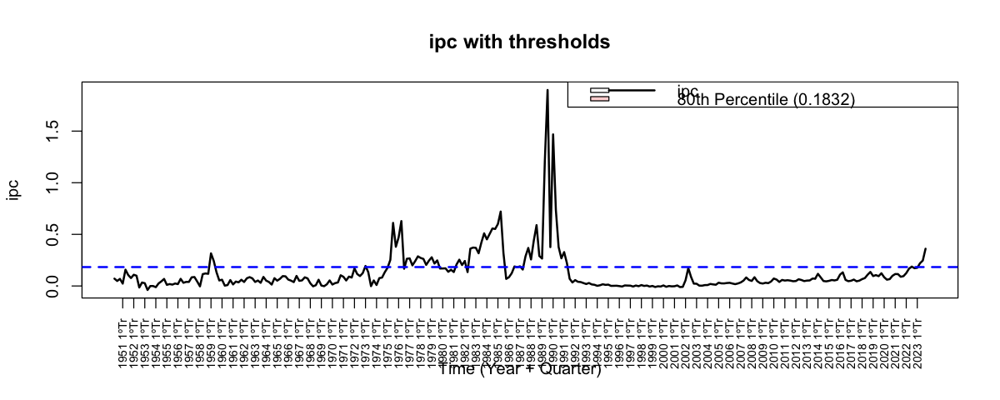

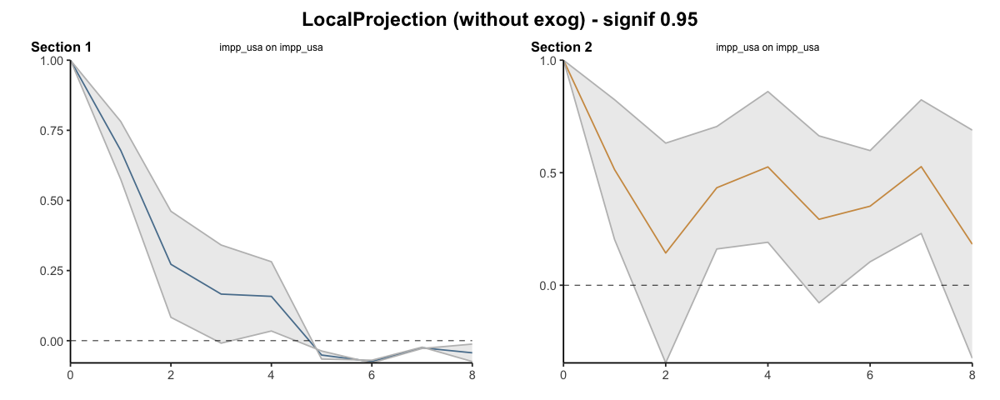

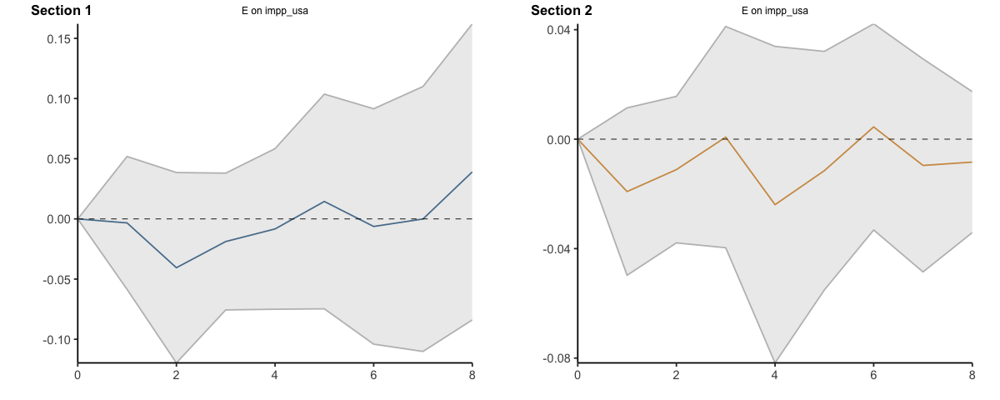

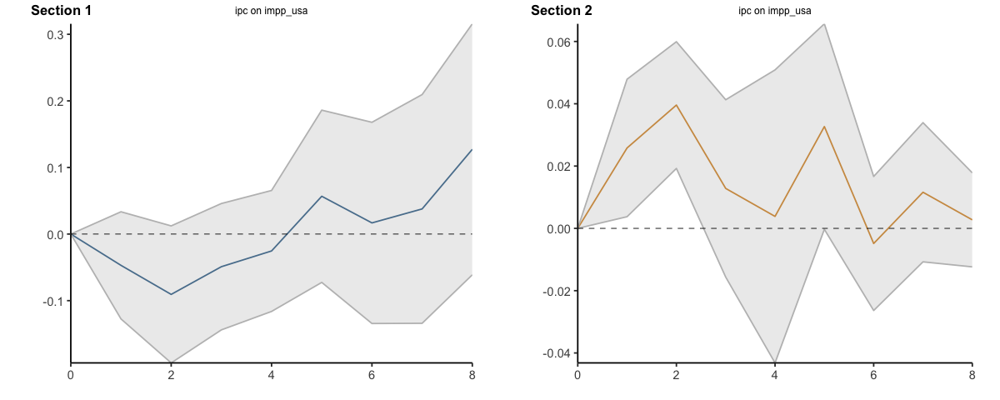

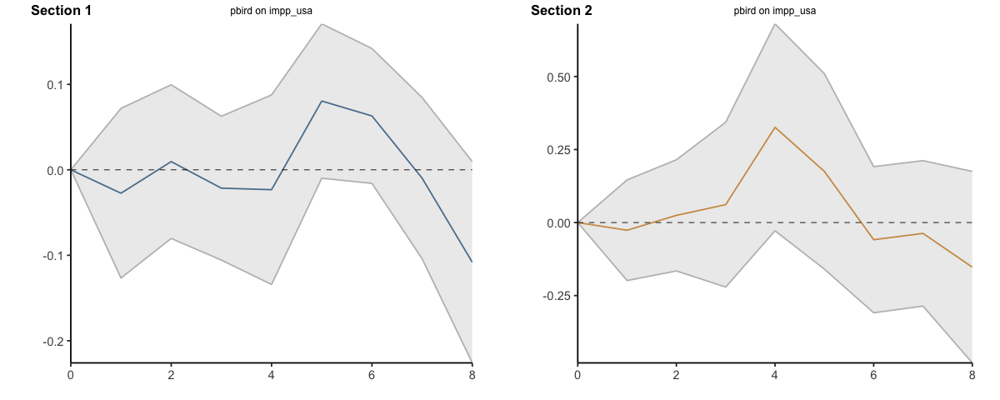

...

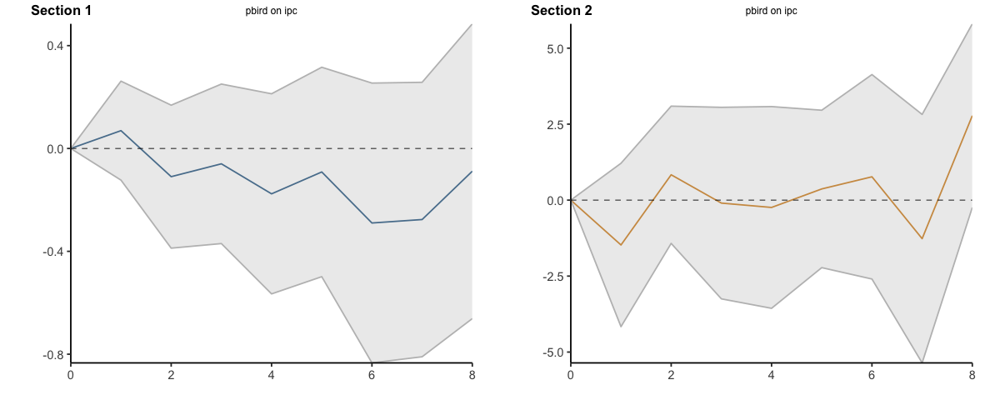

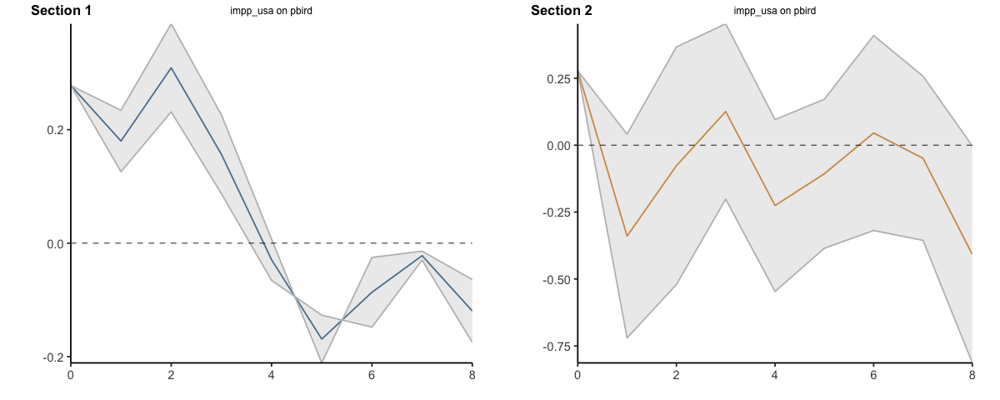

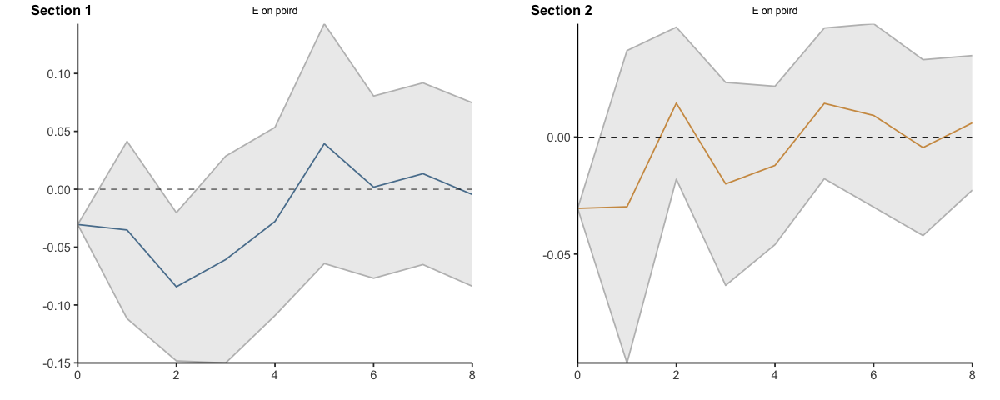

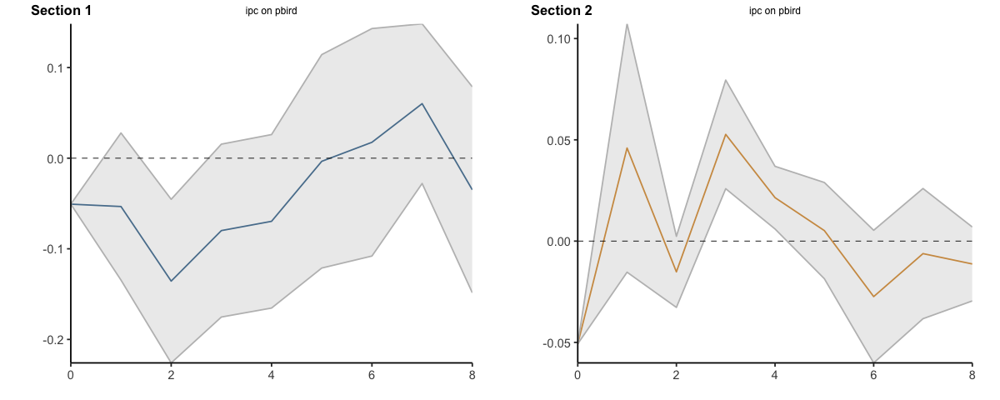

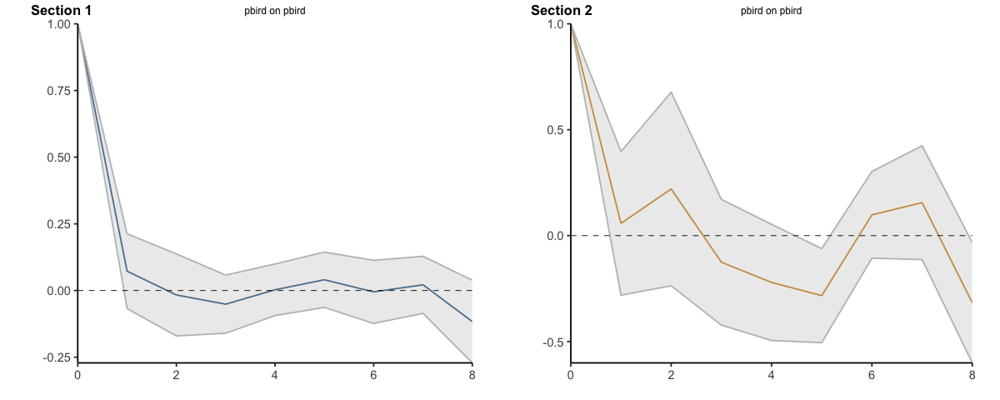

In [14]:
res <- run_lp_model(df_ERPT_Arg, endog=c("impp_usa", "E", "ipc", "pbird"), fixed_lags = 2, horizons=8, signif = 0.95, threshold_var = 'ipc', upper_threshold=0.8)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<dbl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,2,NaN,NA,NA,0,1,0.95,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,295,"impp_usa, E, ipc, pbird",4


Impulse: impp_usa -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,0,-1.444632,-1.444632,-1.4446318,-1.444632,-1.444632,-1.444632
2,1,-2.837039,-3.192668,-2.4814094,3.440666,-5.796276,12.677608
3,2,-4.051858,-4.466365,-3.6373510,8.409743,-10.398420,27.217906
4,3,-4.786283,-5.189962,-4.3826038,7.427294,-14.499686,29.354274
5,4,-4.990766,-6.257191,-3.7243405,11.362462,-17.636449,40.361373
6,5,-4.493331,-6.442567,-2.5440964,14.289805,-19.019102,47.598711
7,6,-3.572479,-6.417002,-0.7279569,12.729122,-24.761247,50.219491
8,7,-2.436533,-6.313101,1.4400351,15.224519,-26.663665,57.112702
9,8,-1.874359,-5.825139,2.0764210,19.504388,-26.366252,65.375028


Impulse: impp_usa -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
10,0,-0.7268158,-0.7268158,-0.7268158,-0.7268158,-0.7268158,-0.7268158
11,1,-1.3907656,-1.4793638,-1.3021673,2.5439239,-1.9516404,7.0394882
12,2,-2.2126104,-2.2895183,-2.1357025,7.2866934,-5.9452745,20.5186612
13,3,-2.8713103,-2.9860427,-2.7565778,8.1992257,-7.7244077,24.1228590
14,4,-3.3140995,-3.4819384,-3.1462605,12.4837021,-9.1864877,34.1538919
15,5,-3.5935155,-3.7534353,-3.4335957,16.5886530,-10.0989973,43.2763033
16,6,-3.2933735,-4.0126289,-2.5741180,17.6046032,-12.6708865,47.8800929
17,7,-2.8220352,-4.1831651,-1.4609052,19.6174874,-14.3958944,53.6308693
18,8,-2.2338408,-4.1814378,-0.2862439,23.3759336,-14.5490578,61.3009250


... (16 outputs left out)

Impulse: pbird -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
91,0,0.0000000,0.000000,0.0000000,0.0000000,0.000000,0.000000
92,1,-0.7549079,-1.545142,0.0353262,-2.4037543,-5.658265,0.850756
93,2,-1.4518234,-3.142811,0.2391646,-1.7977055,-8.164446,4.569035
94,3,-1.8506397,-4.284363,0.5830837,-2.2613981,-12.418617,7.895821
95,4,-2.3105975,-5.493379,0.8721837,-3.1732184,-18.144249,11.797812
96,5,-2.1785211,-6.126786,1.7697443,-1.5016363,-19.973604,16.970331
97,6,-2.8045194,-7.607299,1.9982603,-2.1369192,-23.908037,19.634199
98,7,-3.3927559,-9.089310,2.3037980,-2.8249875,-27.723943,22.073968
99,8,-3.5576260,-10.181439,3.0661866,-0.3804434,-28.498393,27.737506


Impulse: pbird -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
100,0,0.00000000,0.0000000,0.0000000,0.0000000,0.000000,0.000000
101,1,0.06937094,-0.1231061,0.2618479,-1.4761440,-4.164527,1.212239
102,2,-0.04024595,-0.5107654,0.4302735,-0.6424539,-5.589082,4.304174
103,3,-0.09988715,-0.8805841,0.6808098,-0.7404044,-8.838166,7.357357
104,4,-0.27627054,-1.4460981,0.8935571,-0.9816374,-12.398462,10.435187
105,5,-0.36759700,-1.9446788,1.2094848,-0.6136250,-14.620392,13.393142
106,6,-0.65737884,-2.7785855,1.4638278,0.1537038,-17.216989,17.524397
107,7,-0.93369020,-3.5885974,1.7212170,-1.1147344,-22.573696,20.344227
108,8,-1.02208215,-4.2501584,2.2059941,1.6638739,-22.817250,26.144998


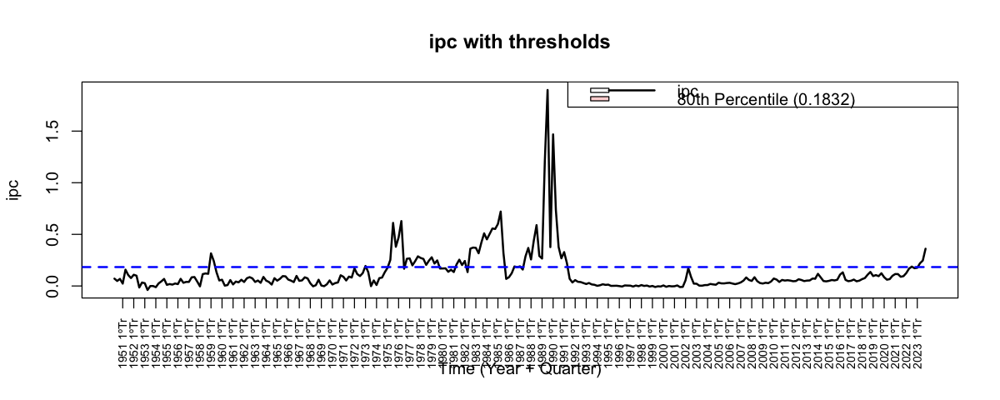

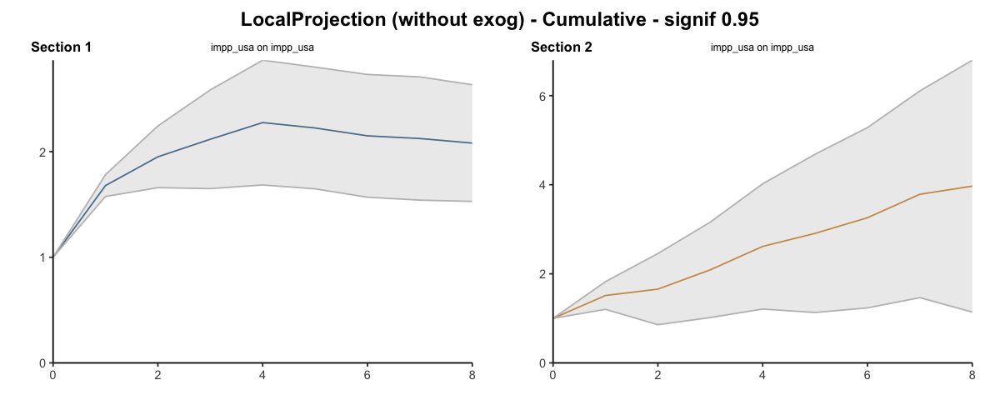

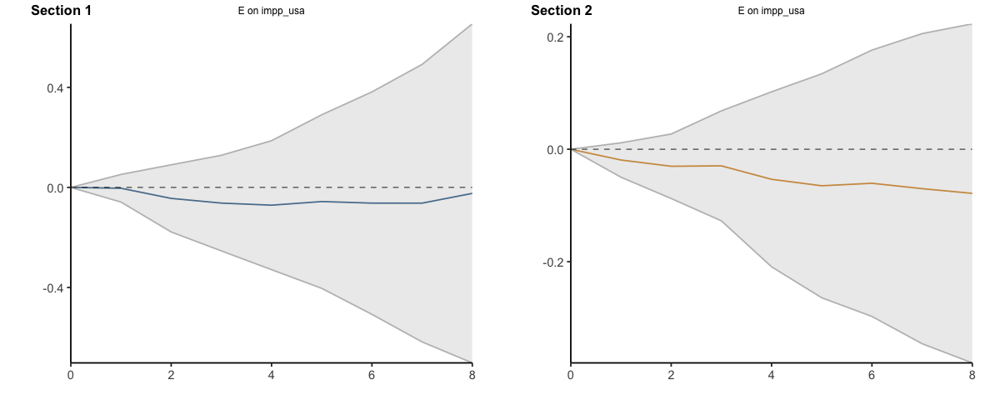

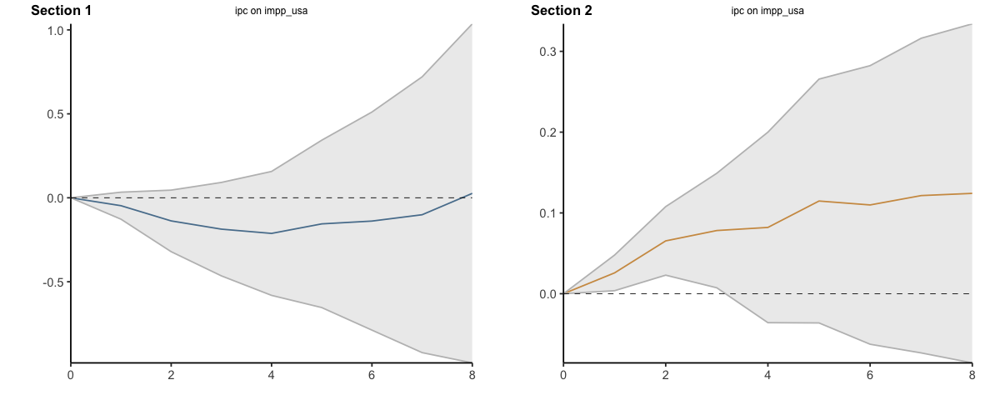

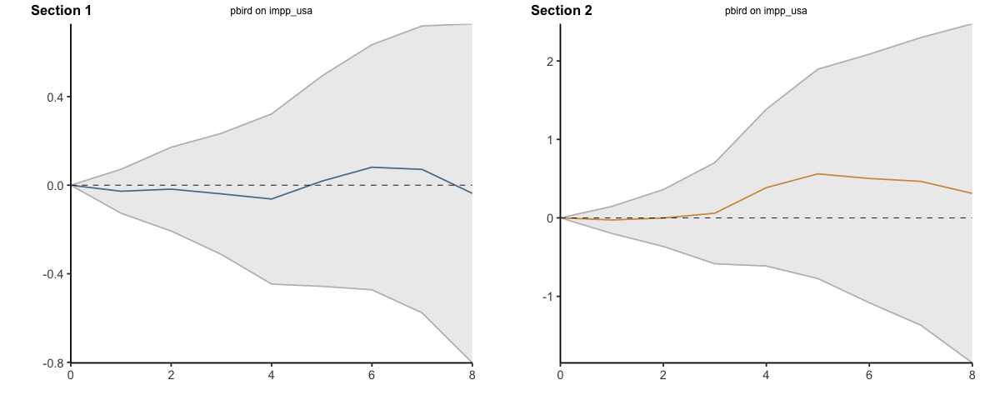

...

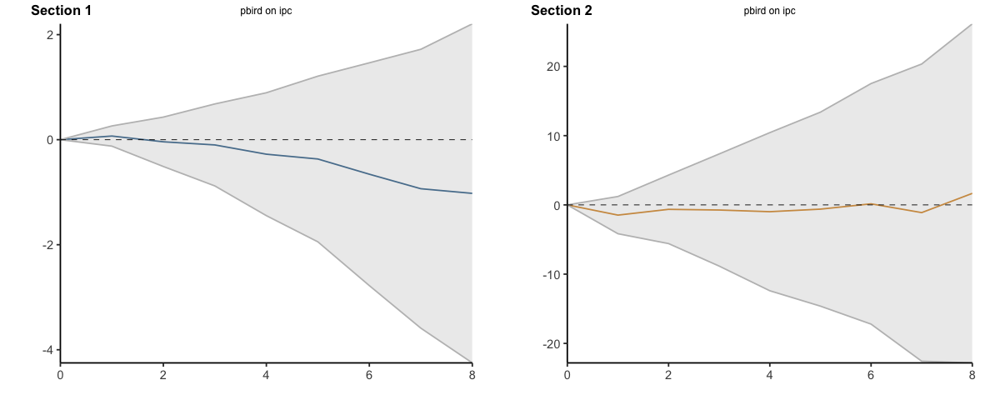

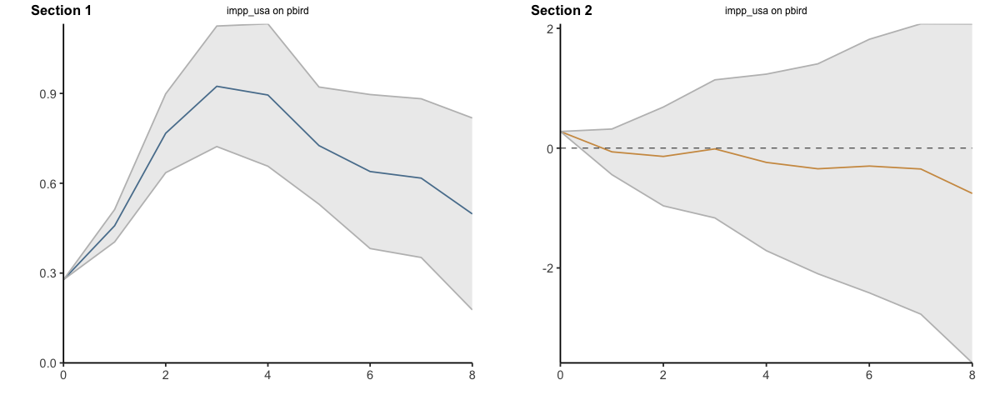

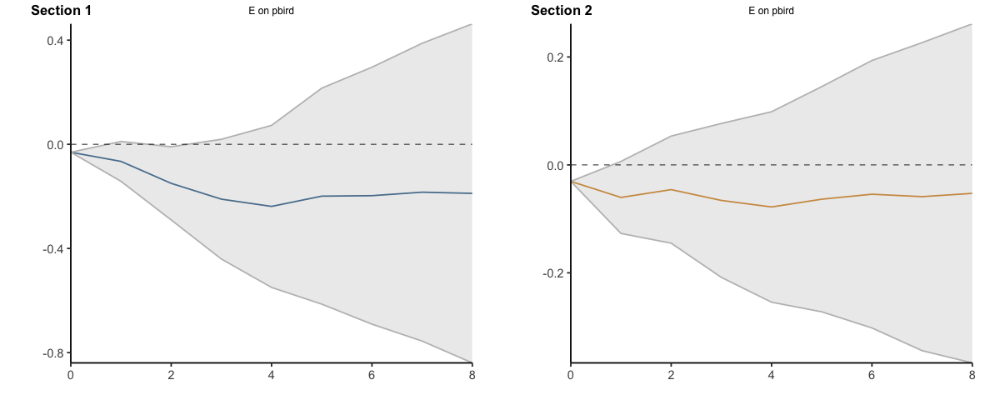

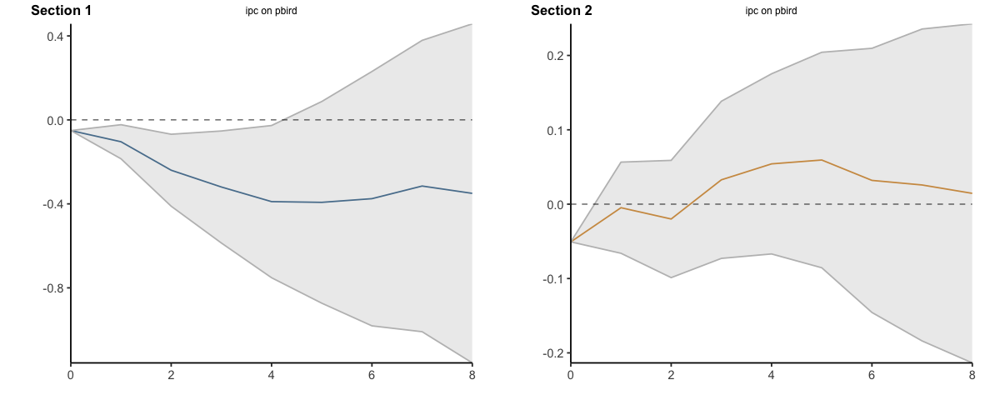

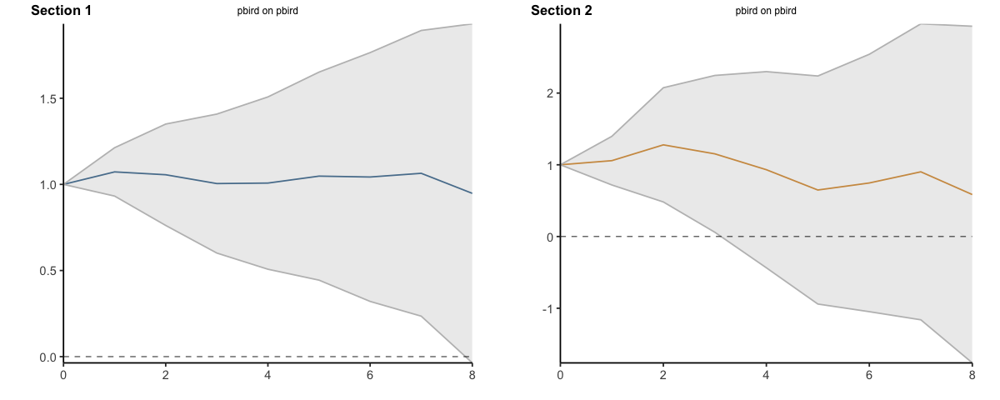

In [13]:
res <- run_lp_model(df_ERPT_Arg, endog=c("impp_usa", "E", "ipc", "pbird"), fixed_lags = 2, horizons=8, signif = 0.95, threshold_var = 'ipc', upper_threshold=0.8, cumulative=TRUE)

#### Percentile 80 - 2 lags

Umbral: ipc > 0.1832 (percentil 80 )
Trimestres por régimen: debajo del umbral (dummy = 0) = 236 | encima del umbral (dummy = 1) = 59 


Bootstrap por bloques circular: 500 réplicas, bloques de 20 trimestres...



  |======================================================================| 100%
ERPT de un shock unitario en E sobre ipc ( LP, 2 rezagos, umbral: ipc > 0,183, 59 trimestres encima )

Régimen 1 (debajo del umbral)
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.4562         0.4562       1.0000
         1              0.8492         0.5614       1.5126
         2              1.2880         0.6698       1.9229
         3              1.6598         0.7728       2.1479
         4              1.9836         0.8665       2.2893
         5              2.2105         0.9167       2.4114
         6              2.3212         0.9543       2.4323
         7              2.4261         0.9751       2.4880
         8              2.5020         0.9447       2.6484
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.4562             0.4562
                  0.3930             0.1052
                  0.4389             0.1085
                  0.3

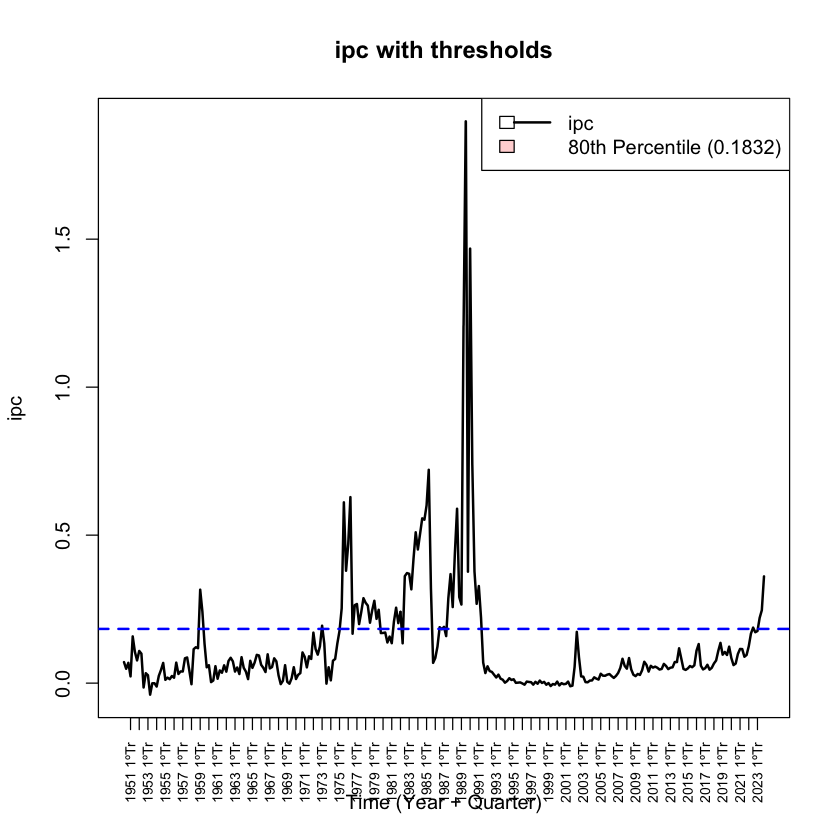

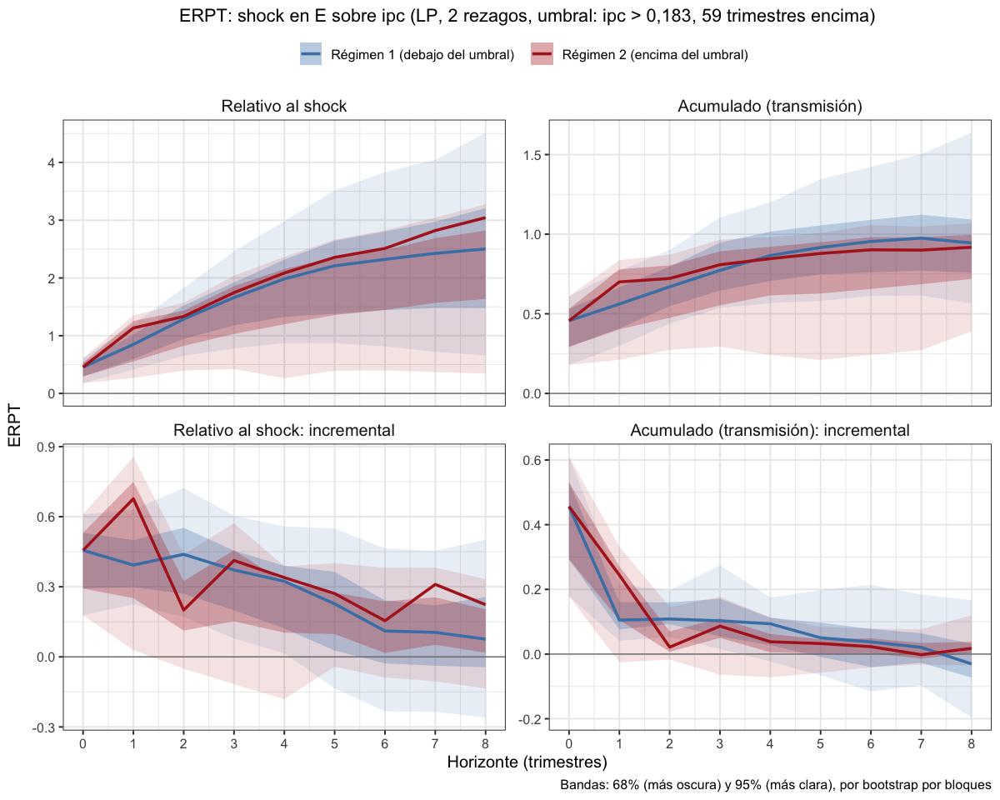

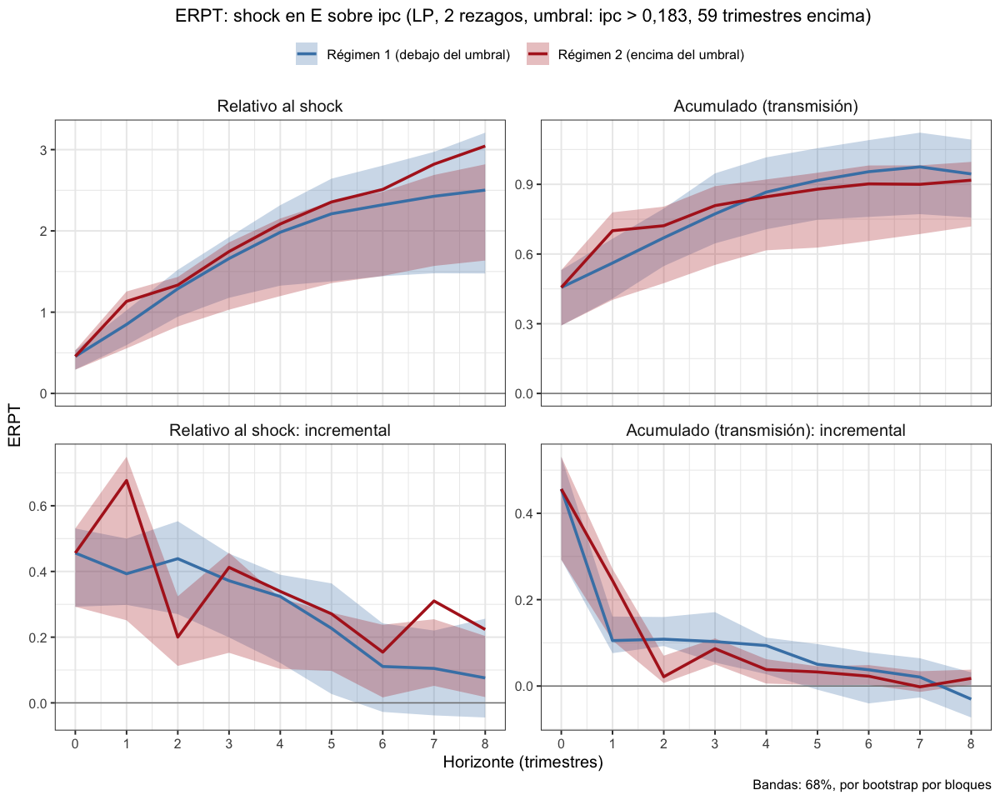

In [7]:
# Todas endógenas con umbral en el percentil 80 del ipc, 2 rezagos
lp_erpt_endog_p2_u80 <- erpt_lp(df_ERPT_Arg, endog = c("impp_usa", "E", "ipc", "pbird"),
                                fixed_lags = 2, horizons = 8, reps = 500,
                                threshold_var = "ipc", upper_threshold = 0.8)
saveRDS(lp_erpt_endog_p2_u80, "lp_erpt_endog_p2_u80.rds")
graficar_erpt_lp(lp_erpt_endog_p2_u80, archivo = "lp_erpt_endog_p2_u80")
graficar_erpt_lp(lp_erpt_endog_p2_u80, niveles = 0.68, archivo = "lp_erpt_endog_p2_u80_68")

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<dbl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,2,NaN,NA,NA,0,1,0.95,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,295,"impp_usa, E, ipc, pbird",4


Impulse: impp_usa -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,0,-1.4446318,-1.44463181,-1.44463181,-1.444632,-1.4446318,-1.4446318
2,1,-0.9152411,-1.02771143,-0.80277080,1.765851,-4.0077319,7.5394331
3,2,-0.7887720,-0.94465139,-0.63289259,2.306780,-2.9705585,7.5841181
4,3,0.2135866,0.35512501,0.07204824,-2.516369,-4.7675464,-0.2651922
5,4,0.3873258,-0.46852021,1.24317184,1.632226,-2.9570767,6.2215289
6,5,0.7916986,0.09744486,1.48595225,1.886860,-0.5387872,4.3125077
7,6,1.2831153,0.24735373,2.31887683,-1.262578,-4.5859108,2.0607548
8,7,1.4106725,0.20505288,2.61629211,2.184212,-0.4732330,4.8416568
9,8,1.3915465,1.43784096,1.34525207,3.997494,0.4974346,7.4975526


Impulse: impp_usa -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
10,0,-0.72681584,-0.72681584,-0.7268158,-0.7268158,-0.72681584,-0.7268158
11,1,-0.48540251,-0.39363744,-0.5771676,1.5545962,-0.87288319,3.9820756
12,2,-0.34809675,-0.34231130,-0.3538822,2.2675324,-2.83492578,7.3699905
13,3,-0.06596358,0.05158898,-0.1835161,-0.6147340,-2.27810833,1.0486403
14,4,0.04661303,0.14088315,-0.0476571,1.9869519,-1.67888503,5.6527889
15,5,0.28441839,0.18794589,0.3808909,2.0114924,-1.06903228,5.0920170
16,6,0.64232103,-0.02044662,1.3050887,-0.1399988,-2.56287324,2.2828757
17,7,0.62690311,0.07723088,1.1765753,1.1646921,-0.82831431,3.1576986
18,8,1.05197989,0.60238004,1.5015797,2.6555259,0.01370099,5.2973508


... (16 outputs left out)

Impulse: pbird -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
91,0,0.0000000,0.000000,0.00000000,0.00000000,0.0000000,0.000000
92,1,-0.5949271,-1.215430,0.02557543,-1.30632309,-3.9090444,1.296398
93,2,-0.9228066,-1.932182,0.08656832,0.98310987,-0.9234154,2.889635
94,3,-0.6214500,-1.345416,0.10251627,0.03576067,-2.7090445,2.780566
95,4,-0.4241295,-1.216511,0.36825248,-0.39926198,-3.3097078,2.511184
96,5,0.1465551,-0.759699,1.05280928,1.36957262,-1.0205346,3.759680
97,6,-0.4772197,-1.156061,0.20162180,-0.83156372,-3.7245321,2.061405
98,7,-0.5211558,-1.371988,0.32967648,-0.20539095,-2.4038623,1.993080
99,8,-0.7835960,-1.492303,-0.07488930,3.18054434,-0.9608602,7.321949


Impulse: pbird -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
100,0,0.00000000,0.0000000,0.00000000,0.0000000,0.0000000,0.000000
101,1,0.03148937,-0.1167608,0.17973958,-0.2086090,-1.8660922,1.448874
102,2,-0.20934200,-0.4616651,0.04298110,0.8755101,-0.5371117,2.288132
103,3,-0.20480032,-0.4899056,0.08030495,0.2900123,-1.7593825,2.339407
104,4,-0.24362139,-0.6076664,0.12042362,0.1703212,-2.0646009,2.405243
105,5,-0.22741843,-0.6485538,0.19371696,0.7929459,-1.0616187,2.647511
106,6,-0.29309661,-0.7914444,0.20525115,0.4662081,-1.8943232,2.826739
107,7,-0.17910035,-0.6156761,0.25747544,-0.7818333,-3.1561226,1.592456
108,8,-0.33831186,-0.8428780,0.16625423,2.3606445,-0.6031928,5.324482


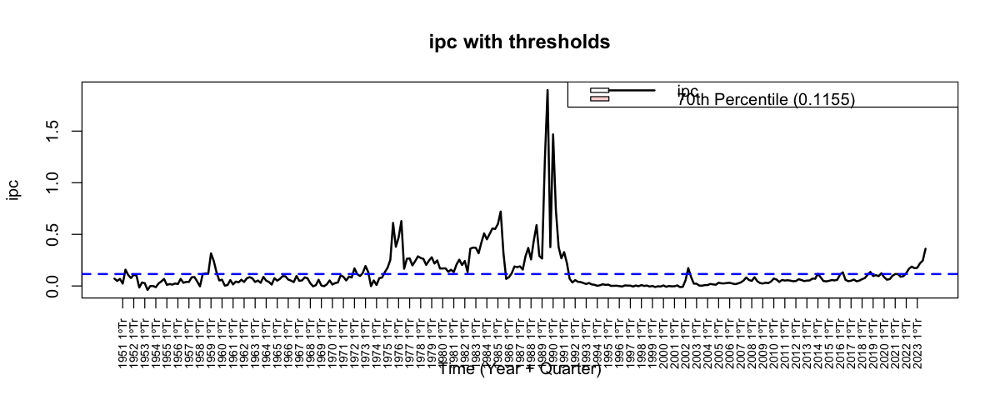

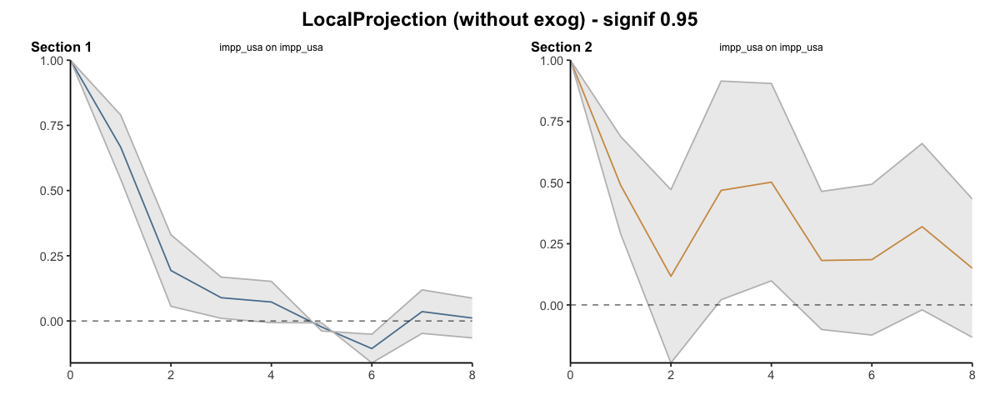

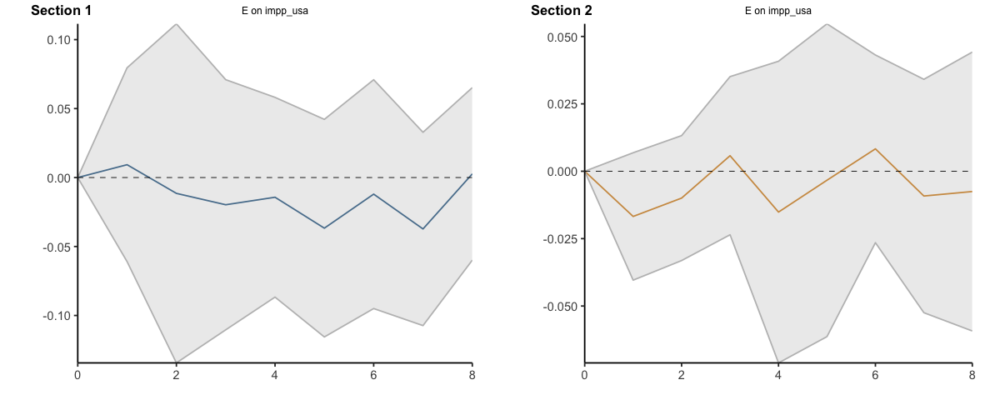

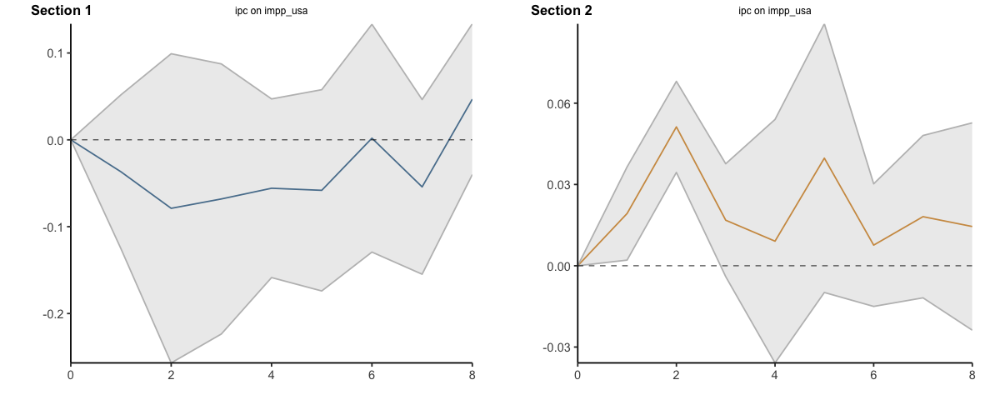

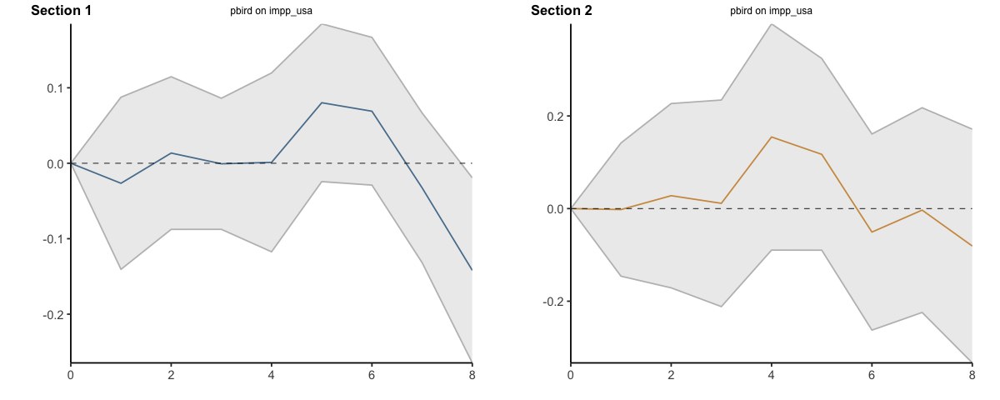

...

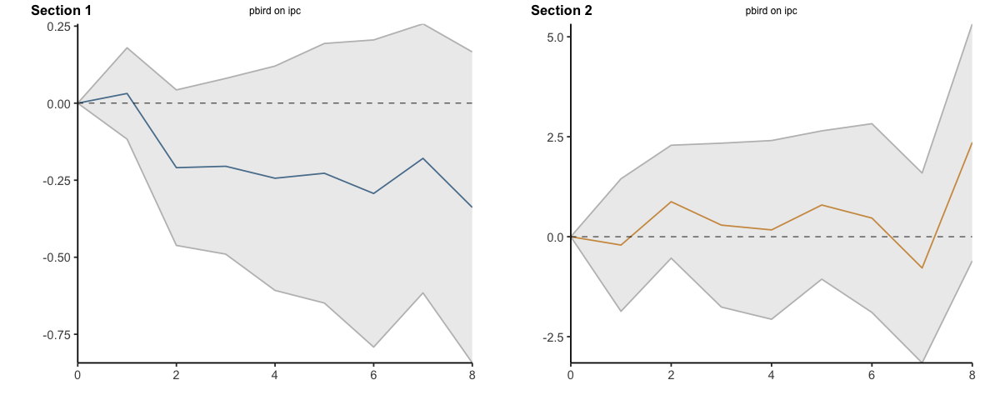

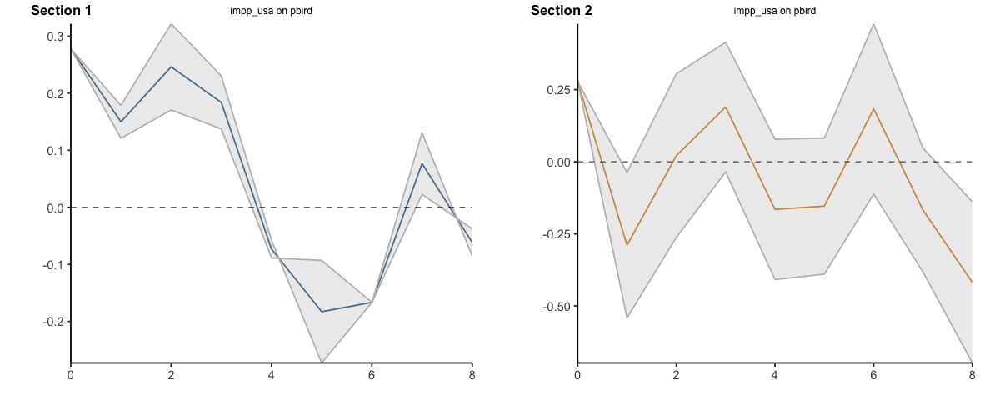

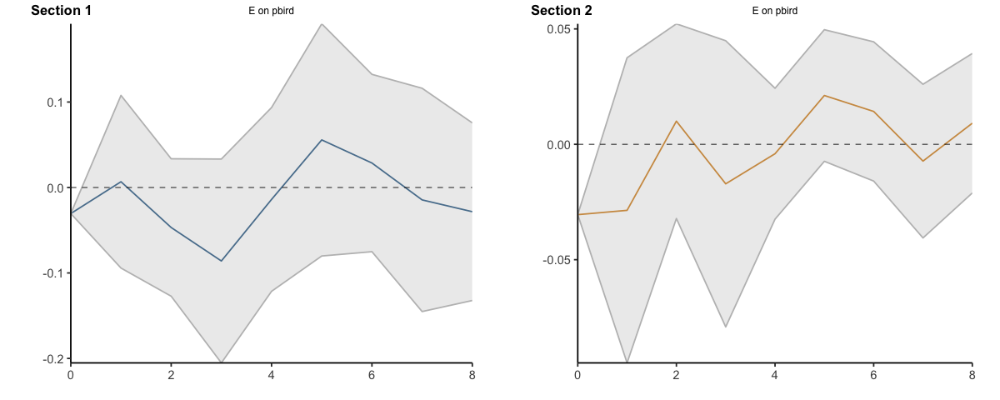

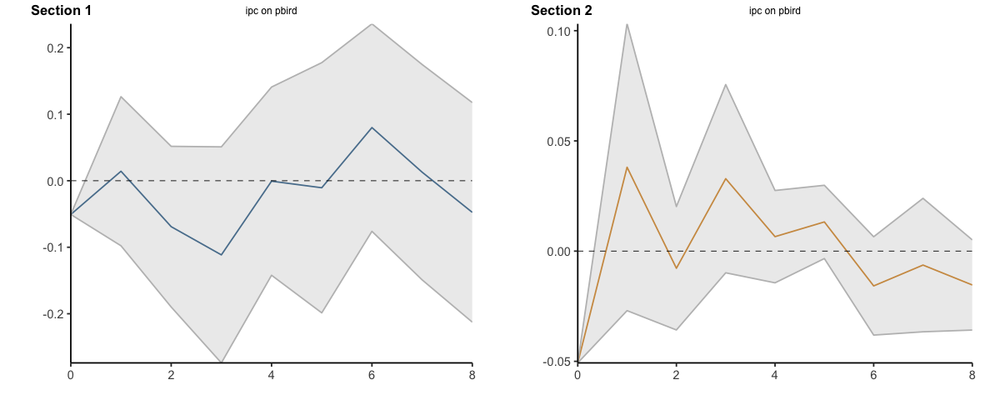

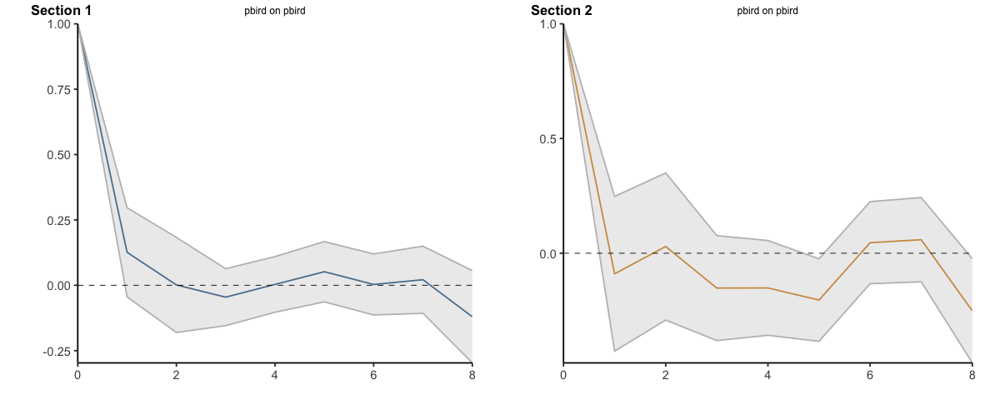

In [10]:
res <- run_lp_model(df_ERPT_Arg, endog=c("impp_usa", "E", "ipc", "pbird"), fixed_lags = 2, horizons=8, signif = 0.95, threshold_var = 'ipc', upper_threshold=0.7)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<dbl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,2,NaN,NA,NA,0,1,0.95,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,295,"impp_usa, E, ipc, pbird",4


Impulse: impp_usa -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,0,-1.4446318,-1.444632,-1.44463181,-1.4446318,-1.444632,-1.444632
2,1,-2.3598729,-2.472343,-2.24740261,0.3212188,-5.452364,6.094801
3,2,-3.1486449,-3.416995,-2.88029520,2.6279986,-8.422922,13.678919
4,3,-2.9350583,-3.061870,-2.80824695,0.1116293,-13.190469,13.413727
5,4,-2.5477325,-3.530390,-1.56507512,1.7438554,-16.147545,19.635256
6,5,-1.7560339,-3.432945,-0.07912286,3.6307157,-16.686332,23.947764
7,6,-0.4729186,-3.185591,2.23975396,2.3681377,-21.272243,26.008518
8,7,0.9377539,-2.980538,4.85604607,4.5523495,-21.745476,30.850175
9,8,2.3293004,-1.542697,6.20129814,8.5498431,-21.248042,38.347728


Impulse: impp_usa -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
10,0,-0.72681584,-0.7268158,-0.7268158,-0.7268158,-0.7268158,-0.7268158
11,1,-1.21221835,-1.1204533,-1.3039834,0.8277803,-1.5996990,3.2552597
12,2,-1.56031509,-1.4627646,-1.6578656,3.0953127,-4.4346248,10.6252502
13,3,-1.62627867,-1.4111756,-1.8413817,2.4805787,-6.7127331,11.6738905
14,4,-1.57966564,-1.2702924,-1.8890388,4.4675306,-8.3916182,17.3266794
15,5,-1.29524725,-1.0823465,-1.5081480,6.4790230,-9.4606505,22.4186964
16,6,-0.65292623,-1.1027932,-0.2030593,6.3390242,-12.0235237,24.7015721
17,7,-0.02602311,-1.0255623,0.9735161,7.5037163,-12.8518380,27.8592707
18,8,1.02595677,-0.4231822,2.4750958,10.1592422,-12.8381370,33.1566215


... (16 outputs left out)

Impulse: pbird -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
91,0,0.0000000,0.000000,0.00000000,0.0000000,0.000000,0.000000
92,1,-0.5949271,-1.215430,0.02557543,-1.3063231,-3.909044,1.296398
93,2,-1.5177337,-3.147611,0.11214375,-0.3232132,-4.832460,4.186033
94,3,-2.1391837,-4.493027,0.21466002,-0.2874525,-7.541504,6.966599
95,4,-2.5633132,-5.709539,0.58291250,-0.6867145,-10.851212,9.477783
96,5,-2.4167580,-6.469238,1.63572178,0.6828581,-11.871747,13.237463
97,6,-2.8939778,-7.625299,1.83734358,-0.1487056,-15.596279,15.298868
98,7,-3.4151335,-8.997287,2.16702005,-0.3540966,-18.000141,17.291948
99,8,-4.1987295,-10.489590,2.09213075,2.8264478,-18.961001,24.613897


Impulse: pbird -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
100,0,0.00000000,0.0000000,0.0000000,0.0000000,0.000000,0.000000
101,1,0.03148937,-0.1167608,0.1797396,-0.2086090,-1.866092,1.448874
102,2,-0.17785263,-0.5784259,0.2227207,0.6669011,-2.403204,3.737006
103,3,-0.38265295,-1.0683315,0.3030256,0.9569135,-4.162586,6.076413
104,4,-0.62627433,-1.6759979,0.4234492,1.1272347,-6.227187,8.481657
105,5,-0.85369276,-2.3245517,0.6171662,1.9201806,-7.288806,11.129167
106,6,-1.14678937,-3.1159961,0.8224174,2.3863887,-9.183129,13.955907
107,7,-1.32588972,-3.7316723,1.0798928,1.6045555,-12.339252,15.548363
108,8,-1.66420158,-4.5745502,1.2461470,3.9652000,-12.942444,20.872844


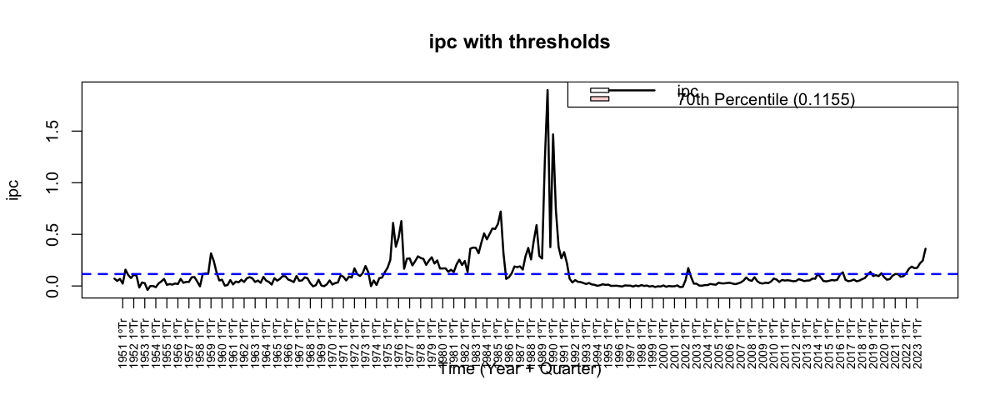

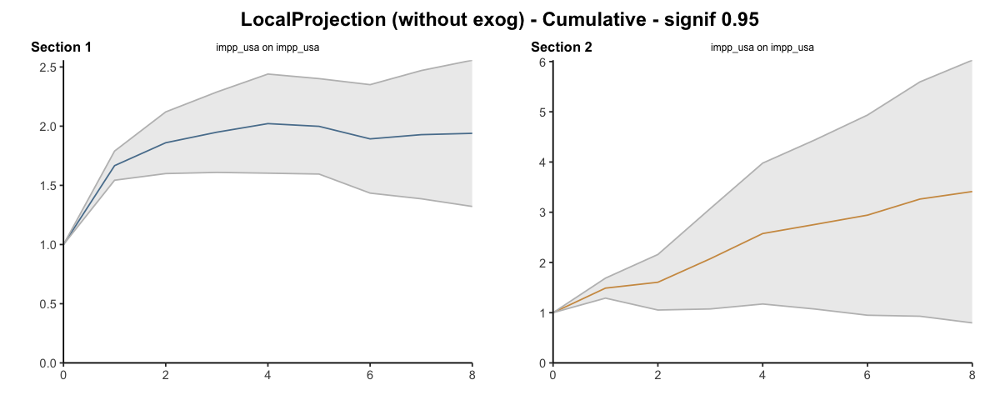

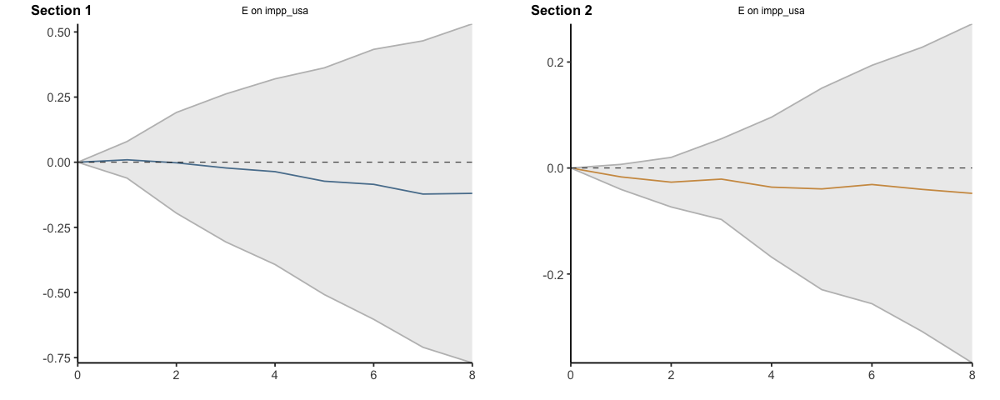

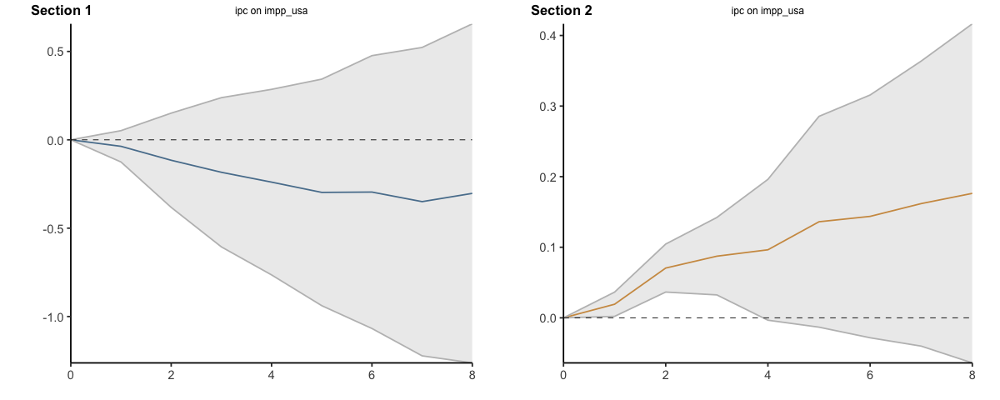

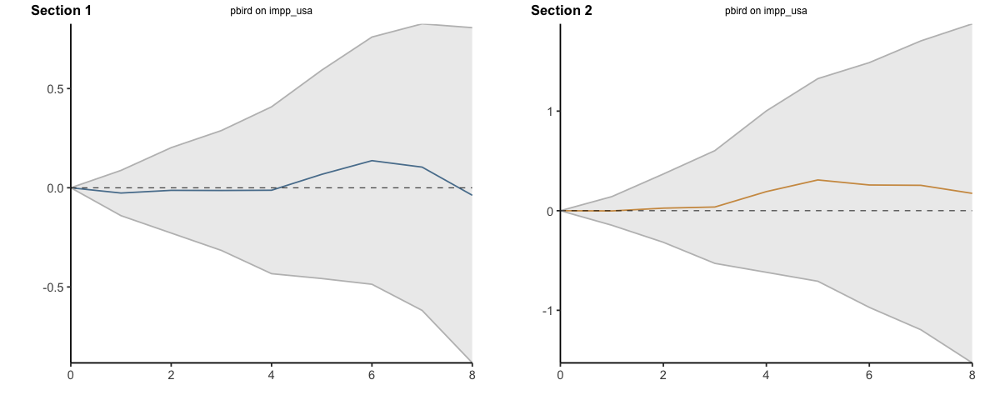

...

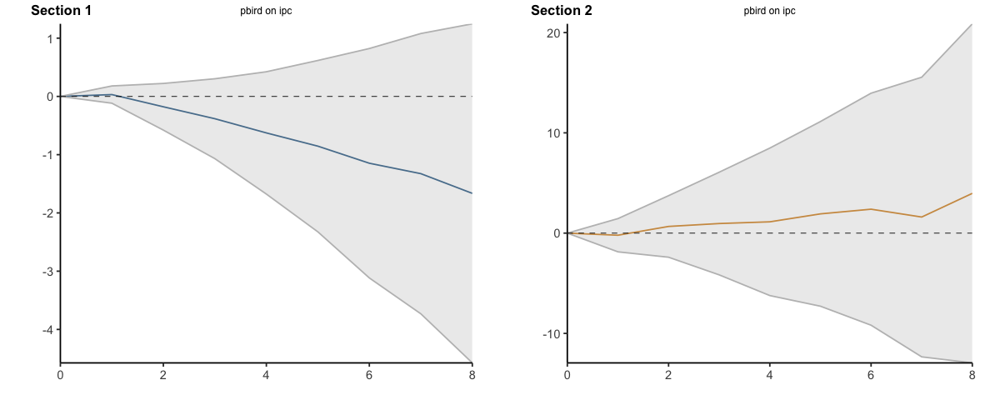

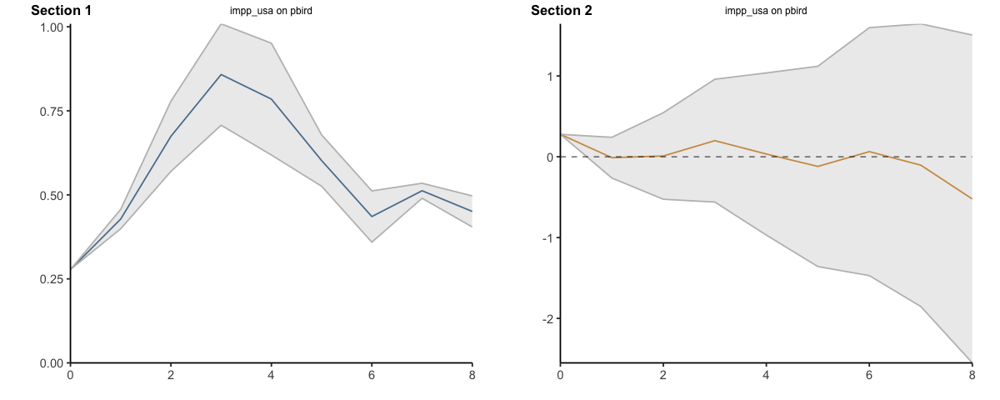

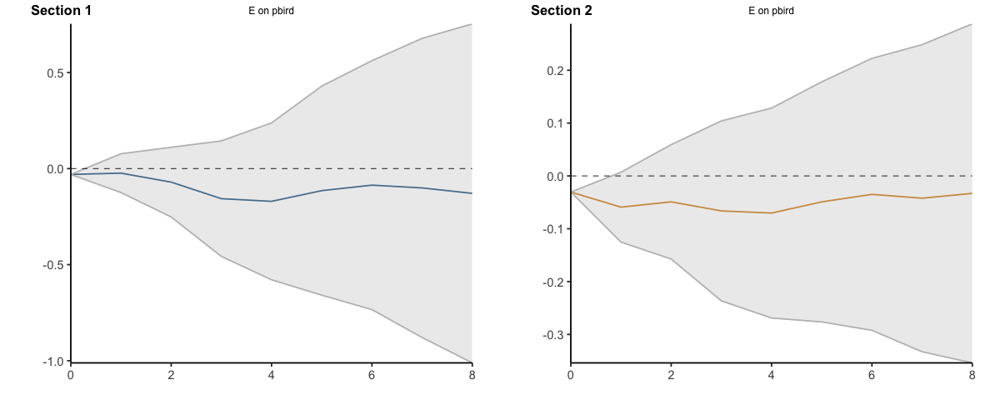

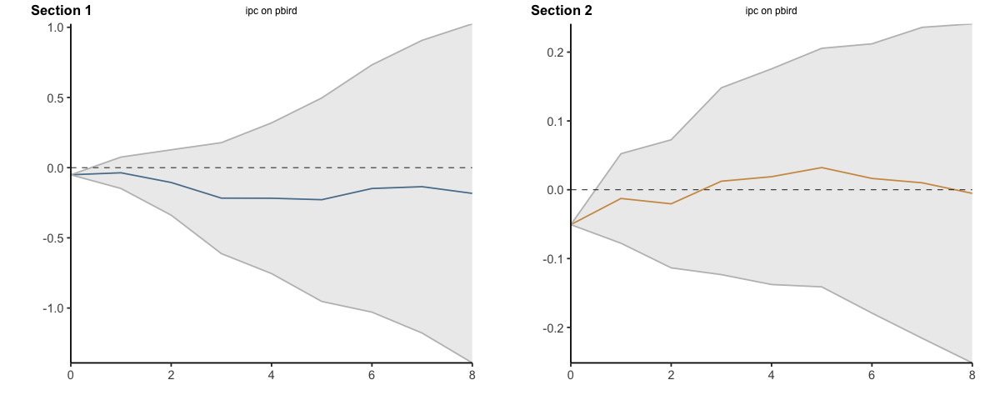

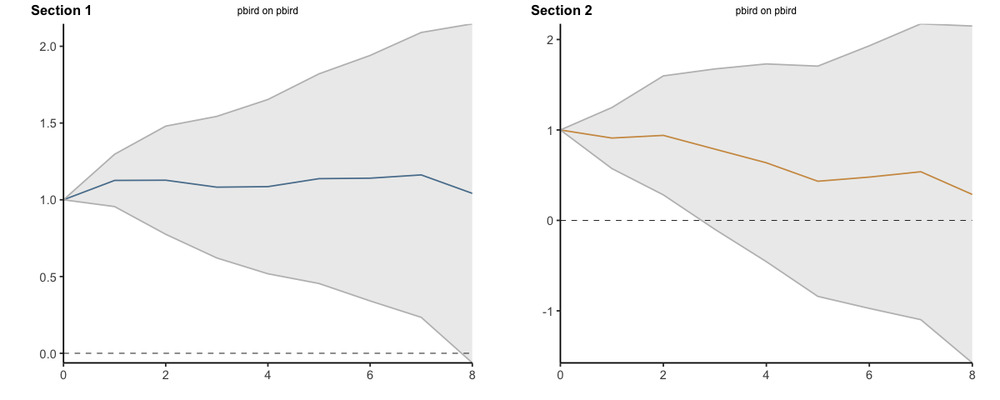

In [9]:
res <- run_lp_model(df_ERPT_Arg, endog=c("impp_usa", "E", "ipc", "pbird"), fixed_lags = 2, horizons=8, signif = 0.95, threshold_var = 'ipc', upper_threshold=0.7, cumulative=TRUE)

#### Percentile 70 - 2 lags

Umbral: ipc > 0.1155 (percentil 70 )
Trimestres por régimen: debajo del umbral (dummy = 0) = 206 | encima del umbral (dummy = 1) = 89 


Bootstrap por bloques circular: 500 réplicas, bloques de 20 trimestres...



  |======================================================================| 100%
ERPT de un shock unitario en E sobre ipc ( LP, 2 rezagos, umbral: ipc > 0,115, 89 trimestres encima )

Régimen 1 (debajo del umbral)
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.4562         0.4562       1.0000
         1              0.7998         0.5703       1.4023
         2              1.0247         0.6472       1.5834
         3              1.1648         0.8239       1.4138
         4              1.2569         0.9444       1.3309
         5              1.2313         0.9658       1.2749
         6              1.1871         1.0966       1.0825
         7              1.1938         1.4074       0.8482
         8              0.9756         3.1228       0.3124
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.4562             0.4562
                  0.3436             0.1141
                  0.2250             0.0769
                  0.1

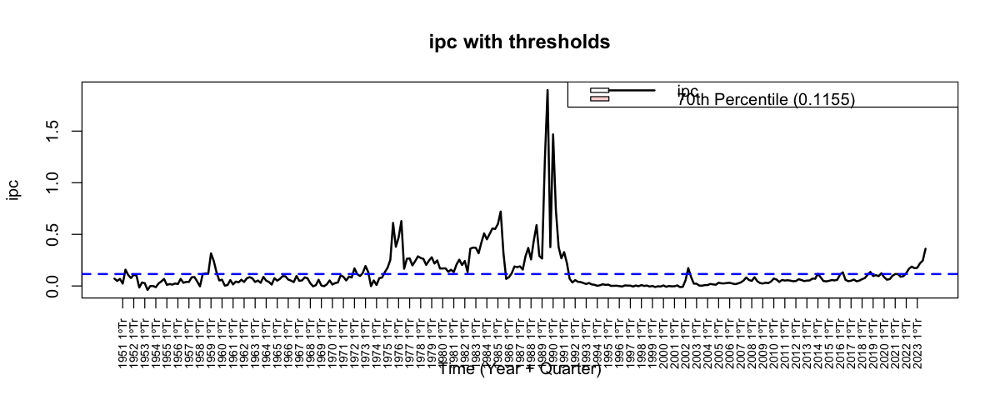

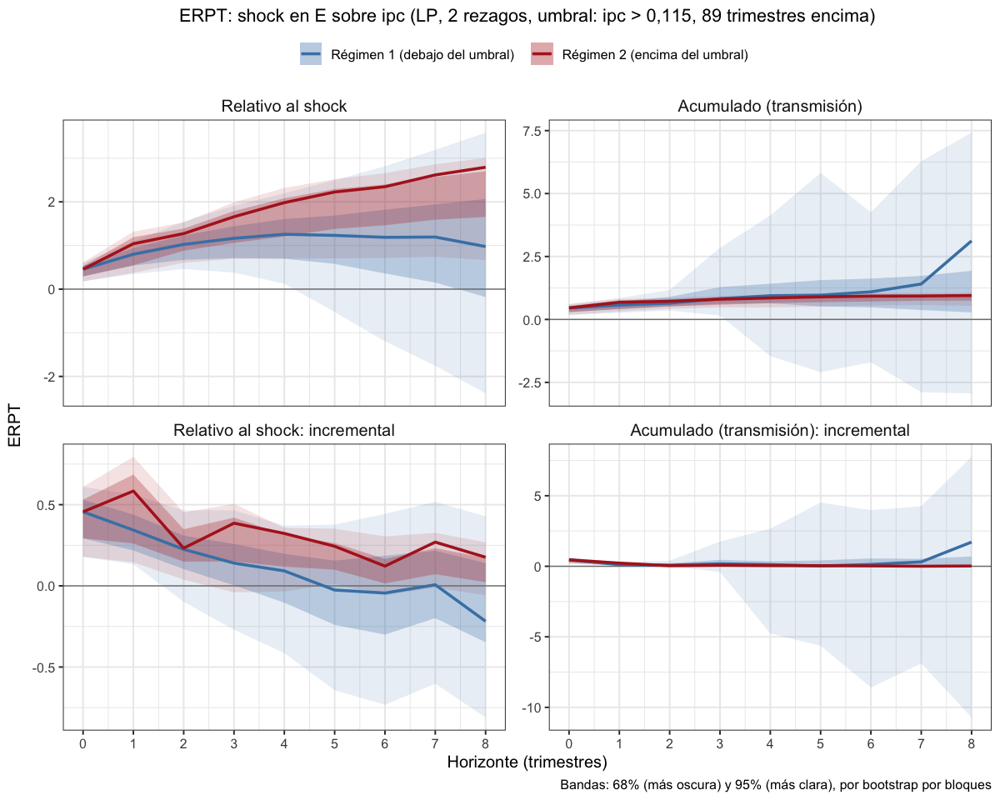

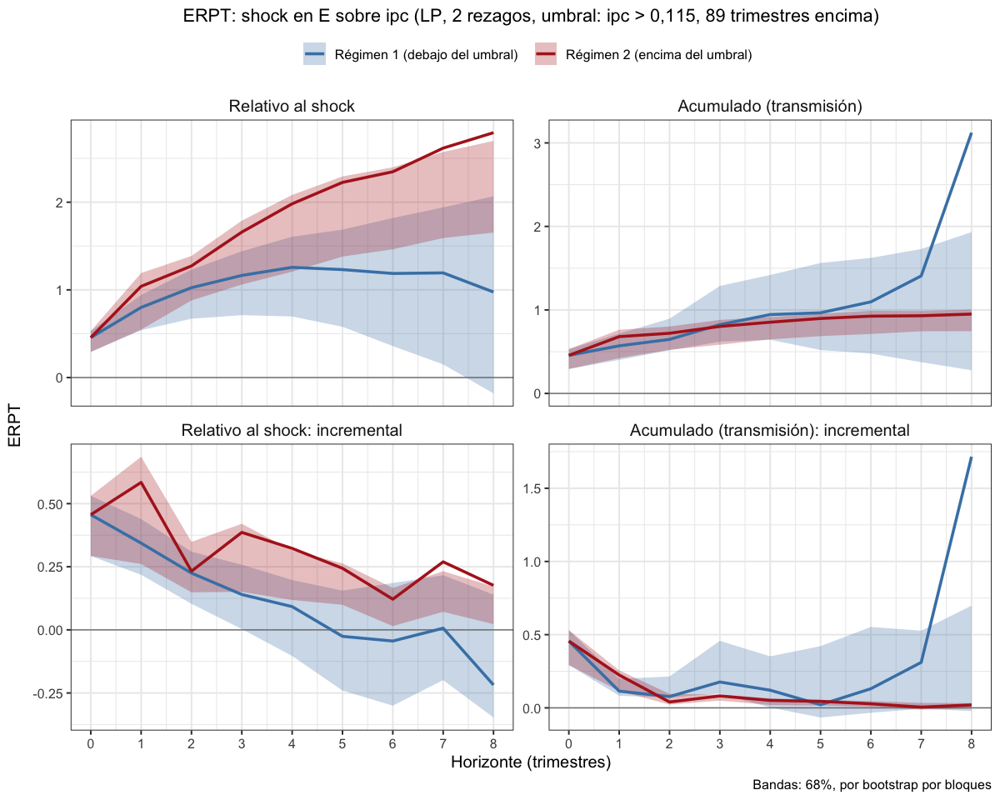

In [11]:
# Todas endógenas con umbral en el percentil 70 del ipc, 2 rezagos
lp_erpt_endog_p2_u70 <- erpt_lp(df_ERPT_Arg, endog = c("impp_usa", "E", "ipc", "pbird"),
                                fixed_lags = 2, horizons = 8, reps = 500,
                                threshold_var = "ipc", upper_threshold = 0.7)
saveRDS(lp_erpt_endog_p2_u70, "lp_erpt_endog_p2_u70.rds")
graficar_erpt_lp(lp_erpt_endog_p2_u70, archivo = "lp_erpt_endog_p2_u70")
graficar_erpt_lp(lp_erpt_endog_p2_u70, niveles = 0.68, archivo = "lp_erpt_endog_p2_u70_68")

#### Encuentro percentil de umbral de inflación 12,5% y 37,6% trimestral

In [19]:
p_vlstar <- ecdf(df_ERPT_Arg$ipc)(0.125)   # percentil del umbral de los VLSTAR
p_tvar   <- ecdf(df_ERPT_Arg$ipc)(0.376)   # percentil del umbral del TVAR-indt
p_vlstar; p_tvar

# Chequeo: cuántos trimestres quedan por encima de cada umbral
sum(df_ERPT_Arg$ipc > 0.125, na.rm = TRUE)
sum(df_ERPT_Arg$ipc > 0.376, na.rm = TRUE)

[1] 0.7254237

[1] 0.9322034

[1] 81

[1] 20

#### No hace falta correr run_lp_model (excepto que quiera tener las IRF entre todas las variables). No hace falta poner el percentil; con p_vlstar lo encuentra.

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<dbl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,2,NaN,NA,NA,0,1,0.68,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,295,"impp_usa, E, ipc, pbird",4


Impulse: impp_usa -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,0,-1.44463181,-1.44463181,-1.44463181,-1.4446318,-1.4446318,-1.4446318
2,1,-0.94515431,-0.99127125,-0.89903737,2.1433070,-0.9898721,5.2764861
3,2,-0.88920071,-0.98464159,-0.79375983,2.5310236,-0.3441196,5.4061667
4,3,0.05454016,0.12569152,-0.01661119,-2.3687564,-3.6097290,-1.1277838
5,4,0.35943402,-0.08571376,0.80458180,1.8331772,-0.6331019,4.2994563
6,5,0.65378604,0.27916383,1.02840825,2.1329709,0.8083585,3.4575832
7,6,1.01500925,0.47181030,1.55820819,-0.9635006,-2.6592792,0.7322781
8,7,1.27776789,0.64744229,1.90809349,2.4104540,0.8779445,3.9429636
9,8,1.05825195,1.02855590,1.08794800,4.2780601,2.4215569,6.1345633


Impulse: impp_usa -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
10,0,-0.72681584,-0.72681584,-0.72681584,-0.72681584,-0.7268158,-0.7268158
11,1,-0.58591152,-0.53104596,-0.64077707,1.75657963,0.4160216,3.0971376
12,2,-0.48429768,-0.47257360,-0.49602177,2.48821828,-0.2988013,5.2752379
13,3,-0.13753869,-0.08498229,-0.19009509,-0.47411302,-1.3942027,0.4459767
14,4,0.01068535,0.03278687,-0.01141618,2.19038838,0.1804253,4.2003514
15,5,0.14794137,0.08157212,0.21431061,2.27945682,0.6001087,3.9588050
16,6,0.46832664,0.11831070,0.81834258,0.09839889,-1.1770524,1.3738502
17,7,0.54729056,0.23264384,0.86193728,1.32037874,0.2621974,2.3785601
18,8,0.80924941,0.51487112,1.10362771,2.92654105,1.5334511,4.3196310


... (16 outputs left out)

Impulse: pbird -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
91,0,0.0000000,0.0000000,0.000000000,0.00000000,0.00000000,0.00000000
92,1,-0.5744570,-0.8883924,-0.260521672,-1.48859914,-2.89329196,-0.08390632
93,2,-0.8632962,-1.3674199,-0.359172596,0.84979655,-0.21829300,1.91788610
94,3,-0.5647107,-0.9311478,-0.198273502,-0.09499087,-1.58969452,1.39971277
95,4,-0.4040964,-0.7969414,-0.011251425,-0.46751239,-2.03262772,1.09760294
96,5,0.2077302,-0.2463105,0.661770827,1.19232392,-0.02583222,2.41048006
97,6,-0.3326148,-0.6905395,0.025309936,-1.23884851,-2.73378712,0.25609011
98,7,-0.4475746,-0.8977589,0.002609628,-0.40197638,-1.62919289,0.82524013
99,8,-0.6803098,-1.0477347,-0.312884909,2.98168742,0.86894644,5.09442839


Impulse: pbird -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
100,0,0.00000000,0.00000000,0.00000000,0.00000000,0.00000000,0.0000000
101,1,0.06937606,-0.01001112,0.14876323,-0.34844551,-1.24774441,0.5508534
102,2,-0.15560616,-0.28533140,-0.02588092,0.69400987,-0.08517213,1.4731919
103,3,-0.16752722,-0.32385917,-0.01119527,0.17711097,-0.93849940,1.2927213
104,4,-0.23164045,-0.42279585,-0.04048506,0.08730471,-1.10457291,1.2791823
105,5,-0.15894613,-0.37597208,0.05807981,0.60403104,-0.36913864,1.5772007
106,6,-0.20839859,-0.47484949,0.05805231,0.20717439,-1.03547296,1.4498217
107,7,-0.11884005,-0.35465730,0.11697720,-0.98734291,-2.24455620,0.2698704
108,8,-0.24163391,-0.51837836,0.03511053,2.15016201,0.65780673,3.6425173


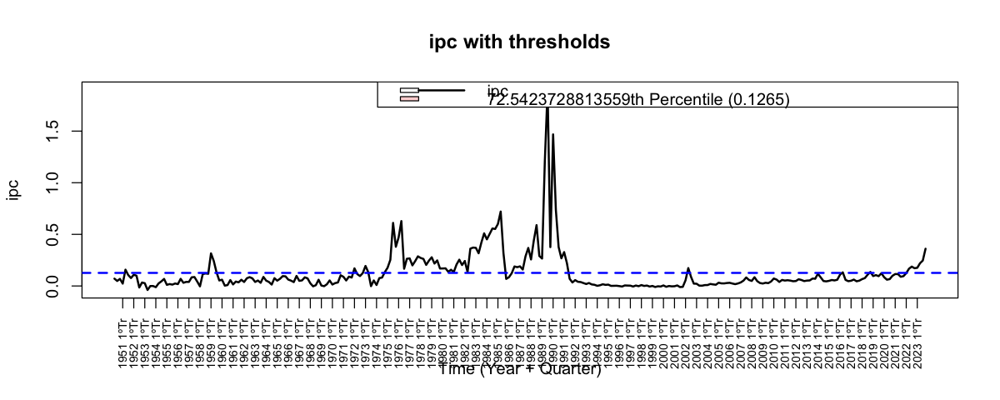

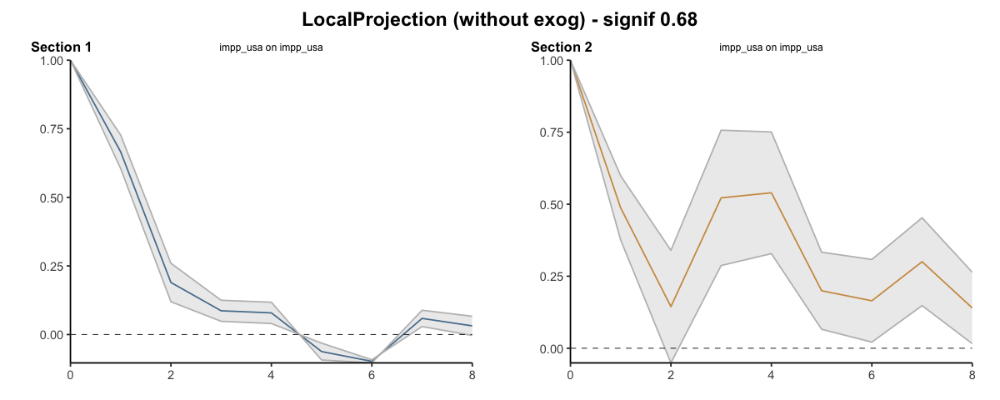

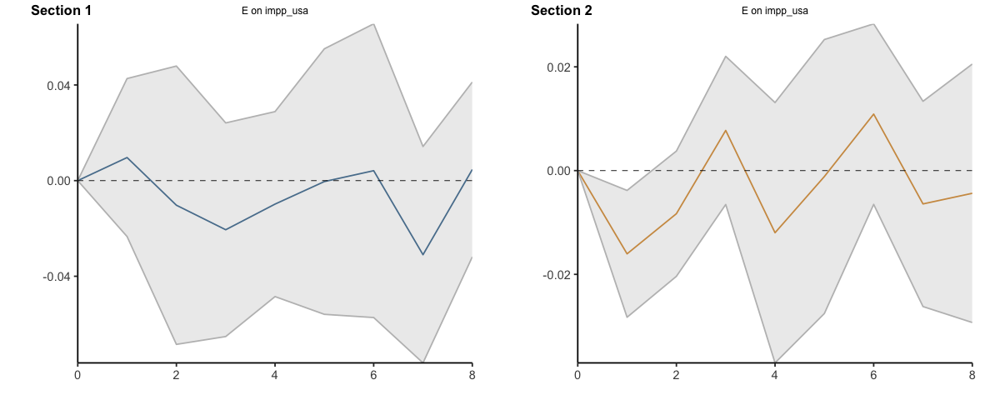

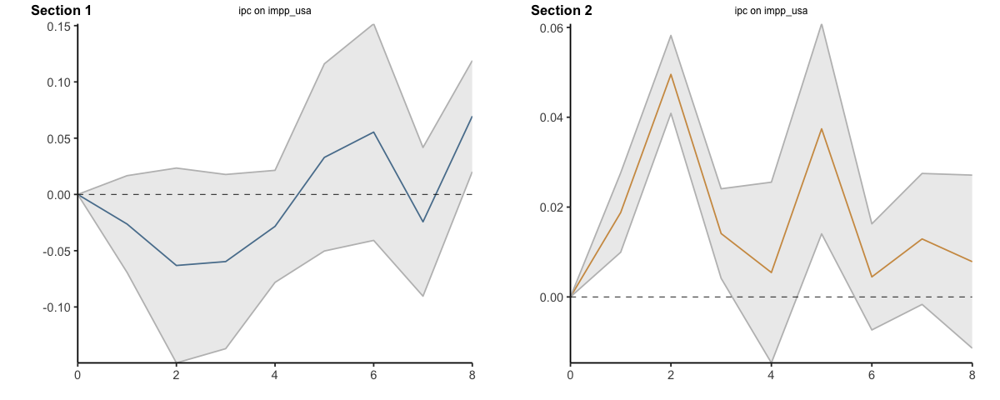

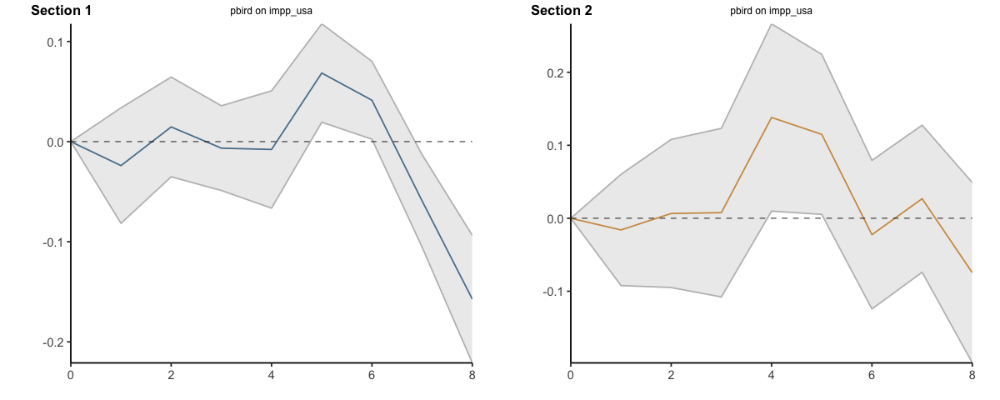

...

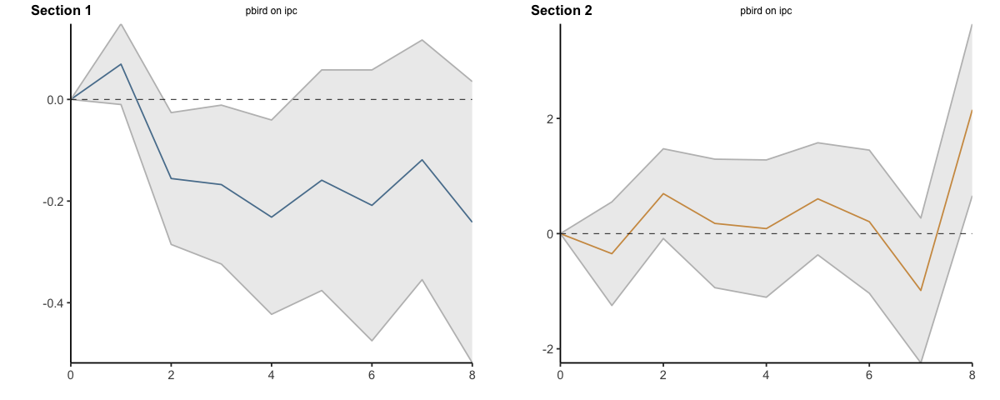

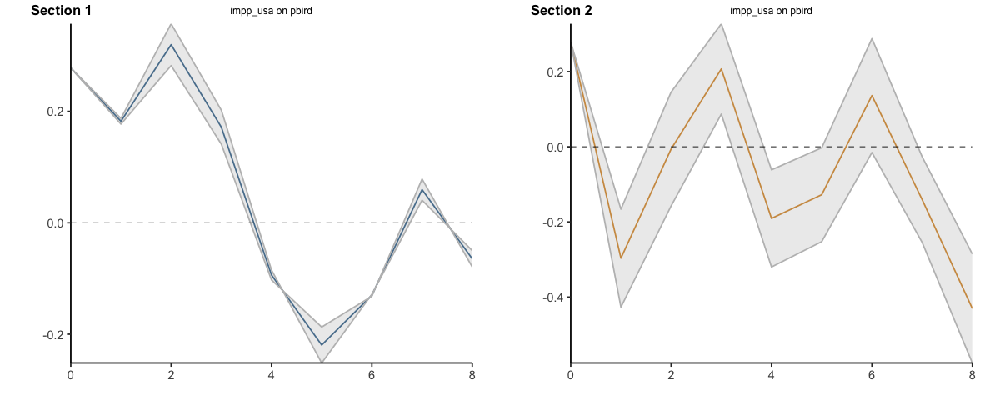

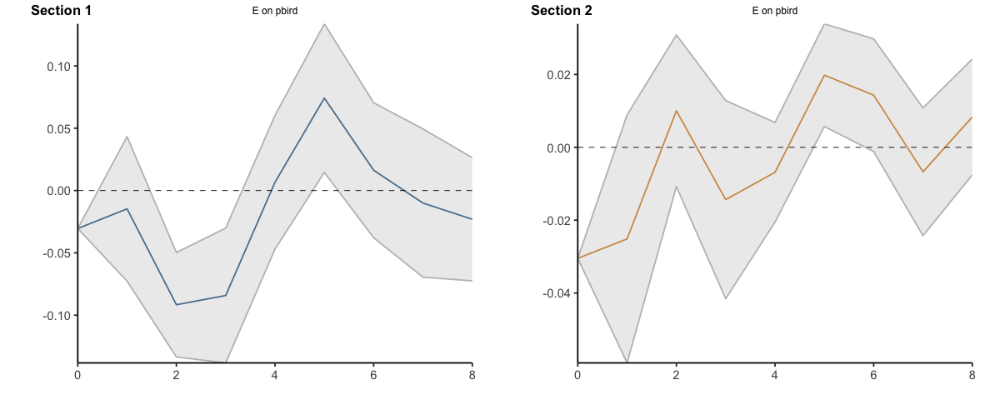

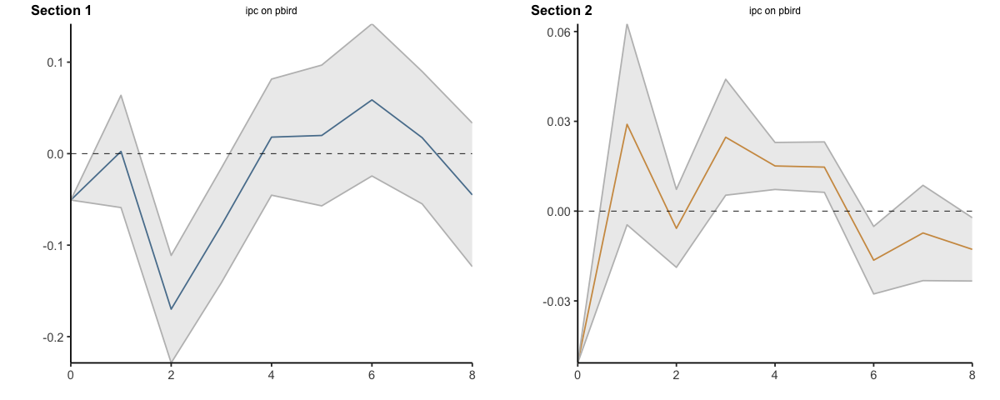

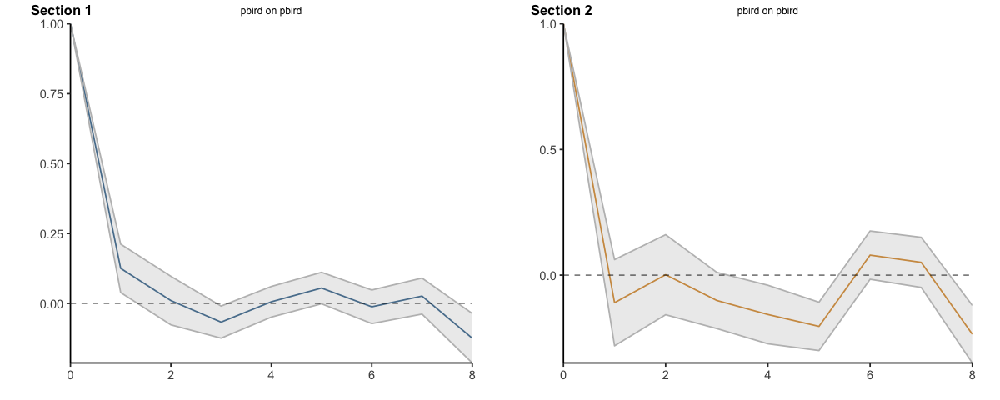

In [7]:
res <- run_lp_model(df_ERPT_Arg, endog=c("impp_usa", "E", "ipc", "pbird"), fixed_lags = 2, horizons=8, signif = 0.68, threshold_var = 'ipc', upper_threshold=0.725423728813559)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<dbl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,2,NaN,NA,NA,0,1,0.68,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,295,"impp_usa, E, ipc, pbird",4


Impulse: impp_usa -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,0,-1.44463181,-1.4446318,-1.4446318,-1.4446318,-1.444632,-1.444632
2,1,-2.38978612,-2.4359031,-2.3436692,0.6986752,-2.434504,3.831854
3,2,-3.27898682,-3.4205446,-3.1374290,3.2296988,-2.778623,9.238021
4,3,-3.22444666,-3.2948531,-3.1540402,0.8609424,-6.388352,8.110237
5,4,-2.86501264,-3.3805669,-2.3494584,2.6941196,-7.021454,12.409694
6,5,-2.21122661,-3.1014031,-1.3210501,4.8270905,-6.213096,15.867277
7,6,-1.19621736,-2.6295928,0.2371581,3.8635899,-8.872375,16.599555
8,7,0.08155053,-1.9821505,2.1452515,6.2740439,-7.994430,20.542518
9,8,1.13980248,-0.9535946,3.2331995,10.5521040,-5.572874,26.677082


Impulse: impp_usa -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
10,0,-0.7268158,-0.7268158,-0.7268158,-0.7268158,-0.7268158,-0.7268158
11,1,-1.3127274,-1.2578618,-1.3675929,1.0297638,-0.3107942,2.3703218
12,2,-1.7970250,-1.7304354,-1.8636147,3.5179821,-0.6095955,7.6455597
13,3,-1.9345637,-1.8154177,-2.0537098,3.0438691,-2.0037982,8.0915363
14,4,-1.9238784,-1.7826308,-2.0651259,5.2342574,-1.8233729,12.2918878
15,5,-1.7759370,-1.7010587,-1.8508153,7.5137143,-1.2232642,16.2506928
16,6,-1.3076104,-1.5827480,-1.0324728,7.6121131,-2.4003166,17.6245429
17,7,-0.7603198,-1.3501042,-0.1705355,8.9324919,-2.1381192,20.0031030
18,8,0.0489296,-0.8352330,0.9330922,11.8590329,-0.6046681,24.3227340


... (16 outputs left out)

Impulse: pbird -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
91,0,0.000000,0.0000000,0.0000000,0.000000000,0.000000,0.00000000
92,1,-0.574457,-0.8883924,-0.2605217,-1.488599142,-2.893292,-0.08390632
93,2,-1.437753,-2.2558123,-0.6196943,-0.638802593,-3.111585,1.83397978
94,3,-2.002464,-3.1869601,-0.8179678,-0.733793467,-4.701279,3.23369255
95,4,-2.406560,-3.9839015,-0.8292192,-1.201305854,-6.733907,4.33129549
96,5,-2.198830,-4.2302120,-0.1674484,-0.008981934,-6.759739,6.74177555
97,6,-2.531445,-4.9207515,-0.1421384,-1.247830440,-9.493527,6.99786566
98,7,-2.979020,-5.8185104,-0.1395288,-1.649806819,-11.122719,7.82310580
99,8,-3.659329,-6.8662451,-0.4524137,1.331880597,-10.253773,12.91753418


Impulse: pbird -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
100,0,0.00000000,0.00000000,0.00000000,0.0000000,0.000000,0.0000000
101,1,0.06937606,-0.01001112,0.14876323,-0.3484455,-1.247744,0.5508534
102,2,-0.08623011,-0.29534252,0.12288231,0.3455644,-1.332917,2.0240453
103,3,-0.25375733,-0.61920170,0.11168704,0.5226753,-2.271416,3.3167666
104,4,-0.48539778,-1.04199755,0.07120198,0.6099800,-3.375989,4.5959489
105,5,-0.64434392,-1.41796963,0.12928180,1.2140111,-3.745127,6.1731497
106,6,-0.85274250,-1.89281911,0.18733411,1.4211855,-4.780600,7.6229714
107,7,-0.97158255,-2.24747642,0.30431131,0.4338426,-7.025157,7.8928418
108,8,-1.21321647,-2.76585478,0.33942184,2.5840046,-6.367350,11.5353591


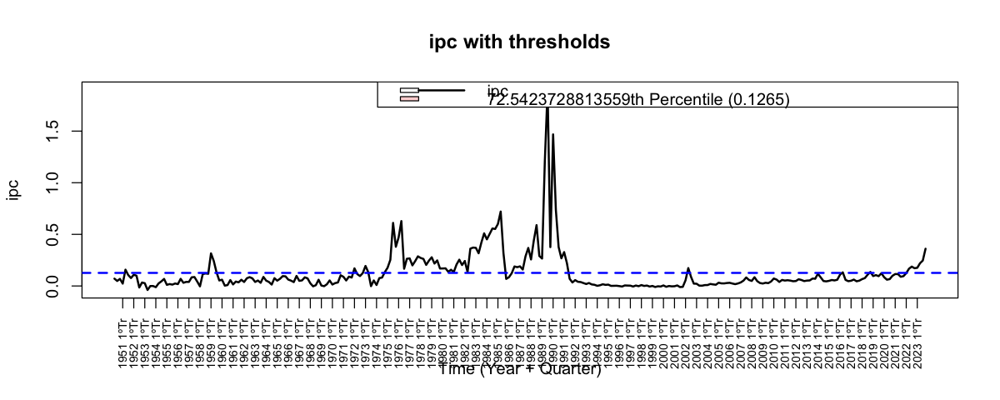

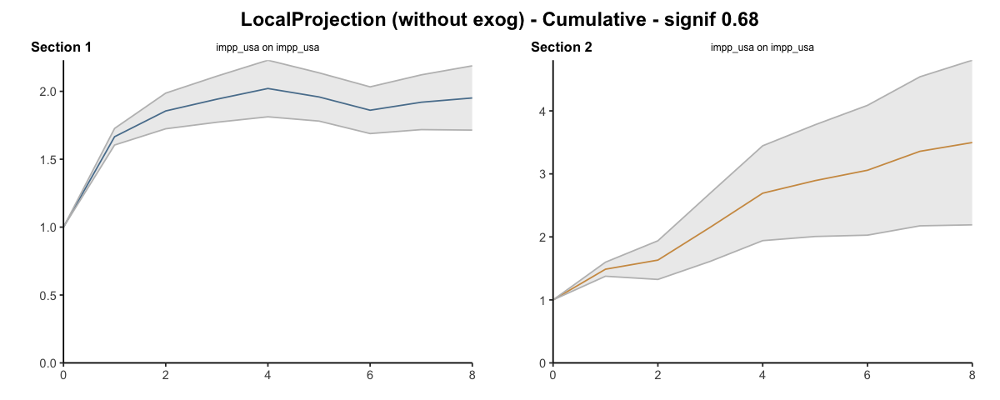

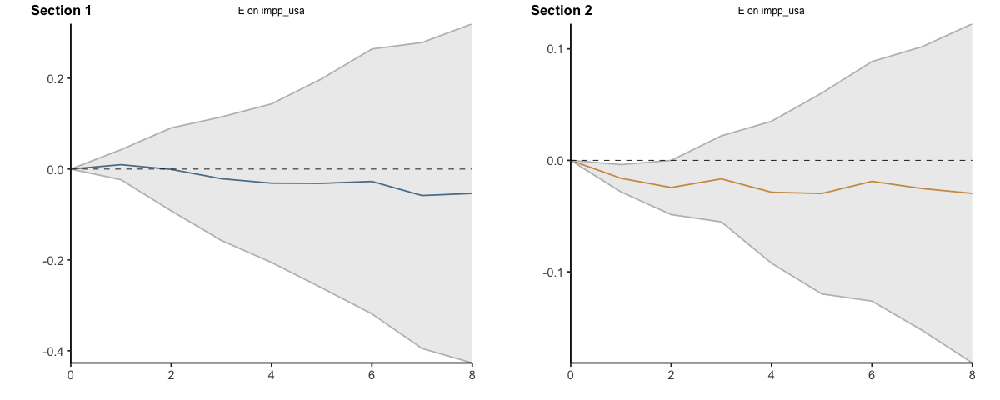

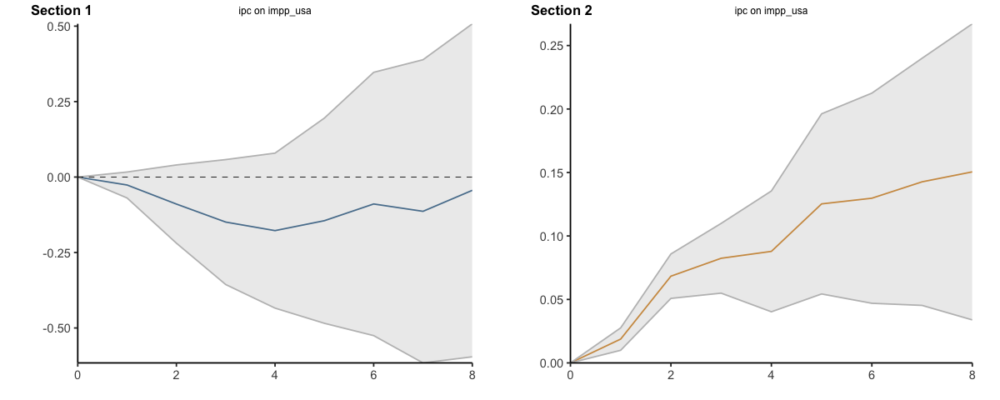

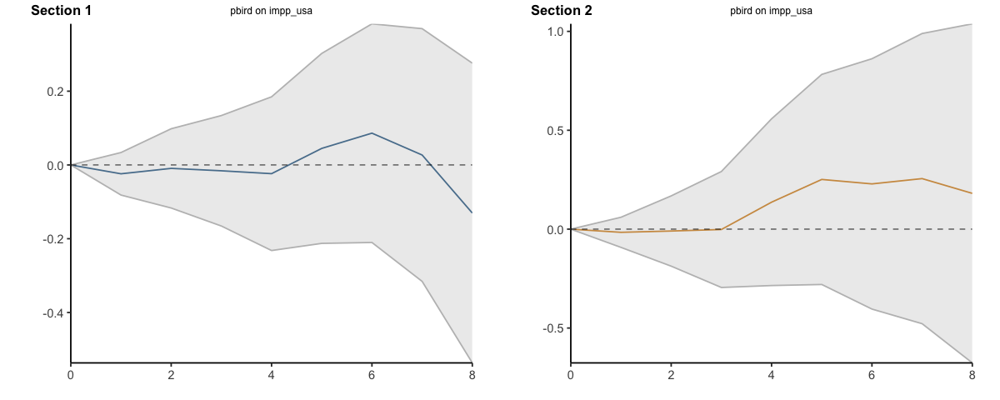

...

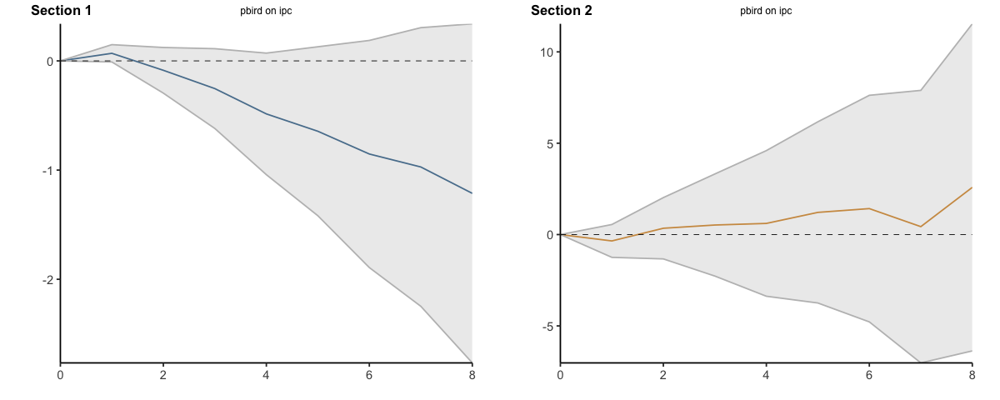

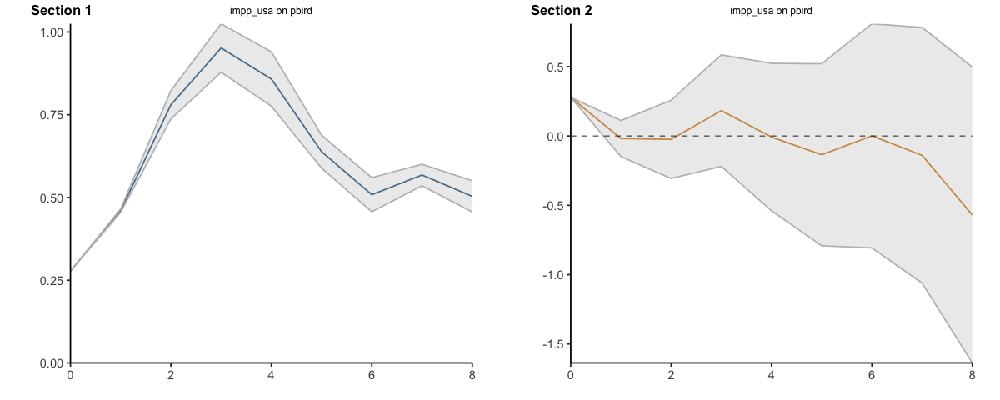

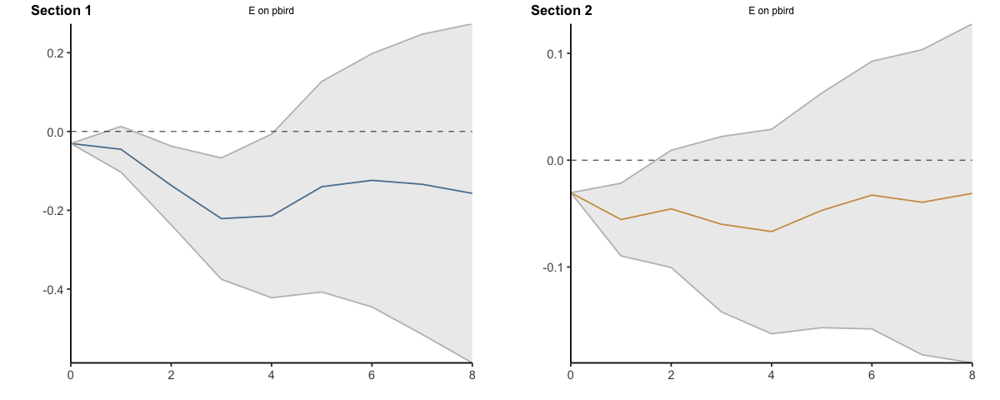

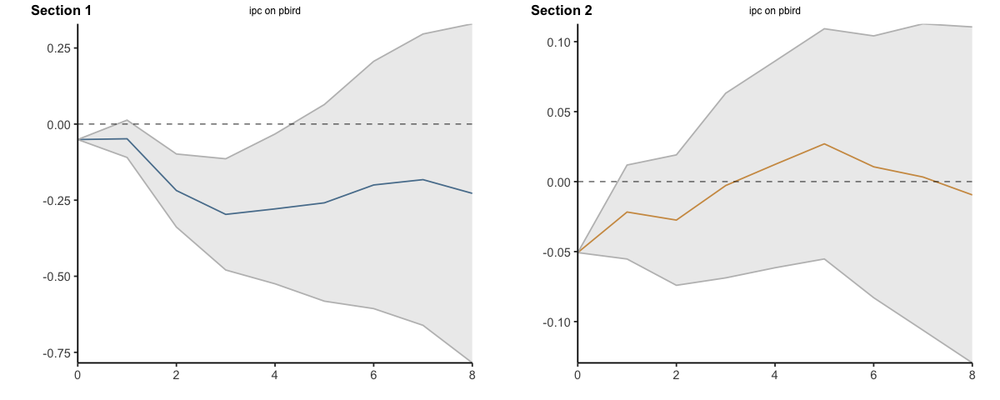

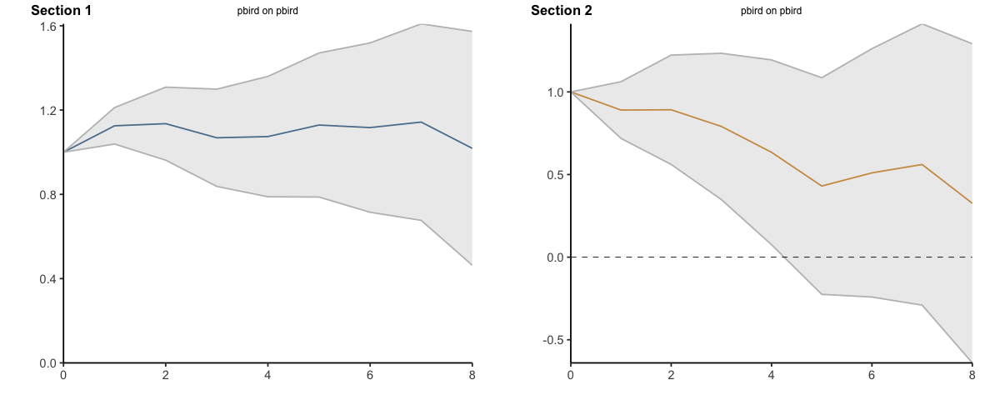

In [8]:
res <- run_lp_model(df_ERPT_Arg, endog=c("impp_usa", "E", "ipc", "pbird"), fixed_lags = 2, horizons=8, signif = 0.68, threshold_var = 'ipc', upper_threshold=0.725423728813559, cumulative = TRUE)

#### Percentile 0.725423728813559 (12,5% inflación trimestral) - quedan 81 trimestres por encima del umbral


Umbral: ipc > 0.1265 (percentil 72.5 )
Trimestres por régimen: debajo del umbral (dummy = 0) = 214 | encima del umbral (dummy = 1) = 81 


Bootstrap por bloques circular: 500 réplicas, bloques de 20 trimestres...



  |======================================================================| 100%
ERPT de un shock unitario en E sobre ipc ( LP, 2 rezagos, umbral: ipc > 0,127, 81 trimestres encima )

Régimen 1 (debajo del umbral)
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.4562         0.4562       1.0000
         1              0.8625         0.6199       1.3914
         2              1.1674         0.7247       1.6110
         3              1.3431         0.8904       1.5085
         4              1.4502         1.0241       1.4160
         5              1.4742         1.0495       1.4046
         6              1.5067         1.1367       1.3254
         7              1.5484         1.3389       1.1565
         8              1.4255         1.8495       0.7707
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.4562             0.4562
                  0.4064             0.1637
                  0.3049             0.1048
                  0.1

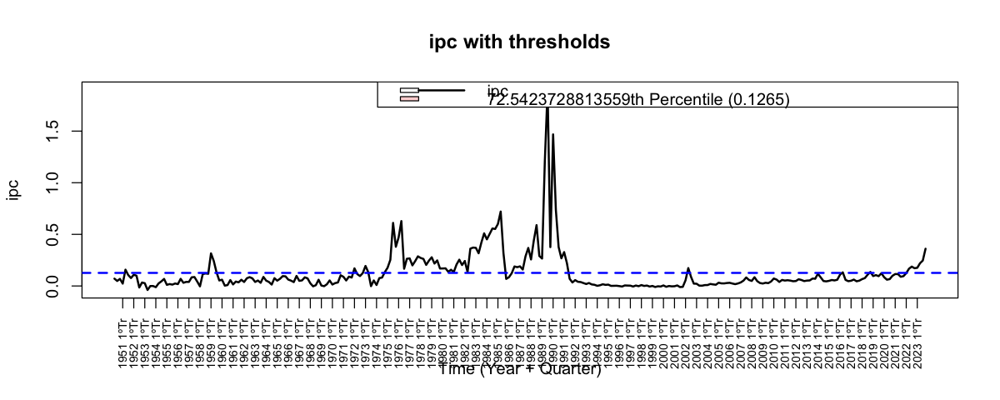

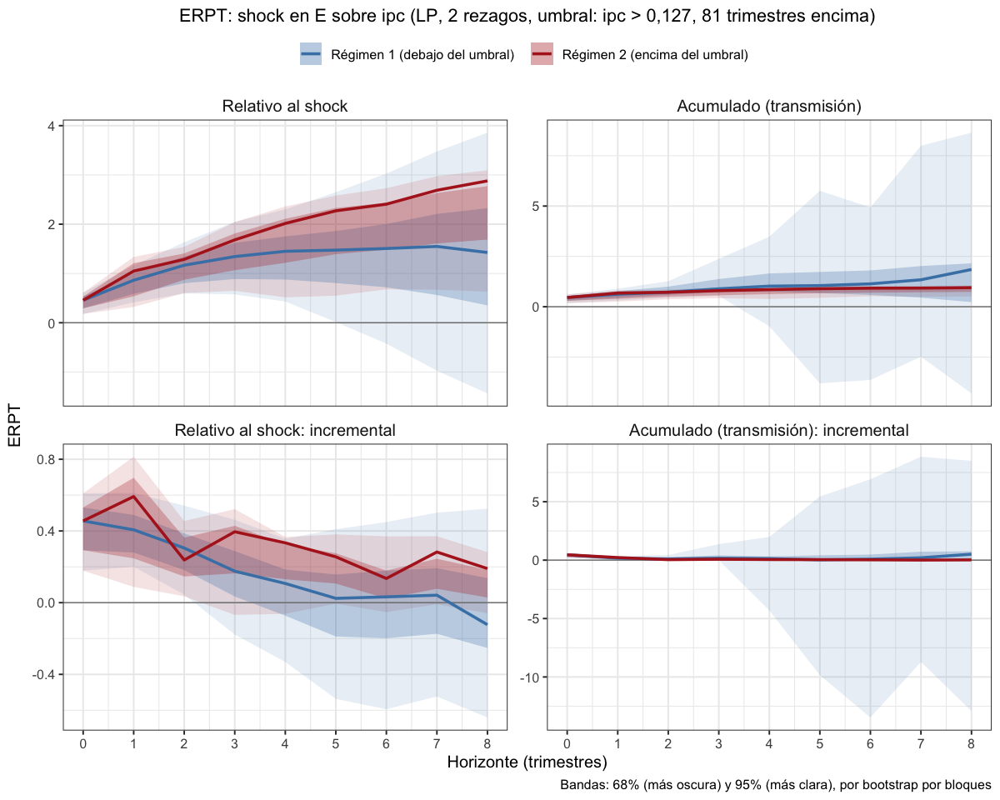

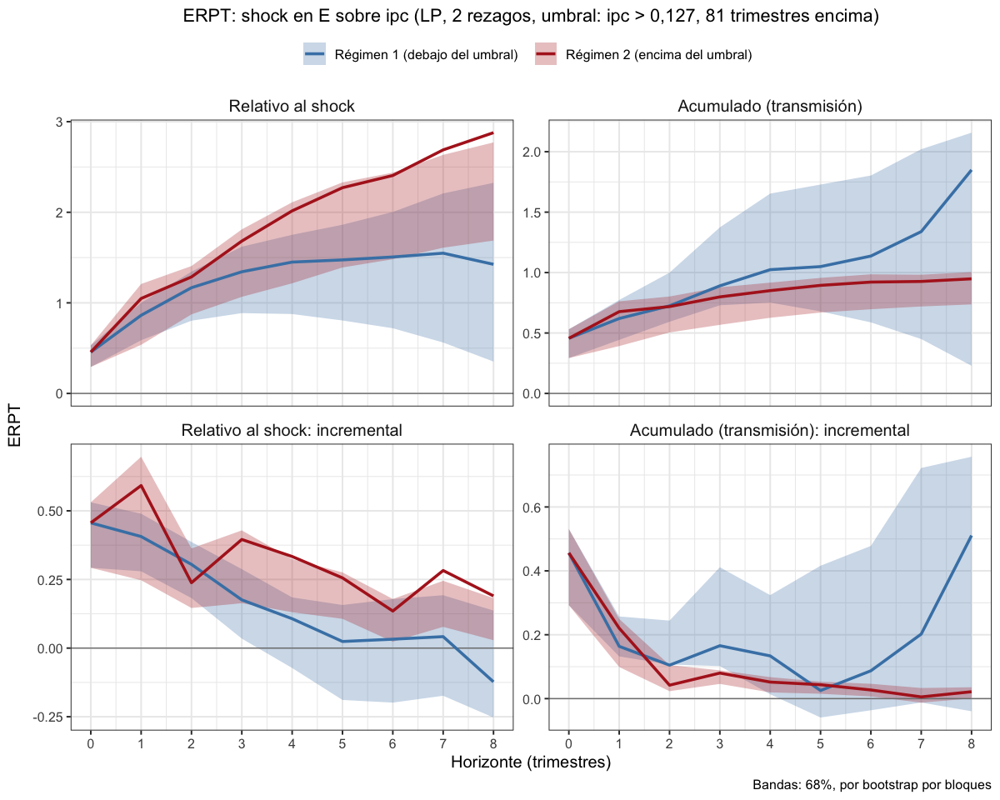

In [9]:
lp_erpt_endog_p2_tvar12.5 <- erpt_lp(df_ERPT_Arg, endog = c("impp_usa", "E", "ipc", "pbird"),
                                     fixed_lags = 2, horizons = 8, reps = 500,
                                     threshold_var = "ipc", upper_threshold = 0.725423728813559)
saveRDS(lp_erpt_endog_p2_tvar12.5, "lp_erpt_endog_p2_tvar12.5.rds")
graficar_erpt_lp(lp_erpt_endog_p2_tvar12.5, archivo = "lp_erpt_endog_p2_tvar12.5")
graficar_erpt_lp(lp_erpt_endog_p2_tvar12.5, niveles = 0.68, archivo = "lp_erpt_endog_p2_tvar12.5_68")

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<dbl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,2,NaN,NA,NA,0,1,0.68,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,295,"impp_usa, E, ipc, pbird",4


Impulse: impp_usa -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,0,-1.44463181,-1.44463181,-1.44463181,-1.4446318,-1.444632,-1.4446318
2,1,-0.54694599,-1.12146151,0.02756953,-4.7254689,-7.763113,-1.6878245
3,2,-0.26735843,-0.58315038,0.04843353,-3.8813144,-7.872010,0.1093812
4,3,-0.65269873,-0.72557897,-0.57981849,0.1083833,-6.712829,6.9295958
5,4,-0.24865909,-0.80498775,0.30766956,19.6554395,2.970980,36.3398994
6,5,0.17830702,-0.26725784,0.62387188,11.0884426,-2.332008,24.5088935
7,6,-0.30947351,-0.93814931,0.31920230,-0.2688092,-6.822434,6.2848156
8,7,-0.06155936,-0.25834384,0.13522513,8.0317780,-3.465412,19.5289677
9,8,0.27651975,0.05830674,0.49473276,0.6791219,-3.498812,4.8570559


Impulse: impp_usa -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
10,0,-0.726815837,-0.7268158,-0.726815837,-0.7268158,-0.7268158,-0.7268158
11,1,-0.362103379,-0.6277467,-0.096460073,1.8809024,-1.2146938,4.9764986
12,2,0.000320205,-0.4235778,0.424218202,-2.6572697,-5.7883505,0.4738111
13,3,-0.309234316,-0.3039870,-0.314481622,-2.4664321,-7.1172546,2.1843904
14,4,-0.099391820,-0.4081415,0.209357859,10.8074661,-0.5108922,22.1258245
15,5,-0.190373420,-0.3763146,-0.004432238,13.9502400,-0.1021517,28.0026317
16,6,-0.372541796,-0.7228891,-0.022194485,2.7901534,-2.9707036,8.5510104
17,7,-0.647449020,-0.8402925,-0.454605529,9.8935889,-2.5233022,22.3104800
18,8,0.039006059,-0.2024072,0.280419305,3.8648954,-1.9019077,9.6316986


... (16 outputs left out)

Impulse: pbird -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
91,0,0.0000000,0.0000000,0.000000000,0.000000,0.000000,0.00000000
92,1,-0.7808468,-1.2315296,-0.330164029,-2.376807,-5.828988,1.07537341
93,2,-0.5606332,-1.0219990,-0.099267401,9.589314,8.080430,11.09819862
94,3,-0.3202787,-0.6806370,0.040079546,3.076418,-4.276282,10.42911758
95,4,-0.2492341,-0.5904164,0.091948108,-12.490238,-26.966189,1.98571177
96,5,0.7144139,0.2440743,1.184753486,-6.594620,-16.554466,3.36522505
97,6,-0.4069183,-0.8222219,0.008385363,-5.236075,-10.544279,0.07212925
98,7,-0.3146878,-0.6927244,0.063348689,-6.791437,-15.969000,2.38612516
99,8,0.3775192,-0.1466745,0.901712903,-1.604238,-5.209744,2.00126887


Impulse: pbird -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
100,0,0.000000000,0.00000000,0.00000000,0.000000,0.000000,0.0000000
101,1,0.107561874,-0.01989516,0.23501890,-1.028167,-3.937465,1.8811302
102,2,-0.097350288,-0.27788427,0.08318369,6.235304,4.031634,8.4389743
103,3,-0.015167485,-0.23720462,0.20686965,6.265752,2.018911,10.5125917
104,4,-0.006117167,-0.21681629,0.20458196,-6.596275,-17.537620,4.3450697
105,5,0.288098995,0.02913925,0.54705874,-9.468209,-19.462434,0.5260166
106,6,0.119226228,-0.16280617,0.40125862,-5.758323,-11.359774,-0.1568723
107,7,-0.133840534,-0.42164161,0.15396054,-9.213642,-19.200292,0.7730090
108,8,0.615882079,0.17300835,1.05875581,-4.531322,-9.207038,0.1443951


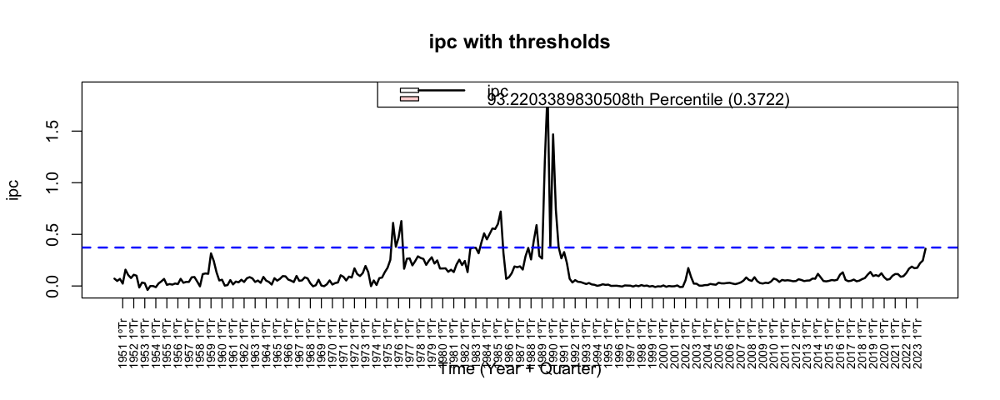

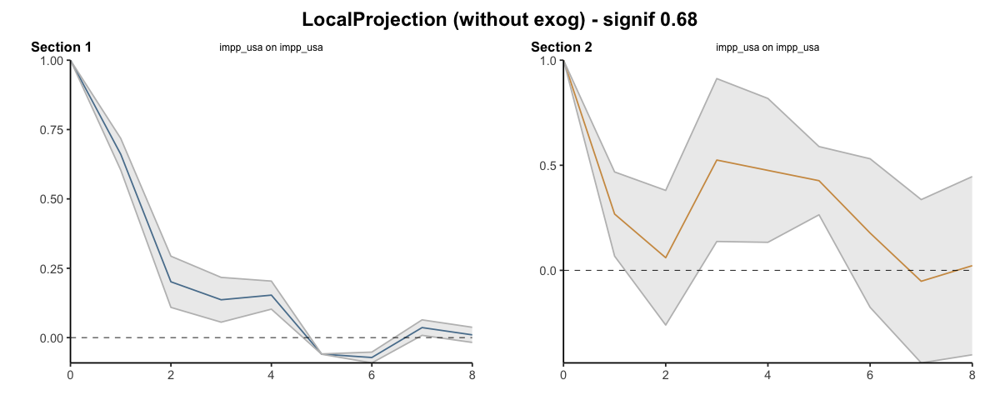

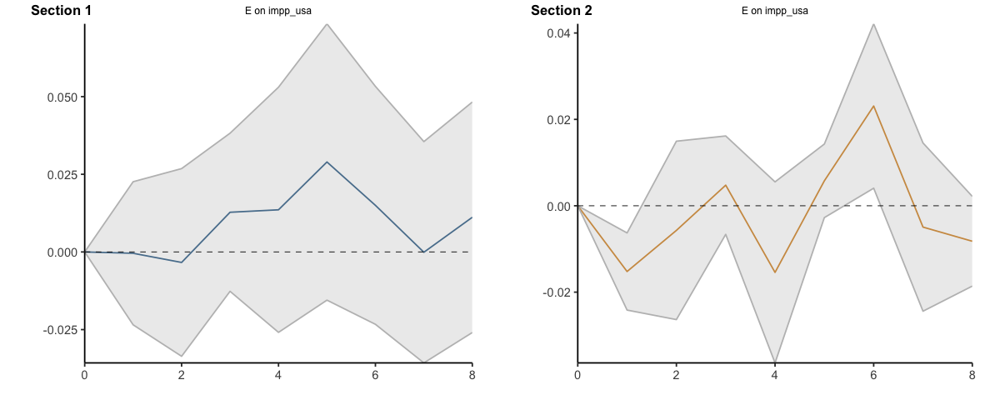

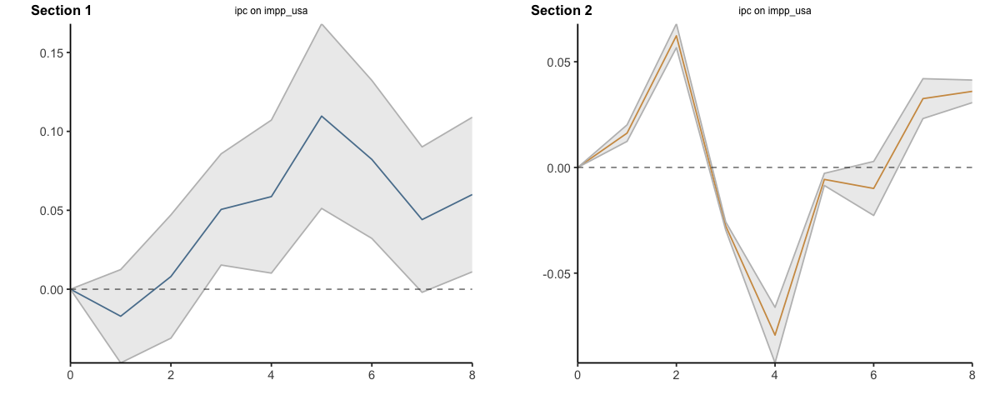

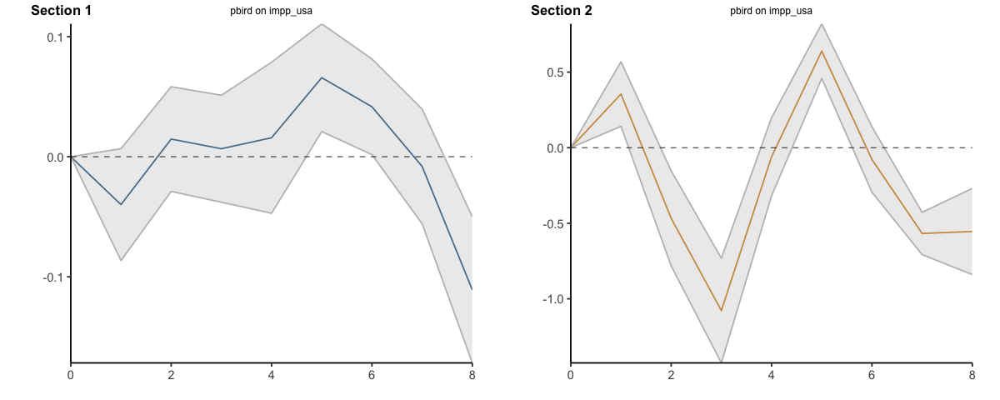

...

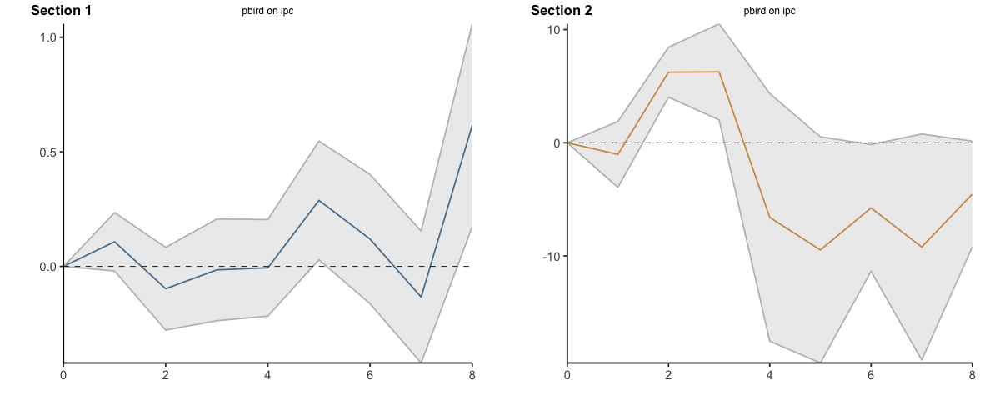

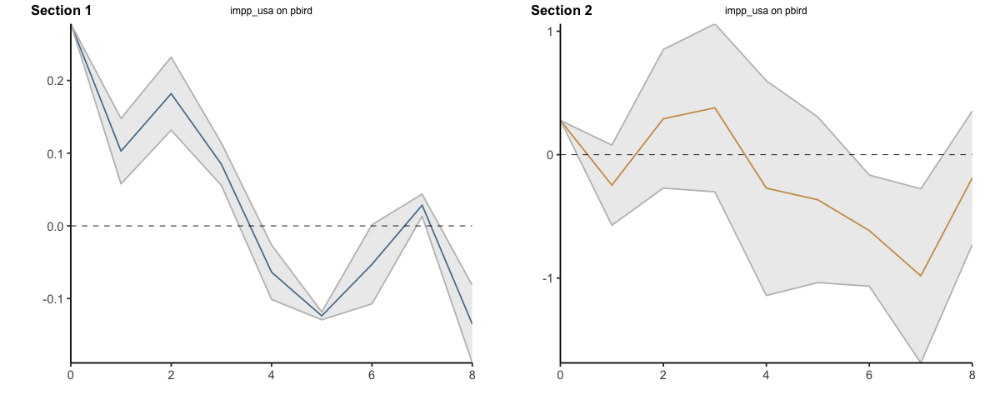

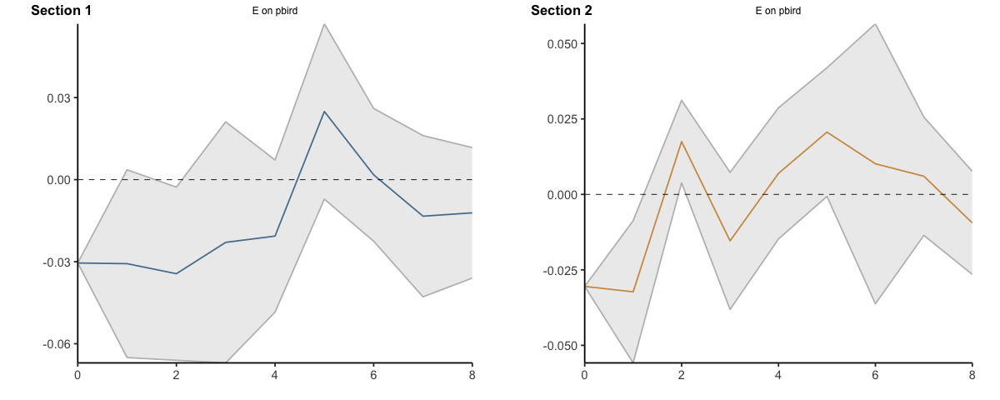

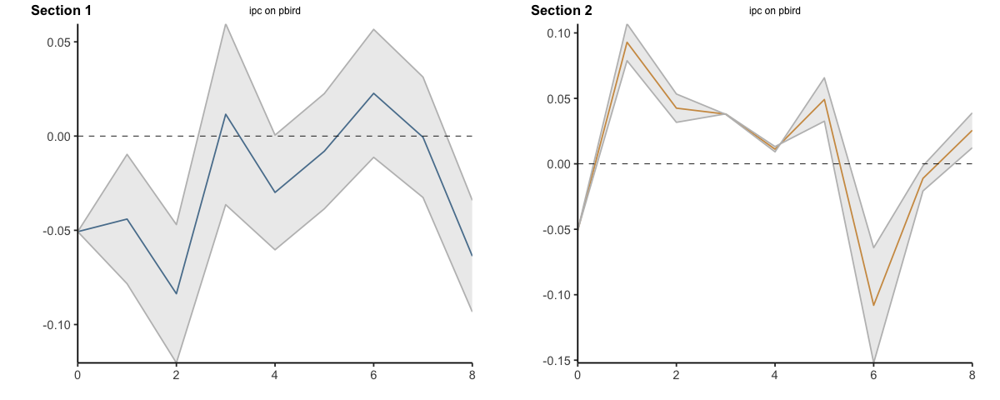

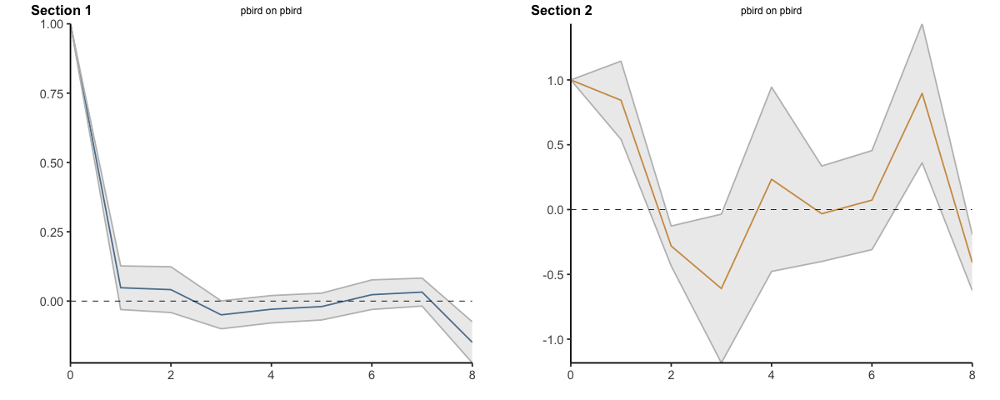

In [10]:
res <- run_lp_model(df_ERPT_Arg, endog=c("impp_usa", "E", "ipc", "pbird"), fixed_lags = 2, horizons=8, signif = 0.68, threshold_var = 'ipc', upper_threshold=0.932203389830508)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<dbl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,2,NaN,NA,NA,0,1,0.68,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,295,"impp_usa, E, ipc, pbird",4


Impulse: impp_usa -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,0,-1.444632,-1.444632,-1.44463181,-1.444632,-1.444632,-1.444632
2,1,-1.991578,-2.566093,-1.41706228,-6.170101,-9.207745,-3.132456
3,2,-2.258936,-3.149244,-1.36862875,-10.051415,-17.079755,-3.023075
4,3,-2.911635,-3.874823,-1.94844724,-9.943032,-23.792584,3.906521
5,4,-3.160294,-4.679810,-1.64077768,9.712408,-20.821605,40.246420
6,5,-2.981987,-4.947068,-1.01690579,20.800850,-23.153613,64.755314
7,6,-3.291461,-5.885218,-0.69770349,20.532041,-29.976047,71.040129
8,7,-3.353020,-6.143561,-0.56247837,28.563819,-33.441459,90.569097
9,8,-3.076500,-6.085255,-0.06774561,29.242941,-36.940271,95.426153


Impulse: impp_usa -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
10,0,-0.7268158,-0.7268158,-0.7268158,-0.7268158,-0.7268158,-0.7268158
11,1,-1.0889192,-1.3545625,-0.8232759,1.1540865,-1.9415097,4.2496828
12,2,-1.0885990,-1.7781403,-0.3990577,-1.5031832,-7.7298602,4.7234939
13,3,-1.3978333,-2.0821273,-0.7135393,-3.9696153,-14.8471149,6.9078842
14,4,-1.4972251,-2.4902688,-0.5041815,6.8378508,-15.3580071,29.0337087
15,5,-1.6875986,-2.8665834,-0.5086137,20.7880909,-15.4601587,57.0363404
16,6,-2.0601404,-3.5894725,-0.5308082,23.5782443,-18.4308624,65.5873509
17,7,-2.7075894,-4.4297650,-0.9854137,33.4718331,-20.9541645,87.8978308
18,8,-2.6685833,-4.6321722,-0.7049944,37.3367286,-22.8560722,97.5295294


... (16 outputs left out)

Impulse: pbird -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
91,0,0.0000000,0.000000,0.0000000,0.000000,0.000000,0.000000
92,1,-0.7808468,-1.231530,-0.3301640,-2.376807,-5.828988,1.075373
93,2,-1.3414800,-2.253529,-0.4294314,7.212507,2.251442,12.173572
94,3,-1.6617587,-2.934166,-0.3893519,10.288925,-2.024840,22.602690
95,4,-1.9109929,-3.524582,-0.2974038,-2.201314,-28.991029,24.588401
96,5,-1.1965790,-3.280508,0.8873497,-8.795934,-45.545495,27.953626
97,6,-1.6034973,-4.102730,0.8957351,-14.032009,-56.089774,28.025756
98,7,-1.9181851,-4.795454,0.9590838,-20.823446,-72.058773,30.411881
99,8,-1.5406659,-4.942128,1.8607967,-22.427684,-77.268517,32.413150


Impulse: pbird -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
100,0,0.000000000,0.00000000,0.0000000,0.000000,0.00000000,0.00000
101,1,0.107561874,-0.01989516,0.2350189,-1.028167,-3.93746497,1.88113
102,2,0.010211587,-0.29777942,0.3182026,5.207137,0.09416948,10.32010
103,3,-0.004955898,-0.53498404,0.5250722,11.472889,2.11308087,20.83270
104,4,-0.011073065,-0.75180033,0.7296542,4.876614,-15.42453885,25.17777
105,5,0.277025930,-0.72266108,1.2767129,-4.591595,-34.88697285,25.70378
106,6,0.396252157,-0.88546724,1.6779716,-10.349918,-46.24674646,25.54691
107,7,0.262411623,-1.30710886,1.8319321,-19.563560,-65.44703862,26.31992
108,8,0.878293702,-1.13410051,2.8906879,-24.094881,-74.65407690,26.46431


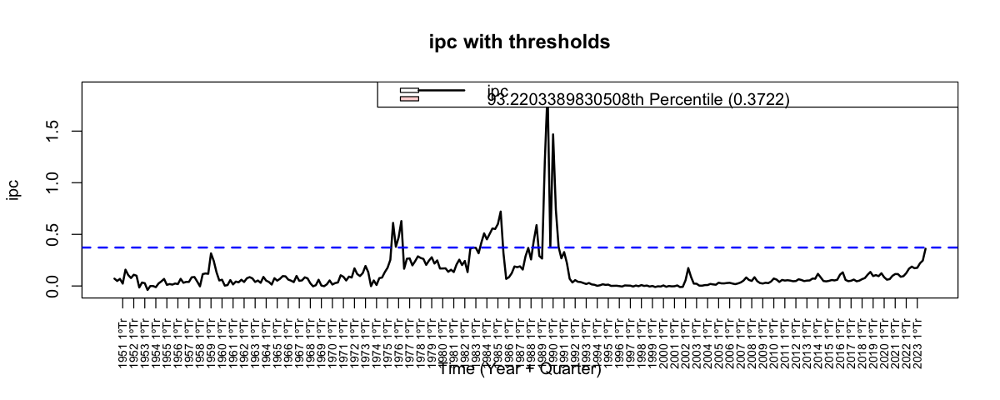

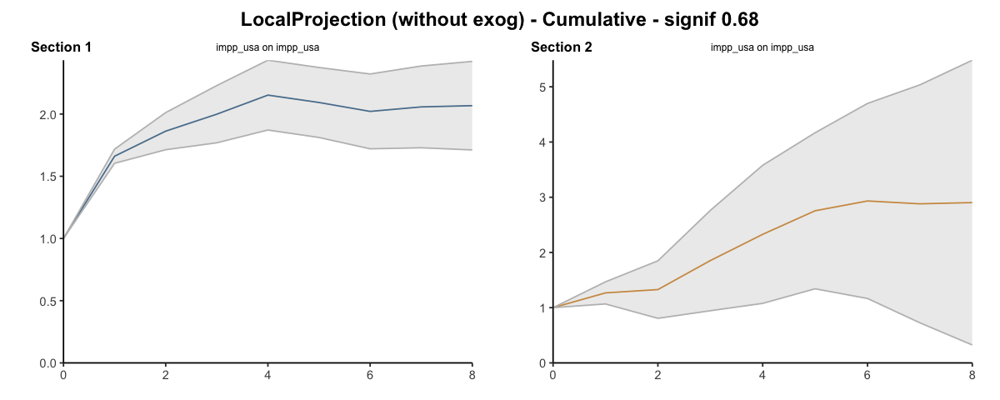

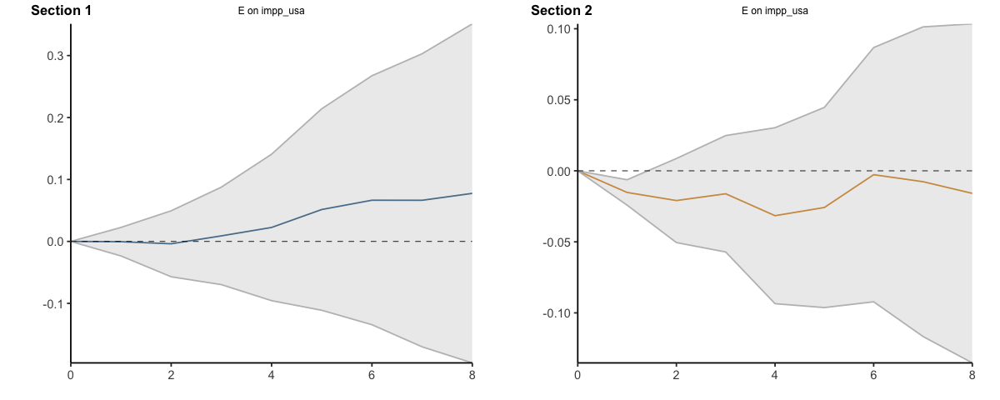

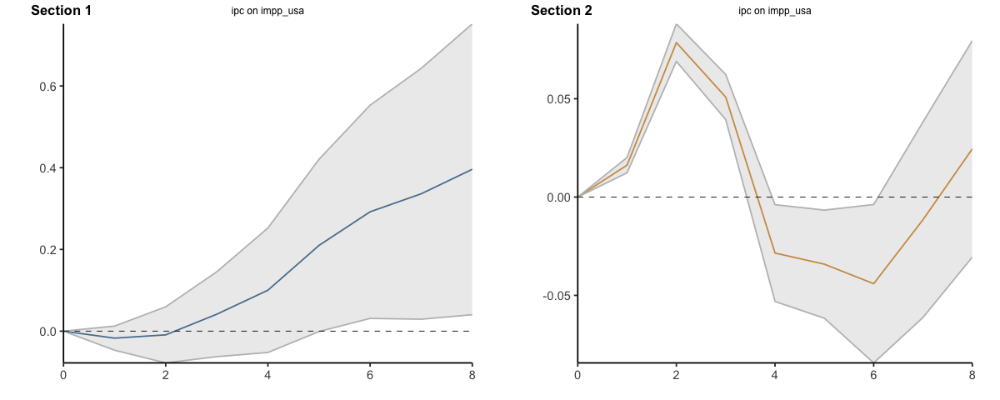

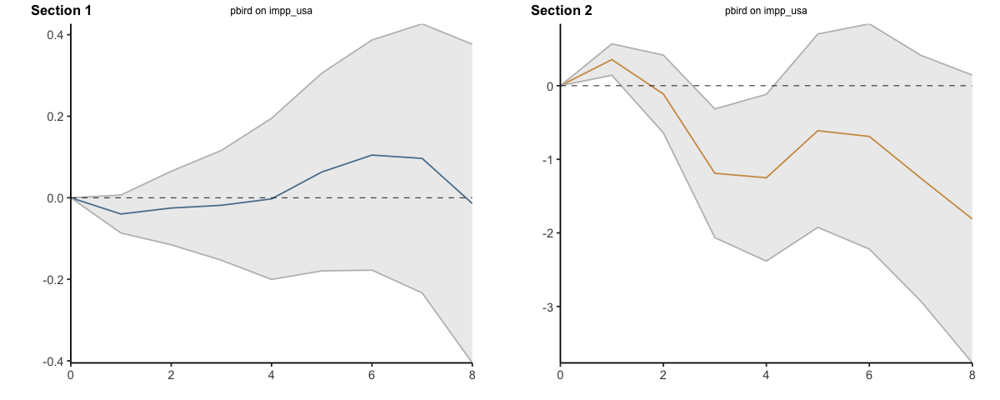

...

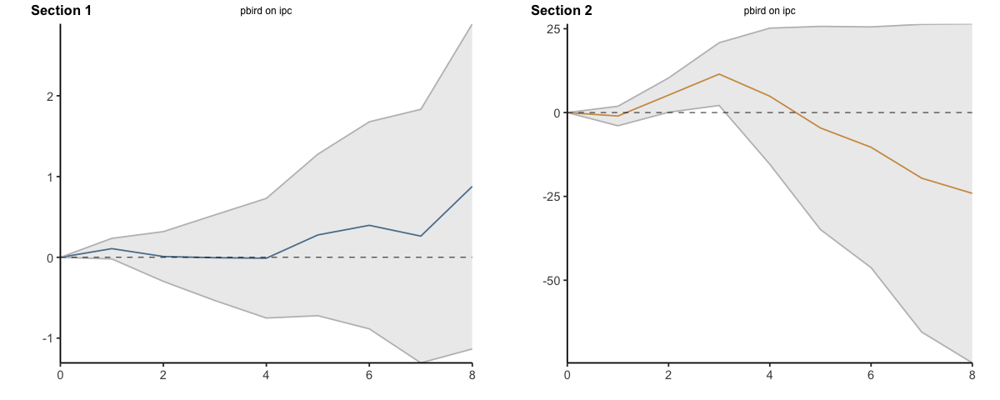

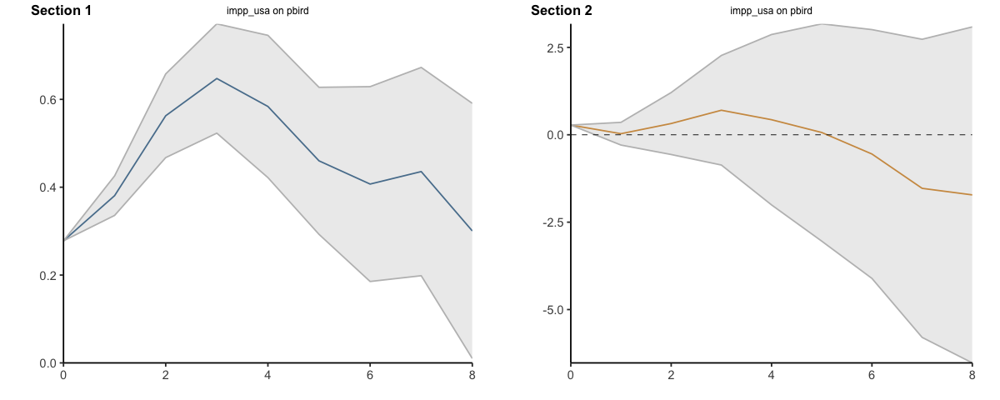

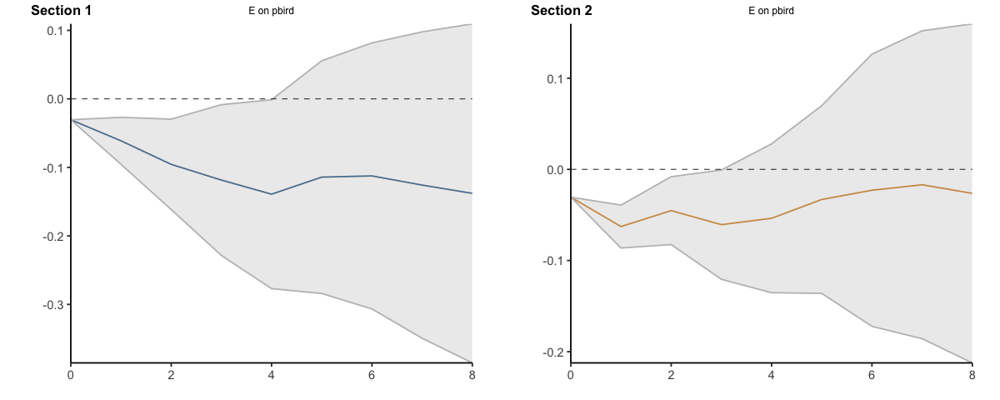

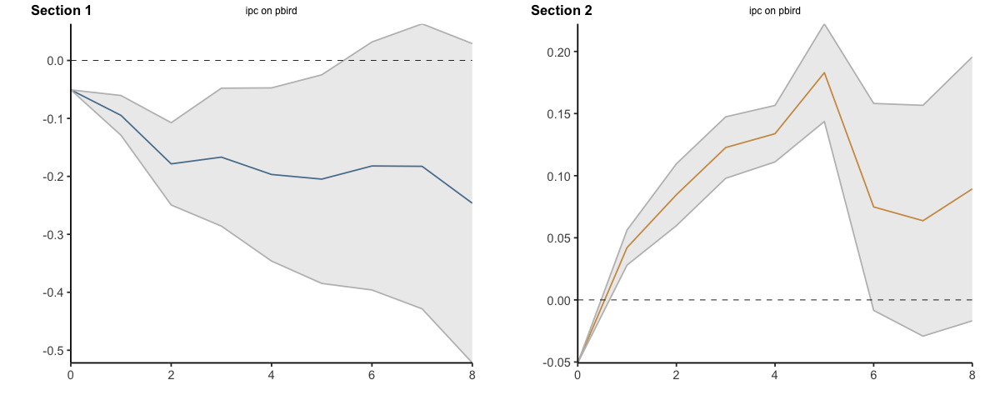

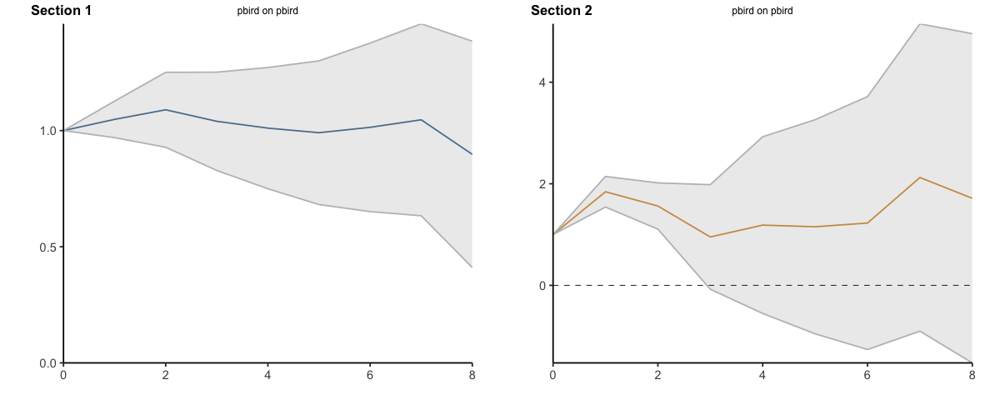

In [11]:
res <- run_lp_model(df_ERPT_Arg, endog=c("impp_usa", "E", "ipc", "pbird"), fixed_lags = 2, horizons=8, signif = 0.68, threshold_var = 'ipc', upper_threshold=0.932203389830508, cumulative=TRUE)

#### Percentile 0.932203389830508 (37,6% de inflación trimestral) - quedan 20 trimestres por encima del umbral (son pocos)

Umbral: ipc > 0.3722 (percentil 93.2 )
Trimestres por régimen: debajo del umbral (dummy = 0) = 275 | encima del umbral (dummy = 1) = 20 


Bootstrap por bloques circular: 500 réplicas, bloques de 20 trimestres...



  |======================================================================| 100%


10 réplicas fallaron y se descartaron.



ERPT de un shock unitario en E sobre ipc ( LP, 2 rezagos, umbral: ipc > 0,372, 20 trimestres encima )

Régimen 1 (debajo del umbral)
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.4562         0.4562       1.0000
         1              0.9273         0.5914       1.5681
         2              1.3443         0.7027       1.9130
         3              1.6426         0.7671       2.1414
         4              2.0857         0.8536       2.4434
         5              2.3899         0.8936       2.6746
         6              2.7799         0.9105       3.0533
         7              3.4027         0.9262       3.6738
         8              3.9018         0.9348       4.1739
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.4562             0.4562
                  0.4711             0.1352
                  0.4170             0.1114
                  0.2983             0.0643
                  0.4431             0.0866
             

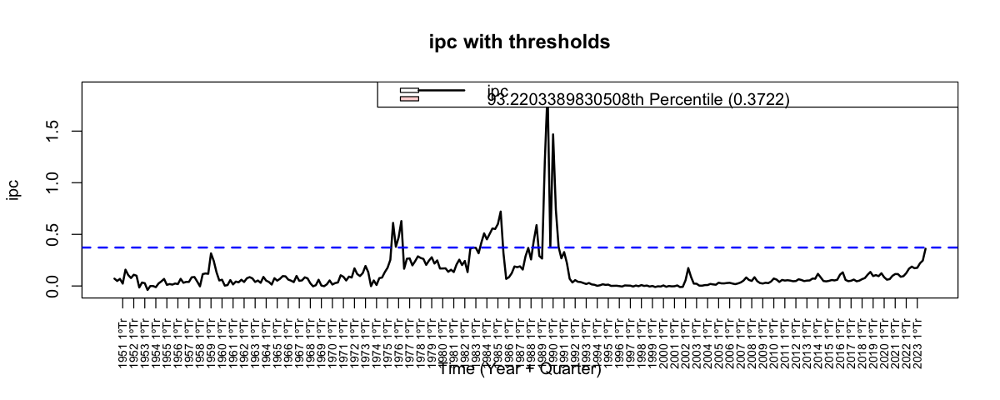

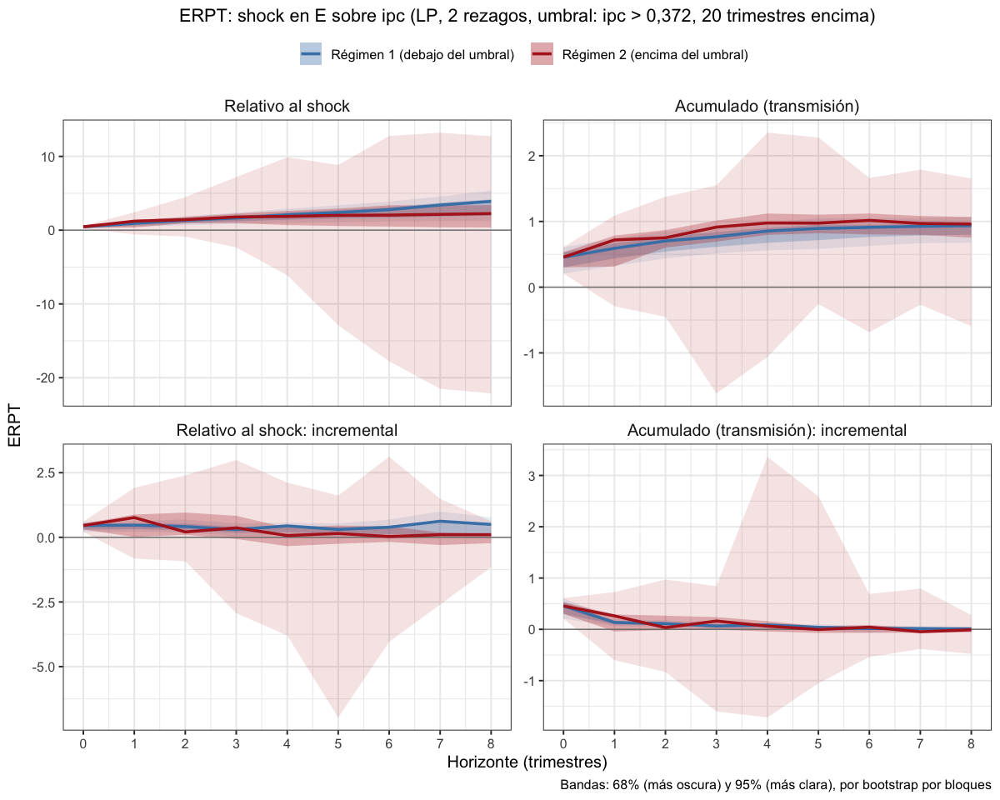

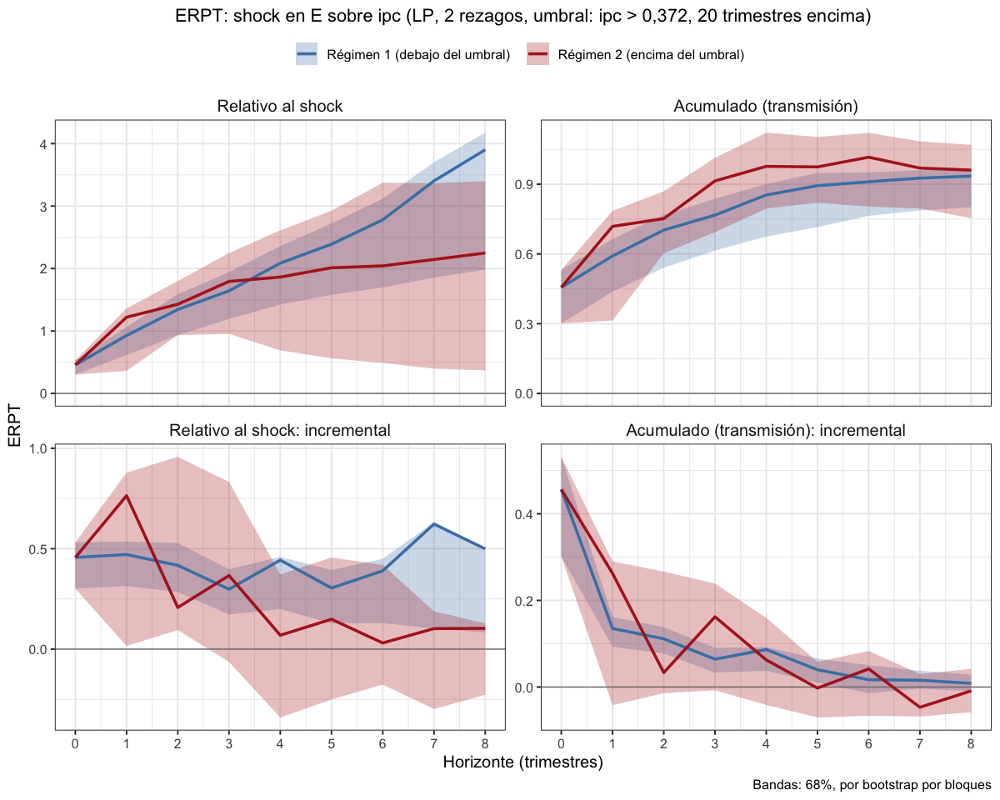

In [12]:
# Todas endógenas con umbral en 37,6% de inflación trimestral (umbral del TVAR-indt), 2 rezagos
lp_erpt_endog_p2_tvar37.6 <- erpt_lp(df_ERPT_Arg, endog = c("impp_usa", "E", "ipc", "pbird"),
                                     fixed_lags = 2, horizons = 8, reps = 500,
                                     threshold_var = "ipc", upper_threshold = 0.932203389830508)
saveRDS(lp_erpt_endog_p2_tvar37.6, "lp_erpt_endog_p2_tvar37.6.rds")
graficar_erpt_lp(lp_erpt_endog_p2_tvar37.6, archivo = "lp_erpt_endog_p2_tvar37.6")
graficar_erpt_lp(lp_erpt_endog_p2_tvar37.6, niveles = 0.68, archivo = "lp_erpt_endog_p2_tvar37.6_68")

#### Otros percentiles (sin actualizar, son viejos con psoja)


Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<dbl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,2,NaN,NA,NA,0,1,0.95,10,TRUE,TRUE,NA,FALSE,FALSE,0,1,295,"Psoja_USA, E, ipc, pbird",4


Impulse: Psoja_USA -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,1,-0.19460906,-0.1946091,-0.1946091,-0.1946091,-0.1946091,-0.1946091
2,2,-0.38919650,-0.4967647,-0.2816283,-0.3824255,-0.5819266,-0.1829244
3,3,-0.25324193,-0.6612851,0.1548013,-0.8346927,-1.5449205,-0.1244649
4,4,-0.21589586,-0.6932765,0.2614848,-0.9333860,-1.9909816,0.1242096
5,5,-0.07261882,-0.7810548,0.6358171,-0.7144333,-2.4912743,1.0624077
6,6,-0.16688502,-1.1271021,0.7933320,-0.4931996,-2.9796269,1.9932277
7,7,-0.28894835,-1.4470896,0.8691929,-0.1850469,-3.2595827,2.8894889
8,8,-0.23710449,-1.7097765,1.2355675,0.2675465,-3.2155303,3.7506232
9,9,-0.26538707,-1.9841112,1.4533371,0.9151092,-3.1942369,5.0244552


Impulse: Psoja_USA -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
12,1,-0.028387373,-0.02838737,-0.02838737,-0.02838737,-0.02838737,-0.02838737
13,2,-0.004031917,-0.03142829,0.02336446,-0.05202429,-0.21218876,0.10814019
14,3,0.015422113,-0.04718067,0.07802490,-0.36277477,-0.78745393,0.06190438
15,4,0.057423344,-0.05316634,0.16801302,-0.51930970,-1.23489927,0.19627987
16,5,0.162009258,-0.10058189,0.42460041,-0.33345930,-1.54149094,0.87457235
17,6,0.154674873,-0.14309532,0.45244507,-0.15873319,-1.97798658,1.66052019
18,7,0.189315573,-0.20576124,0.58439239,0.17973370,-2.08403562,2.44350303
19,8,0.171537999,-0.41973801,0.76281401,0.54073219,-2.21939699,3.30086137
20,9,0.087518713,-0.67071443,0.84575186,0.79779689,-2.37767045,3.97326422


... (16 outputs left out)

Impulse: pbird -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
111,1,0.000000,0.000000,0.00000000,0.0000000,0.000000,0.0000000
112,2,-0.599547,-1.287054,0.08795953,-1.0595455,-2.886165,0.7670734
113,3,-1.712218,-3.466702,0.04226644,0.1905250,-2.769535,3.1505854
114,4,-2.277038,-4.764662,0.21058610,-0.5594193,-5.864326,4.7454870
115,5,-2.525552,-5.623386,0.57228261,-1.1997963,-9.217340,6.8177476
116,6,-2.050070,-6.110592,2.01045233,-0.1098688,-9.798061,9.5783233
117,7,-2.180099,-6.914278,2.55407991,-1.2243055,-13.411433,10.9628216
118,8,-2.535089,-8.268475,3.19829693,-1.6857795,-15.342965,11.9714057
119,9,-3.235860,-9.752159,3.28043912,0.8732901,-15.678984,17.4255637


Impulse: pbird -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
122,1,0.00000000,0.0000000,0.00000000,0.00000000,0.0000000,0.000000
123,2,-0.06417718,-0.2198717,0.09151736,0.07910029,-0.9936633,1.151864
124,3,-0.36062277,-0.7987336,0.07748805,1.32660015,-0.9814100,3.634610
125,4,-0.56364562,-1.2781163,0.15082509,1.19353027,-2.8531950,5.240256
126,5,-0.80047741,-1.8420738,0.24111902,1.24052315,-4.9390788,7.420125
127,6,-0.91615145,-2.3253878,0.49308490,1.68224942,-5.6690509,9.033550
128,7,-1.04411448,-2.8748594,0.78663045,1.69768626,-7.2785814,10.673954
129,8,-1.08149384,-3.4061059,1.24311824,0.87891823,-10.3844761,12.142313
130,9,-1.28667371,-4.1764795,1.60313207,2.82574551,-10.5491943,16.200685


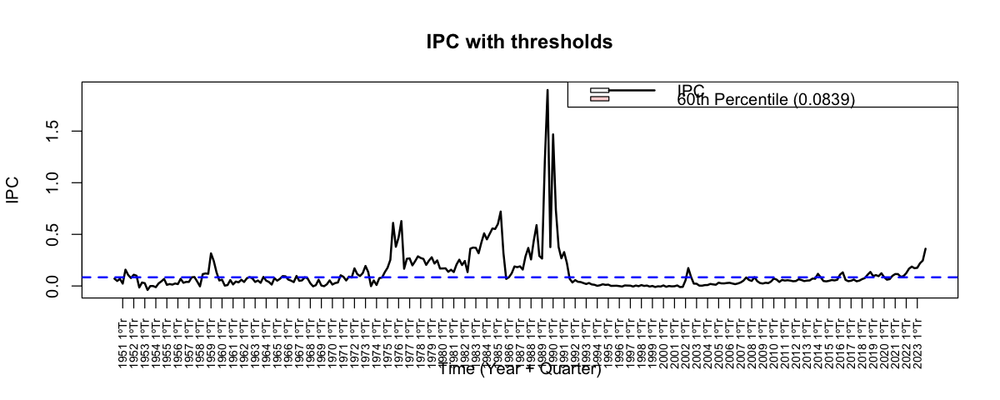

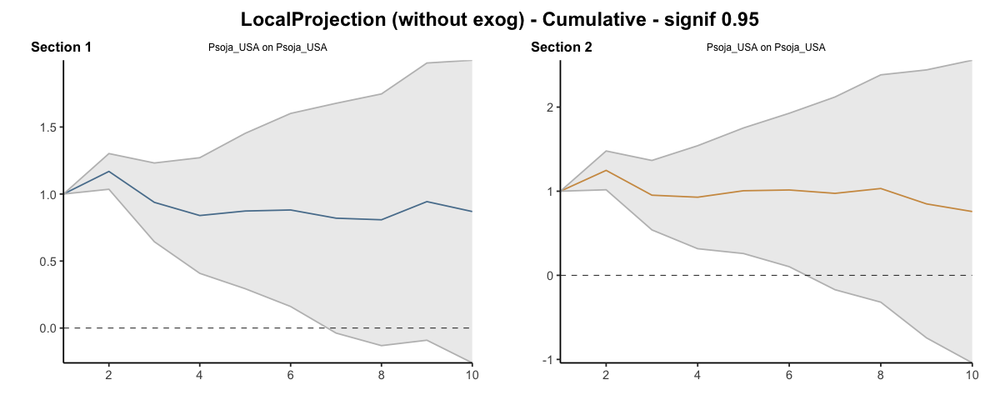

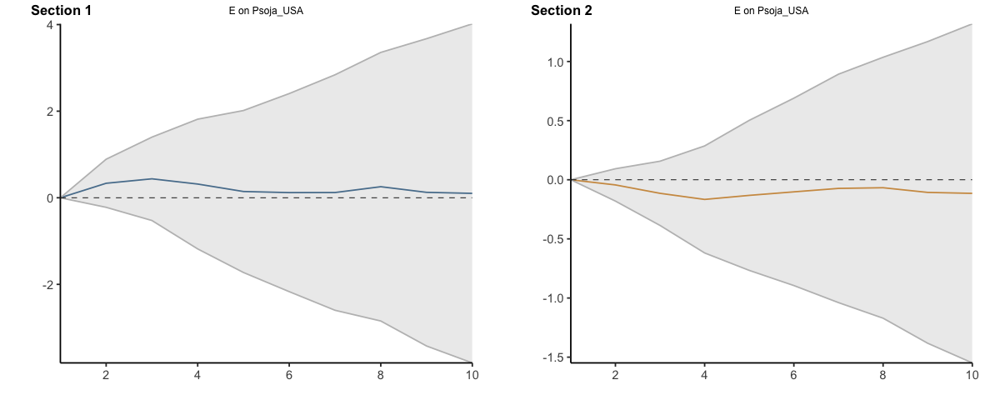

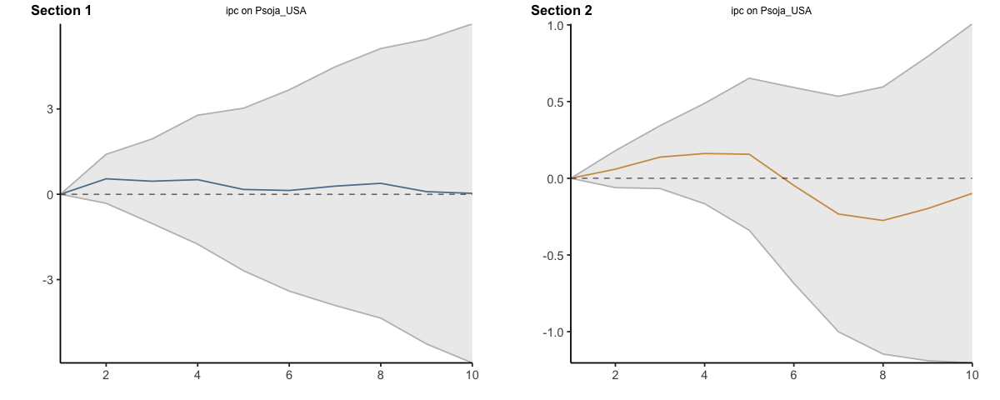

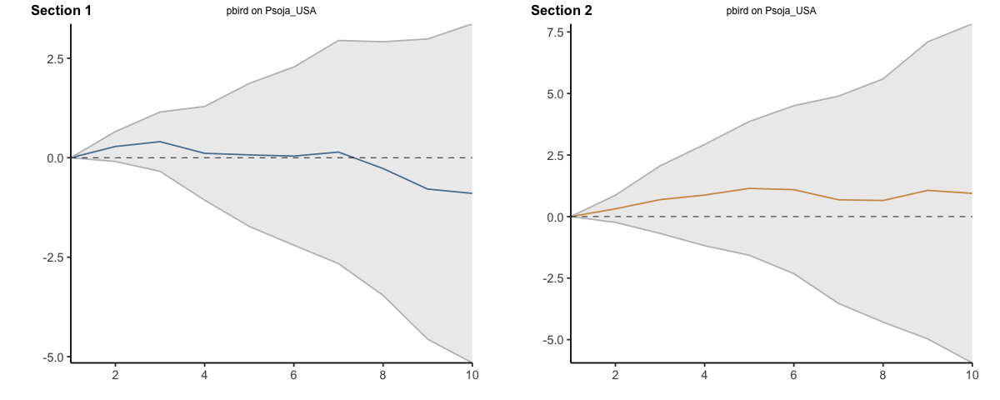

...

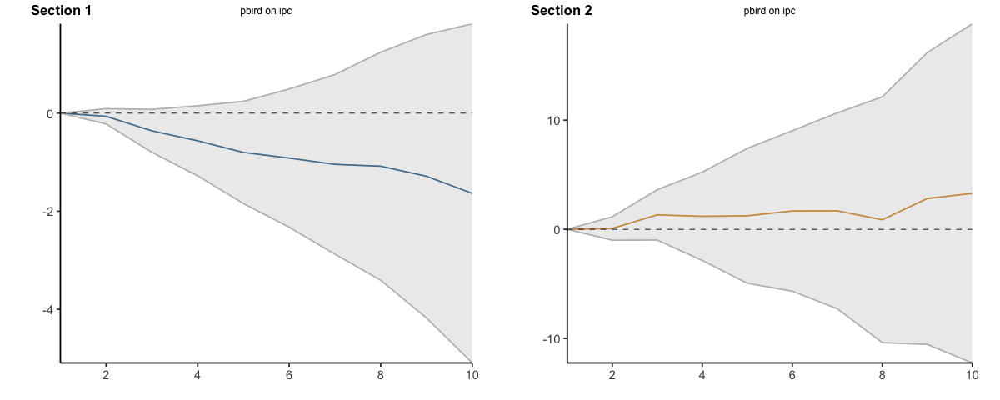

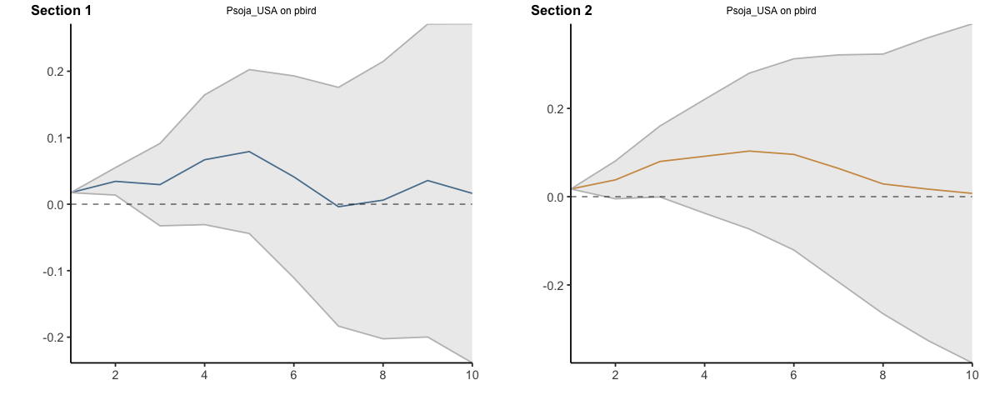

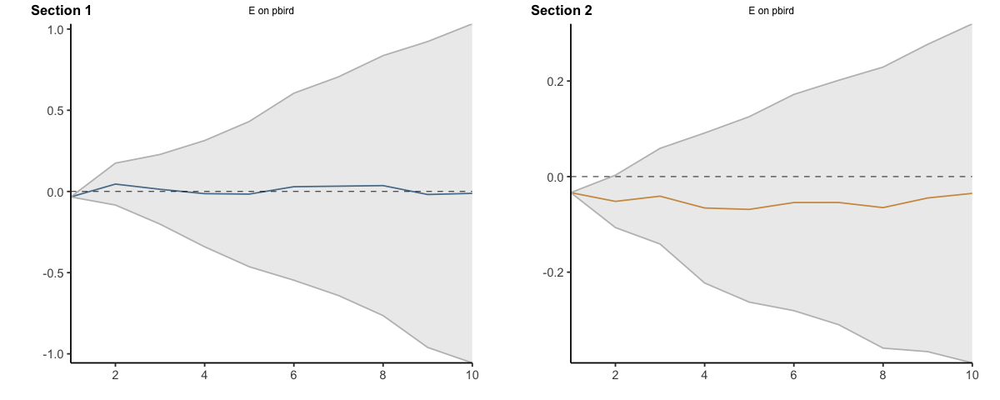

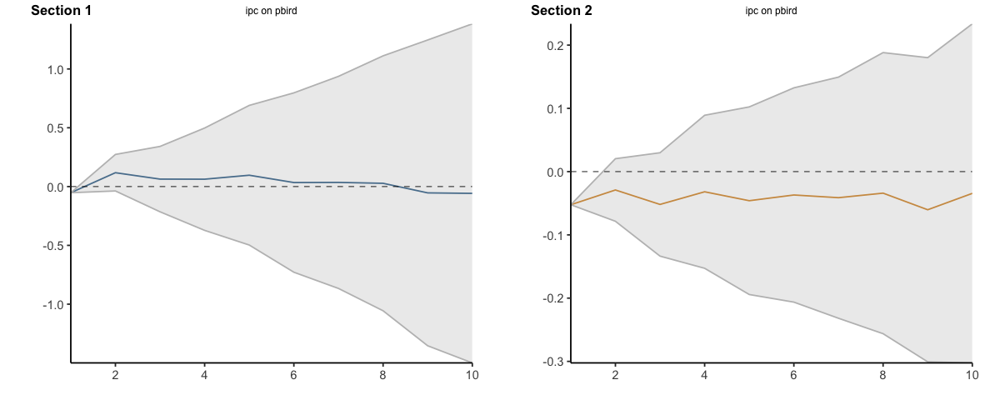

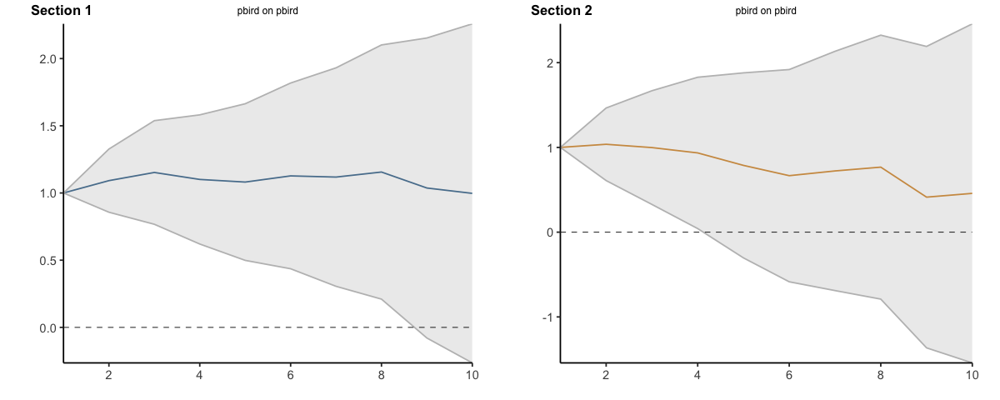

In [8]:
res <- run_lp_model(df_ERPT_Arg, endog=c("Psoja_USA", "E", "ipc", "pbird"), fixed_lags = 2, horizons=10, signif = 0.95, threshold_var = 'ipc', upper_threshold=0.6, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<dbl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,2,NaN,NA,NA,0,1,0.95,10,TRUE,TRUE,NA,FALSE,FALSE,0,1,295,"Psoja_USA, E, ipc, pbird",4


Impulse: Psoja_USA -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,1,-0.1946091,-0.1946091,-0.19460906,-0.19460906,-0.1946091,-0.19460906
2,2,-0.4030290,-0.5501023,-0.25595570,-0.38849947,-0.5426089,-0.23439007
3,3,-0.4536399,-0.7409116,-0.16636817,-0.58788048,-1.2701073,0.09434636
4,4,-0.4480023,-0.8507812,-0.04522343,-0.65691680,-1.6191852,0.30535165
5,5,-0.3263970,-0.8545727,0.20177879,-0.44262774,-2.0465653,1.16130978
6,6,-0.4387649,-1.2586351,0.38110535,-0.26652411,-2.4471234,1.91407521
7,7,-0.5919286,-1.6802087,0.49635143,-0.02808319,-2.6693233,2.61315689
8,8,-0.6237872,-2.1112051,0.86363078,0.41248026,-2.5350732,3.36003374
9,9,-0.6095572,-2.4109181,1.19180365,0.89323048,-2.5655076,4.35196855


Impulse: Psoja_USA -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
12,1,-0.028387373,-0.02838737,-0.02838737,-0.028387373,-0.02838737,-0.02838737
13,2,-0.002229777,-0.02055537,0.01609582,-0.041100532,-0.17116964,0.08896858
14,3,0.020975531,-0.03388903,0.07584009,-0.287654656,-0.62236943,0.04706012
15,4,0.033080450,-0.05401882,0.12017972,-0.386748886,-0.94806478,0.17456701
16,5,0.045377323,-0.08427049,0.17502514,-0.144466808,-1.13472559,0.84579198
17,6,0.035080963,-0.15485305,0.22501498,0.001310009,-1.47479039,1.47741041
18,7,0.025053598,-0.23867121,0.28877841,0.316629209,-1.51661614,2.14987455
19,8,-0.100654131,-0.54693081,0.34562255,0.686247007,-1.54447701,2.91697103
20,9,-0.162280999,-0.81043599,0.48587399,0.862717049,-1.70787331,3.43330740


... (16 outputs left out)

Impulse: pbird -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
111,1,0.0000000,0.000000,0.00000000,0.00000000,0.000000,0.000000
112,2,-0.7987768,-1.656900,0.05934670,-0.52162191,-1.625860,0.582616
113,3,-2.2209184,-4.483966,0.04212904,0.11647502,-1.733625,1.966575
114,4,-2.9662090,-6.262701,0.33028279,-0.14955543,-3.424939,3.125828
115,5,-3.5309195,-7.594185,0.53234644,-0.05487953,-4.840776,4.731017
116,6,-2.5977210,-7.871440,2.67599808,0.88506601,-5.061153,6.831285
117,7,-2.7441014,-8.939915,3.45171184,0.43925596,-6.929775,7.808286
118,8,-2.9738582,-10.675800,4.72808375,0.55800855,-7.650559,8.766576
119,9,-3.9902623,-12.670685,4.69016011,2.42007930,-7.831933,12.672091


Impulse: pbird -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
122,1,0.00000000,0.0000000,0.0000000,0.0000000,0.0000000,0.0000000
123,2,-0.04921724,-0.2956643,0.1972299,0.2205836,-0.3526189,0.7937861
124,3,-0.44345109,-0.9897227,0.1028205,0.9282214,-0.2868532,2.1432960
125,4,-0.71079974,-1.6134881,0.1918886,1.0435723,-1.1722650,3.2594097
126,5,-0.85863524,-2.1858974,0.4686269,1.2602788,-2.1299513,4.6505089
127,6,-0.86449167,-2.6596431,0.9306598,1.7511373,-2.3776703,5.8799449
128,7,-0.92703652,-3.2767146,1.4226416,1.9625989,-3.1111612,7.0363590
129,8,-0.89841110,-3.8834697,2.0866475,1.9194850,-4.2850545,8.1240245
130,9,-1.05023411,-4.8723007,2.7718324,3.3716923,-4.3727822,11.1161669


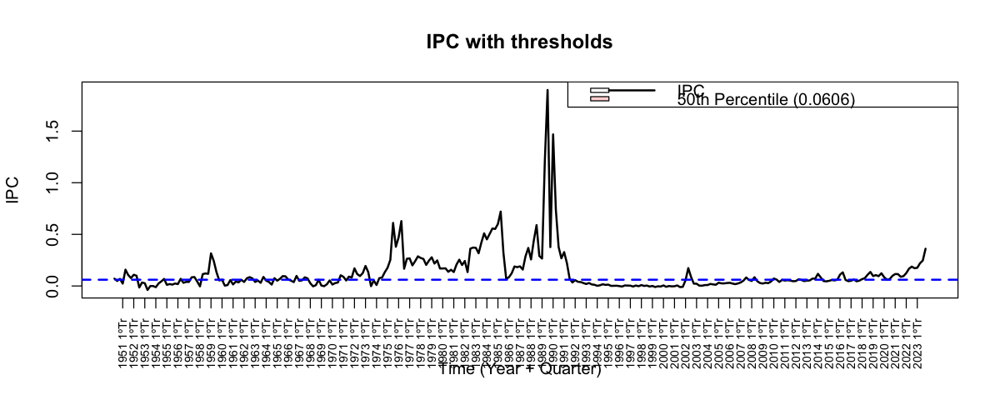

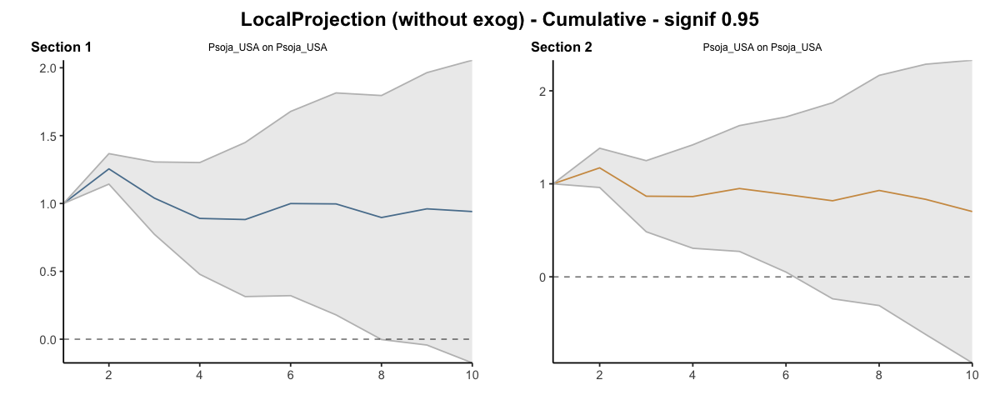

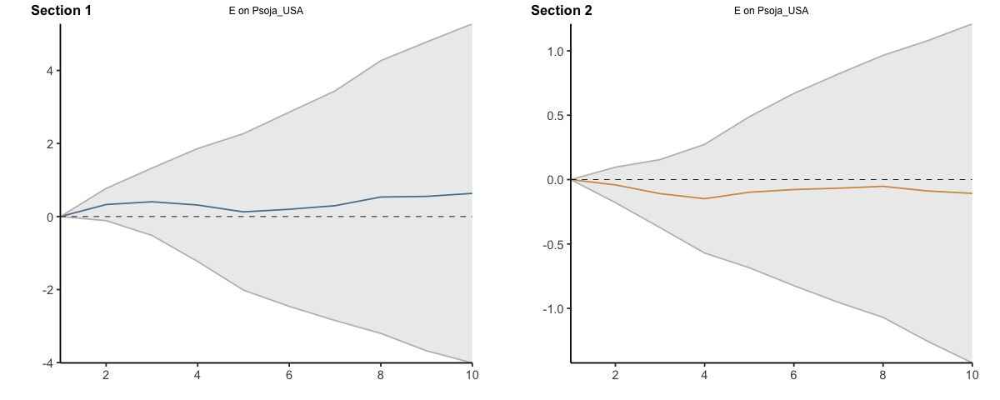

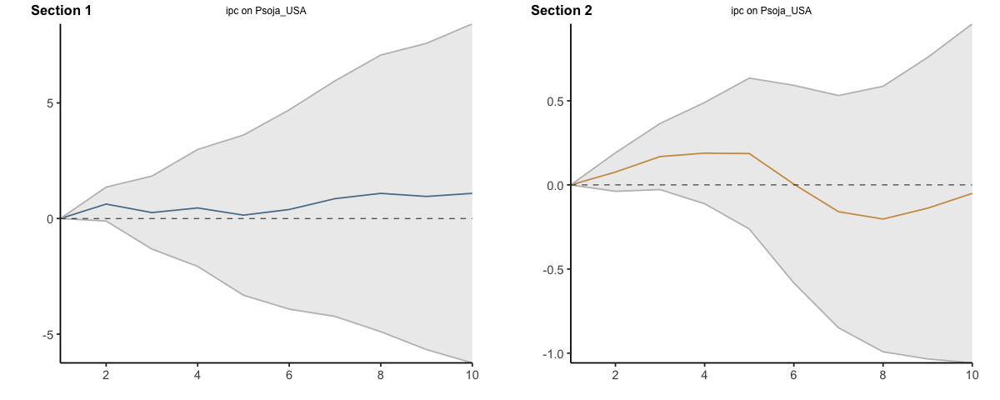

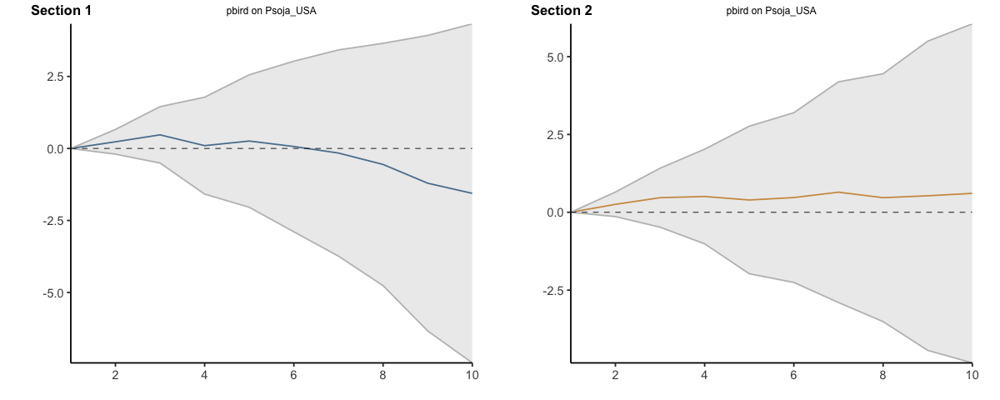

...

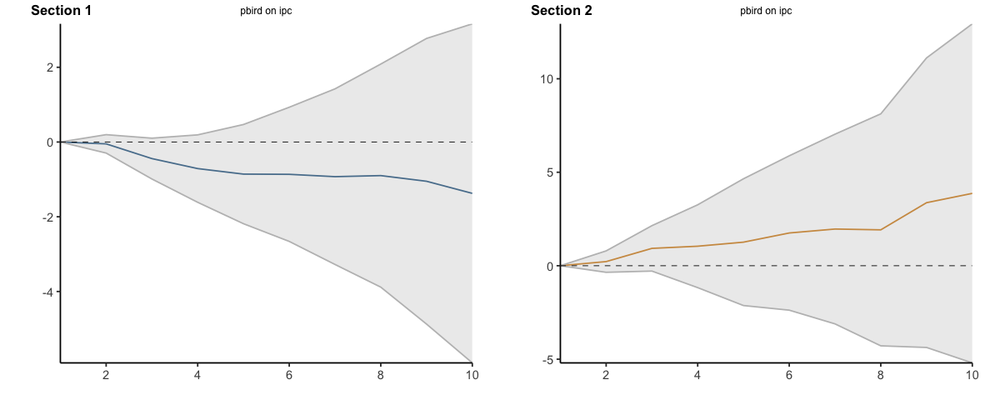

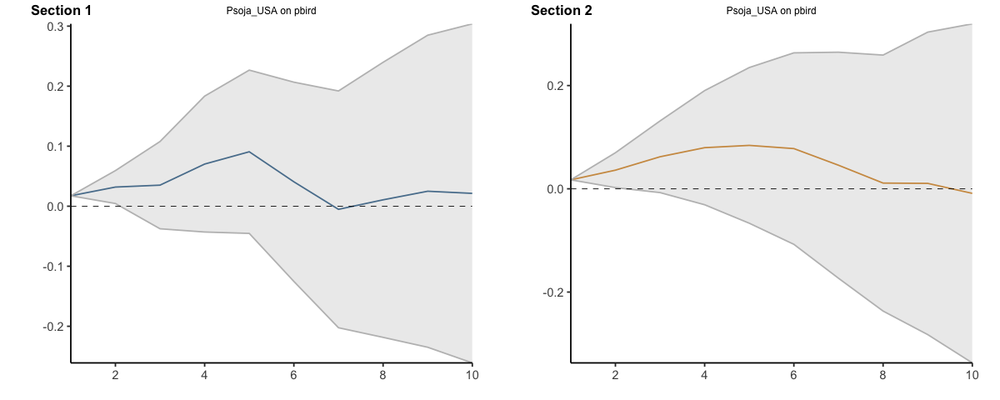

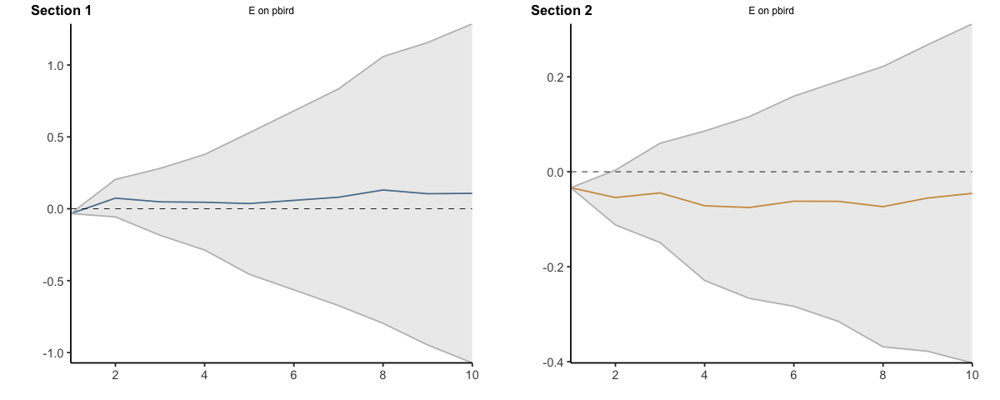

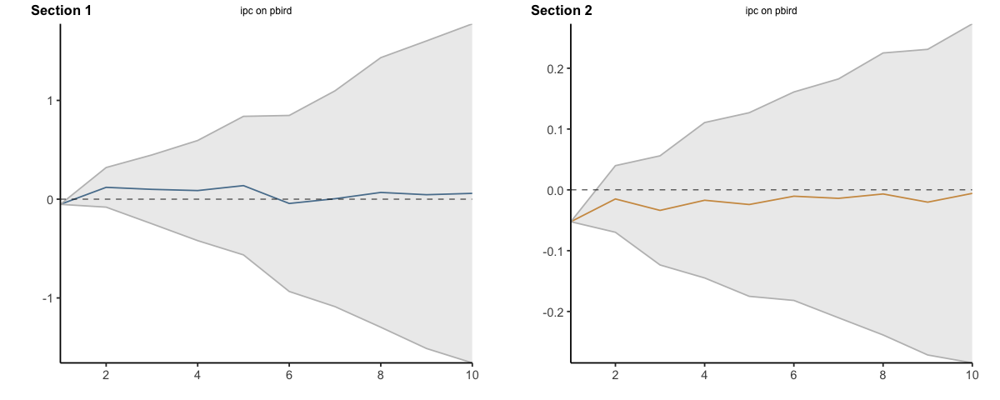

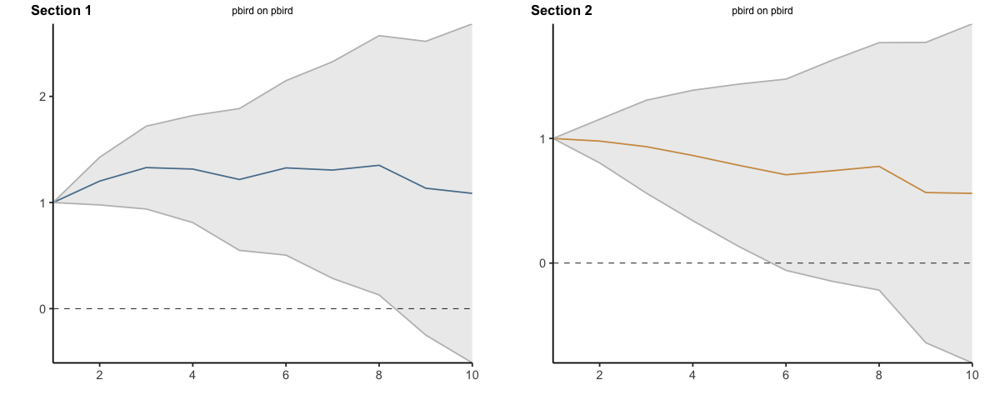

In [9]:
res <- run_lp_model(df_ERPT_Arg, endog=c("Psoja_USA", "E", "ipc", "pbird"), fixed_lags = 2, horizons=10, signif = 0.95, threshold_var = 'ipc', upper_threshold=0.5, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<dbl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,2,NaN,NA,NA,0,1,0.95,10,TRUE,TRUE,NA,FALSE,FALSE,0,1,295,"Psoja_USA, E, ipc, pbird",4


Impulse: Psoja_USA -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,1,-0.19460906,-0.1946091,-0.19460906,-0.1946091,-0.1946091,-0.1946091
2,2,-0.38194811,-0.5441151,-0.21978109,-0.3824023,-0.5303822,-0.2344224
3,3,-0.42104799,-0.7635723,-0.07852372,-0.5805799,-1.1903198,0.0291601
4,4,-0.41511368,-0.8807590,0.05053167,-0.6869479,-1.5447596,0.1708639
5,5,-0.35096549,-0.9437998,0.24186887,-0.4818816,-1.9056170,0.9418538
6,6,-0.33020511,-1.1441985,0.48378827,-0.4486096,-2.4590734,1.5618541
7,7,-0.38646149,-1.3487339,0.57581095,-0.2998684,-2.7919277,2.1921910
8,8,-0.22347061,-1.4046274,0.95768621,-0.0204891,-2.8039544,2.7629762
9,9,-0.09020261,-1.4007957,1.22039052,0.3423665,-2.8903884,3.5751214


Impulse: Psoja_USA -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
12,1,-0.028387373,-0.02838737,-0.02838737,-0.02838737,-0.02838737,-0.02838737
13,2,0.008564871,-0.02051847,0.03764821,-0.03875647,-0.15072018,0.07320724
14,3,0.040922206,-0.02876624,0.11061066,-0.26943334,-0.54890245,0.01003578
15,4,0.068835403,-0.03497284,0.17264365,-0.39815954,-0.89021558,0.09389650
16,5,0.099571400,-0.05335382,0.25249662,-0.20658809,-1.06295065,0.64977447
17,6,0.107866908,-0.10820021,0.32393403,-0.11319267,-1.40990850,1.18352316
18,7,0.127216502,-0.19052967,0.44496268,0.12448723,-1.49417638,1.74315084
19,8,0.117146300,-0.28750074,0.52179333,0.37441836,-1.65980873,2.40864546
20,9,0.152047989,-0.34668332,0.65077930,0.47149379,-1.89906131,2.84204890


... (16 outputs left out)

Impulse: pbird -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
111,1,0.0000000,0.000000,0.0000000,0.00000000,0.000000,0.0000000
112,2,-0.6650413,-1.582434,0.2523518,-0.63546751,-1.683450,0.4125149
113,3,-1.7966863,-4.147732,0.5543596,-0.35159630,-2.080326,1.3771332
114,4,-2.5224760,-6.119219,1.0742675,-0.64376095,-3.700928,2.4134060
115,5,-3.0046481,-7.385158,1.3758616,-0.75101549,-5.147438,3.6454072
116,6,-2.3245003,-7.994689,3.3456888,0.19198530,-5.247402,5.6313725
117,7,-2.7599342,-9.468201,3.9483328,-0.06482907,-6.787256,6.6575974
118,8,-3.2801221,-11.563372,5.0031283,0.14473133,-7.334891,7.6243539
119,9,-4.5001742,-13.873827,4.8734787,1.71926886,-7.390645,10.8291827


Impulse: pbird -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
122,1,0.00000000,0.0000000,0.0000000,0.0000000,0.0000000,0.0000000
123,2,0.09454746,-0.1230737,0.3121686,0.2152986,-0.2707423,0.7013395
124,3,-0.21769358,-0.7926678,0.3572807,0.6937814,-0.2761230,1.6636858
125,4,-0.44815757,-1.3873793,0.4910642,0.7793691,-1.1191353,2.6778735
126,5,-0.63205236,-2.0260452,0.7619405,0.9512095,-1.9764616,3.8788805
127,6,-0.61239555,-2.4698985,1.2451074,1.3147175,-2.2938220,4.9232570
128,7,-0.78267707,-3.1863574,1.6210032,1.4825775,-2.9568425,5.9219976
129,8,-1.04072267,-4.0564346,1.9749893,1.5847717,-3.8802190,7.0497625
130,9,-1.25500568,-5.1644534,2.6544420,2.8166786,-3.9014052,9.5347624


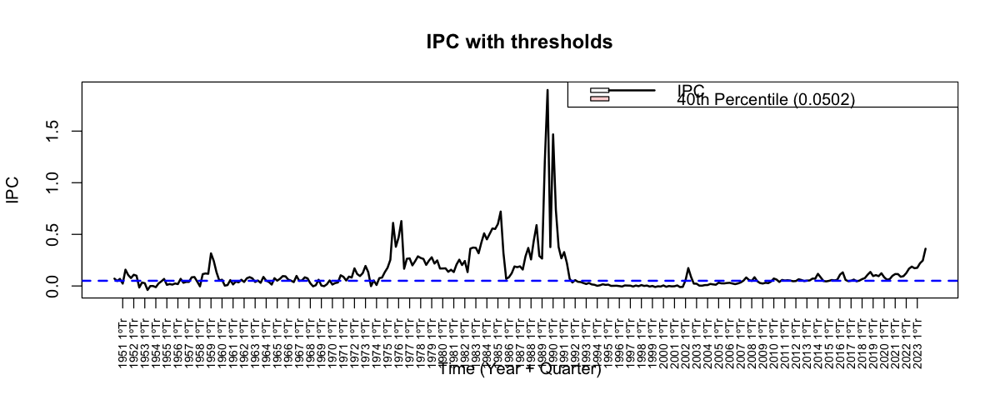

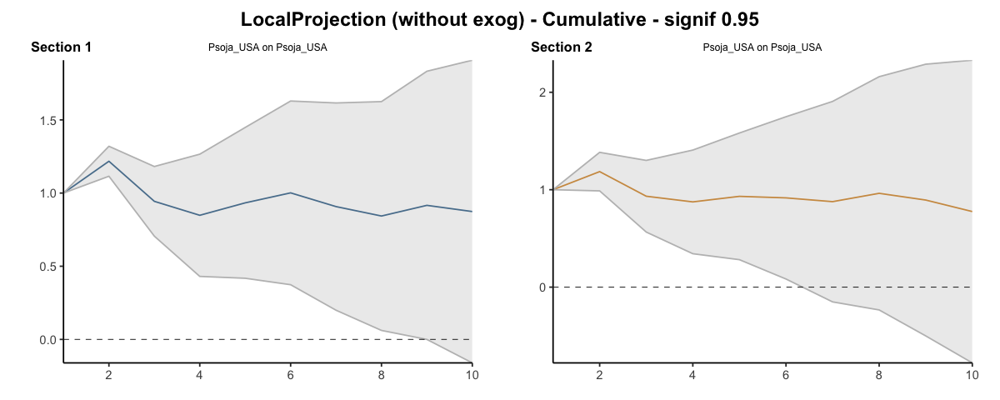

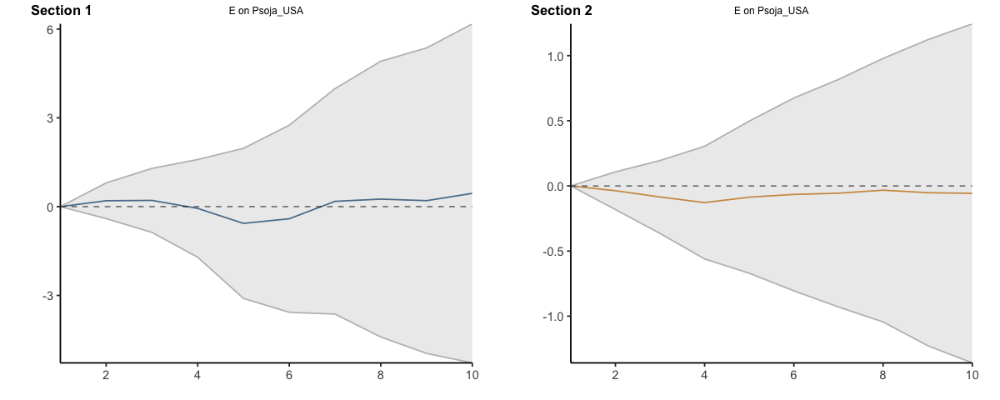

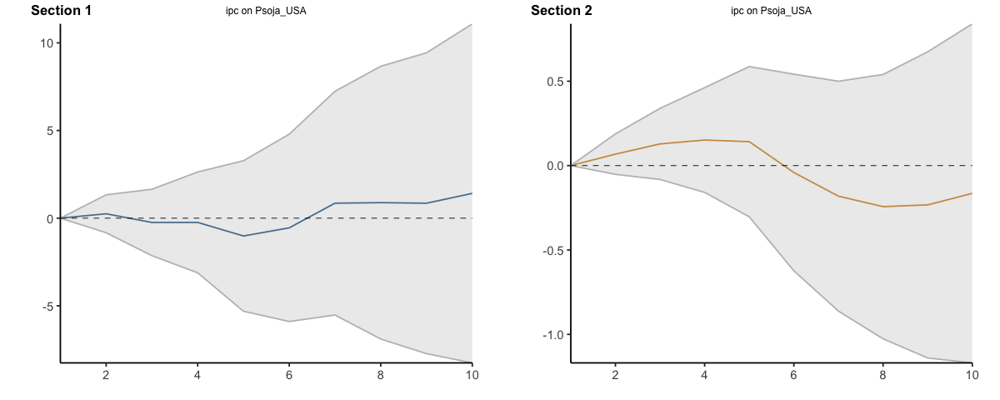

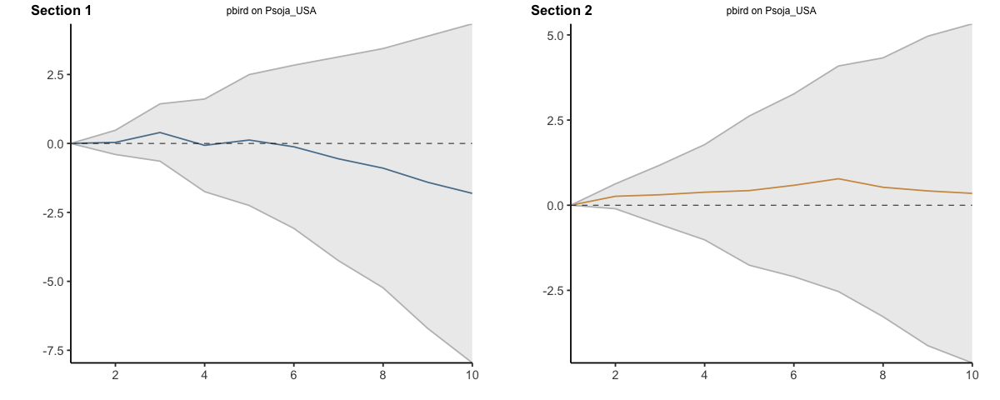

...

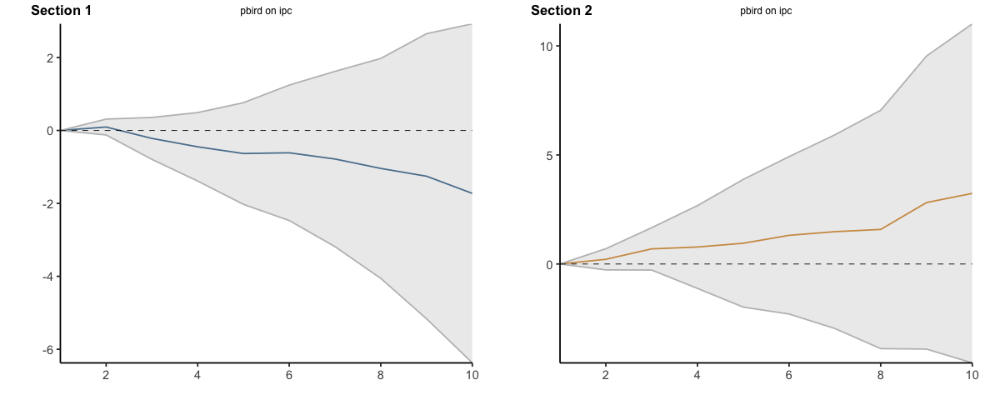

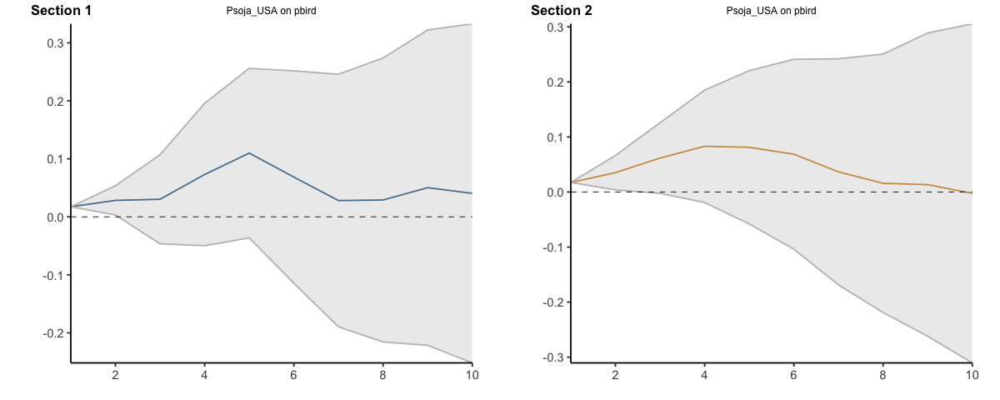

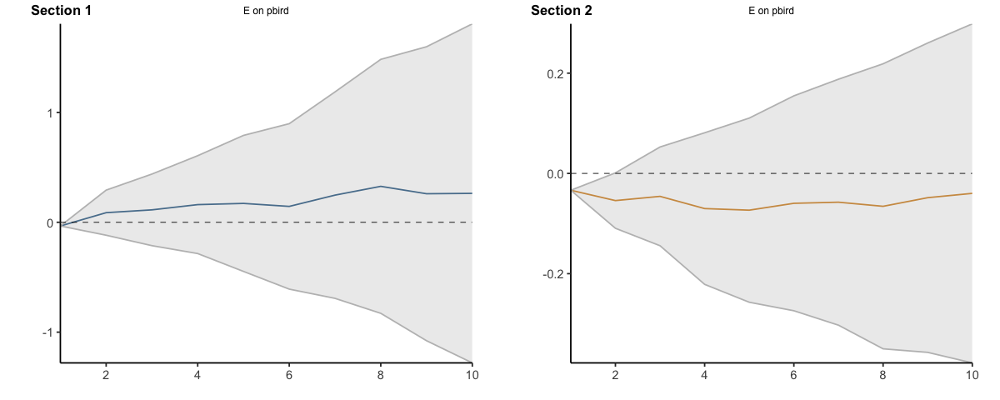

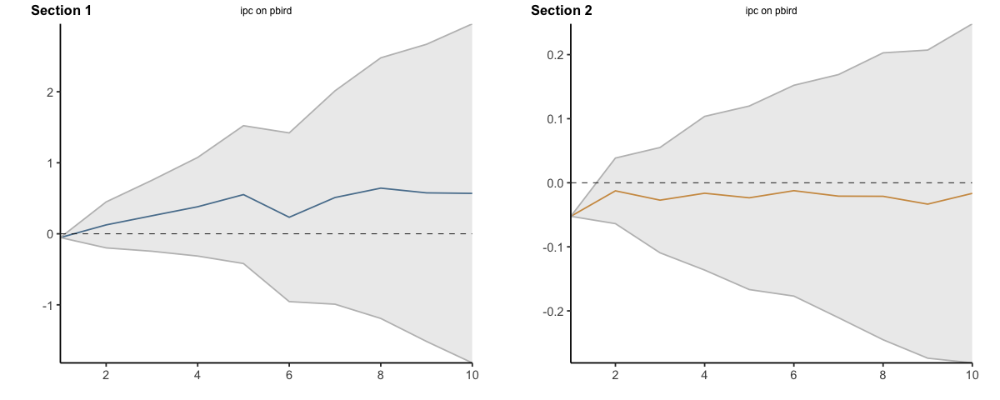

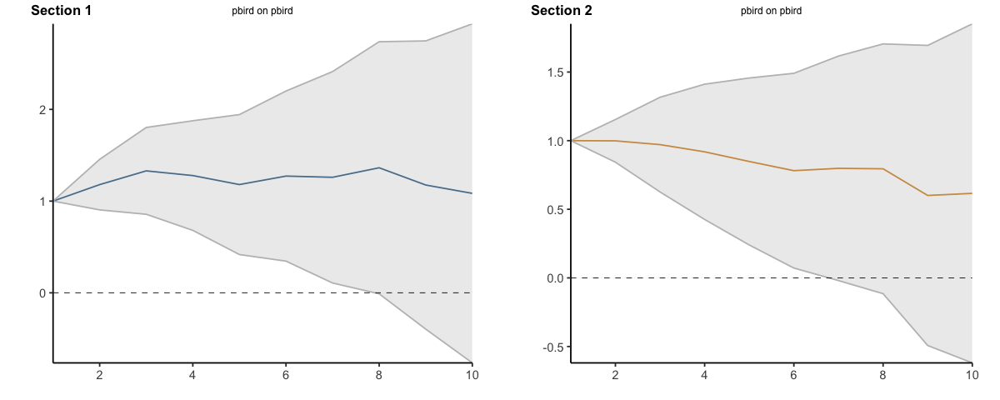

In [10]:
res <- run_lp_model(df_ERPT_Arg, endog=c("Psoja_USA", "E", "ipc", "pbird"), fixed_lags = 2, horizons=10, signif = 0.95, threshold_var = 'ipc', upper_threshold=0.4, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<dbl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
3,3,NaN,NA,NA,0,1,0.95,10,TRUE,TRUE,NA,FALSE,FALSE,0,1,295,"Psoja_USA, E, ipc, pbird",4


Impulse: Psoja_USA -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,1,-0.2031619,-0.2031619,-0.20316193,-0.2031619,-0.2031619,-0.203161932
2,2,-0.5054087,-0.6000980,-0.41071937,-0.3225011,-0.6435403,-0.001461912
3,3,-0.5169573,-0.8310243,-0.20289029,-0.5948227,-1.4777461,0.288100639
4,4,-0.6357022,-1.0779623,-0.19344211,-0.2863767,-1.8176150,1.244861582
5,5,-0.6623650,-1.2800057,-0.04472440,0.7964255,-2.1486494,3.741500352
6,6,-0.7517063,-1.5453430,0.04193045,1.8827092,-2.3077647,6.073183173
7,7,-0.8437578,-1.8360337,0.14851800,2.9816156,-2.2814839,8.244715104
8,8,-0.6572751,-1.8474765,0.53292636,3.7103096,-2.3647346,9.785353746
9,9,-0.5048788,-1.9053024,0.89554467,4.5260087,-2.3643024,11.416319765


Impulse: Psoja_USA -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
12,1,-0.02370532,-0.02370532,-0.023705316,-0.023705316,-0.02370532,-0.02370532
13,2,-0.05032992,-0.09734897,-0.003310877,-0.008002339,-0.31046435,0.29445967
14,3,-0.12862814,-0.20877831,-0.048477962,-0.098201525,-0.65463152,0.45822847
15,4,-0.17904624,-0.31605415,-0.042038333,0.067119397,-0.81372713,0.94796592
16,5,-0.14667116,-0.39052963,0.097187310,0.936065020,-1.01286000,2.88499004
17,6,-0.25338931,-0.56339734,0.056618713,1.862994974,-1.10686860,4.83285854
18,7,-0.22833198,-0.61975307,0.163089107,2.883942318,-0.99719376,6.76507839
19,8,-0.21162872,-0.71913789,0.295880449,3.835009376,-0.90255681,8.57257557
20,9,-0.25784649,-0.88734972,0.371656739,4.365219973,-1.25242814,9.98286809


... (16 outputs left out)

Impulse: pbird -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
111,1,0.0000000,0.000000,0.0000000,0.0000000,0.000000,0.000000
112,2,-0.8382338,-1.645845,-0.0306231,-0.7662315,-3.399384,1.866921
113,3,-1.5912654,-3.286638,0.1041077,-0.1555492,-5.654143,5.343045
114,4,-1.9392802,-4.343648,0.4650876,-3.6413570,-14.123221,6.840507
115,5,-2.1788575,-5.179824,0.8221086,-6.0834630,-22.201517,10.034591
116,6,-1.5866259,-5.337370,2.1641185,-6.8435729,-26.552055,12.864909
117,7,-1.6532694,-6.136185,2.8296462,-11.0442728,-35.366484,13.277939
118,8,-1.9518543,-7.251983,3.3482742,-12.5856999,-39.408163,14.236763
119,9,-1.8924866,-8.068920,4.2839468,-9.9179410,-39.360099,19.524217


Impulse: pbird -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
122,1,0.000000000,0.0000000,0.0000000,0.0000000,0.000000,0.000000
123,2,0.024868309,-0.1639373,0.2136739,-0.3295540,-2.435012,1.775904
124,3,-0.083905247,-0.5630532,0.3952427,0.7449447,-3.212415,4.702304
125,4,-0.142819188,-0.9225259,0.6368875,-1.3152625,-8.542950,5.912425
126,5,-0.239626683,-1.3288361,0.8495827,-2.9564630,-15.249070,9.336144
127,6,-0.153140519,-1.6087042,1.3024231,-4.1995459,-19.488099,11.089008
128,7,-0.158832663,-2.0101761,1.6925108,-6.5842108,-24.875495,11.707073
129,8,-0.178762151,-2.4755941,2.1180698,-9.3653567,-31.748934,13.018221
130,9,-0.001353373,-2.8354046,2.8326979,-6.8953949,-31.899963,18.109174


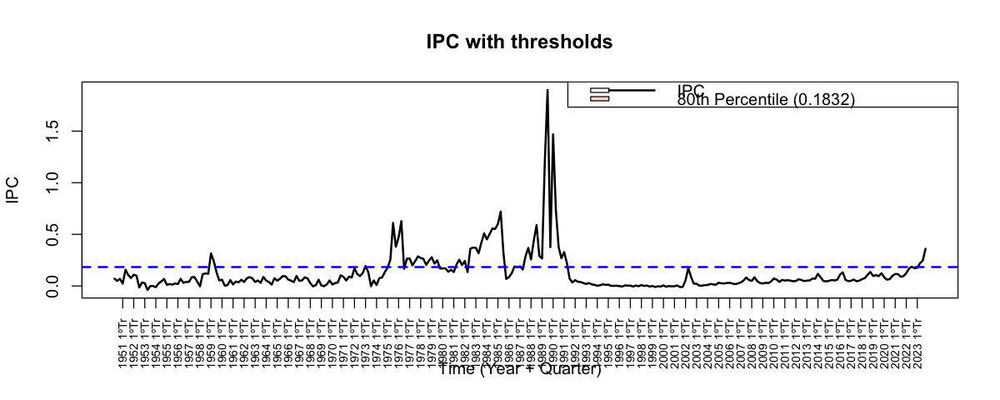

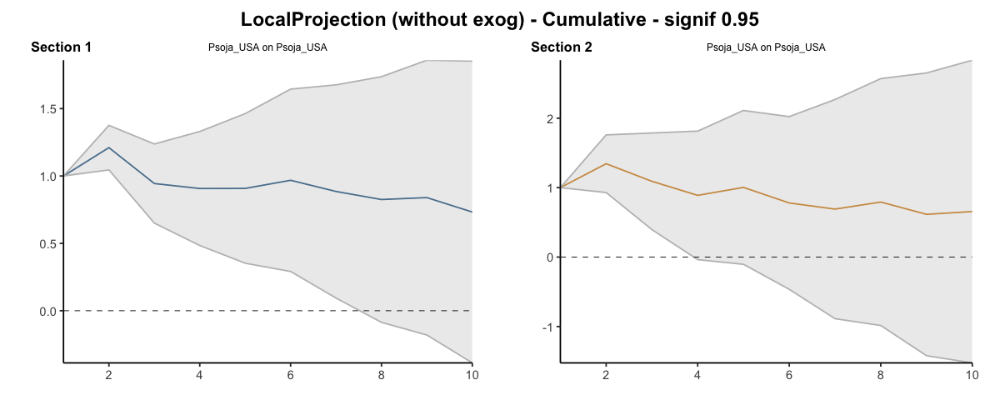

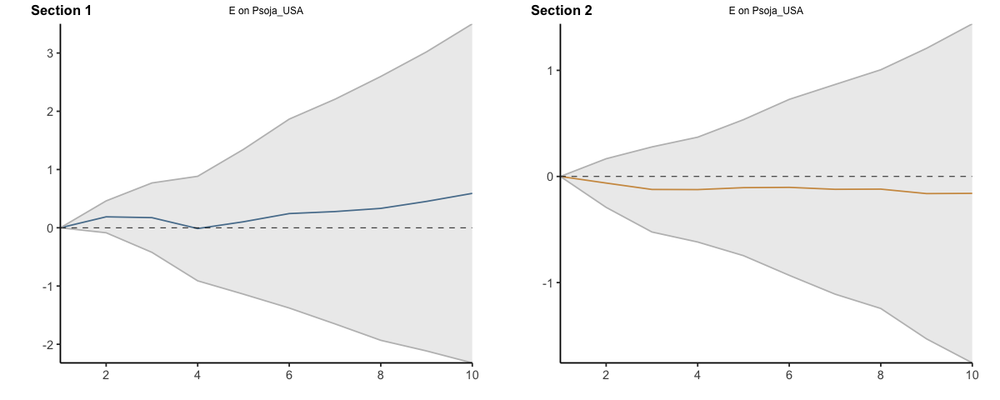

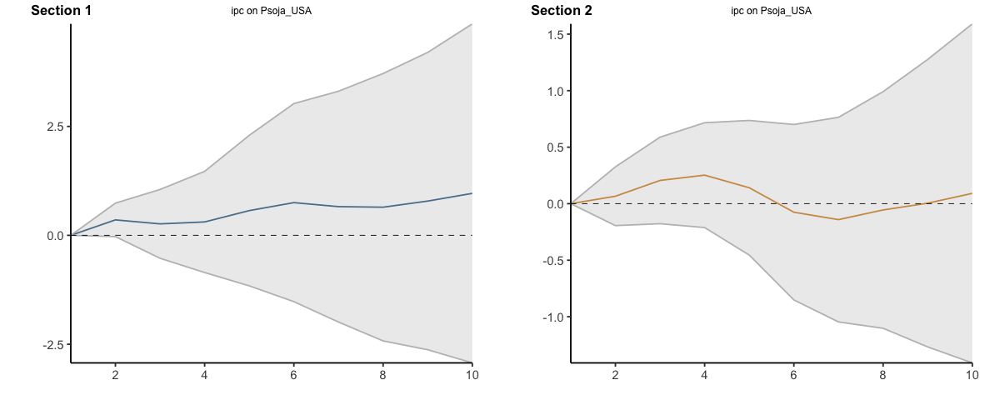

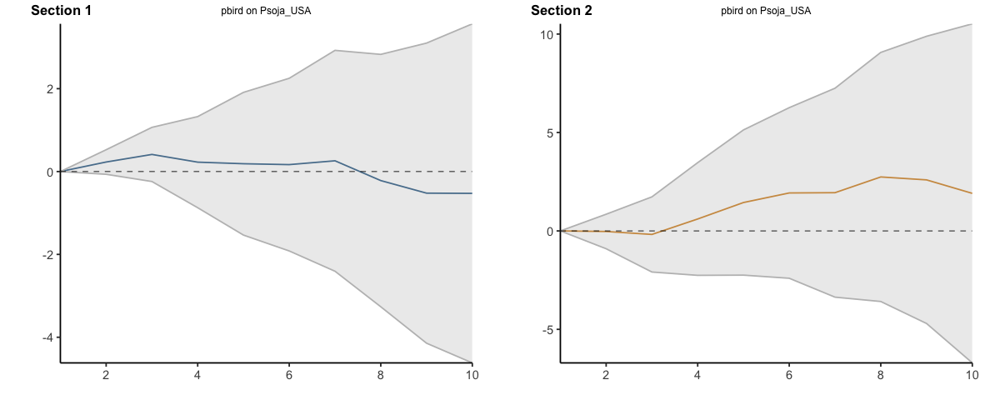

...

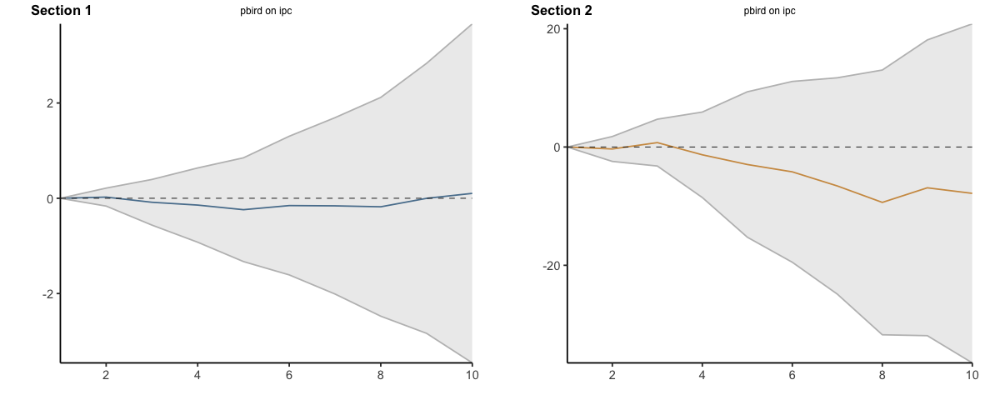

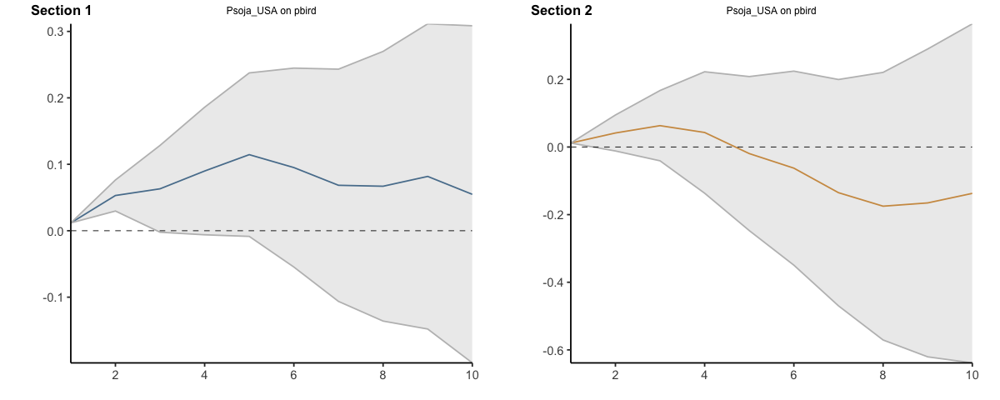

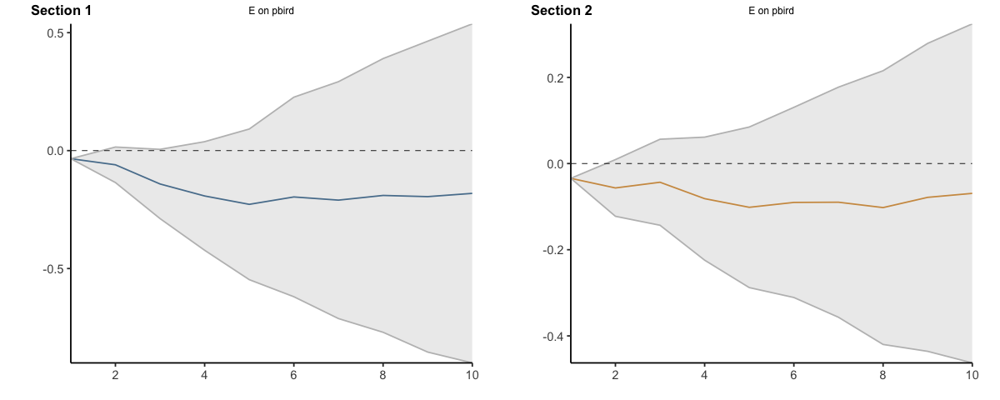

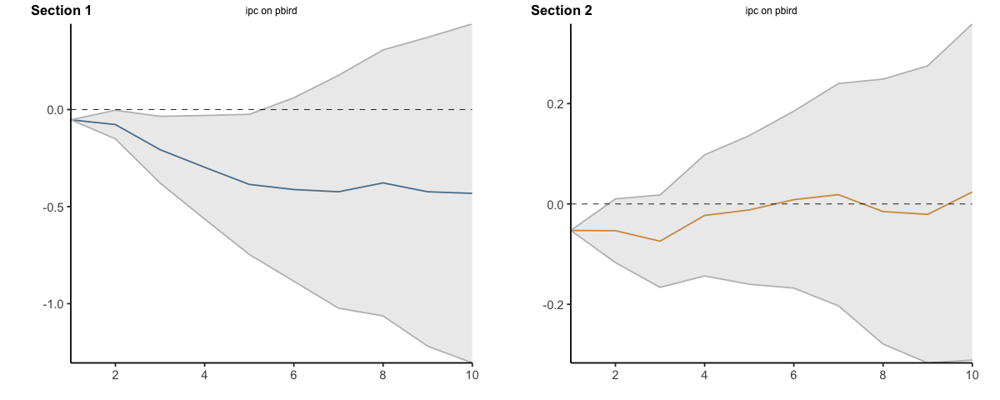

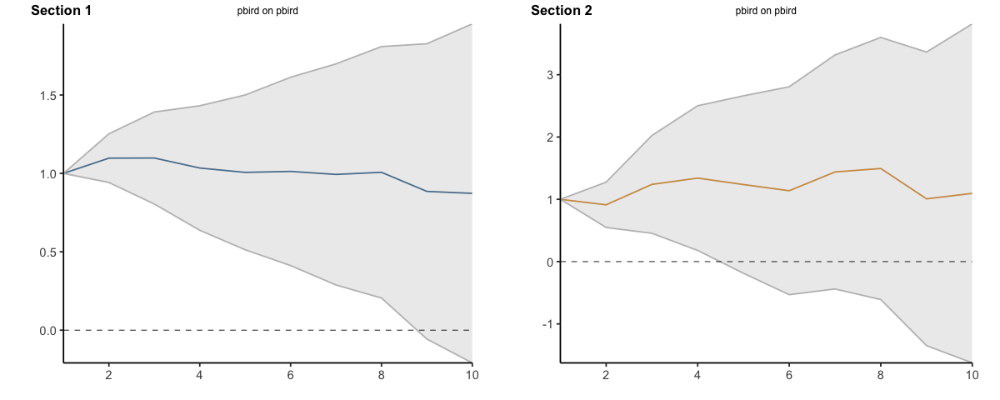

In [11]:
res <- run_lp_model(df_ERPT_Arg, endog=c("Psoja_USA", "E", "ipc", "pbird"), fixed_lags = 3, horizons=10, signif = 0.95, threshold_var = 'ipc', upper_threshold=0.8, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<dbl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
3,3,NaN,NA,NA,0,1,0.95,10,TRUE,TRUE,NA,FALSE,FALSE,0,1,295,"Psoja_USA, E, ipc, pbird",4


Impulse: Psoja_USA -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,1,-0.203161932,-0.2031619,-0.2031619,-0.2031619,-0.2031619,-0.20316193
2,2,-0.421877077,-0.5199427,-0.3238115,-0.2373330,-0.5372104,0.06254444
3,3,-0.278783566,-0.7124163,0.1548491,-0.5282303,-1.2276471,0.17118644
4,4,-0.294421334,-0.8406422,0.2517995,-0.4043345,-1.7153889,0.90671980
5,5,-0.204483949,-0.9387665,0.5297986,0.1932552,-2.2439426,2.63045297
6,6,-0.227720027,-1.1379638,0.6825237,0.7543403,-2.6792204,4.18790093
7,7,-0.256857958,-1.3395017,0.8257858,1.4146489,-3.0118684,5.84116608
8,8,-0.105863224,-1.3848192,1.1730928,2.1485398,-2.8260580,7.12313770
9,9,-0.020529999,-1.4964881,1.4554282,2.9552662,-2.7489351,8.65946737


Impulse: Psoja_USA -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
12,1,-0.0237053165,-0.02370532,-0.02370532,-0.02370532,-0.02370532,-0.02370532
13,2,0.0006910667,-0.03085159,0.03223373,0.04848698,-0.15868904,0.25566299
14,3,0.0355715561,-0.04336485,0.11450797,-0.11091933,-0.50992383,0.28808518
15,4,0.0900451814,-0.04973469,0.22982505,-0.08242744,-0.84093432,0.67607943
16,5,0.2280505334,-0.07425446,0.53035552,0.44000273,-1.18432619,2.06433166
17,6,0.2322149502,-0.14357010,0.60800000,0.93593993,-1.47896545,3.35084530
18,7,0.3204273876,-0.16121530,0.80207008,1.54413151,-1.62689813,4.71516116
19,8,0.4072593245,-0.19715039,1.01166904,2.21184747,-1.68957598,6.11327092
20,9,0.3762992855,-0.38852497,1.14112354,2.62962740,-1.87826483,7.13751963


... (16 outputs left out)

Impulse: pbird -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
111,1,0.0000000,0.000000,0.00000000,0.0000000,0.000000,0.000000
112,2,-0.7128816,-1.349397,-0.07636620,-0.9855123,-3.492883,1.521859
113,3,-1.7106664,-3.313059,-0.10827333,0.2909120,-3.902819,4.484643
114,4,-2.2242053,-4.517940,0.06952986,-1.0871687,-8.518434,6.344096
115,5,-2.4301050,-5.286932,0.42672158,-2.0847691,-12.943490,8.773952
116,6,-1.8938164,-5.668934,1.88130088,-1.9676748,-15.139793,11.204443
117,7,-1.9127614,-6.255919,2.43039605,-5.2857790,-21.830592,11.259034
118,8,-2.1563361,-7.423147,3.11047463,-6.2099937,-24.382577,11.962590
119,9,-2.7636148,-8.814951,3.28772138,-2.9790483,-25.737341,19.779244


Impulse: pbird -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
122,1,0.00000000,0.0000000,0.0000000,0.0000000,0.000000,0.000000
123,2,-0.01608947,-0.1668186,0.1346397,0.3830337,-0.901939,1.668006
124,3,-0.25069142,-0.6887647,0.1873818,1.5527863,-1.159318,4.264891
125,4,-0.44937781,-1.1574171,0.2586614,1.0831705,-3.832872,5.999213
126,5,-0.61018644,-1.6114409,0.3910681,0.6830570,-7.399191,8.765305
127,6,-0.69171193,-2.0420432,0.6586194,0.6599312,-9.366493,10.686355
128,7,-0.72926901,-2.4287259,0.9701879,-0.9618085,-13.322615,11.398998
129,8,-0.68639167,-2.7719120,1.3991287,-2.6921544,-17.178888,11.794579
130,9,-0.74799149,-3.3578761,1.8618931,-0.7181079,-18.467130,17.030914


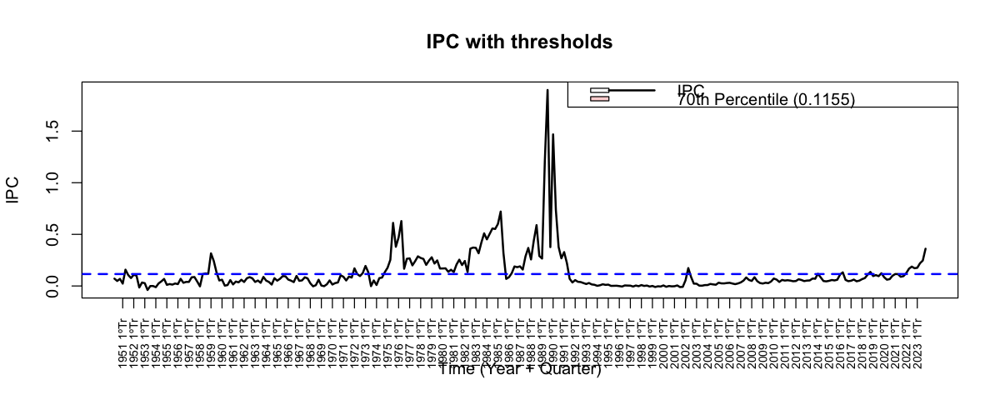

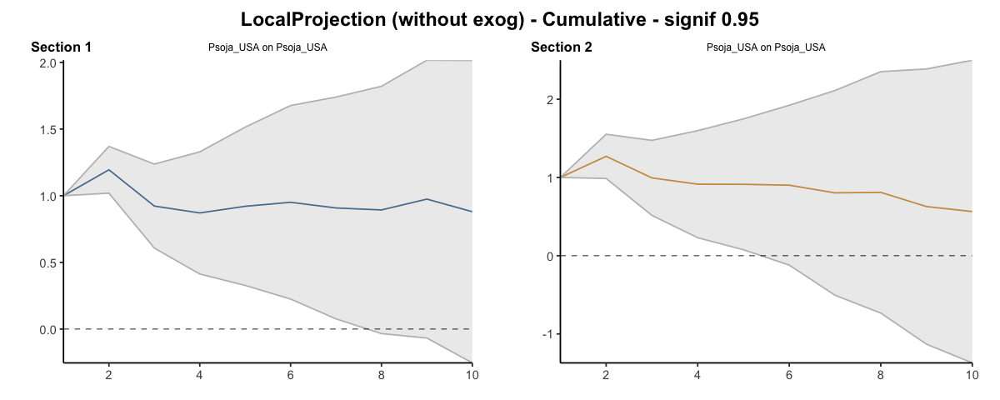

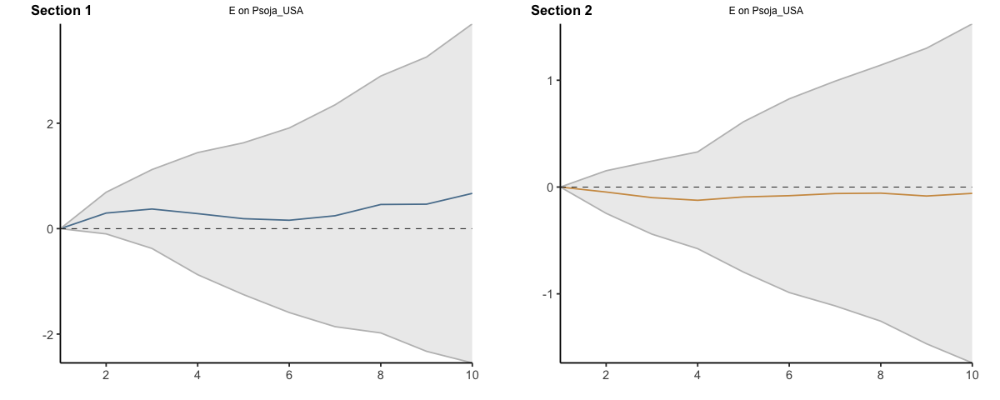

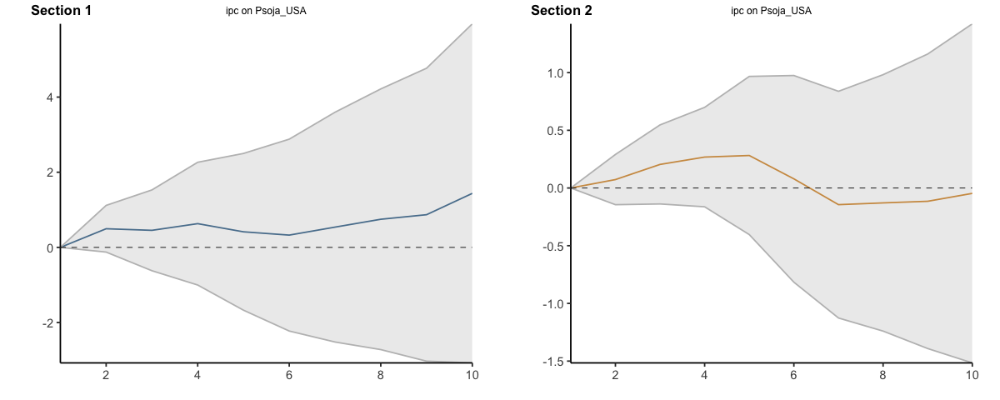

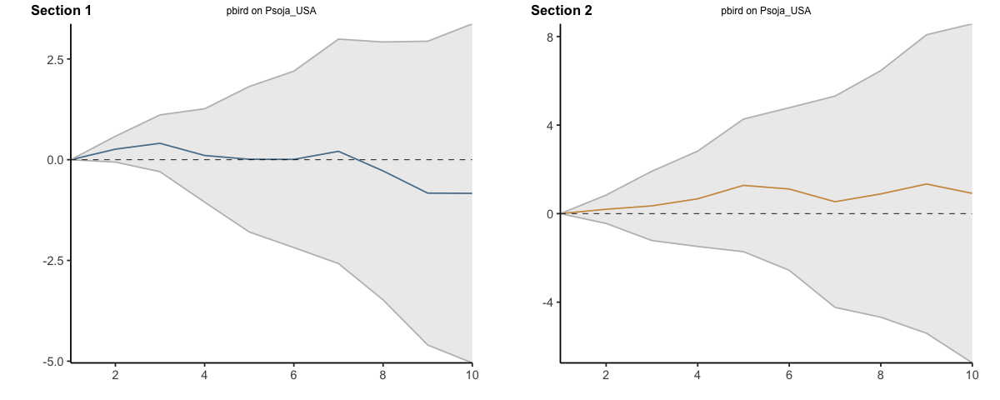

...

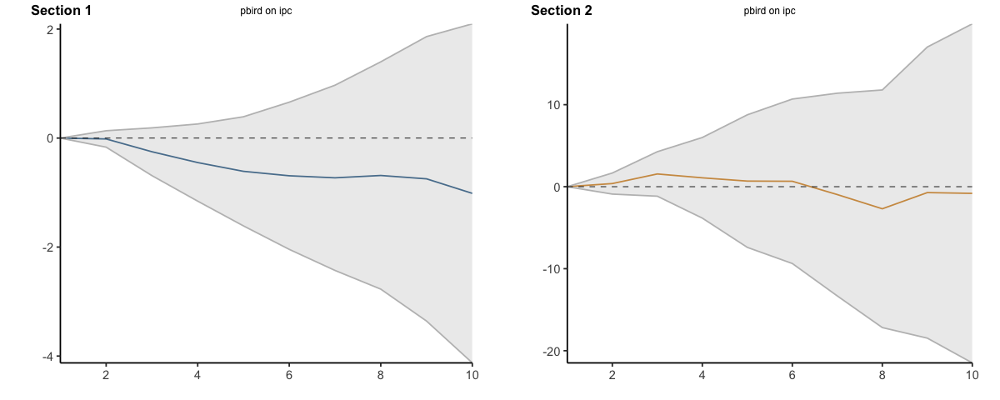

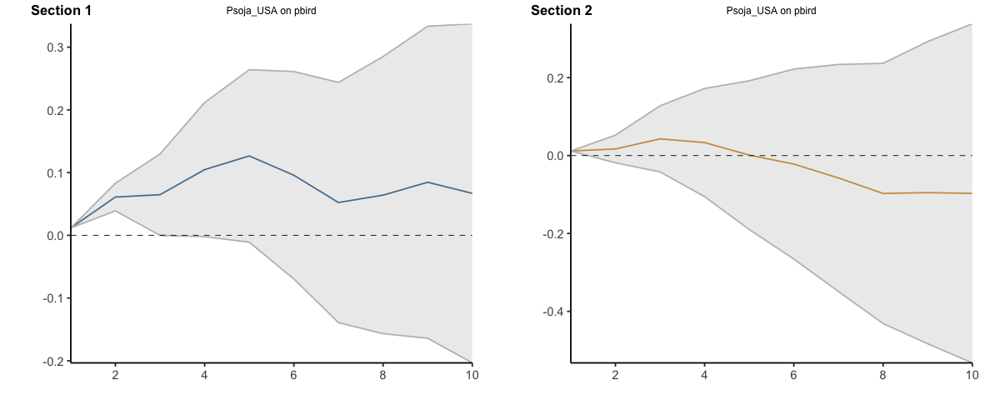

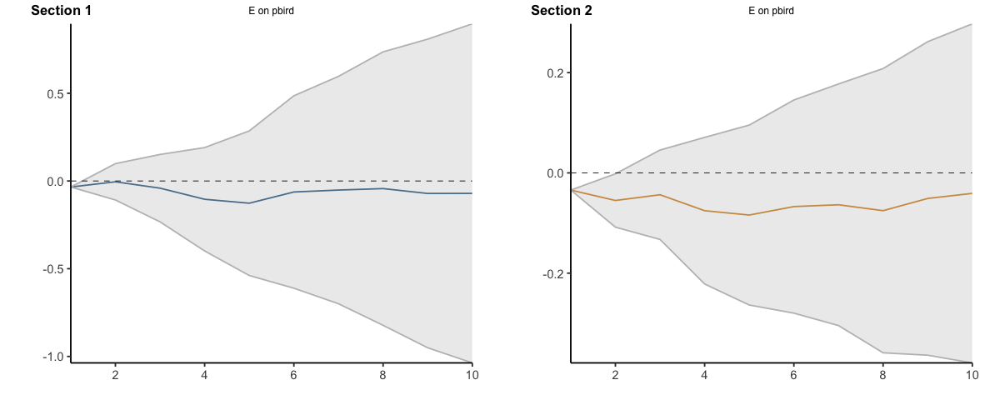

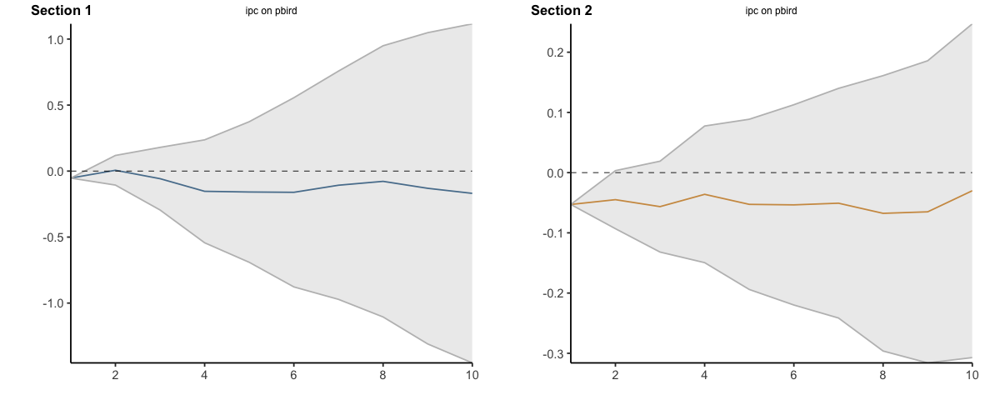

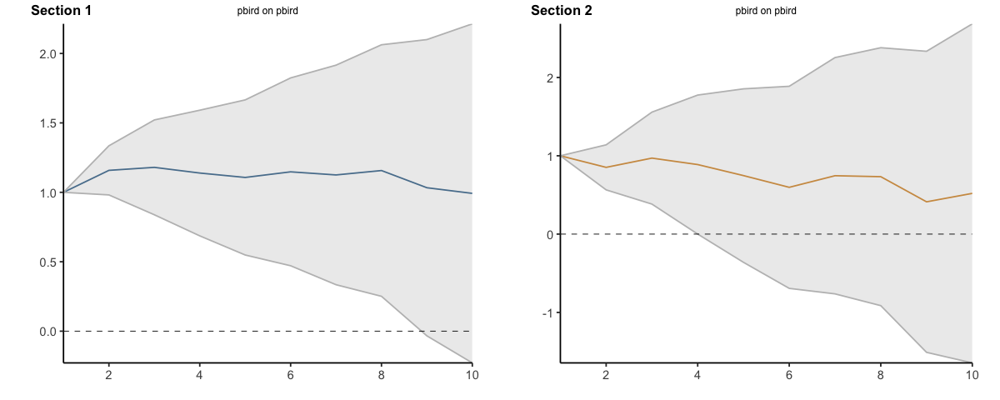

In [12]:
res <- run_lp_model(df_ERPT_Arg, endog=c("Psoja_USA", "E", "ipc", "pbird"), fixed_lags = 3, horizons=10, signif = 0.95, threshold_var = 'ipc', upper_threshold=0.7, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<dbl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
3,3,NaN,NA,NA,0,1,0.68,10,TRUE,TRUE,NA,FALSE,FALSE,0,1,295,"Psoja_USA, E, ipc, pbird",4


Impulse: Psoja_USA -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,1,-0.203161932,-0.2031619,-0.20316193,-0.2031619,-0.2031619,-0.2031619
2,2,-0.443921757,-0.5014092,-0.38643429,-0.3307426,-0.4637939,-0.1976914
3,3,-0.298615176,-0.5341080,-0.06312232,-0.6341037,-0.9094291,-0.3587782
4,4,-0.330189618,-0.6195406,-0.04083867,-0.5923189,-1.0850926,-0.0995452
5,5,-0.241970134,-0.6285665,0.14462622,-0.1612046,-1.1060684,0.7836592
6,6,-0.252026192,-0.7242404,0.22018806,0.2316308,-1.1203401,1.5836017
7,7,-0.296102566,-0.8572363,0.26503112,0.6580858,-1.0497197,2.3658913
8,8,-0.156705730,-0.8142477,0.50083626,1.1520867,-0.7922141,3.0963874
9,9,-0.066339721,-0.8232020,0.69052259,1.7838486,-0.4880981,4.0557954


Impulse: Psoja_USA -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
12,1,-0.0237053165,-0.02370532,-0.02370532,-0.023705316,-0.02370532,-0.02370532
13,2,0.0009762219,-0.01226947,0.01422191,-0.009529632,-0.08587608,0.06681681
14,3,0.0219590457,-0.01210700,0.05602509,-0.175421724,-0.31812511,-0.03271834
15,4,0.0760194632,0.01854158,0.13349734,-0.229526461,-0.50025103,0.04119811
16,5,0.2063044733,0.07429928,0.33830966,0.151374409,-0.45881891,0.76156773
17,6,0.1858091169,0.03514352,0.33647472,0.519764705,-0.42685391,1.46638332
18,7,0.2375418467,0.04134099,0.43374271,0.971877065,-0.26102626,2.20478039
19,8,0.2904673809,0.04399728,0.53693748,1.442165395,-0.09493664,2.97926743
20,9,0.2368813766,-0.08385574,0.55761850,1.713972892,-0.07545739,3.50340317


... (16 outputs left out)

Impulse: pbird -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
111,1,0.0000000,0.000000,0.000000000,0.000000000,0.000000,0.0000000
112,2,-0.6497387,-1.002429,-0.297047899,-1.204410709,-2.101554,-0.3072673
113,3,-1.7653471,-2.673418,-0.857275744,0.001109653,-1.514900,1.5171196
114,4,-2.3776902,-3.684195,-1.071185043,-0.842771213,-3.432664,1.7471217
115,5,-2.5955688,-4.209039,-0.982098416,-1.709521459,-5.747255,2.3282124
116,6,-2.0763589,-4.172276,0.019558095,-0.972995194,-5.891402,3.9454111
117,7,-2.2276200,-4.647701,0.192460579,-2.414303056,-8.579319,3.7507131
118,8,-2.6357095,-5.569370,0.297951352,-3.045716991,-9.867594,3.7761598
119,9,-3.3202004,-6.648385,0.007983962,-0.540226122,-8.878336,7.7978835


Impulse: pbird -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
122,1,0.00000000,0.0000000,0.000000000,0.00000000,0.00000000,0.0000000
123,2,-0.07980645,-0.1623677,0.002754767,-0.04520018,-0.57449345,0.4840931
124,3,-0.36954629,-0.5902616,-0.148830944,1.08634147,0.03538794,2.1372950
125,4,-0.60548231,-0.9680066,-0.242958039,0.85699899,-0.98541463,2.6994126
126,5,-0.81826751,-1.3241278,-0.312407177,0.67776168,-2.34651167,3.7020350
127,6,-0.94496593,-1.6182053,-0.271726518,0.84010280,-2.88217214,4.5623777
128,7,-1.07860661,-1.9327592,-0.224454015,0.54076489,-4.00940385,5.0909336
129,8,-1.14716874,-2.2073347,-0.087002806,-0.52902326,-6.12844316,5.0703966
130,9,-1.34824518,-2.6708586,-0.025631722,1.28306174,-5.40547788,7.9716013


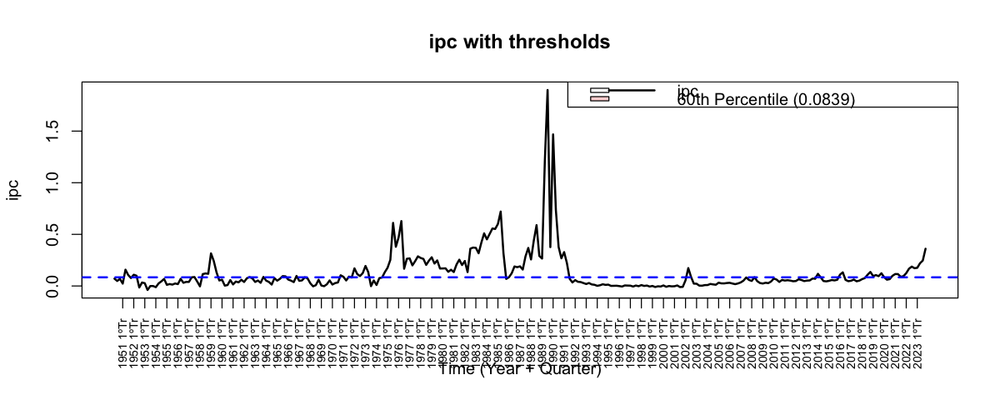

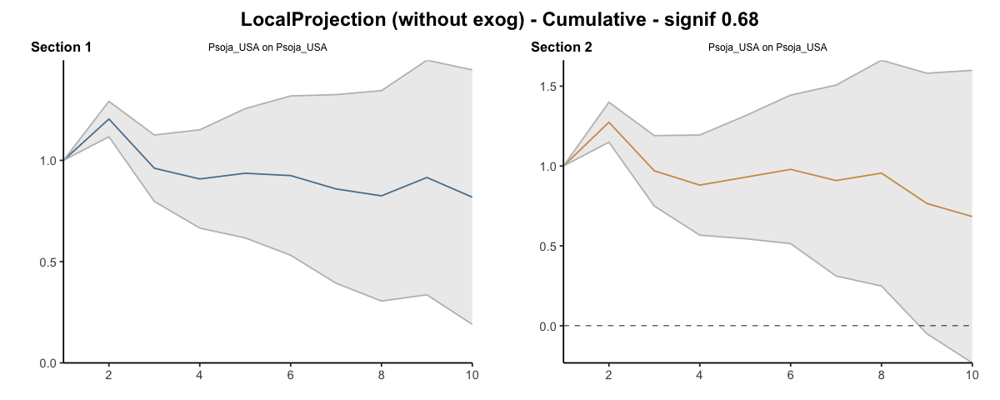

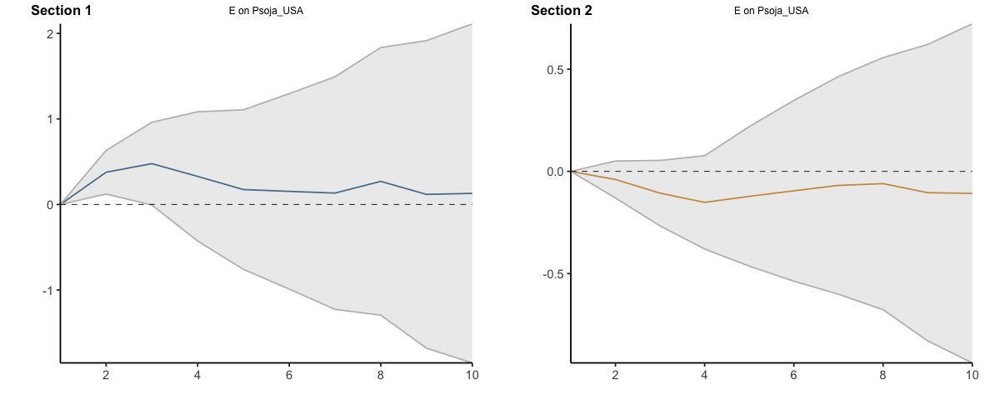

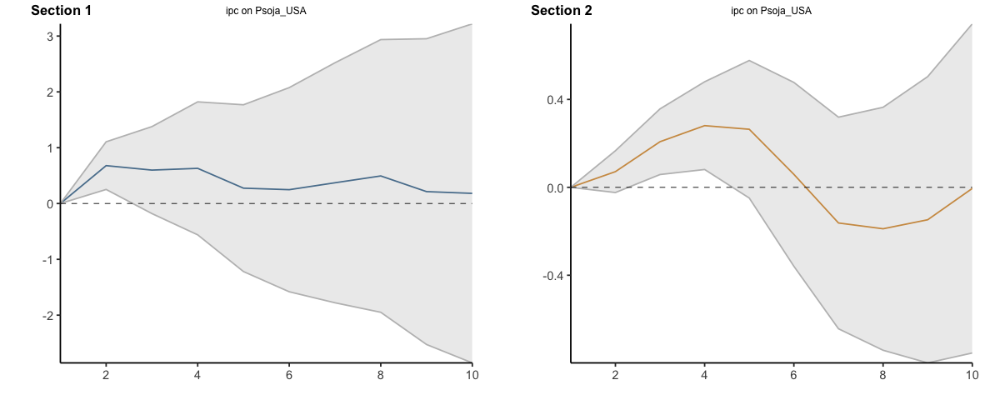

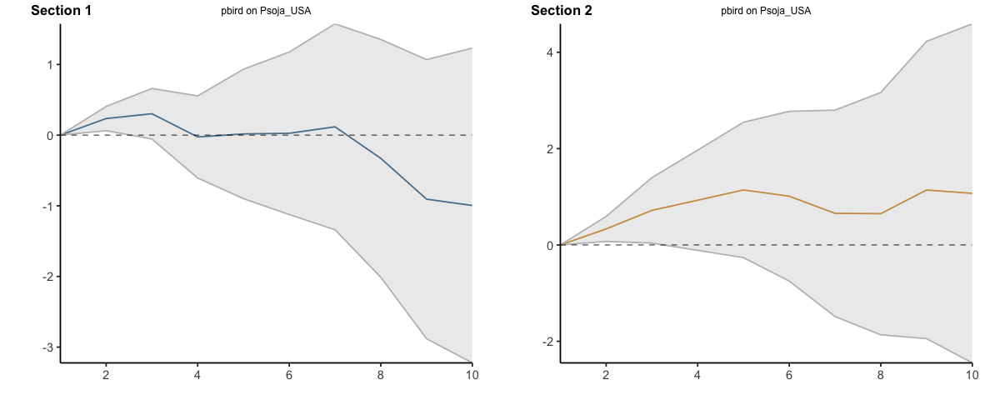

...

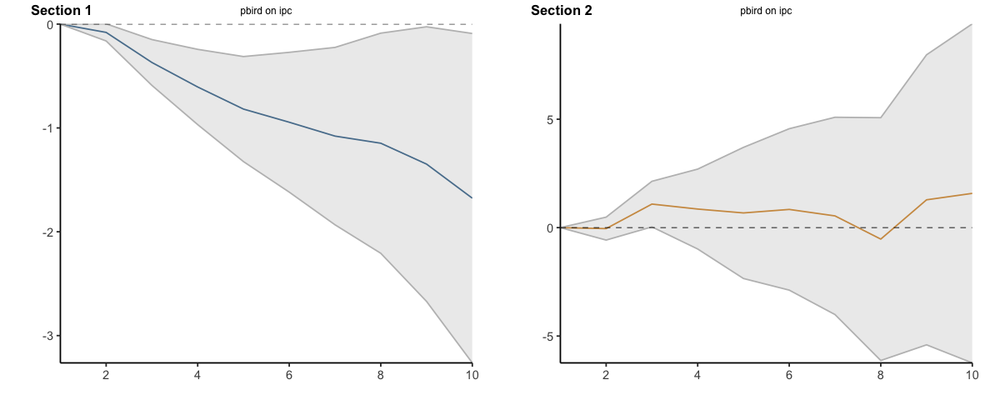

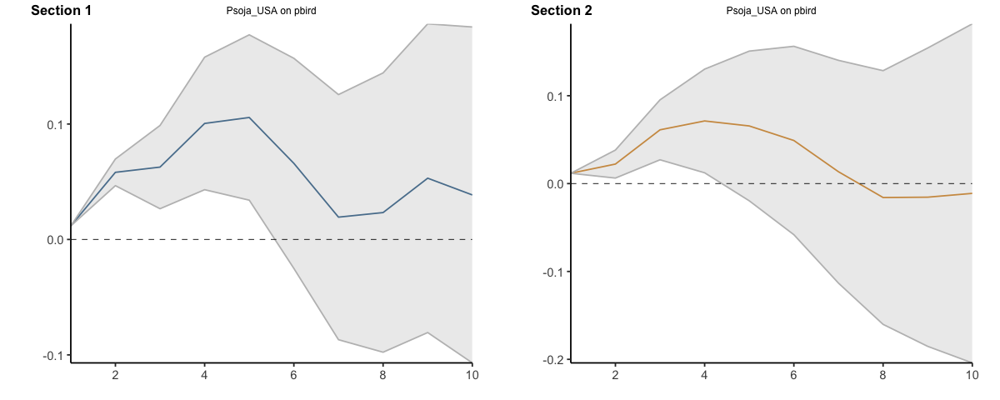

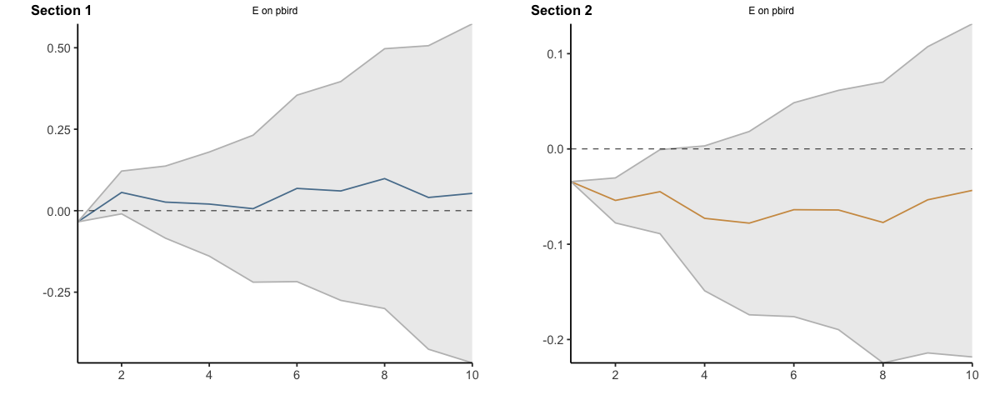

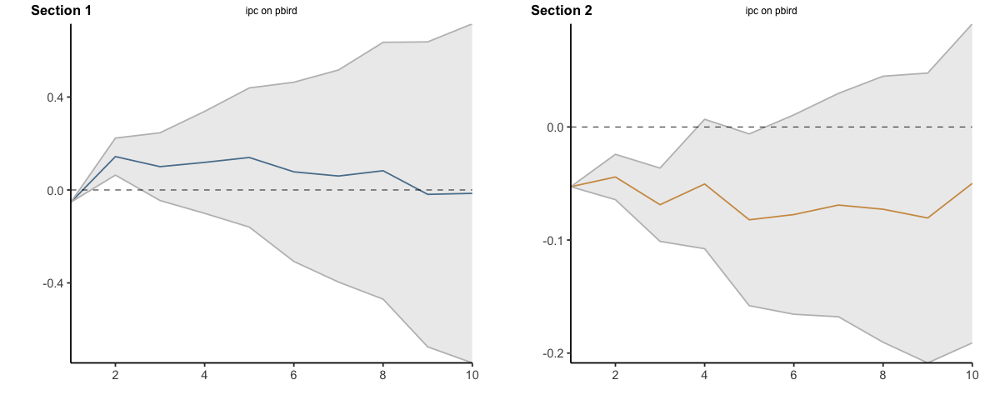

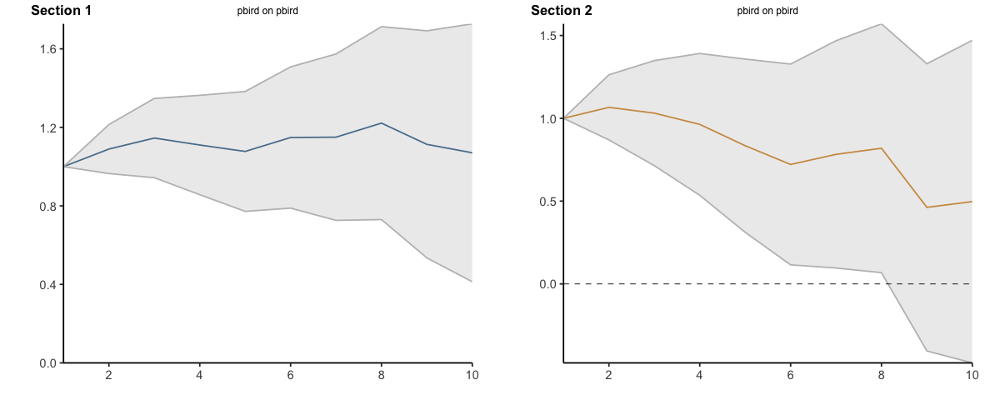

In [7]:
res <- run_lp_model(df_ERPT_Arg, endog=c("Psoja_USA", "E", "ipc", "pbird"), fixed_lags = 3, horizons=10, signif = 0.68, threshold_var = 'ipc', upper_threshold=0.6, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<dbl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
3,3,NaN,NA,NA,0,1,0.95,10,TRUE,TRUE,NA,FALSE,FALSE,0,1,295,"Psoja_USA, E, ipc, pbird",4


Impulse: Psoja_USA -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,1,-0.2031619,-0.2031619,-0.20316193,-0.2031619,-0.2031619,-0.2031619
2,2,-0.4907910,-0.6811373,-0.30044461,-0.3653428,-0.5476705,-0.1830151
3,3,-0.6111751,-1.0091920,-0.21315828,-0.4373304,-0.9792181,0.1045572
4,4,-0.6720821,-1.2339888,-0.11017550,-0.4527610,-1.3286179,0.4230959
5,5,-0.6303853,-1.3316646,0.07089402,-0.1147082,-1.6594162,1.4299998
6,6,-0.5987119,-1.5136427,0.31621893,0.1300835,-2.0369009,2.2970678
7,7,-0.6124577,-1.6912034,0.46628801,0.4101696,-2.3241766,3.1445158
8,8,-0.5369751,-1.8573995,0.78344919,0.8641419,-2.2054364,3.9337202
9,9,-0.3739514,-1.8969685,1.14906565,1.3249131,-2.2803613,4.9301875


Impulse: Psoja_USA -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
12,1,-0.02370532,-0.02370532,-0.02370532,-0.02370532,-0.02370532,-0.02370532
13,2,0.01118883,-0.01654097,0.03891863,-0.02042060,-0.12182437,0.08098316
14,3,0.02127180,-0.05899305,0.10153665,-0.16713756,-0.37884042,0.04456530
15,4,0.03503426,-0.09031721,0.16038573,-0.20319231,-0.60474814,0.19836352
16,5,0.07015479,-0.11423088,0.25454046,0.16123938,-0.71923826,1.04171701
17,6,0.06453652,-0.19589311,0.32496614,0.40211578,-0.99739637,1.80162793
18,7,0.08272034,-0.26615025,0.43159092,0.77741942,-1.02060035,2.57543920
19,8,0.04698062,-0.40103836,0.49499960,1.19758151,-1.03183613,3.42699915
20,9,0.02818927,-0.53410418,0.59048271,1.36103104,-1.23557968,3.95764176


... (16 outputs left out)

Impulse: pbird -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
111,1,0.0000000,0.000000,0.000000000,0.00000000,0.000000,0.0000000
112,2,-0.8666024,-1.741572,0.008366829,-0.62605631,-1.736434,0.4843216
113,3,-2.3673895,-4.775660,0.040880723,-0.11561347,-2.122703,1.8914761
114,4,-3.1944082,-6.677602,0.288785866,-0.38107436,-3.762812,3.0006631
115,5,-3.7363265,-7.978221,0.505568326,-0.46681442,-5.447272,4.5136433
116,6,-2.5983178,-8.105382,2.908746559,0.30438007,-5.773467,6.3822268
117,7,-2.5874497,-9.081195,3.906295180,-0.18644271,-7.712804,7.3399187
118,8,-2.8158539,-11.014569,5.382860960,-0.08757429,-8.461277,8.2861282
119,9,-3.7850293,-12.889841,5.319782049,1.76434506,-8.682266,12.2109559


Impulse: pbird -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
122,1,0.00000000,0.0000000,0.0000000,0.0000000,0.0000000,0.0000000
123,2,-0.03682094,-0.2793105,0.2056686,0.1239661,-0.4295321,0.6774643
124,3,-0.41471734,-0.9469475,0.1175128,0.7158516,-0.3984482,1.8301514
125,4,-0.69947288,-1.5678932,0.1689475,0.7797718,-1.3024531,2.8619966
126,5,-0.81477678,-2.0376867,0.4081331,0.8325983,-2.4596819,4.1248785
127,6,-0.78289635,-2.4305739,0.8647812,1.1477259,-2.9663287,5.2617805
128,7,-0.80170178,-2.9653736,1.3619700,1.2682555,-3.8628652,6.3993761
129,8,-0.71614527,-3.4845689,2.0522783,1.1418224,-5.1079039,7.3915487
130,9,-0.81559178,-4.4478757,2.8166922,2.5577883,-5.2364168,10.3519934


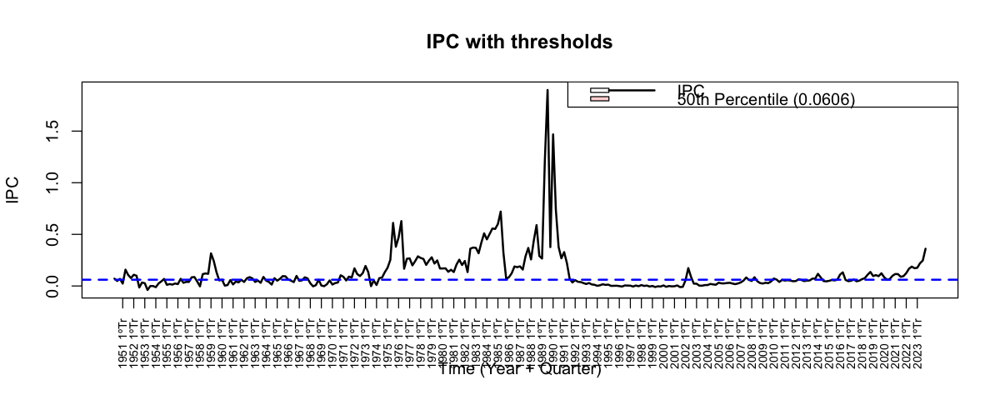

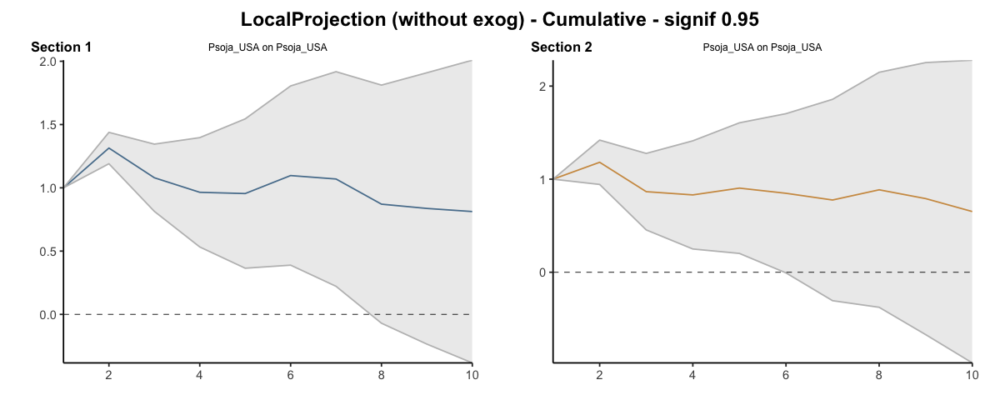

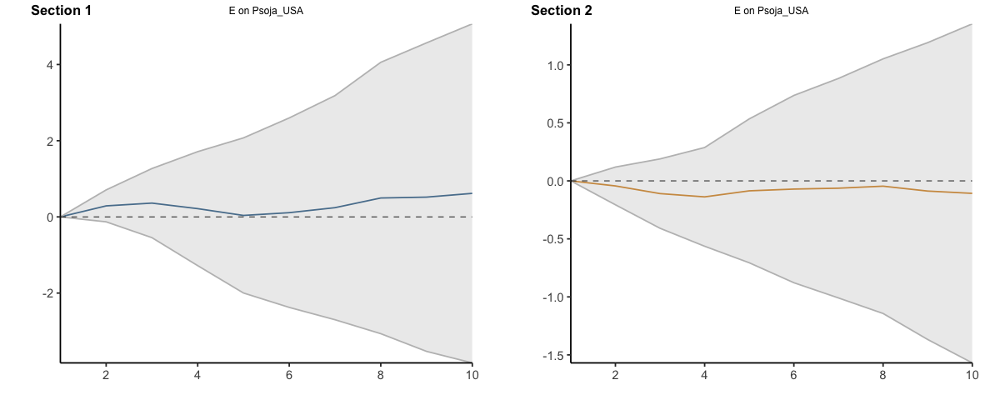

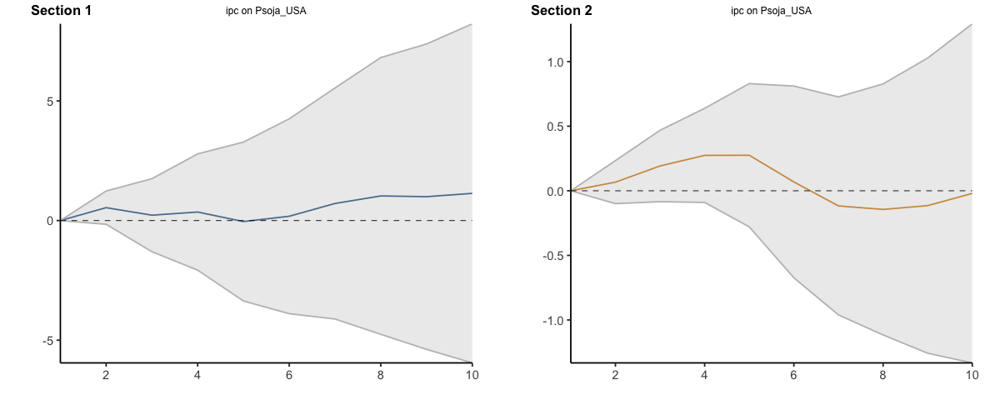

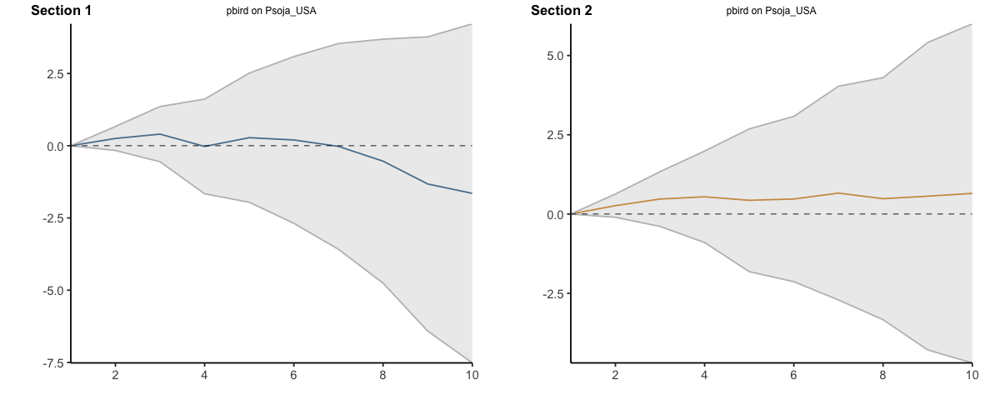

...

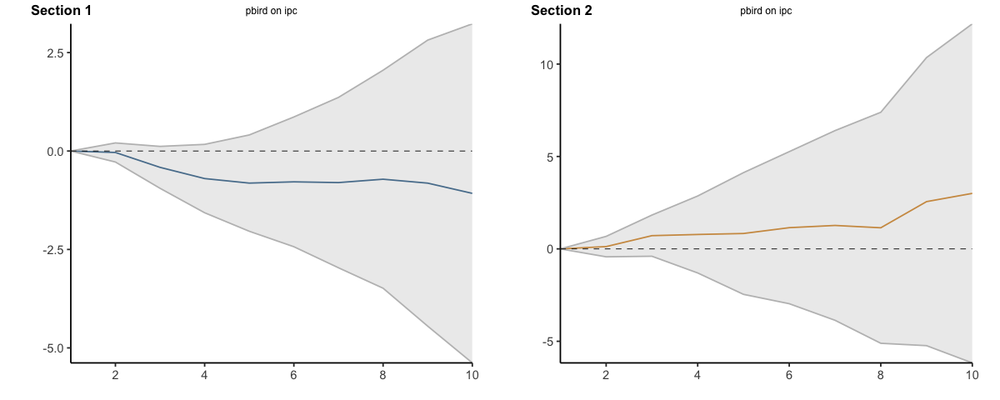

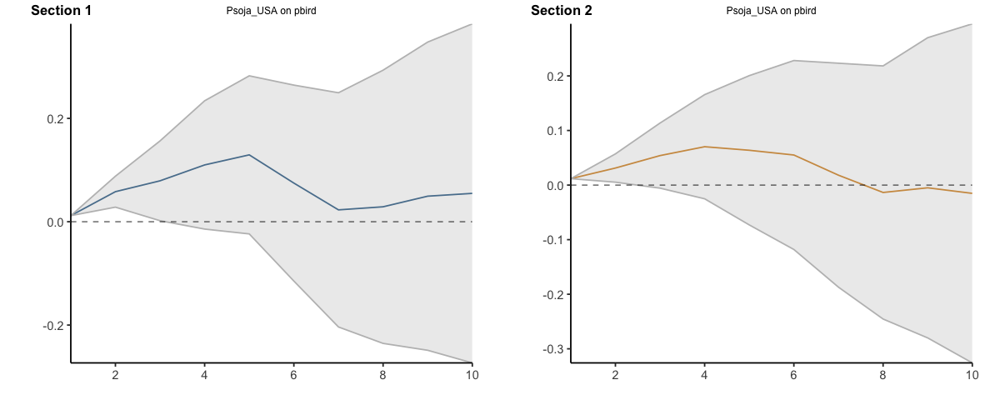

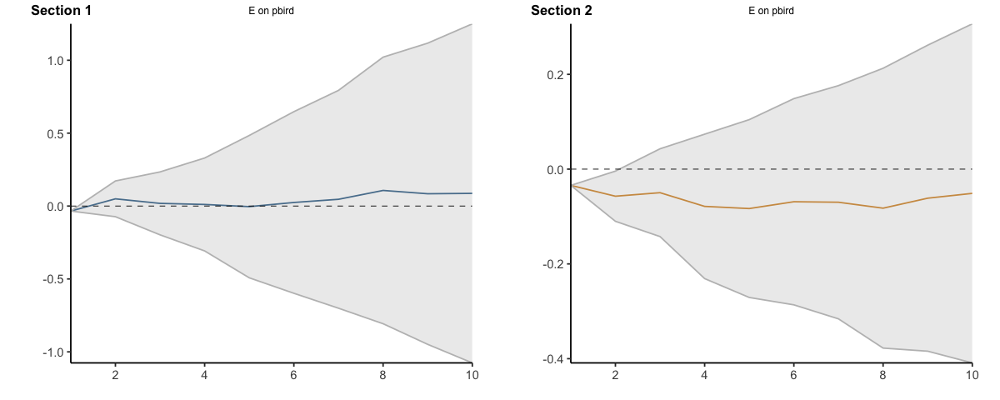

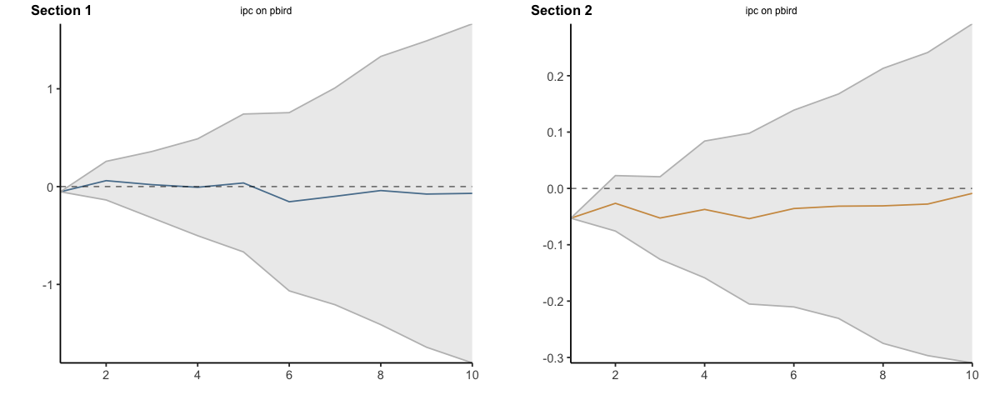

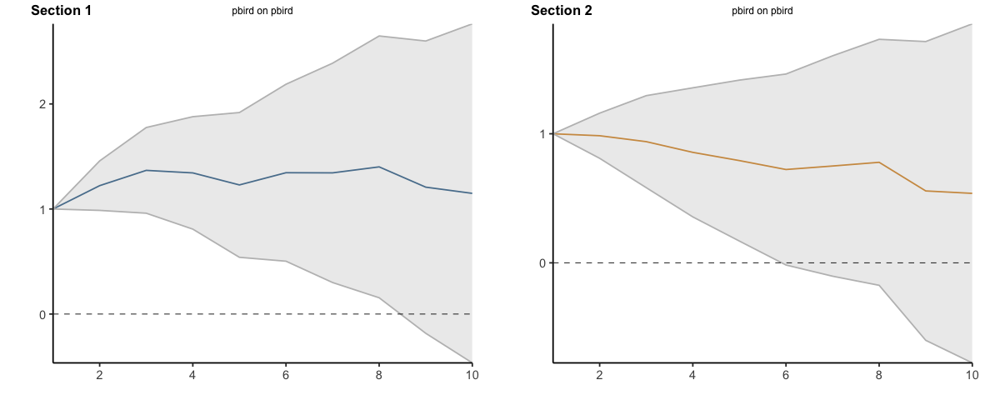

In [14]:
res <- run_lp_model(df_ERPT_Arg, endog=c("Psoja_USA", "E", "ipc", "pbird"), fixed_lags = 3, horizons=10, signif = 0.95, threshold_var = 'ipc', upper_threshold=0.5, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<dbl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
3,3,NaN,NA,NA,0,1,0.95,10,TRUE,TRUE,NA,FALSE,FALSE,0,1,295,"Psoja_USA, E, ipc, pbird",4


Impulse: Psoja_USA -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,1,-0.2031619,-0.2031619,-0.20316193,-0.20316193,-0.2031619,-0.2031619
2,2,-0.4527651,-0.6542814,-0.25124873,-0.36135274,-0.5330735,-0.1896319
3,3,-0.5712758,-1.0139618,-0.12858981,-0.44044257,-0.9485717,0.0676866
4,4,-0.5807506,-1.2124186,0.05091749,-0.51471722,-1.3071231,0.2776886
5,5,-0.6265131,-1.4115994,0.15857322,-0.18996468,-1.5765937,1.1966643
6,6,-0.5815703,-1.5775443,0.41440363,-0.05504432,-2.0038591,1.8937704
7,7,-0.5775026,-1.7443180,0.58931275,0.16038737,-2.3232230,2.6439977
8,8,-0.4285127,-1.7899859,0.93296064,0.49630553,-2.2872277,3.2798388
9,9,-0.2272732,-1.7606345,1.30608820,0.86718685,-2.4007686,4.1351422


Impulse: Psoja_USA -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
12,1,-0.02370532,-0.02370532,-0.02370532,-0.02370532,-0.02370532,-0.02370532
13,2,0.02976015,-0.01694559,0.07646588,-0.02037641,-0.10710256,0.06634974
14,3,0.04810902,-0.05477954,0.15099758,-0.15789320,-0.34388674,0.02810034
15,4,0.07890552,-0.07011094,0.22792198,-0.22820040,-0.57811405,0.12171325
16,5,0.12443404,-0.08350084,0.33236891,0.08296315,-0.68398910,0.84991540
17,6,0.11291032,-0.16575274,0.39157338,0.27359775,-0.96011564,1.50731114
18,7,0.12618193,-0.24433029,0.49669415,0.57792605,-0.99790789,2.15376000
19,8,0.11247685,-0.35167093,0.57662463,0.90741138,-1.07519638,2.89001914
20,9,0.12878898,-0.43202664,0.68960460,1.01112430,-1.31253956,3.33478816


... (16 outputs left out)

Impulse: pbird -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
111,1,0.0000000,0.000000,0.0000000,0.0000000,0.000000,0.0000000
112,2,-0.8074682,-1.747247,0.1323103,-0.7257771,-1.763639,0.3120847
113,3,-2.0654529,-4.510596,0.3796897,-0.5528222,-2.436099,1.3304549
114,4,-2.8811709,-6.631764,0.8694223,-0.8242928,-3.973384,2.3247989
115,5,-3.4429426,-7.921027,1.0351423,-1.0989940,-5.640900,3.4429121
116,6,-2.5651229,-8.203274,3.0730283,-0.3684444,-5.878907,5.1420179
117,7,-2.8119704,-9.509577,3.8856357,-0.7212152,-7.542807,6.1003766
118,8,-3.3281250,-11.628926,4.9726758,-0.5874452,-8.150038,6.9751471
119,9,-4.5308093,-13.962550,4.9009317,0.9296101,-8.283310,10.1425302


Impulse: pbird -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
122,1,0.0000000,0.0000000,0.0000000,0.0000000,0.0000000,0.0000000
123,2,0.1112930,-0.1228218,0.3454079,0.1366811,-0.3285277,0.6018899
124,3,-0.1868800,-0.7853494,0.4115895,0.5071816,-0.4587567,1.4731200
125,4,-0.4506227,-1.3947156,0.4934702,0.5450589,-1.3096373,2.3997551
126,5,-0.5995092,-1.9831321,0.7841137,0.5619570,-2.3554275,3.4793415
127,6,-0.5578704,-2.3746107,1.2588698,0.7625152,-2.8966928,4.4217233
128,7,-0.6800427,-3.0163532,1.6562678,0.8175735,-3.7950460,5.4301930
129,8,-0.9060999,-3.8228855,2.0106857,0.7967870,-4.7967332,6.3903072
130,9,-1.0701969,-4.8655654,2.7251716,1.9683055,-4.8696167,8.8062278


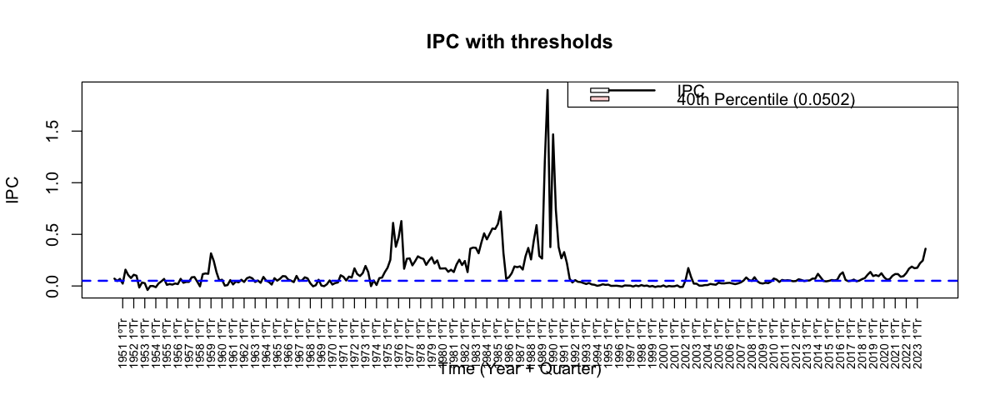

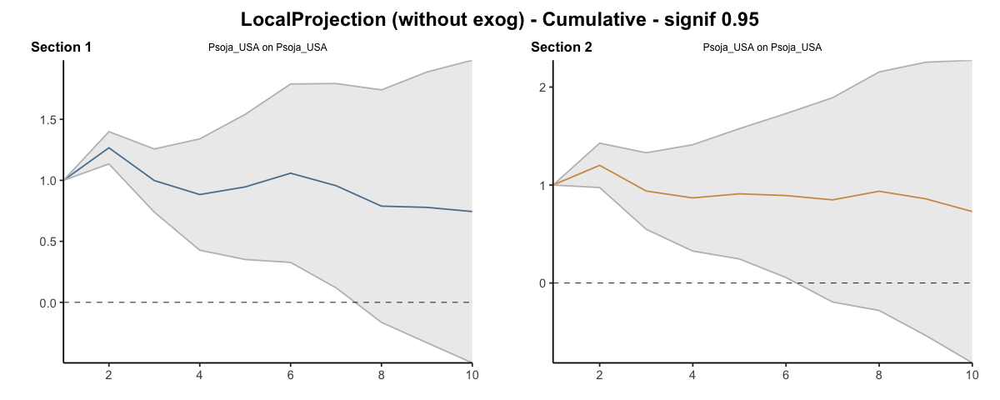

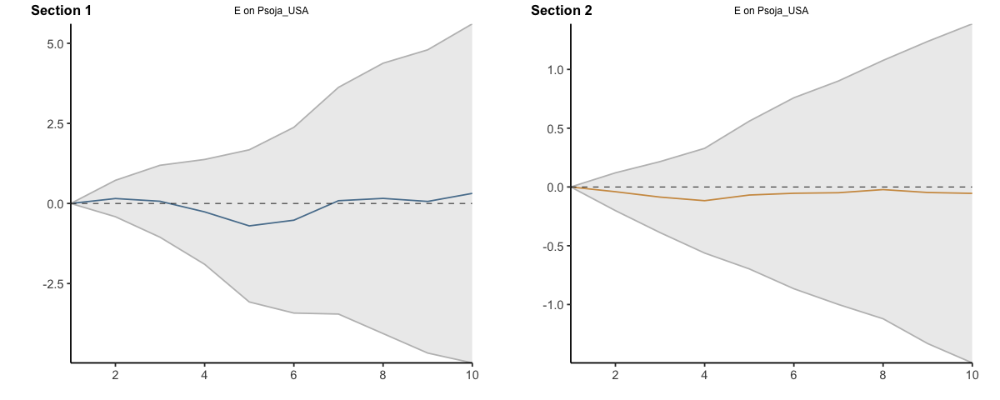

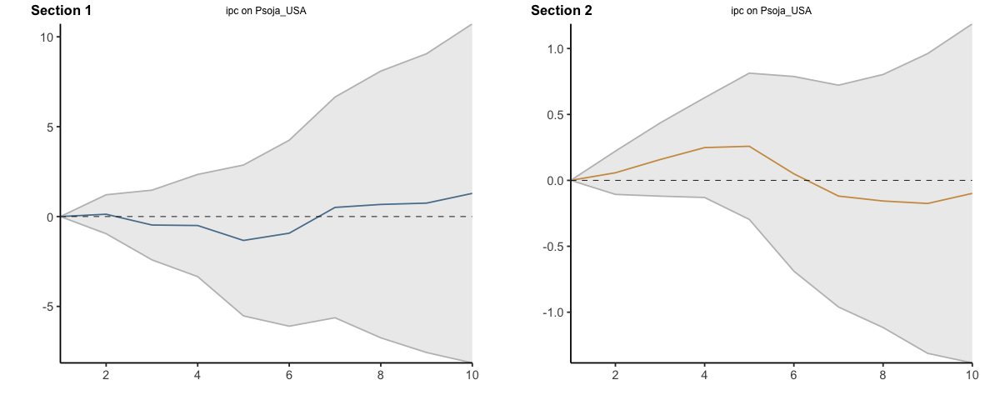

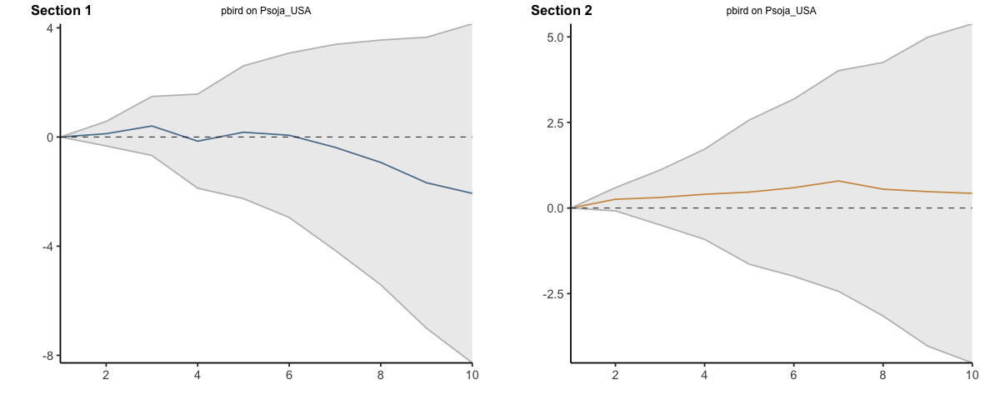

...

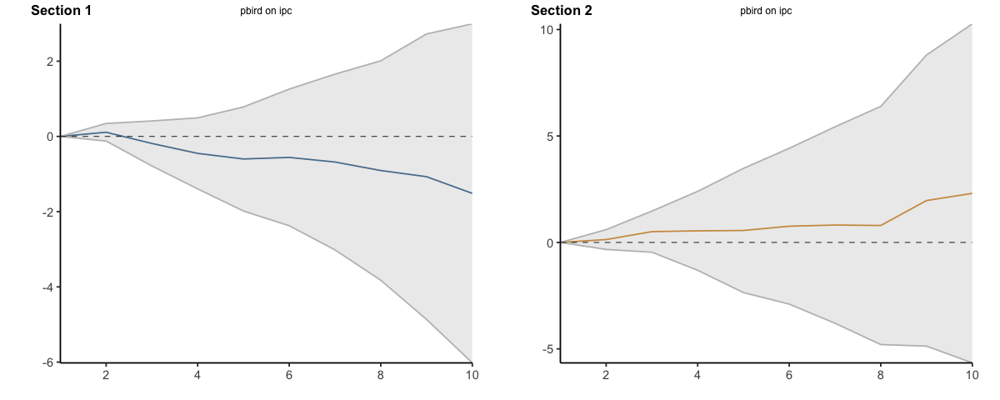

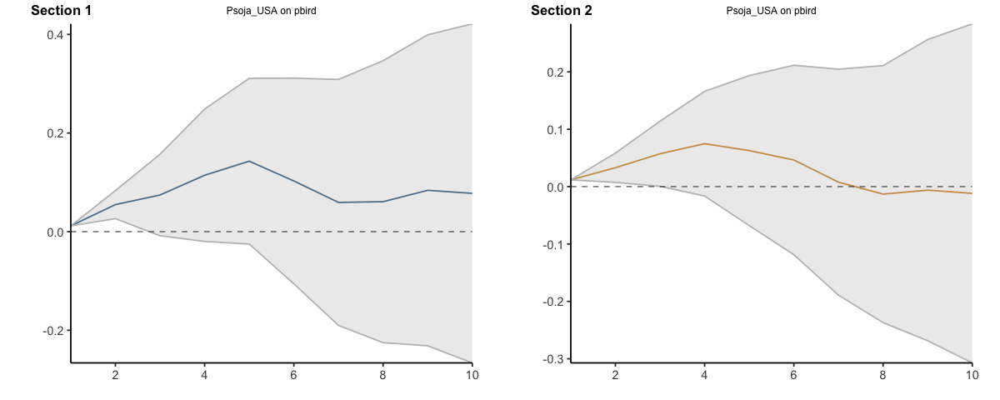

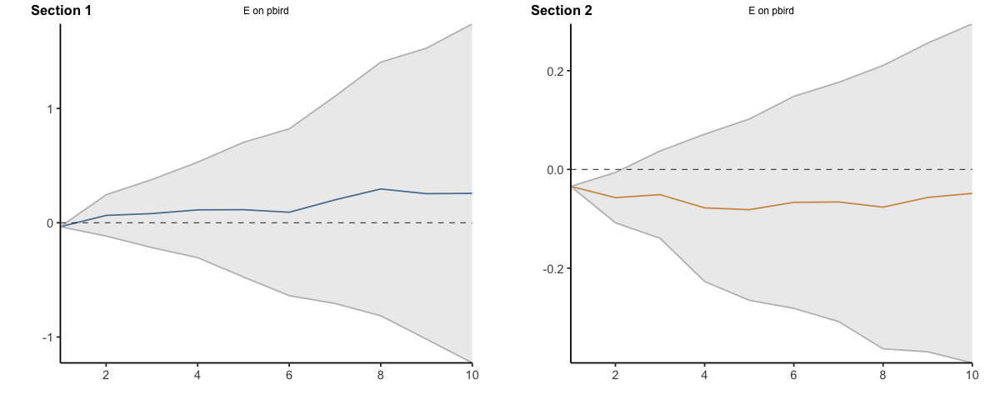

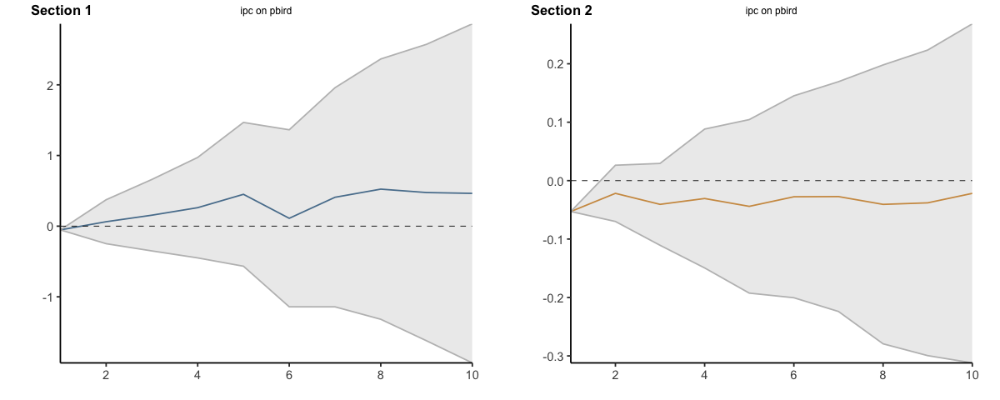

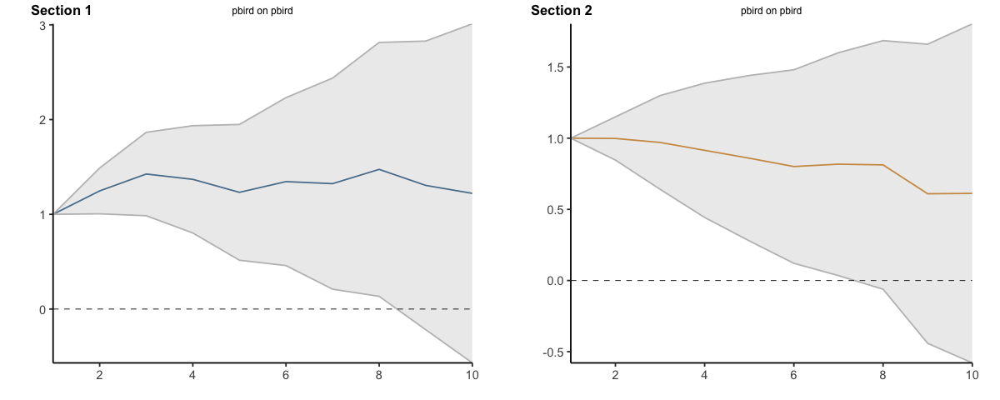

In [15]:
res <- run_lp_model(df_ERPT_Arg, endog=c("Psoja_USA", "E", "ipc", "pbird"), fixed_lags = 3, horizons=10, signif = 0.95, threshold_var = 'ipc', upper_threshold=0.4, cumulative=TRUE)

### Todas endógenas - 3 lags

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<dbl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
3,3,NaN,NA,NA,0,1,0.68,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,295,"impp_usa, E, ipc, pbird",4


Impulse: impp_usa -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,0,-1.4402723,-1.4402723,-1.4402723,-1.440272,-1.4402723,-1.4402723
2,1,-1.0235361,-1.1151577,-0.9319145,1.370368,-1.4309737,4.1717088
3,2,-0.7441868,-0.8776639,-0.6107096,2.442228,0.1085005,4.7759546
4,3,0.2258401,0.1181366,0.3335437,-1.699705,-3.1457098,-0.2537011
5,4,0.6228142,0.2000171,1.0456112,1.429821,-0.6437720,3.5034144
6,5,1.1087716,0.6783943,1.5391489,1.843603,0.4491519,3.2380539
7,6,1.4335911,1.0303022,1.8368800,-0.357756,-2.0857793,1.3702674
8,7,1.4918946,1.0011684,1.9826208,3.113535,1.8415192,4.3855501
9,8,1.2264662,1.1559545,1.2969779,4.645036,2.8744339,6.4156377


Impulse: impp_usa -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
10,0,-0.5899488,-0.58994884,-0.58994884,-0.58994884,-0.589948844,-0.5899488
11,1,-0.3697636,-0.34876017,-0.39076695,1.16440177,-0.001154038,2.3299576
12,2,-0.2870859,-0.30208429,-0.27208752,2.57180149,0.081661091,5.0619419
13,3,-0.0772734,-0.07479234,-0.07975447,-0.05680234,-1.183071583,1.0694669
14,4,0.1288550,0.11854676,0.13916326,2.16048405,0.397589479,3.9233786
15,5,0.3599272,0.23654548,0.48330895,2.13418245,0.521186467,3.7471784
16,6,0.6931553,0.31040894,1.07590168,0.41989688,-0.749604644,1.5893984
17,7,0.8100160,0.51420187,1.10583019,1.85557851,0.985100005,2.7260570
18,8,1.1228107,0.93035556,1.31526592,3.12649938,1.701249459,4.5517493


... (16 outputs left out)

Impulse: pbird -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
91,0,0.0000000,0.0000000,0.00000000,0.0000000,0.0000000,0.0000000
92,1,-0.6066739,-0.9325594,-0.28078834,-1.4392757,-2.5218975,-0.3566540
93,2,-0.9137863,-1.4081975,-0.41937507,0.4971065,-0.5015688,1.4957819
94,3,-0.6450376,-1.0179130,-0.27216218,-0.2440557,-1.5616447,1.0735333
95,4,-0.4439821,-0.8206832,-0.06728092,-0.2534319,-1.6643659,1.1575020
96,5,0.1260479,-0.3514528,0.60354861,0.6455518,-0.5999926,1.8910962
97,6,-0.5123728,-0.8329467,-0.19179900,-2.2431866,-3.9853468,-0.5010263
98,7,-0.6200036,-1.0788298,-0.16117739,-0.4859968,-1.4744683,0.5024747
99,8,-0.8317665,-1.1970932,-0.46643984,2.3197522,0.3052029,4.3343015


Impulse: pbird -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
100,0,0.000000000,0.00000000,0.00000000,0.00000000,0.0000000,0.00000000
101,1,-0.002054456,-0.07185289,0.06774397,-0.04805812,-0.7445247,0.64840844
102,2,-0.219648790,-0.34309092,-0.09620666,0.46301504,-0.2390252,1.16505524
103,3,-0.243592747,-0.38324538,-0.10394012,0.07069735,-1.0061287,1.14752338
104,4,-0.264713974,-0.44926987,-0.08015808,0.15144038,-0.9655205,1.26840128
105,5,-0.260192941,-0.48363415,-0.03675173,0.30106931,-0.6757650,1.27790365
106,6,-0.299102440,-0.53631477,-0.06189011,-0.59439381,-1.6980195,0.50923188
107,7,-0.267921843,-0.49945100,-0.03639269,-1.14291107,-2.2607510,-0.02507117
108,8,-0.388128875,-0.66886642,-0.10739133,1.76419718,0.3175711,3.21082323


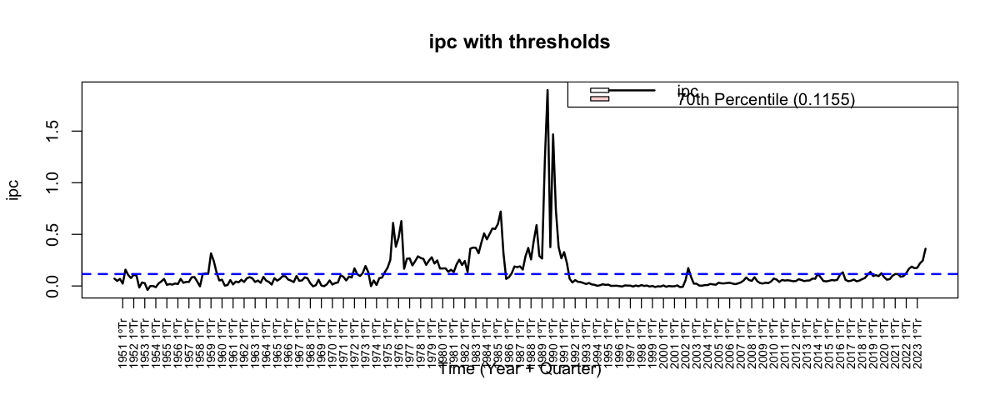

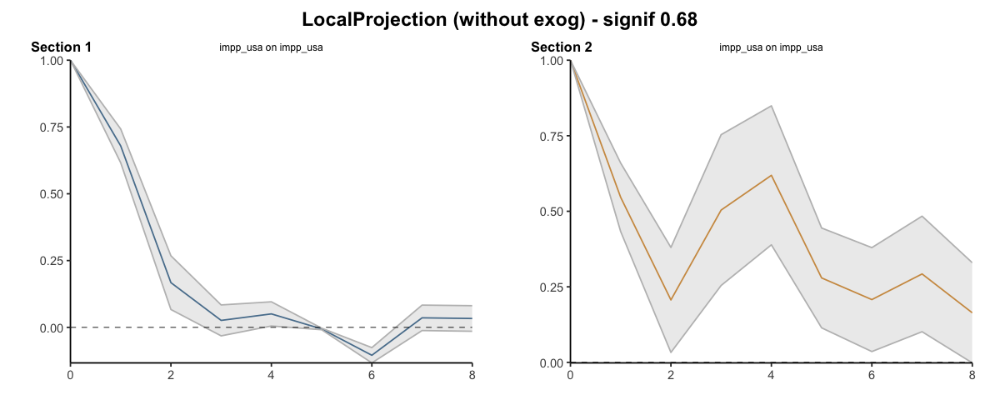

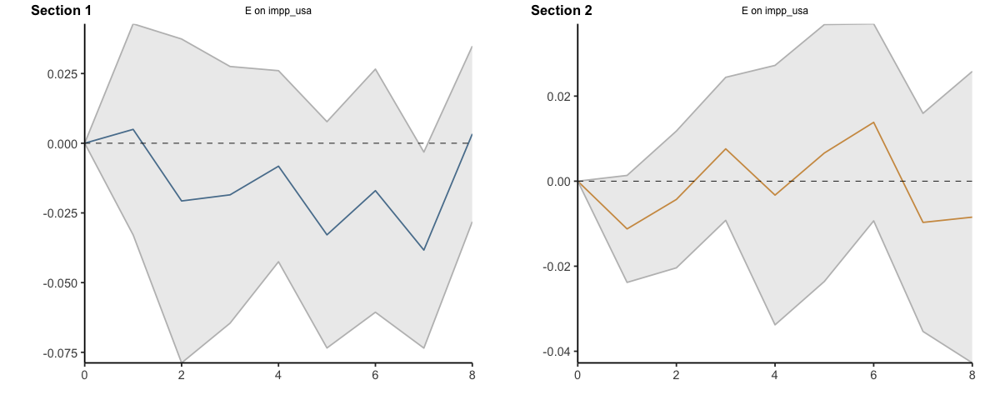

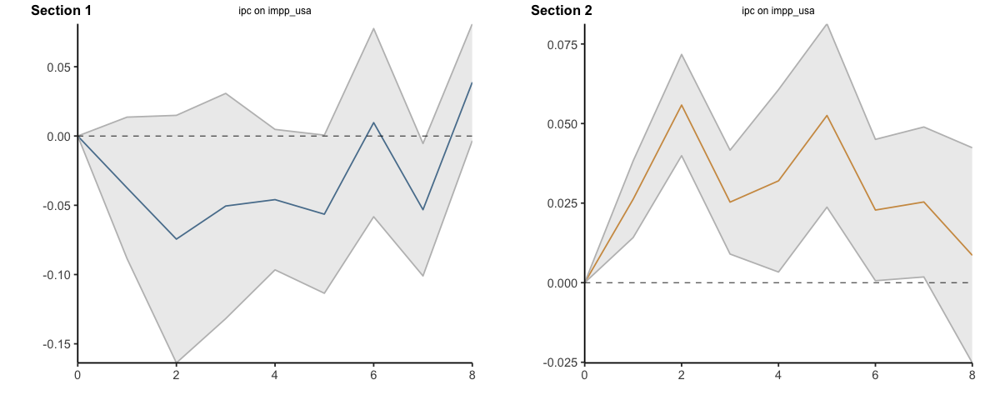

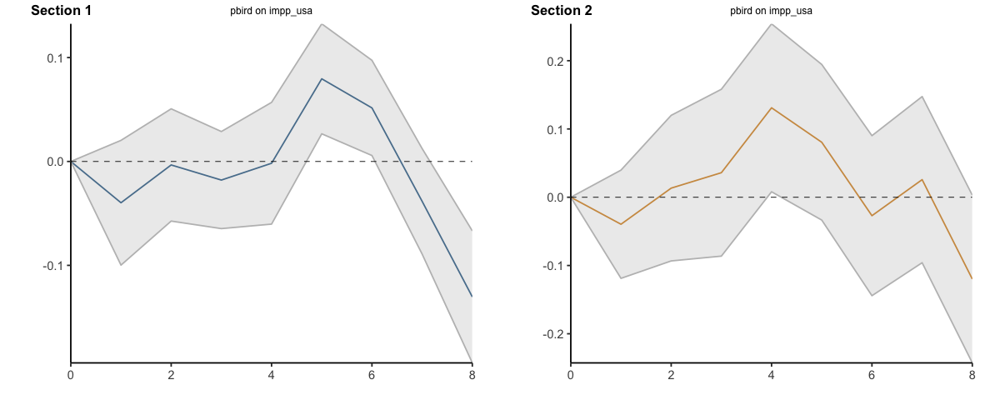

...

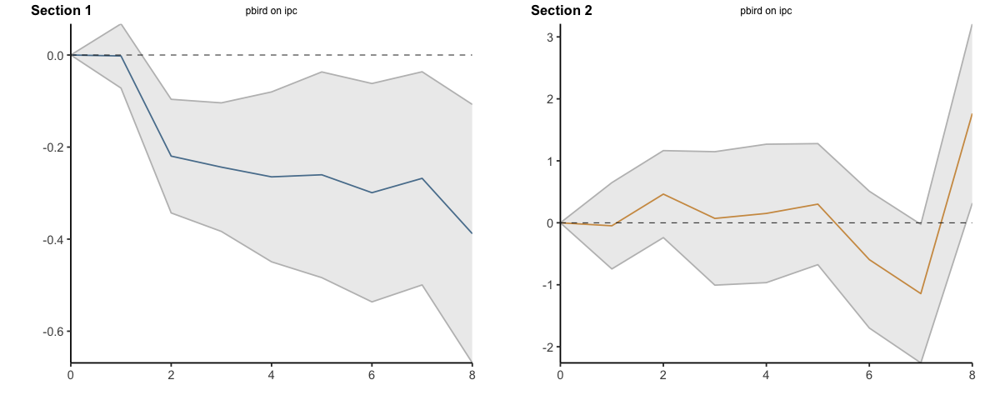

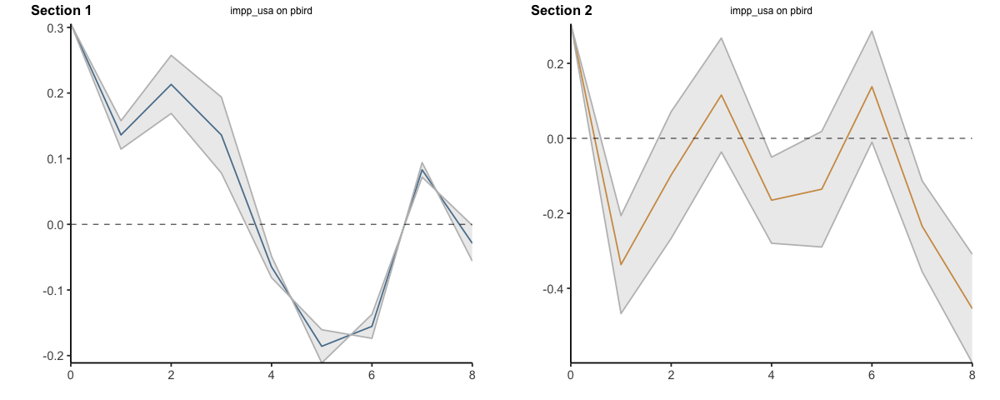

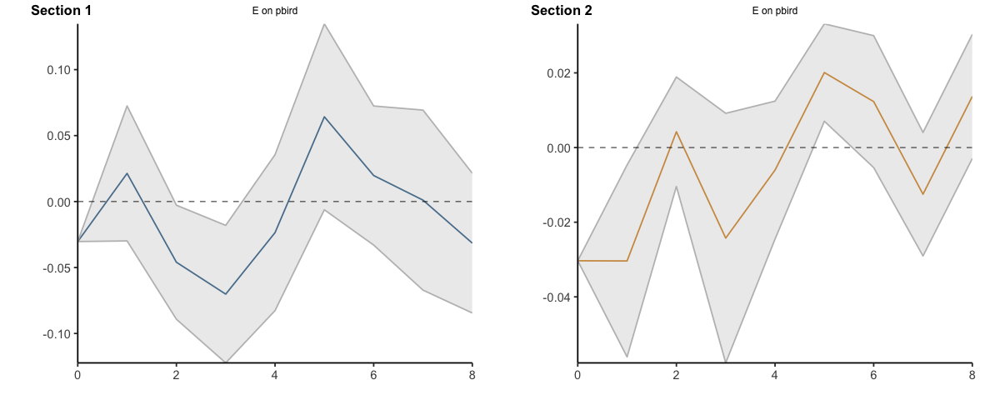

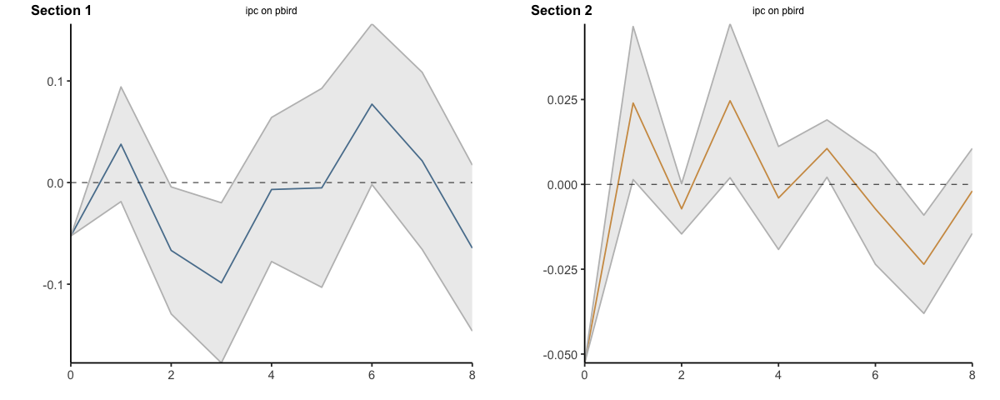

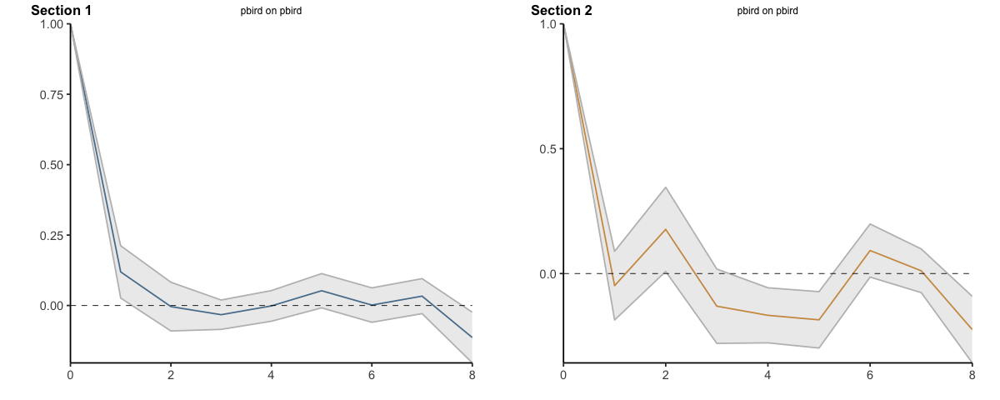

In [28]:
res <- run_lp_model(df_ERPT_Arg, endog=c("impp_usa", "E", "ipc", "pbird"), fixed_lags = 3, horizons=8, signif = 0.68, threshold_var = 'ipc', upper_threshold=0.7)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<dbl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
3,3,NaN,NA,NA,0,1,0.68,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,295,"impp_usa, E, ipc, pbird",4


Impulse: impp_usa -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,0,-1.4402723,-1.4402723,-1.44027226,-1.4402723,-1.440272,-1.440272
2,1,-2.4638083,-2.5554299,-2.37218676,-0.0699047,-2.871246,2.731437
3,2,-3.2079951,-3.4330938,-2.98289638,2.3723229,-2.762745,7.507391
4,3,-2.9821550,-3.3149572,-2.64935268,0.6726174,-5.908455,7.253690
5,4,-2.3593408,-3.1149401,-1.60374150,2.1024386,-6.552227,10.757104
6,5,-1.2505692,-2.4365458,-0.06459257,3.9460415,-6.103075,13.995158
7,6,0.1830219,-1.4062436,1.77228742,3.5882855,-8.188855,15.365426
8,7,1.6749165,-0.4050752,3.75490820,6.7018202,-6.347336,19.750976
9,8,2.9013827,0.7508793,5.05188606,11.3468560,-3.472902,26.166614


Impulse: impp_usa -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
10,0,-0.5899488,-0.5899488,-0.5899488,-0.5899488,-0.5899488,-0.5899488
11,1,-0.9597124,-0.9387090,-0.9807158,0.5744529,-0.5911029,1.7400087
12,2,-1.2467983,-1.2407933,-1.2528033,3.1462544,-0.5094418,6.8019506
13,3,-1.3240717,-1.3155856,-1.3325578,3.0894521,-1.6925134,7.8714175
14,4,-1.1952167,-1.1970389,-1.1933945,5.2499361,-1.2949239,11.7947962
15,5,-0.8352895,-0.9604934,-0.7100856,7.3841186,-0.7737374,15.5419746
16,6,-0.1421342,-0.6500845,0.3658161,7.8040155,-1.5233421,17.1313730
17,7,0.6678819,-0.1358826,1.4716463,9.6595940,-0.5382421,19.8574300
18,8,1.7906926,0.7944730,2.7869122,12.7860933,1.1630074,24.4091793


... (16 outputs left out)

Impulse: pbird -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
91,0,0.0000000,0.0000000,0.0000000,0.0000000,0.000000,0.000000
92,1,-0.6066739,-0.9325594,-0.2807883,-1.4392757,-2.521897,-0.356654
93,2,-1.5204601,-2.3407569,-0.7001634,-0.9421692,-3.023466,1.139128
94,3,-2.1654977,-3.3586698,-0.9723256,-1.1862249,-4.585111,2.212661
95,4,-2.6094798,-4.1793531,-1.0396065,-1.4396568,-6.249477,3.370163
96,5,-2.4834319,-4.5308059,-0.4360579,-0.7941050,-6.849469,5.261259
97,6,-2.9958047,-5.3637526,-0.6278569,-3.0372916,-10.834816,4.760233
98,7,-3.6158083,-6.4425824,-0.7890343,-3.5232884,-12.309285,5.262708
99,8,-4.4475748,-7.6396756,-1.2554741,-1.2035362,-12.004082,9.597009


Impulse: pbird -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
100,0,0.000000000,0.00000000,0.00000000,0.00000000,0.0000000,0.0000000
101,1,-0.002054456,-0.07185289,0.06774397,-0.04805812,-0.7445247,0.6484084
102,2,-0.221703246,-0.41494381,-0.02846268,0.41495691,-0.9835499,1.8134637
103,3,-0.465295993,-0.79818918,-0.13240280,0.48565427,-1.9896785,2.9609871
104,4,-0.730009968,-1.24745905,-0.21256088,0.63709464,-2.9551991,4.2293883
105,5,-0.990202909,-1.73109321,-0.24931261,0.93816395,-3.6309641,5.5072920
106,6,-1.289305349,-2.26740797,-0.31120272,0.34377015,-5.3289836,6.0165239
107,7,-1.557227192,-2.76685897,-0.34759541,-0.79914092,-7.5897346,5.9914527
108,8,-1.945356066,-3.43572539,-0.45498674,0.96505626,-7.2721634,9.2022759


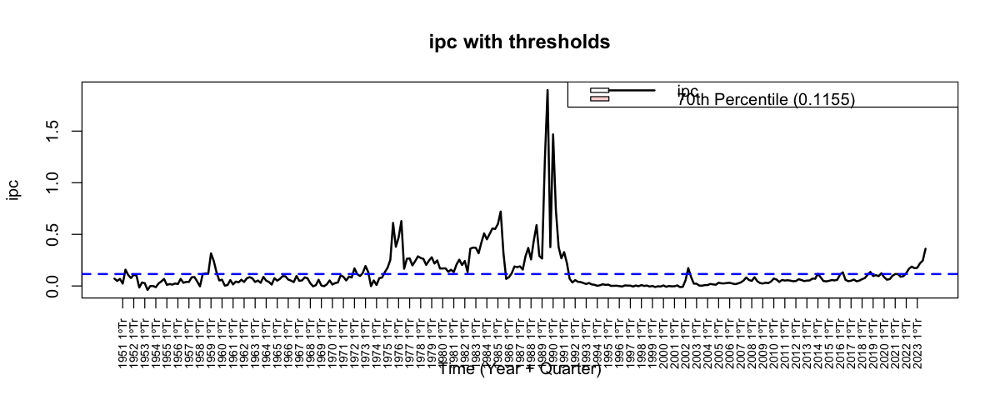

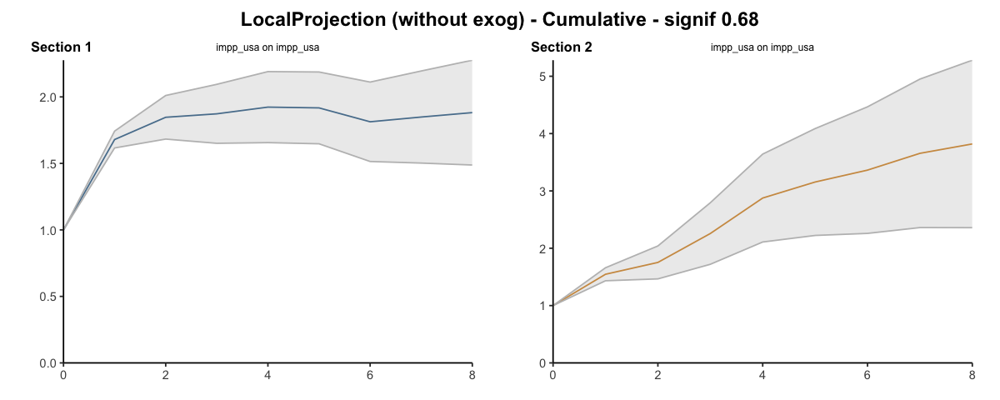

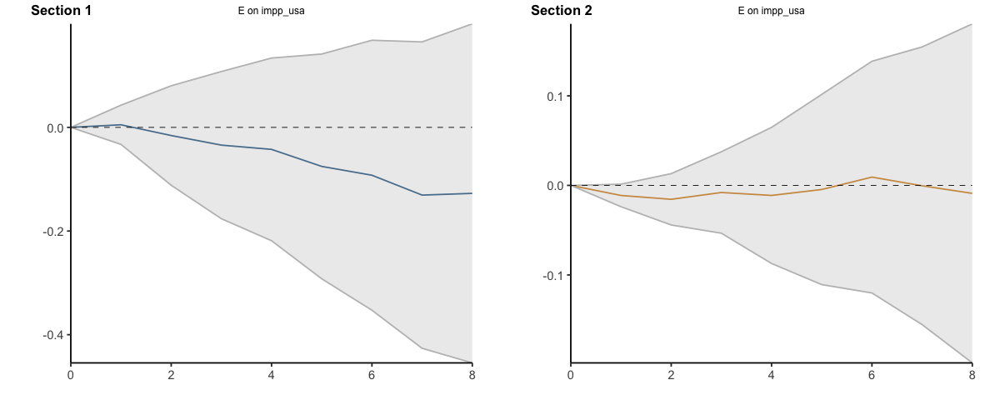

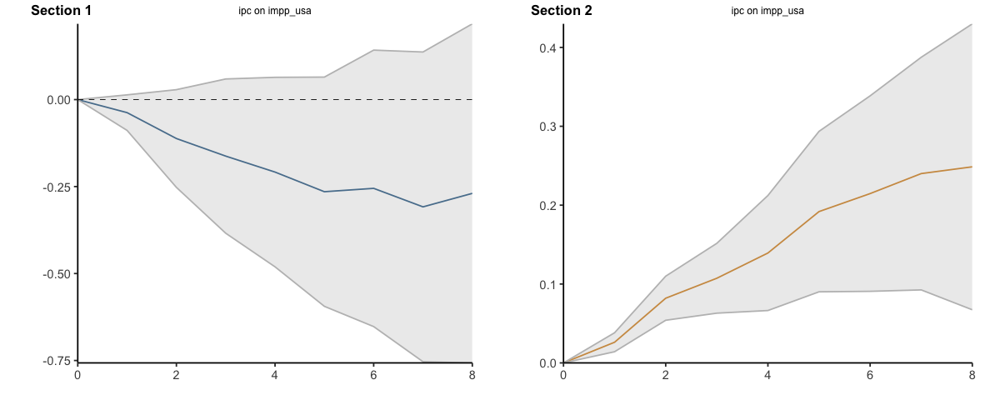

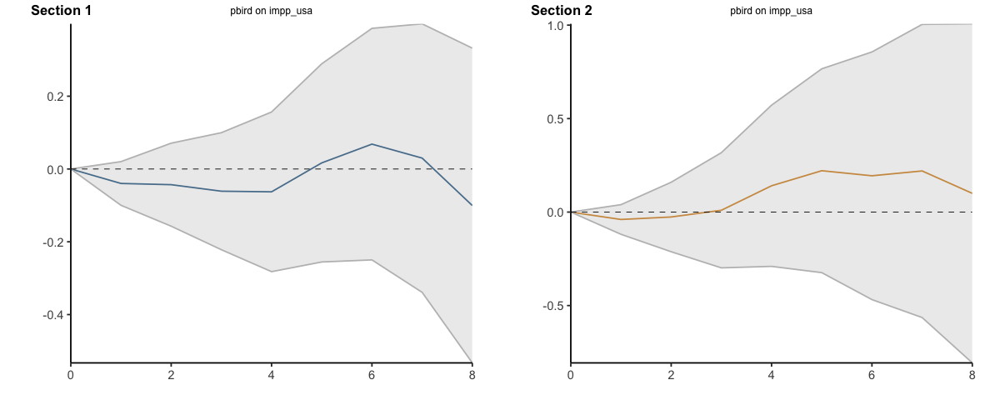

...

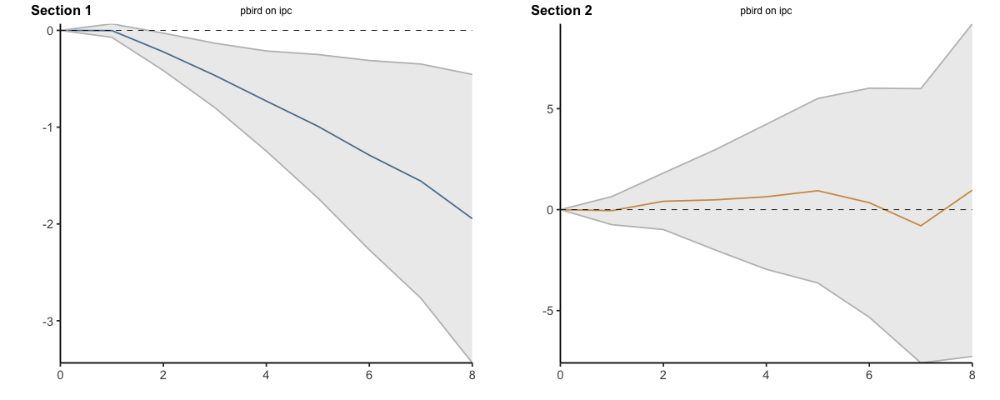

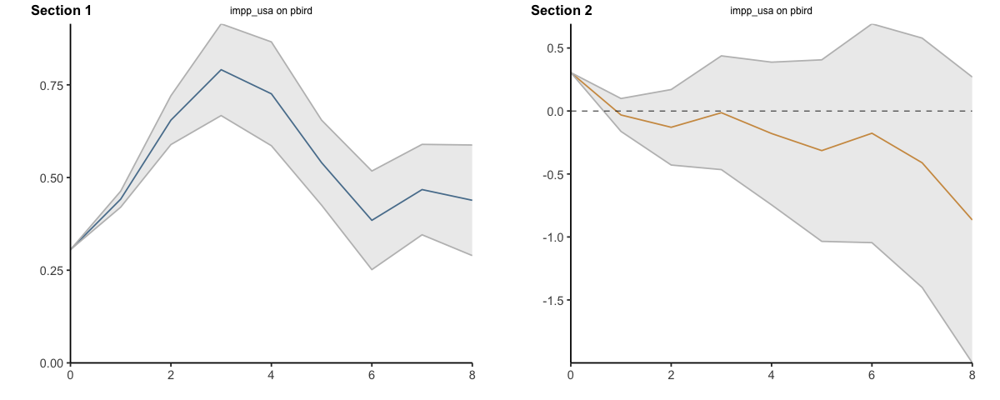

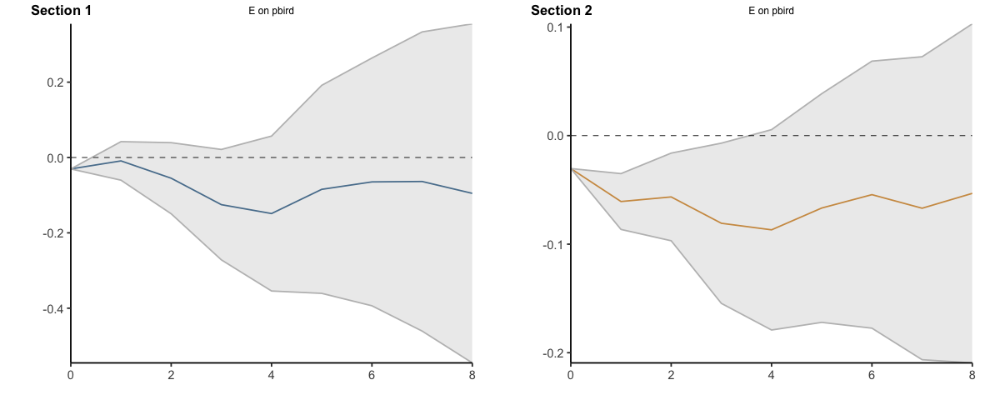

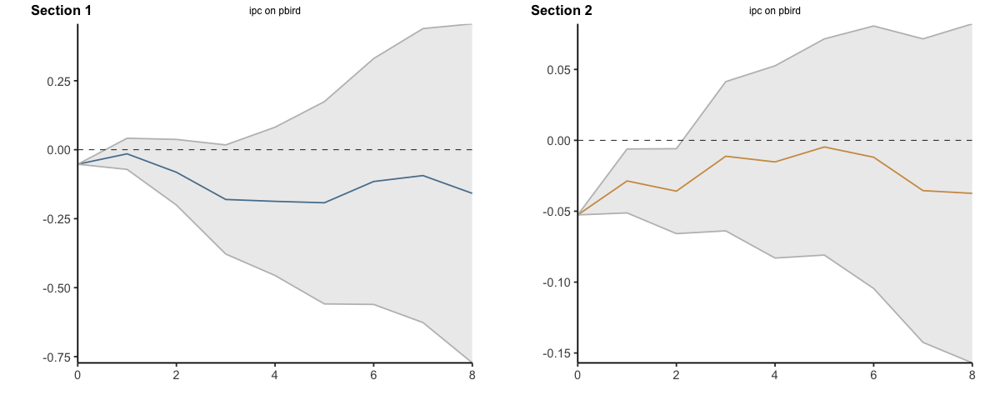

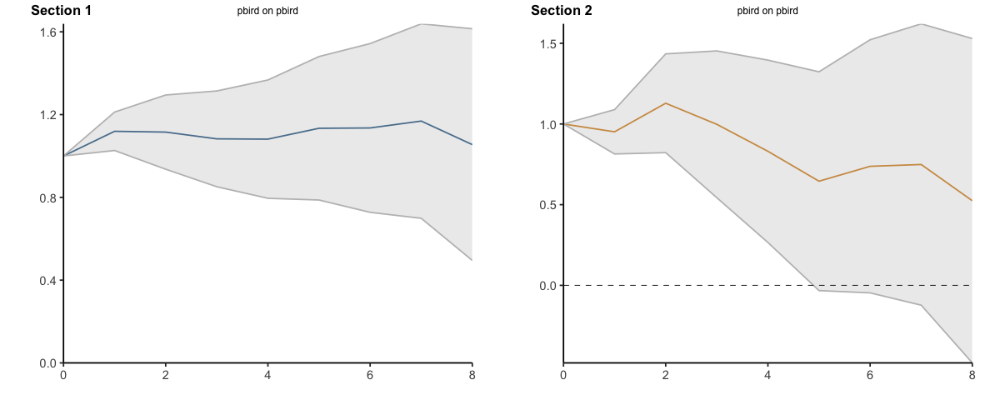

In [29]:
res <- run_lp_model(df_ERPT_Arg, endog=c("impp_usa", "E", "ipc", "pbird"), fixed_lags = 3, horizons=8, signif = 0.68, threshold_var = 'ipc', upper_threshold=0.7, cumulative=TRUE)

#### Percentile 70 - 3 lags

Umbral: ipc > 0.1155 (percentil 70 )
Trimestres por régimen: debajo del umbral (dummy = 0) = 206 | encima del umbral (dummy = 1) = 89 


Bootstrap por bloques circular: 500 réplicas, bloques de 22 trimestres...



  |======================================================================| 100%
ERPT de un shock unitario en E sobre ipc ( LP, 3 rezagos, umbral: ipc > 0,115, 89 trimestres encima )

Régimen 1 (debajo del umbral)
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.4489         0.4489       1.0000
         1              0.7685         0.5624       1.3665
         2              1.0129         0.6412       1.5798
         3              1.1464         0.7983       1.4361
         4              1.2441         0.9469       1.3138
         5              1.2263         0.9728       1.2606
         6              1.2135         1.1096       1.0937
         7              1.2135         1.3615       0.8913
         8              1.0309         2.3405       0.4405
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.4489             0.4489
                  0.3196             0.1135
                  0.2444             0.0788
                  0.1

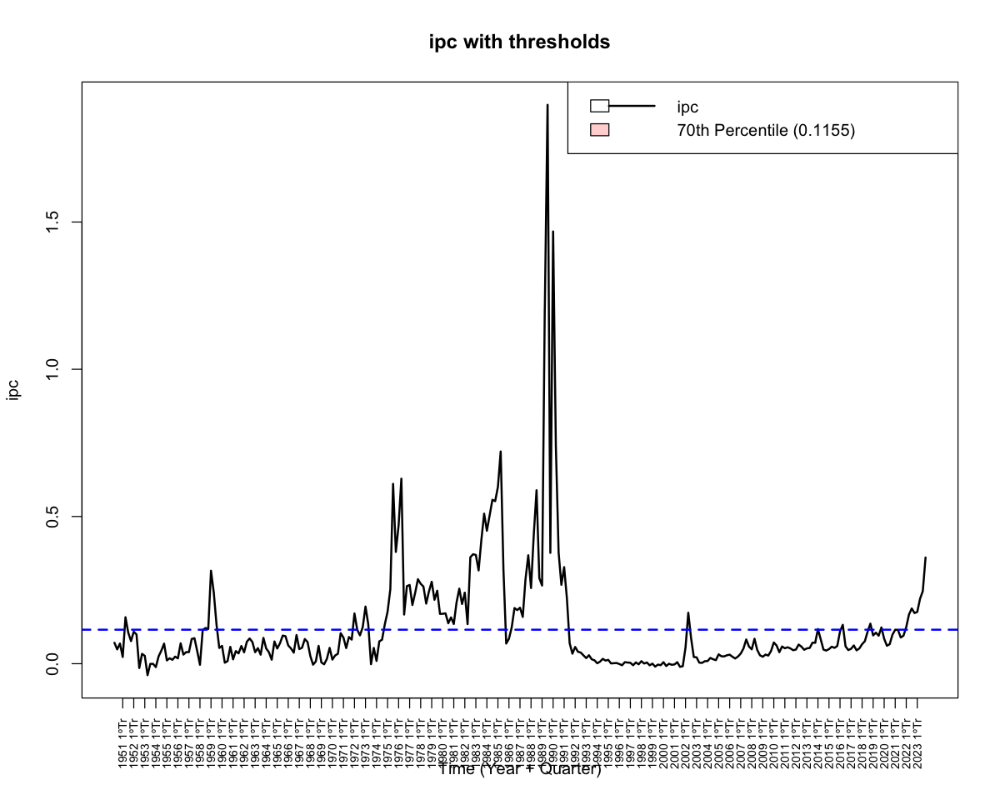

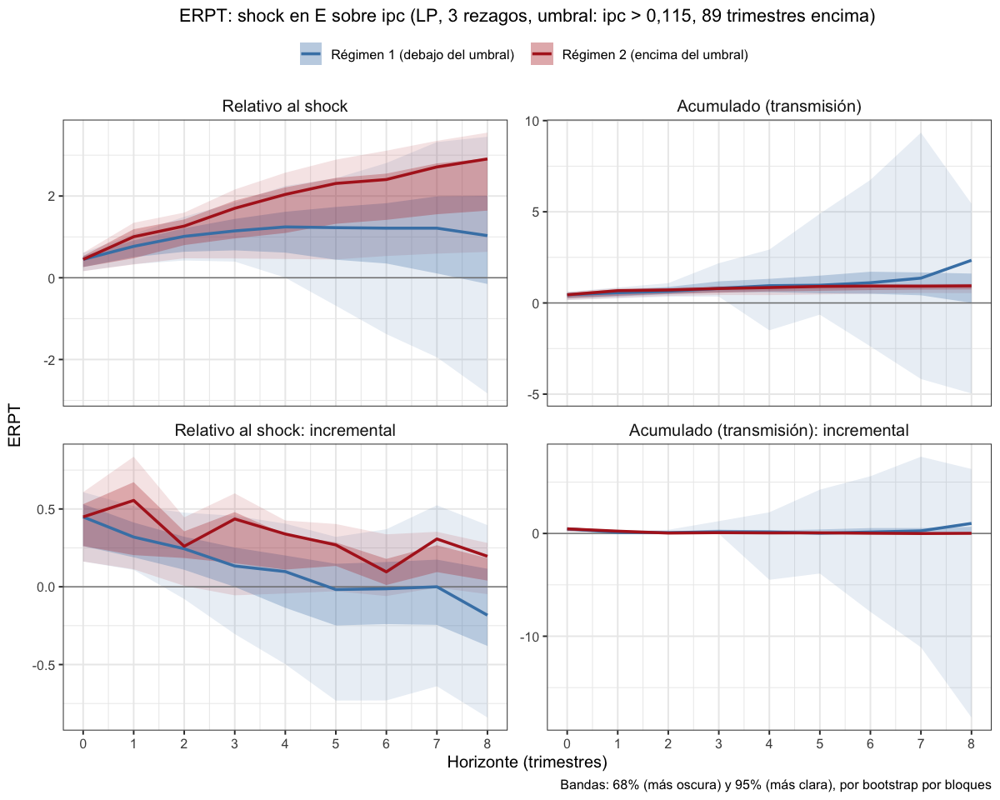

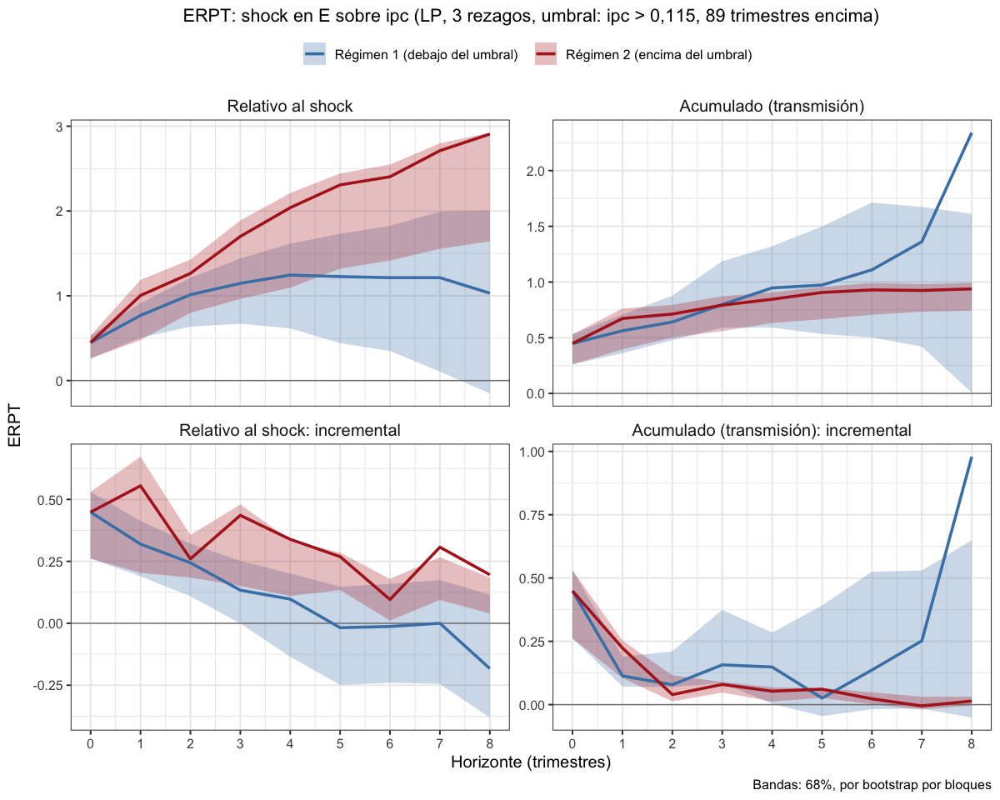

In [13]:
# Todas endógenas con umbral en el percentil 70 del ipc, 3 rezagos
lp_erpt_endog_p3_u70 <- erpt_lp(df_ERPT_Arg, endog = c("impp_usa", "E", "ipc", "pbird"),
                                fixed_lags = 3, horizons = 8, reps = 500,
                                threshold_var = "ipc", upper_threshold = 0.7)
saveRDS(lp_erpt_endog_p3_u70, "lp_erpt_endog_p3_u70.rds")
graficar_erpt_lp(lp_erpt_endog_p3_u70, archivo = "lp_erpt_endog_p3_u70")
graficar_erpt_lp(lp_erpt_endog_p3_u70, niveles = 0.68, archivo = "lp_erpt_endog_p3_u70_68")

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<dbl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
3,3,NaN,NA,NA,0,1,0.68,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,295,"impp_usa, E, ipc, pbird",4


Impulse: impp_usa -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,0,-1.4402723,-1.440272258,-1.4402723,-1.4402723,-1.4402723,-1.44027226
2,1,-1.0525914,-1.136740399,-0.9684425,1.7276799,-1.2738668,4.72922671
3,2,-0.8512125,-0.989131818,-0.7132931,2.7617329,0.2069329,5.31653296
4,3,0.1029703,0.002238468,0.2037022,-1.5031246,-3.0527079,0.04645875
5,4,0.5618939,0.134240403,0.9895474,1.7345509,-0.4948520,3.96395376
6,5,0.9565885,0.491836700,1.4213402,2.0900506,0.5860372,3.59406400
7,6,1.1802838,0.750408561,1.6101590,-0.1470464,-1.9528228,1.65873012
8,7,1.3720086,0.866923726,1.8770934,3.4403326,2.0066495,4.87401563
9,8,0.9228672,0.805206782,1.0405277,4.9269565,3.0824061,6.77150691


Impulse: impp_usa -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
10,0,-0.5899488,-0.58994884,-0.5899488,-0.5899488,-0.58994884,-0.5899488
11,1,-0.4577882,-0.42153708,-0.4940394,1.3421700,0.05595322,2.6283869
12,2,-0.3871776,-0.40492268,-0.3694325,2.7855886,0.10060350,5.4705738
13,3,-0.1269955,-0.13975014,-0.1142409,0.1069801,-1.08346612,1.2974262
14,4,0.1013906,0.07105015,0.1317310,2.4085572,0.48051927,4.3365951
15,5,0.2256820,0.08050541,0.3708585,2.4470178,0.70111513,4.1929205
16,6,0.5489513,0.15116235,0.9467402,0.5707823,-0.69637559,1.8379402
17,7,0.7184364,0.40641989,1.0304529,2.0580071,1.10425180,3.0117625
18,8,0.8962638,0.64277789,1.1497498,3.3830670,1.89716036,4.8689737


... (16 outputs left out)

Impulse: pbird -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
91,0,0.0000000,0.0000000,0.00000000,0.0000000,0.0000000,0.0000000
92,1,-0.5719774,-0.8965907,-0.24736410,-1.6241781,-2.7655301,-0.4828262
93,2,-0.8532011,-1.3398091,-0.36659314,0.3394115,-0.7784178,1.4572409
94,3,-0.5913381,-0.9657578,-0.21691836,-0.3365918,-1.7412734,1.0680898
95,4,-0.4111950,-0.7749736,-0.04741643,-0.3583553,-1.8707388,1.1540283
96,5,0.2014966,-0.2711701,0.67416334,0.4735477,-0.7657025,1.7127979
97,6,-0.3656591,-0.6982999,-0.03301841,-2.5435660,-4.3226163,-0.7645158
98,7,-0.5497227,-1.0054641,-0.09398137,-0.6566066,-1.7679535,0.4547404
99,8,-0.7323382,-1.0934275,-0.37124888,2.1843635,0.1967718,4.1719553


Impulse: pbird -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
100,0,0.00000000,0.0000000,0.00000000,0.00000000,0.0000000,0.0000000
101,1,0.04429099,-0.0295744,0.11815639,-0.21611382,-0.9559002,0.5236725
102,2,-0.15880633,-0.2840157,-0.03359697,0.27635646,-0.5034440,1.0561569
103,3,-0.19984067,-0.3477887,-0.05189261,-0.03641637,-1.1827942,1.1099615
104,4,-0.24720957,-0.4327235,-0.06169567,0.06565864,-1.1126006,1.2439179
105,5,-0.18808746,-0.3988448,0.02266986,0.10415097,-0.8849086,1.0932106
106,6,-0.21854079,-0.4562005,0.01911889,-0.76656725,-1.9226785,0.3895440
107,7,-0.20616138,-0.4366046,0.02428184,-1.30883533,-2.4797262,-0.1379444
108,8,-0.29033748,-0.5584847,-0.02219023,1.59380974,0.1495968,3.0380226


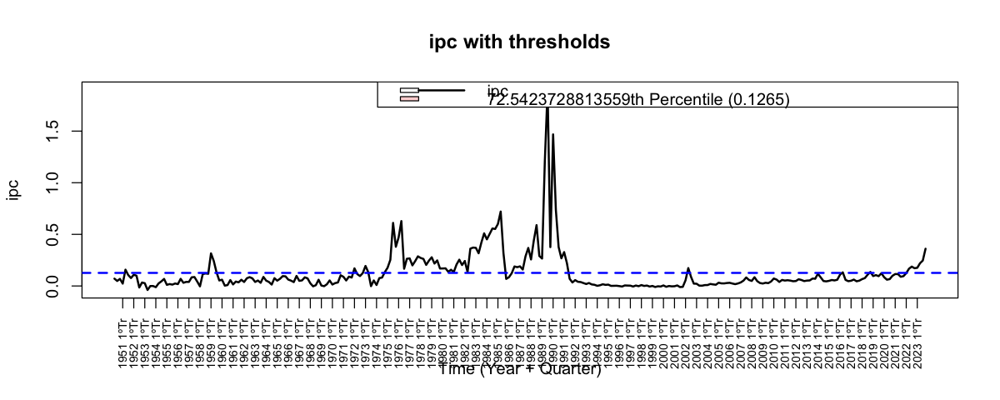

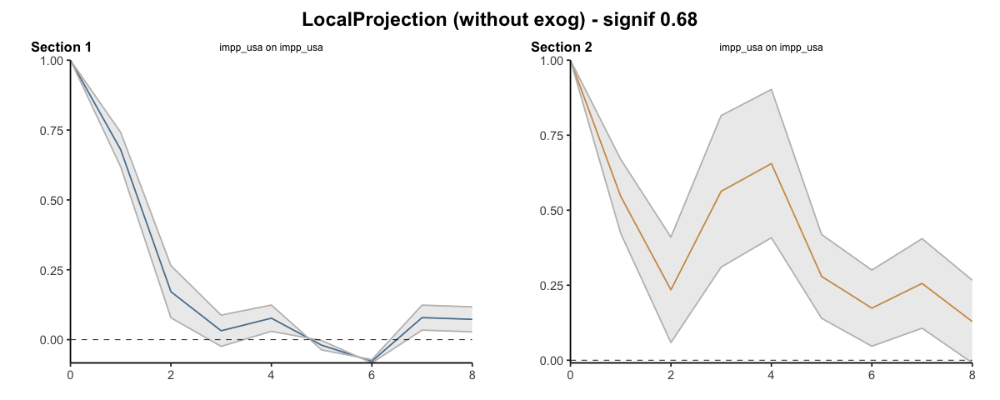

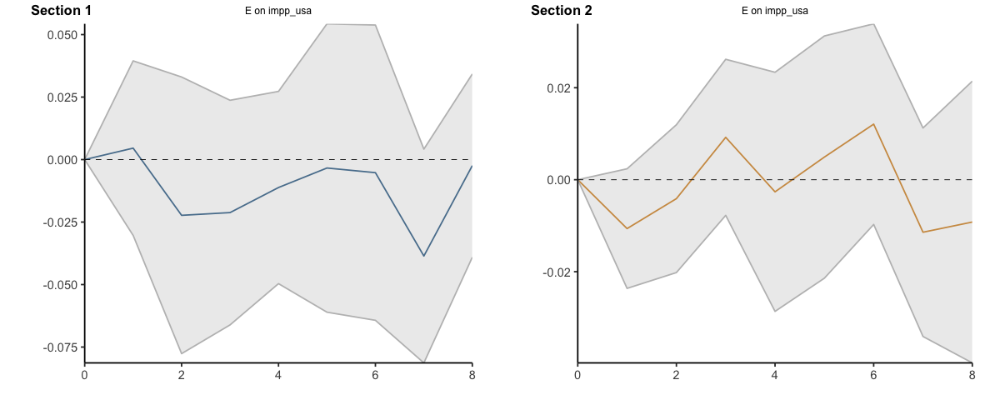

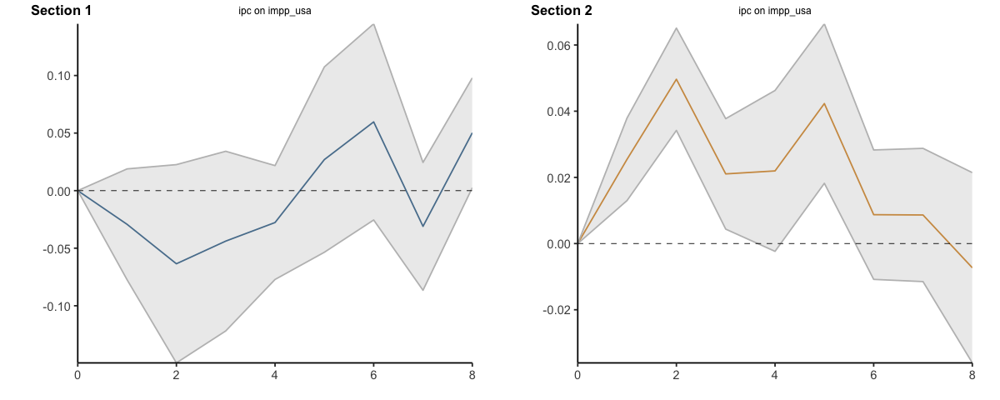

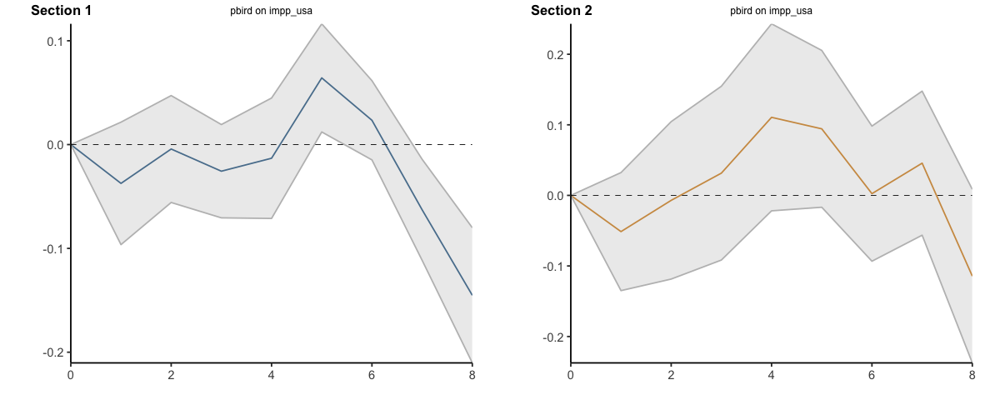

...

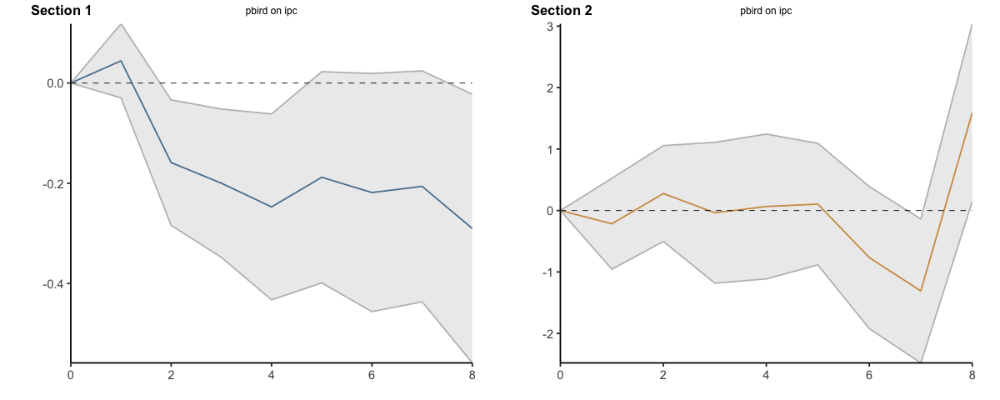

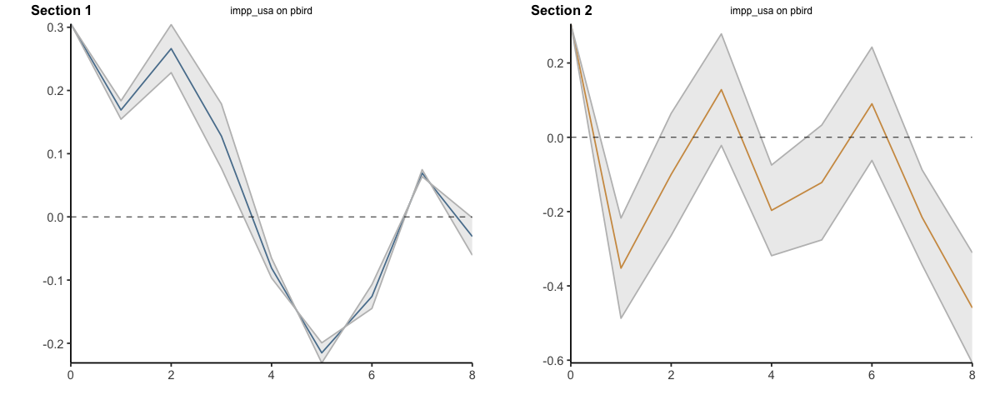

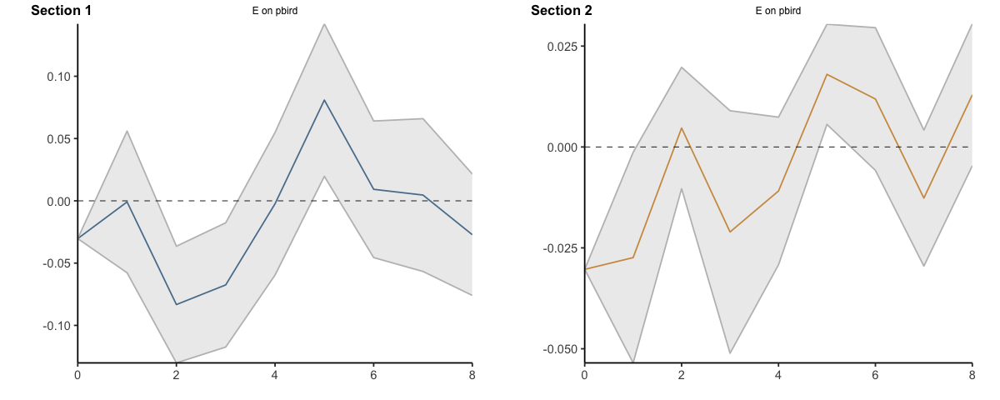

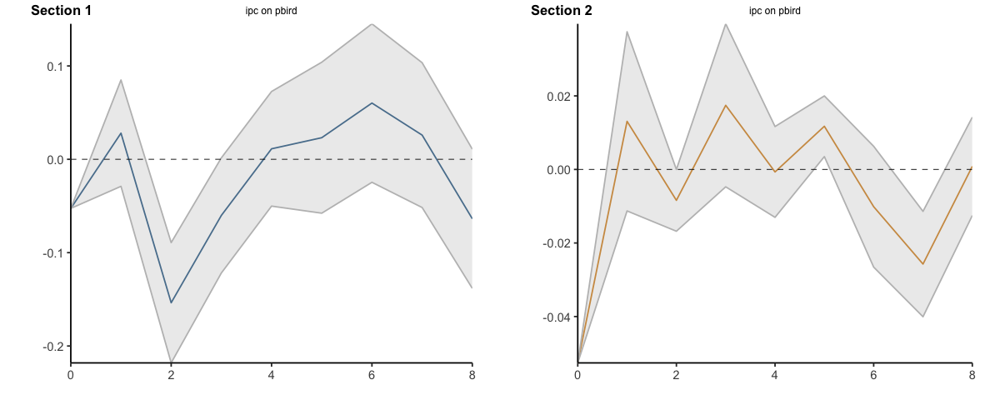

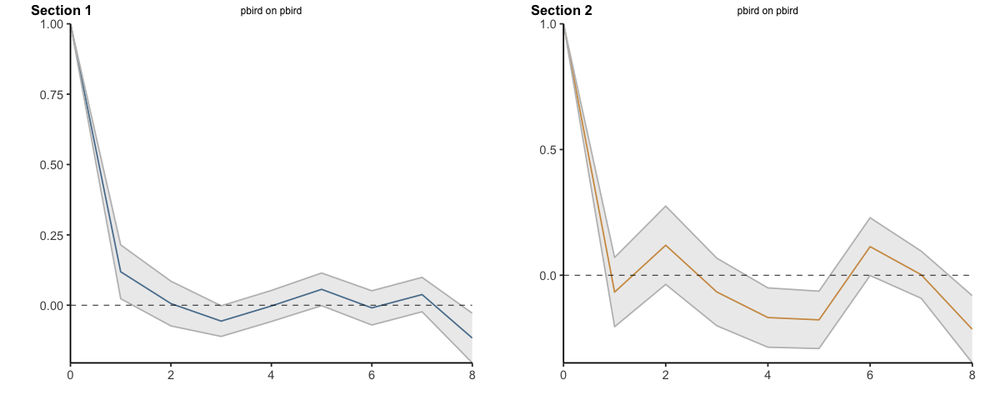

In [14]:
res <- run_lp_model(df_ERPT_Arg, endog=c("impp_usa", "E", "ipc", "pbird"), fixed_lags = 3, horizons=8, signif = 0.68, threshold_var = 'ipc', upper_threshold=0.725423728813559)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<dbl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
3,3,NaN,NA,NA,0,1,0.68,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,295,"impp_usa, E, ipc, pbird",4


Impulse: impp_usa -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,0,-1.4402723,-1.4402723,-1.4402723,-1.4402723,-1.440272,-1.440272
2,1,-2.4928637,-2.5770127,-2.4087147,0.2874077,-2.714139,3.288954
3,2,-3.3440762,-3.5661445,-3.1220079,3.0491406,-2.507206,8.605487
4,3,-3.2411058,-3.5639060,-2.9183057,1.5460160,-5.559914,8.651946
5,4,-2.6792119,-3.4296656,-1.9287583,3.2805669,-6.054766,12.615900
6,5,-1.7226235,-2.9378289,-0.5074181,5.3706175,-5.468729,16.209964
7,6,-0.5423397,-2.1874203,1.1027409,5.2235712,-7.421552,17.868694
8,7,0.8296689,-1.3204966,2.9798343,8.6639037,-5.414902,22.742710
9,8,1.7525361,-0.5152898,4.0203620,13.5908602,-2.332496,29.514217


Impulse: impp_usa -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
10,0,-0.5899488,-0.5899488,-0.5899488,-0.5899488,-0.58994884,-0.5899488
11,1,-1.0477371,-1.0114859,-1.0839882,0.7522212,-0.53399562,2.0384380
12,2,-1.4349147,-1.4164086,-1.4534208,3.5378098,-0.43339212,7.5090118
13,3,-1.5619102,-1.5561587,-1.5676617,3.6447899,-1.51685824,8.8064380
14,4,-1.4605197,-1.4851086,-1.4359307,6.0533471,-1.03633897,13.1430332
15,5,-1.2348377,-1.4046032,-1.0650722,8.5003649,-0.33522384,17.3359537
16,6,-0.6858864,-1.2534408,-0.1183320,9.0711473,-1.03159943,19.1738939
17,7,0.0325500,-0.8470209,0.9121210,11.1291544,0.07265237,22.1856564
18,8,0.9288139,-0.2042431,2.0618708,14.5122214,1.96981274,27.0546301


... (16 outputs left out)

Impulse: pbird -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
91,0,0.0000000,0.0000000,0.0000000,0.000000,0.000000,0.0000000
92,1,-0.5719774,-0.8965907,-0.2473641,-1.624178,-2.765530,-0.4828262
93,2,-1.4251785,-2.2363998,-0.6139572,-1.284767,-3.543948,0.9744147
94,3,-2.0165166,-3.2021576,-0.8308756,-1.621358,-5.285221,2.0425044
95,4,-2.4277116,-3.9771312,-0.8782920,-1.979714,-7.155960,3.1965327
96,5,-2.2262150,-4.2483013,-0.2041287,-1.506166,-7.921663,4.9093306
97,6,-2.5918741,-4.9466011,-0.2371471,-4.049732,-12.244279,4.1448148
98,7,-3.1415969,-5.9520652,-0.3311285,-4.706339,-14.012232,4.5995552
99,8,-3.8739350,-7.0454927,-0.7023774,-2.521975,-13.815461,8.7715105


Impulse: pbird -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
100,0,0.00000000,0.0000000,0.00000000,0.00000000,0.0000000,0.0000000
101,1,0.04429099,-0.0295744,0.11815639,-0.21611382,-0.9559002,0.5236725
102,2,-0.11451533,-0.3135901,0.08455942,0.06024264,-1.4593441,1.5798294
103,3,-0.31435601,-0.6613788,0.03266681,0.02382627,-2.6421383,2.6897909
104,4,-0.56156557,-1.0941023,-0.02902886,0.08948491,-3.7547389,3.9337088
105,5,-0.74965303,-1.4929471,-0.00635900,0.19363588,-4.6396476,5.0269193
106,6,-0.96819382,-1.9491475,0.01275989,-0.57293137,-6.5623261,5.4164633
107,7,-1.17435521,-2.3857521,0.03704173,-1.88176670,-9.0420523,5.2785189
108,8,-1.46469269,-2.9442369,0.01485150,-0.28795696,-8.8924555,8.3165416


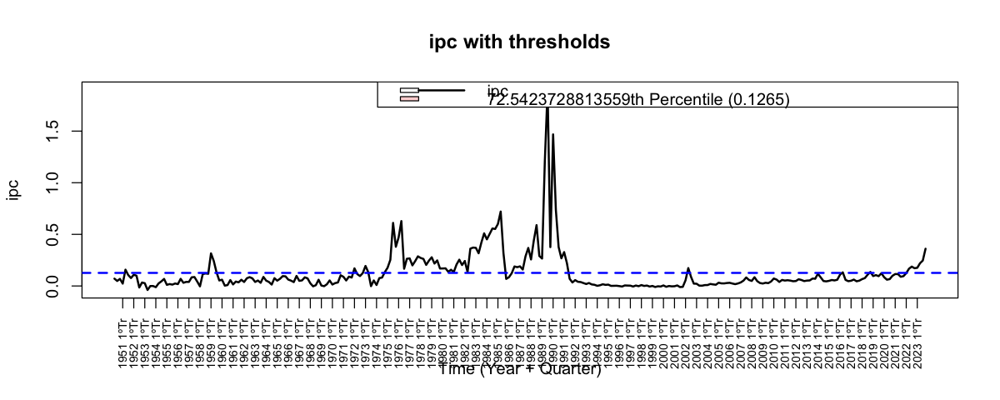

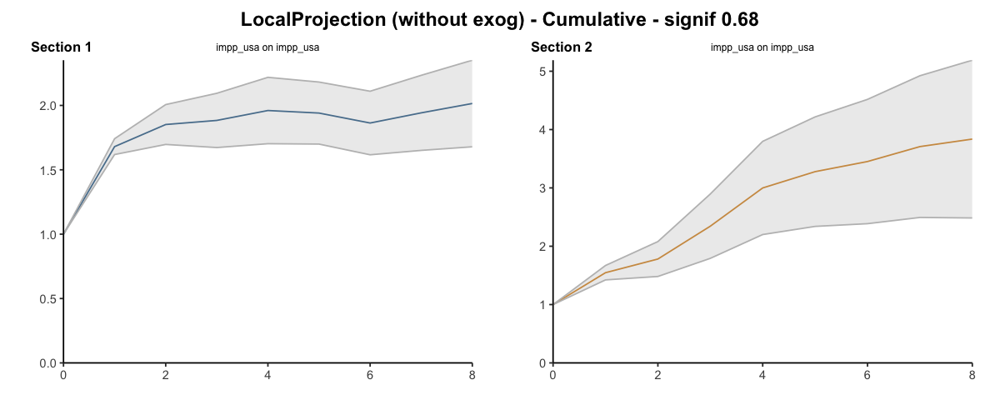

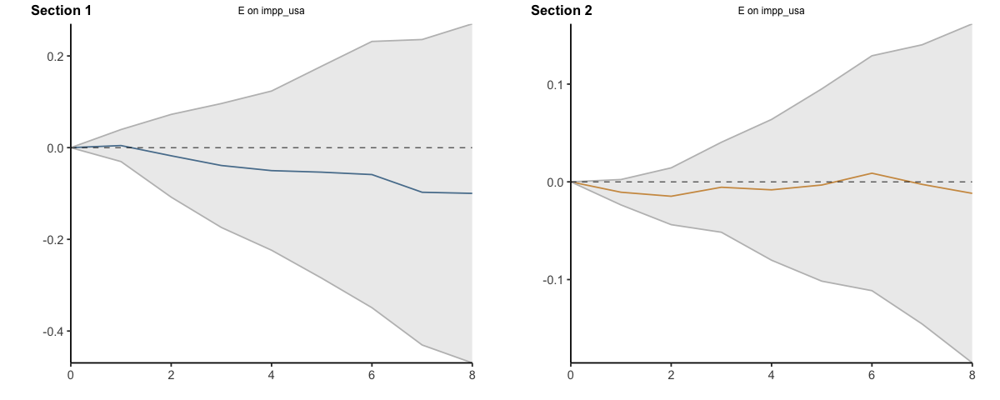

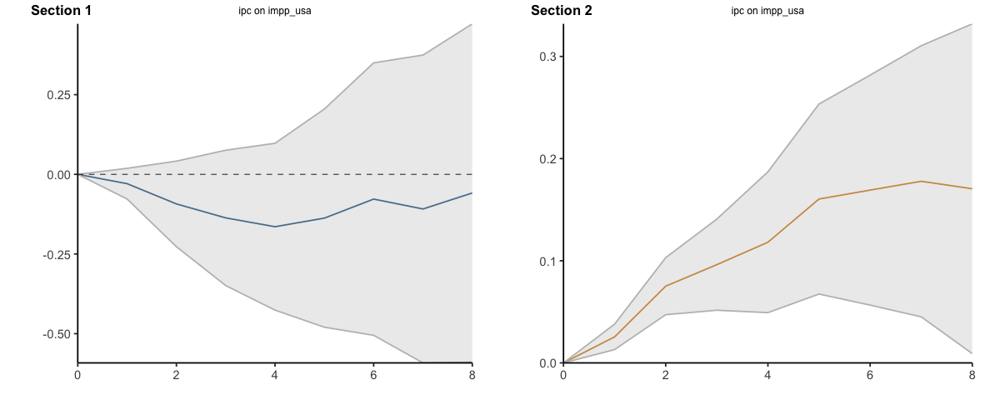

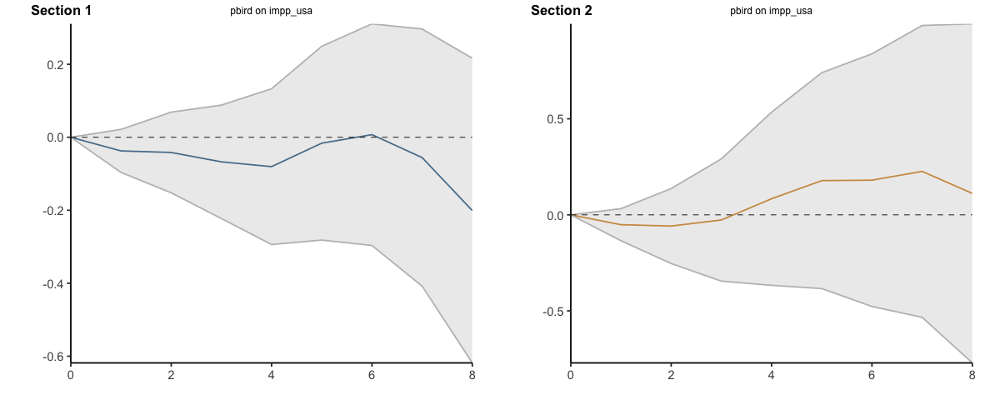

...

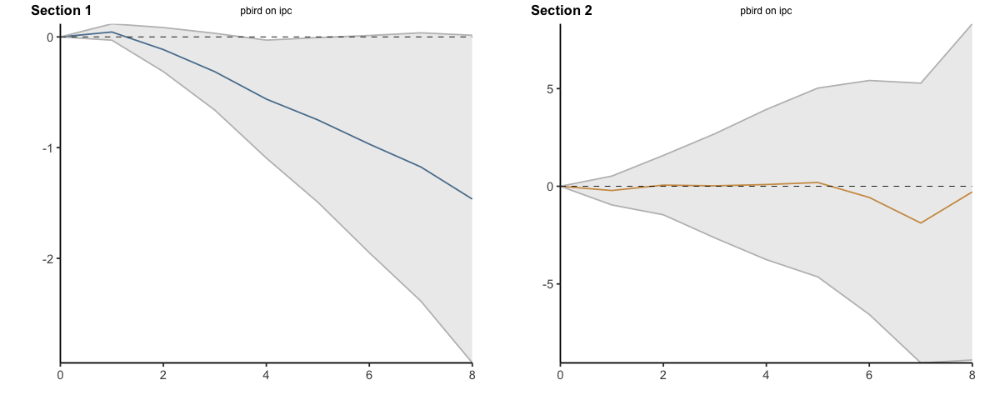

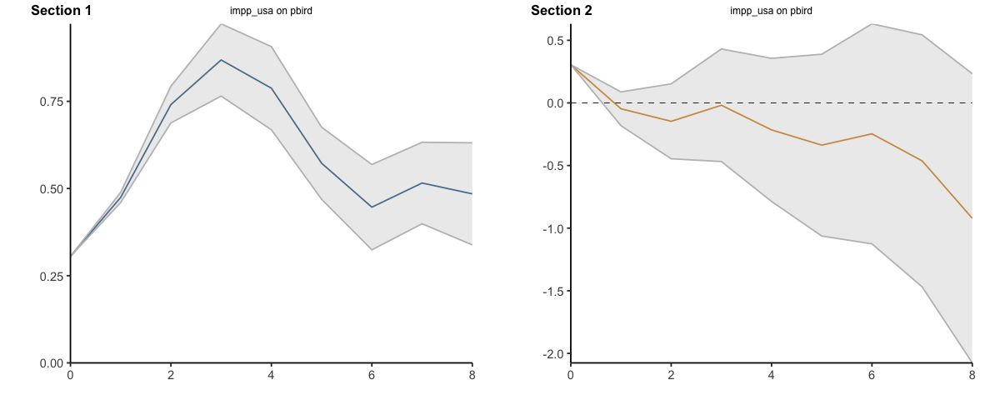

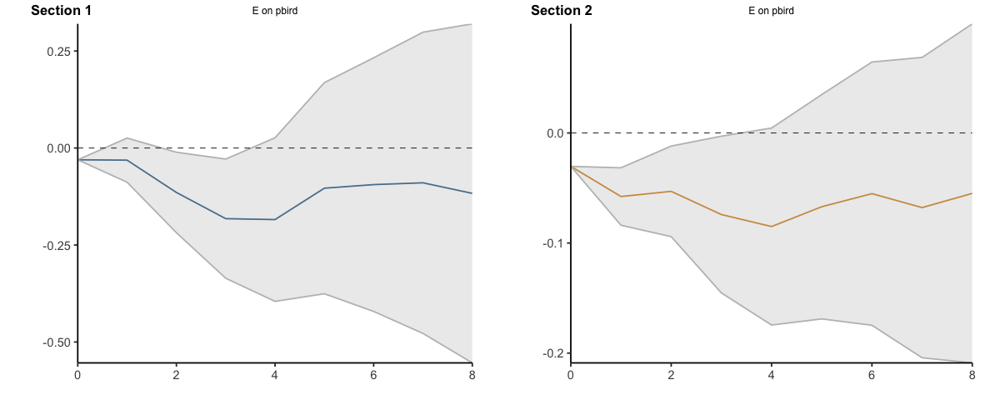

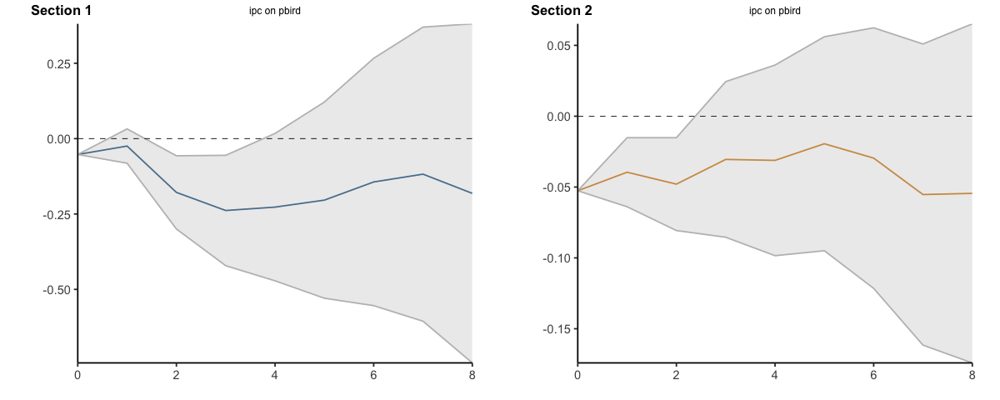

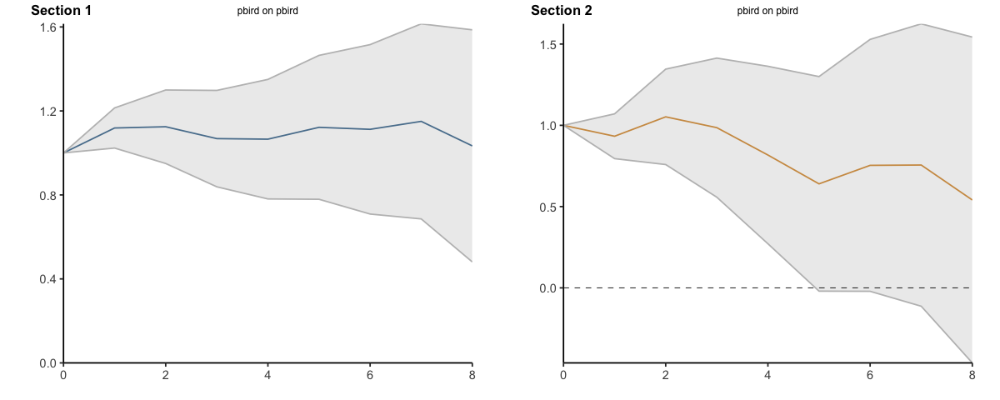

In [15]:
res <- run_lp_model(df_ERPT_Arg, endog=c("impp_usa", "E", "ipc", "pbird"), fixed_lags = 3, horizons=8, signif = 0.68, threshold_var = 'ipc', upper_threshold=0.725423728813559, cumulative=TRUE)

#### Percentile 0.725423728813559 (12,5% inflación trimestral) - quedan 81 trimestres por encima del umbral

Umbral: ipc > 0.1265 (percentil 72.5 )
Trimestres por régimen: debajo del umbral (dummy = 0) = 214 | encima del umbral (dummy = 1) = 81 


Bootstrap por bloques circular: 500 réplicas, bloques de 22 trimestres...



  |======================================================================| 100%


Aviso (Régimen 1 (debajo del umbral)): en más del 5% de las réplicas la depreciación acumulada es casi cero en h = 7; las bandas del ERPT acumulado en esos horizontes son poco confiables.



ERPT de un shock unitario en E sobre ipc ( LP, 3 rezagos, umbral: ipc > 0,127, 81 trimestres encima )

Régimen 1 (debajo del umbral)
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.4489         0.4489       1.0000
         1              0.8368         0.6182       1.3535
         2              1.1457         0.7138       1.6050
         3              1.3042         0.8622       1.5127
         4              1.4158         1.0153       1.3945
         5              1.4500         1.0420       1.3915
         6              1.5009         1.1293       1.3290
         7              1.5440         1.2944       1.1928
         8              1.4580         1.6330       0.8928
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.4489             0.4489
                  0.3879             0.1693
                  0.3089             0.0956
                  0.1585             0.1483
                  0.1117             0.1531
             

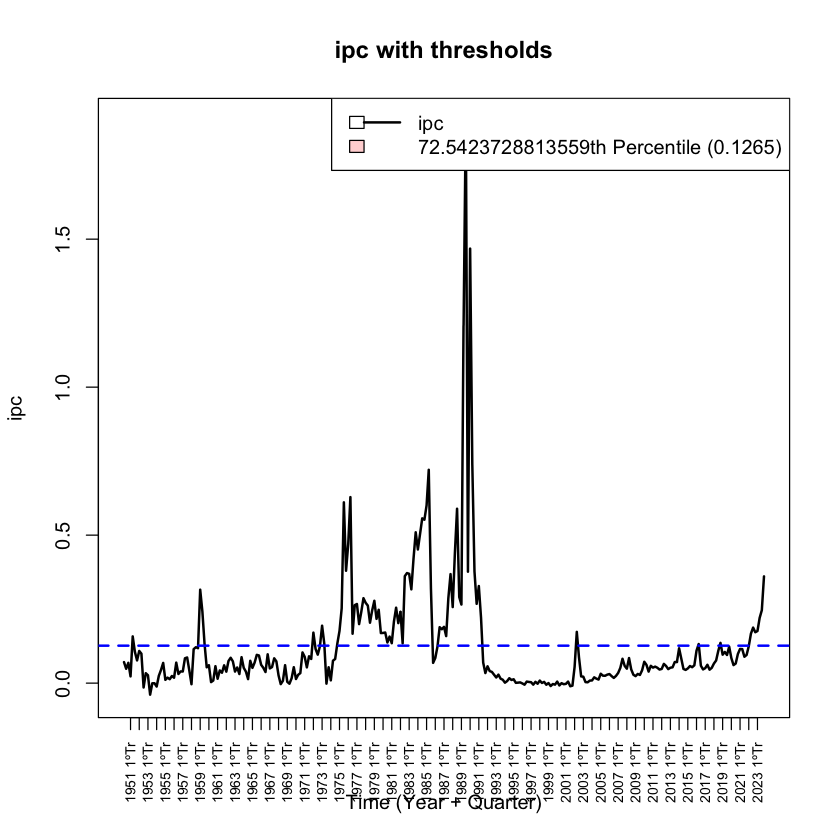

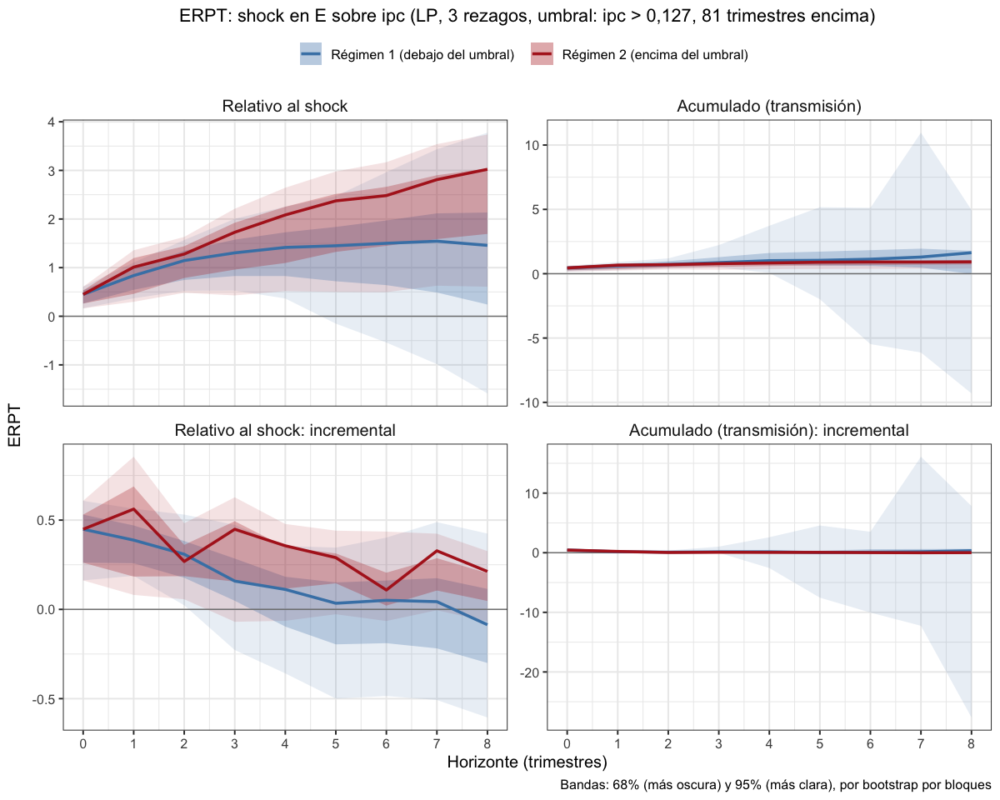

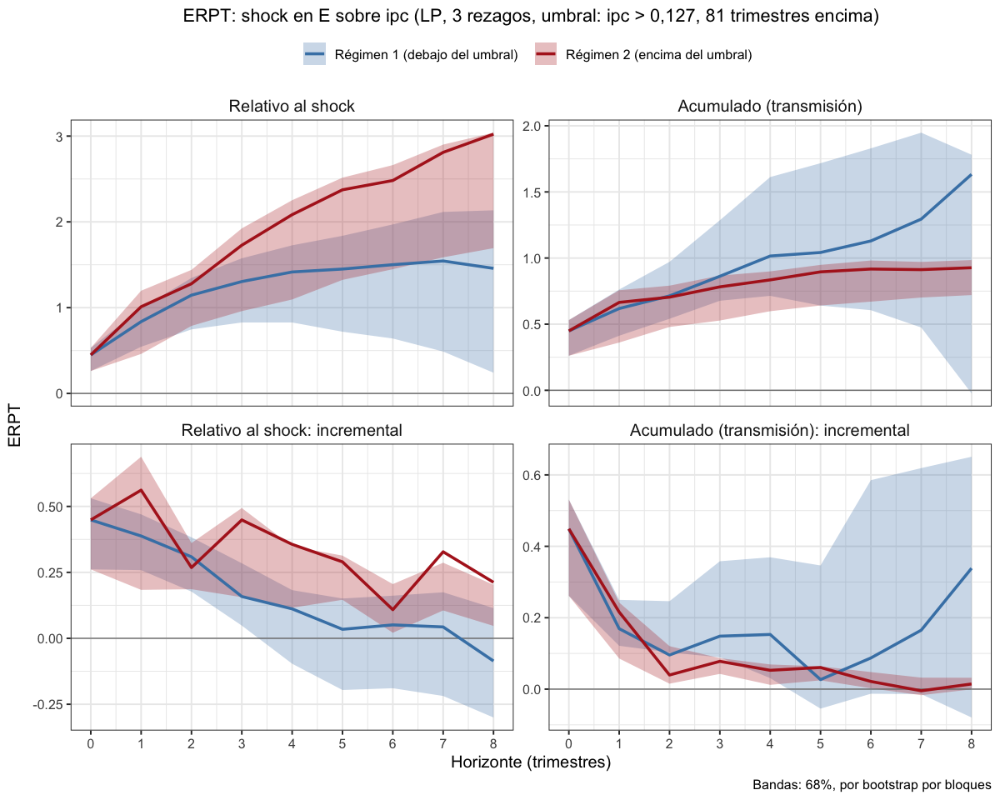

In [6]:
# Todas endógenas con umbral en 12,5% de inflación trimestral (umbral del TVAR), 3 rezagos
lp_erpt_endog_p3_tvar12.5 <- erpt_lp(df_ERPT_Arg, endog = c("impp_usa", "E", "ipc", "pbird"),
                                     fixed_lags = 3, horizons = 8, reps = 500,
                                     threshold_var = "ipc", upper_threshold = 0.725423728813559)
saveRDS(lp_erpt_endog_p3_tvar12.5, "lp_erpt_endog_p3_tvar12.5.rds")
graficar_erpt_lp(lp_erpt_endog_p3_tvar12.5, archivo = "lp_erpt_endog_p3_tvar12.5")
graficar_erpt_lp(lp_erpt_endog_p3_tvar12.5, niveles = 0.68, archivo = "lp_erpt_endog_p3_tvar12.5_68")

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<dbl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
3,3,NaN,NA,NA,0,1,0.68,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,295,"impp_usa, E, ipc, pbird",4


Impulse: impp_usa -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,0,-1.440272258,-1.44027226,-1.44027226,-1.440272,-1.4402723,-1.440272
2,1,-0.638371411,-1.20940534,-0.06733749,-4.373503,-8.5410370,-0.205968
3,2,-0.003285025,-0.41715985,0.41058980,5.976614,3.1567282,8.796500
4,3,-0.291380007,-0.53571729,-0.04704272,21.019245,5.2247401,36.813751
5,4,0.081438760,-0.52634348,0.68922100,29.786733,6.4926536,53.080812
6,5,0.633494256,0.01134221,1.25564630,18.112827,3.2581449,32.967509
7,6,-0.019643503,-0.64092870,0.60164169,12.011490,-1.4795715,25.502552
8,7,0.262323005,-0.07675517,0.60140118,7.389809,-5.0345780,19.814197
9,8,0.715373305,0.45758187,0.97316474,2.706985,-0.6211515,6.035121


Impulse: impp_usa -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
10,0,-0.58994884,-0.5899488,-0.58994884,-0.5899488,-0.5899488,-0.5899488
11,1,-0.23578212,-0.4605941,-0.01097009,1.7142733,-1.8918955,5.3204421
12,2,0.17895674,-0.2351308,0.59304422,7.9033464,6.3019370,9.5047558
13,3,-0.12114149,-0.2597468,0.01746379,7.5203269,-2.4108018,17.4514557
14,4,0.15142828,-0.1658615,0.46871809,25.0039201,3.6338855,46.3739548
15,5,0.11632541,-0.1349429,0.36759371,16.5069884,1.8623232,31.1516537
16,6,-0.08303352,-0.5258267,0.35975968,15.6744764,1.5511749,29.7977779
17,7,-0.40345622,-0.6961064,-0.11080609,13.5160719,-1.3778152,28.4099590
18,8,0.40812973,0.1163971,0.69986236,8.0952719,1.7932494,14.3972943


... (16 outputs left out)

Impulse: pbird -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
91,0,0.0000000,0.0000000,0.00000000,0.000000,0.0000000,0.0000000
92,1,-0.8493013,-1.3104894,-0.38811316,-1.839350,-5.4692282,1.7905275
93,2,-0.5970156,-1.0290450,-0.16498607,1.823451,-0.5111166,4.1580183
94,3,-0.3498811,-0.6958755,-0.00388676,-4.046123,-12.3578831,4.2656378
95,4,-0.2783796,-0.6205846,0.06382531,-15.610481,-30.1645955,-1.0563668
96,5,0.6869644,0.2048051,1.16912363,-6.837559,-15.9323049,2.2571862
97,6,-0.3719955,-0.7823649,0.03837393,-7.032072,-14.5261961,0.4620522
98,7,-0.3076267,-0.6868346,0.07158116,-5.254397,-13.9150044,3.4062107
99,8,0.3144824,-0.1759050,0.80486985,-1.388692,-4.3851384,1.6077539


Impulse: pbird -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
100,0,0.00000000,0.0000000000,0.00000000,0.0000000,0.0000000,0.0000000
101,1,0.06276540,-0.0761943774,0.20172519,0.2413268,-2.5578884,3.0405419
102,2,-0.14075061,-0.3333182024,0.05181699,0.2519673,-0.4462544,0.9501890
103,3,-0.01548484,-0.2053333328,0.17436365,3.9249527,-1.5105319,9.3604372
104,4,-0.05755551,-0.2695503256,0.15443930,-11.0579339,-24.3874869,2.2716190
105,5,0.25030355,0.0004311072,0.50017600,-9.3796907,-18.8771399,0.1177585
106,6,0.10522163,-0.1510771378,0.36152040,-8.6099845,-16.6995407,-0.5204283
107,7,-0.12358347,-0.3900325092,0.14286557,-9.4699499,-19.6201267,0.6802269
108,8,0.59169017,0.1690050727,1.01437526,-4.8758617,-9.5501240,-0.2015994


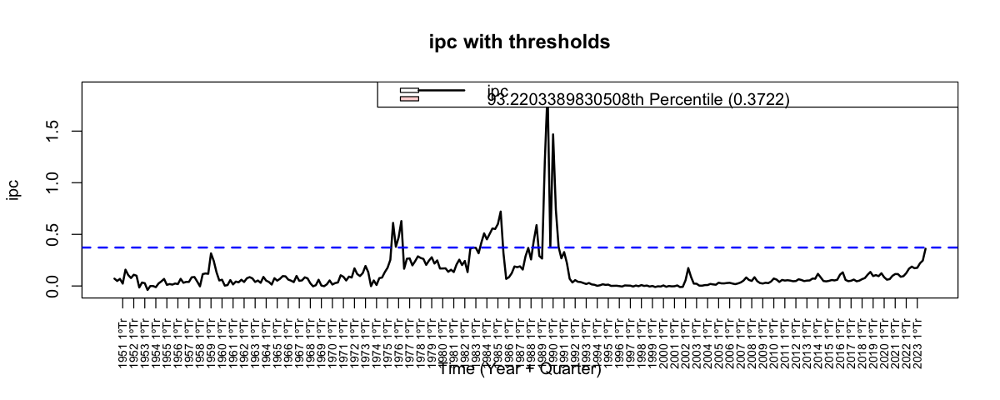

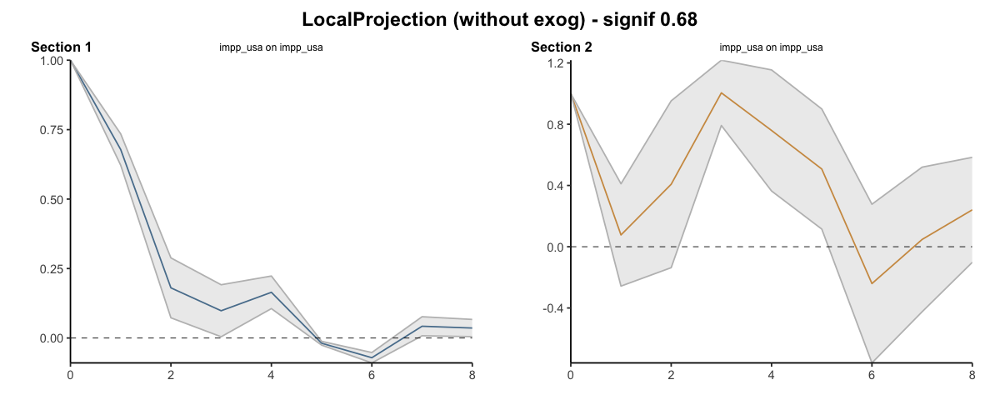

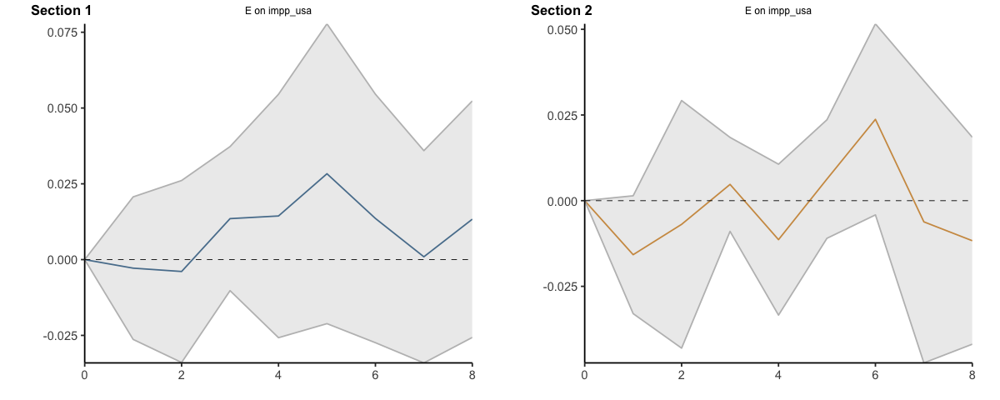

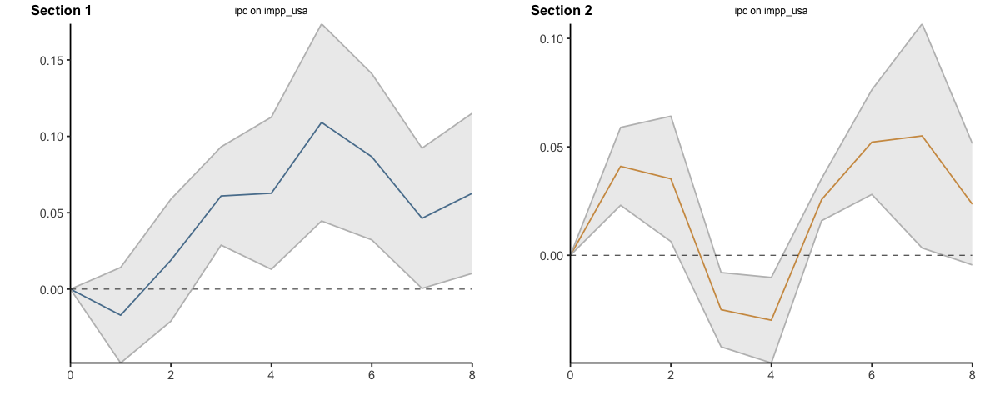

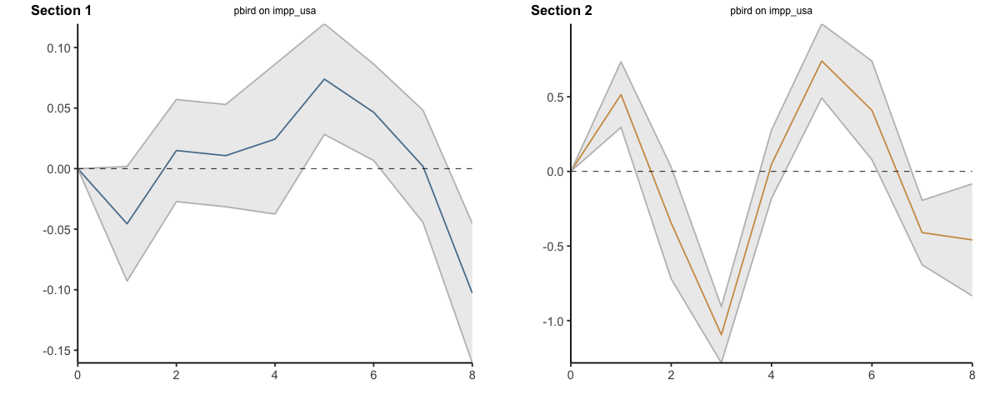

...

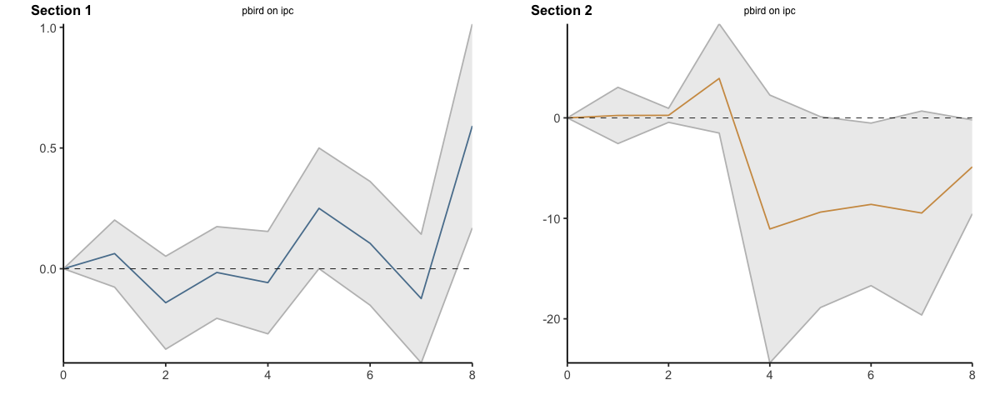

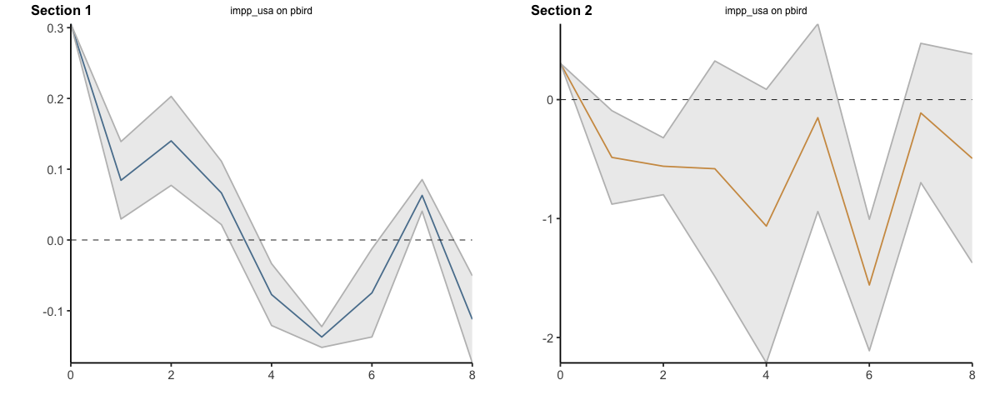

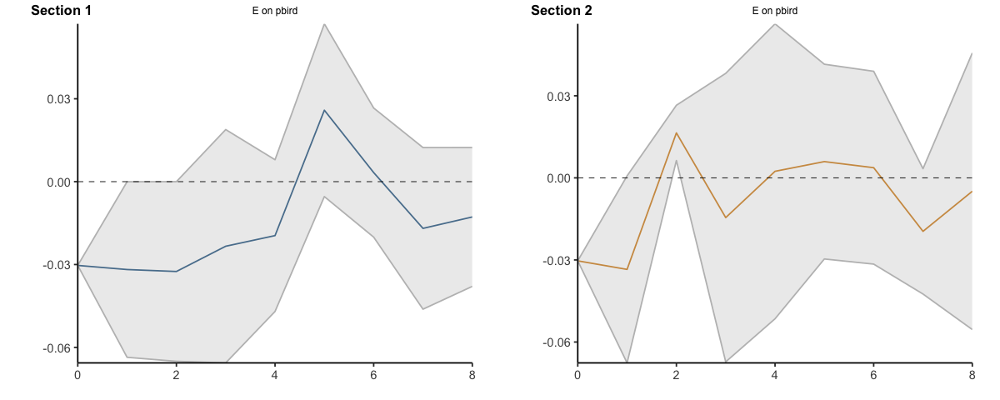

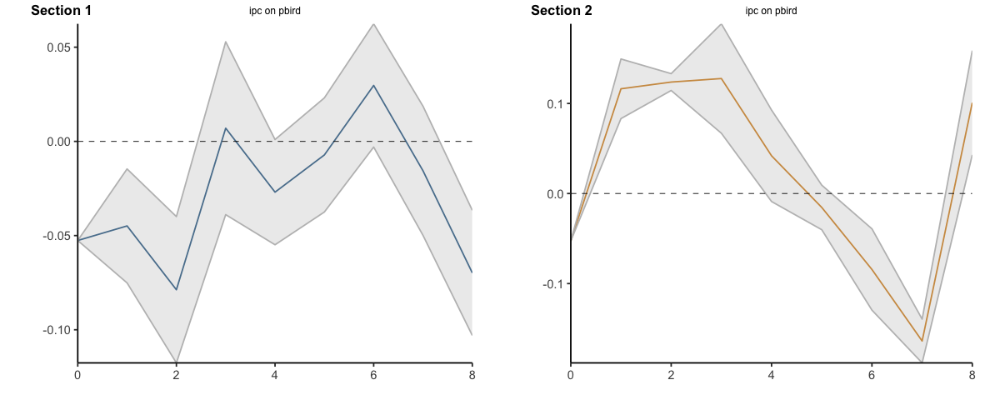

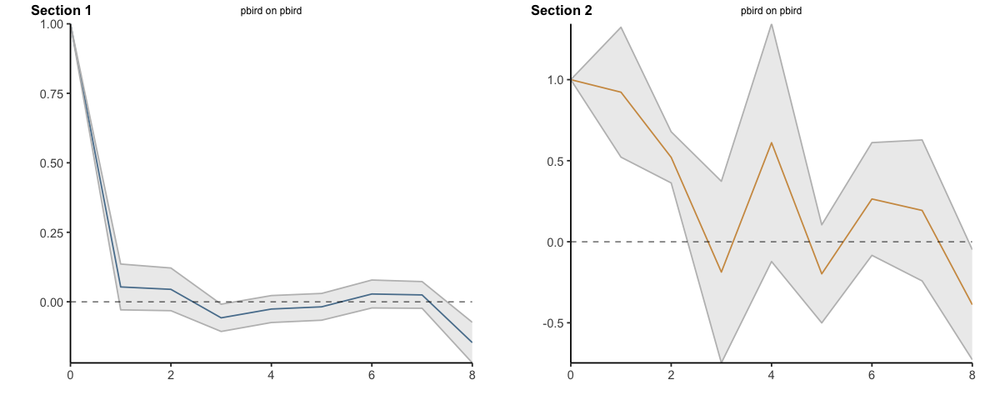

In [16]:
res <- run_lp_model(df_ERPT_Arg, endog=c("impp_usa", "E", "ipc", "pbird"), fixed_lags = 3, horizons=8, signif = 0.68, threshold_var = 'ipc', upper_threshold=0.932203389830508)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<dbl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
3,3,NaN,NA,NA,0,1,0.68,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,295,"impp_usa, E, ipc, pbird",4


Impulse: impp_usa -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,0,-1.4402723,-1.440272,-1.4402723,-1.4402723,-1.440272,-1.440272
2,1,-2.0786437,-2.649678,-1.5076097,-5.8137748,-9.981309,-1.646240
3,2,-2.0819287,-3.066837,-1.0970199,0.1628395,-6.824581,7.150260
4,3,-2.3733087,-3.602555,-1.1440627,21.1820849,-1.599841,43.964011
5,4,-2.2918699,-4.128898,-0.4548417,50.9688179,4.892813,97.044823
6,5,-1.6583757,-4.117556,0.8008046,69.0816447,8.150958,130.012332
7,6,-1.6780192,-4.758485,1.4024463,81.0931352,6.671386,155.514884
8,7,-1.4156962,-4.835240,2.0038475,88.4829445,1.636808,175.329081
9,8,-0.7003229,-4.377658,2.9770122,91.1899291,1.015657,181.364202


Impulse: impp_usa -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
10,0,-0.5899488,-0.5899488,-0.589948844,-0.5899488,-0.5899488,-0.5899488
11,1,-0.8257310,-1.0505430,-0.600918937,1.1243244,-2.4818444,4.7304933
12,2,-0.6467742,-1.2856737,-0.007874716,9.0276709,3.8200926,14.2352491
13,3,-0.7679157,-1.5454205,0.009589075,16.5479978,1.4092908,31.6867048
14,4,-0.6164874,-1.7112821,0.478307166,41.5519179,5.0431762,78.0606596
15,5,-0.5001620,-1.8462249,0.845900874,58.0589063,6.9054994,109.2123133
16,6,-0.5831956,-2.3720517,1.205660556,73.7333827,8.4566743,139.0100912
17,7,-0.9866518,-3.0681580,1.094854465,87.2494546,7.0788591,167.4200502
18,8,-0.5785220,-2.9517609,1.794716825,95.3447265,8.8721085,181.8173445


... (16 outputs left out)

Impulse: pbird -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
91,0,0.0000000,0.000000,0.0000000,0.0000000,0.000000,0.000000
92,1,-0.8493013,-1.310489,-0.3881132,-1.8393503,-5.469228,1.790527
93,2,-1.4463168,-2.339534,-0.5530992,-0.0158995,-5.980345,5.948546
94,3,-1.7961979,-3.035410,-0.5569860,-4.0620221,-18.338228,10.214184
95,4,-2.0745776,-3.655995,-0.4931607,-19.6725033,-48.502823,9.157817
96,5,-1.3876132,-3.451189,0.6759629,-26.5100626,-64.435128,11.415003
97,6,-1.7596087,-4.233554,0.7143369,-33.5421346,-78.961324,11.877055
98,7,-2.0672355,-4.920389,0.7859180,-38.7965314,-92.876329,15.283266
99,8,-1.7527530,-5.096294,1.5907879,-40.1852237,-97.261467,16.891020


Impulse: pbird -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
100,0,0.00000000,0.00000000,0.0000000,0.0000000,0.000000,0.000000
101,1,0.06276540,-0.07619438,0.2017252,0.2413268,-2.557888,3.040542
102,2,-0.07798520,-0.40951258,0.2535422,0.4932941,-3.004143,3.990731
103,3,-0.09347004,-0.61484591,0.4279058,4.4182467,-4.514675,13.351168
104,4,-0.15102555,-0.88439624,0.5823451,-6.6396872,-28.902162,15.622787
105,5,0.09927800,-0.88396513,1.0825211,-16.0193779,-47.779301,15.740546
106,6,0.20449963,-1.03504227,1.4440415,-24.6293624,-64.478842,15.220117
107,7,0.08091616,-1.42507478,1.5869071,-34.0993123,-84.098969,15.900344
108,8,0.67260633,-1.25606971,2.6012824,-38.9751740,-93.649093,15.698745


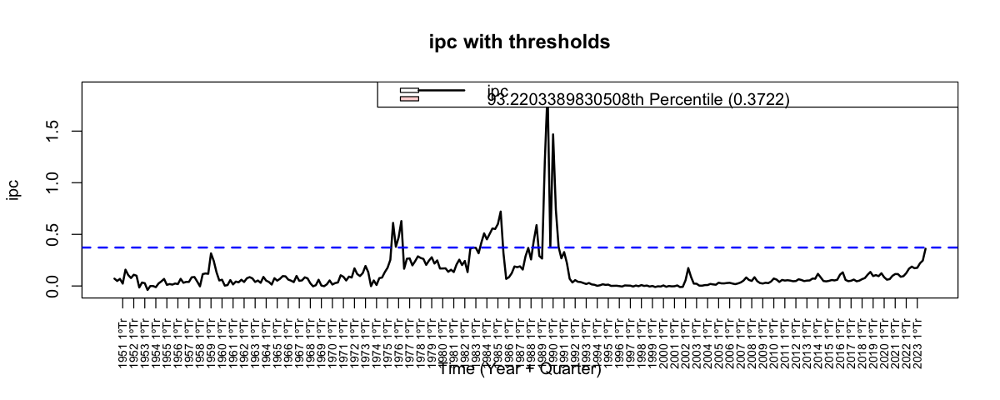

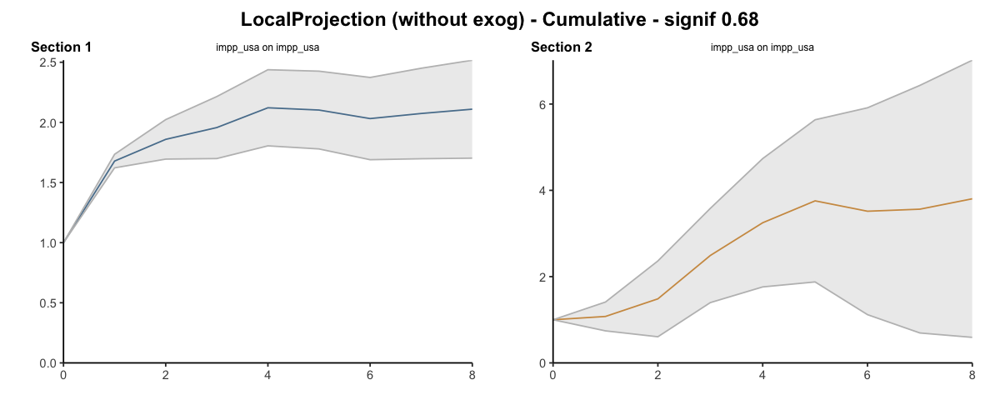

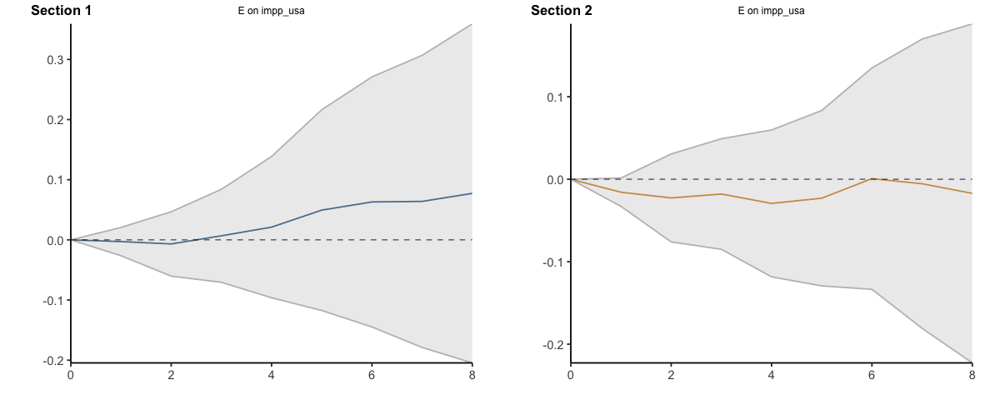

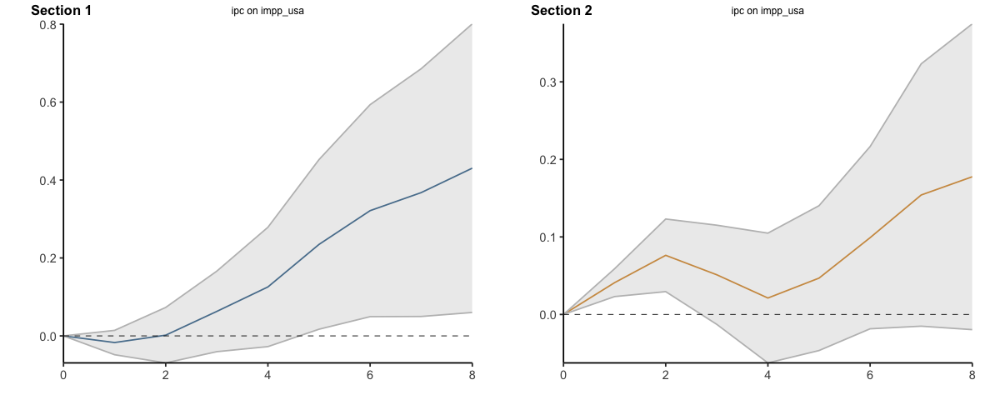

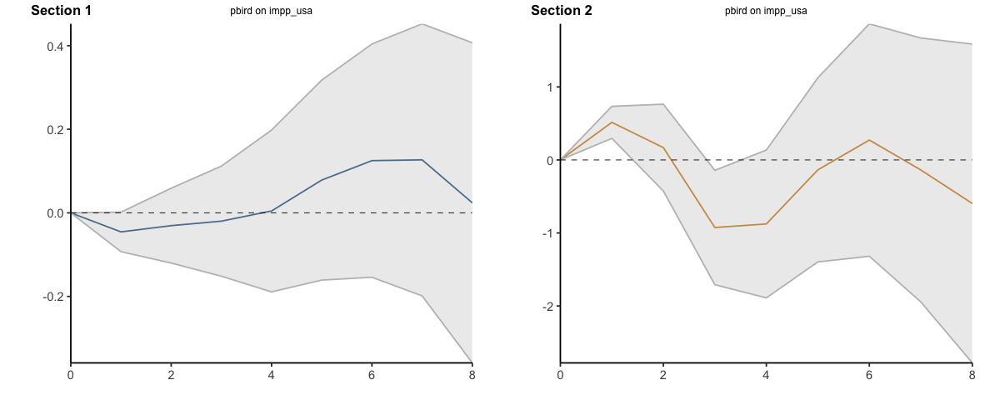

...

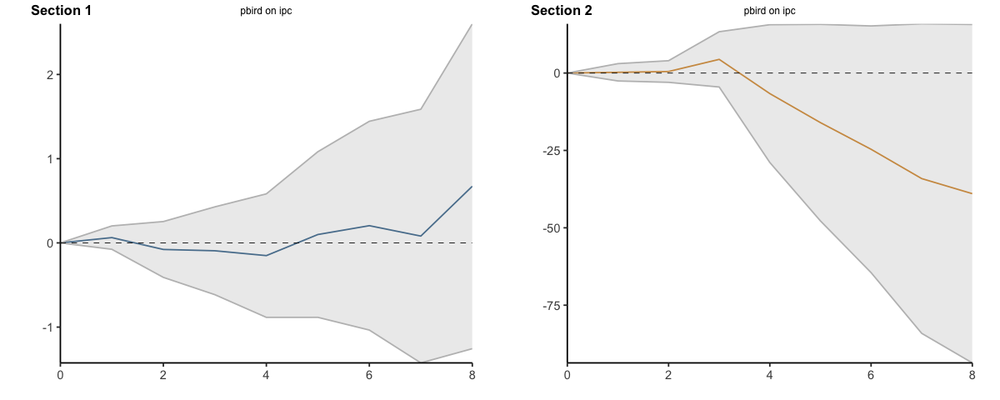

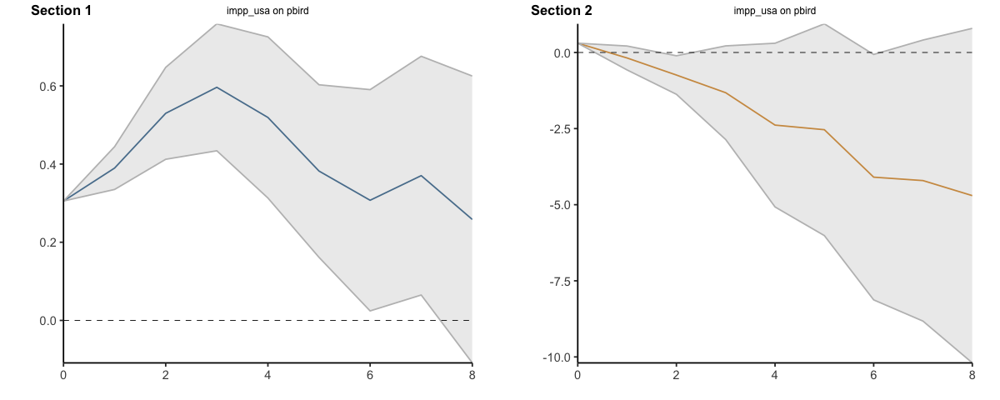

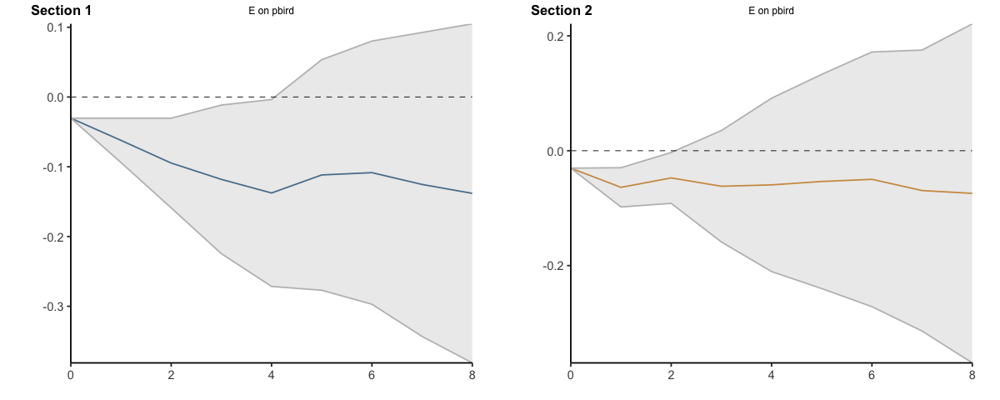

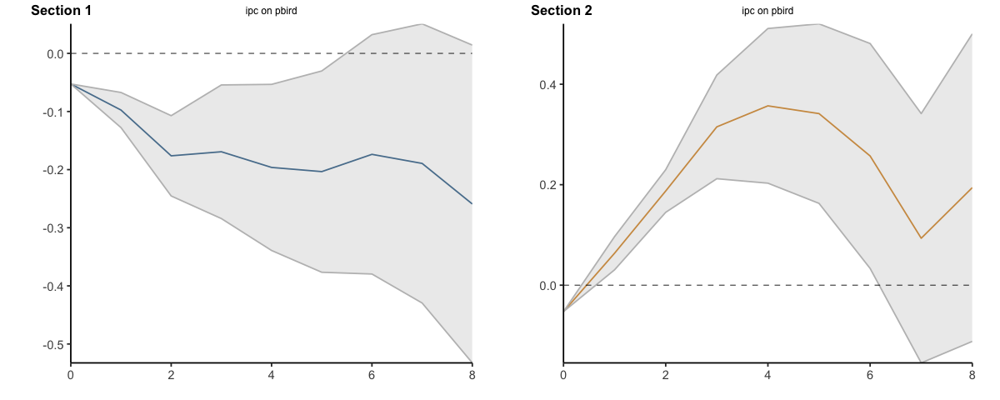

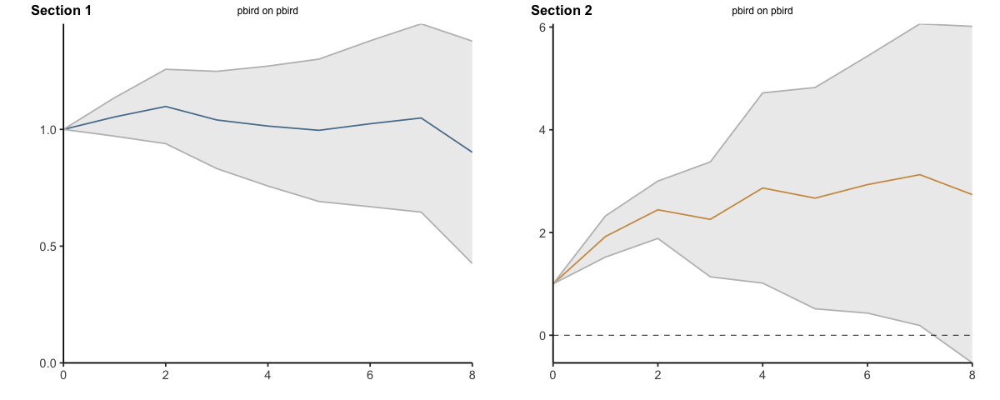

In [17]:
res <- run_lp_model(df_ERPT_Arg, endog=c("impp_usa", "E", "ipc", "pbird"), fixed_lags = 3, horizons=8, signif = 0.68, threshold_var = 'ipc', upper_threshold=0.932203389830508, cumulative = TRUE)

#### Percentile 0.932203389830508 (37,6% de inflación trimestral) - quedan 20 trimestres por encima del umbral (son pocos)

Umbral: ipc > 0.3722 (percentil 93.2 )
Trimestres por régimen: debajo del umbral (dummy = 0) = 275 | encima del umbral (dummy = 1) = 20 


Bootstrap por bloques circular: 500 réplicas, bloques de 22 trimestres...



  |======================================================================| 100%


15 réplicas fallaron y se descartaron.



ERPT de un shock unitario en E sobre ipc ( LP, 3 rezagos, umbral: ipc > 0,372, 20 trimestres encima )

Régimen 1 (debajo del umbral)
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.4489         0.4489       1.0000
         1              0.8917         0.5837       1.5277
         2              1.2815         0.6940       1.8465
         3              1.5802         0.7642       2.0679
         4              1.9986         0.8509       2.3489
         5              2.2880         0.8922       2.5645
         6              2.6748         0.9062       2.9517
         7              3.3002         0.9245       3.5698
         8              3.7846         0.9363       4.0419
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.4489             0.4489
                  0.4428             0.1348
                  0.3898             0.1103
                  0.2987             0.0701
                  0.4184             0.0867
             

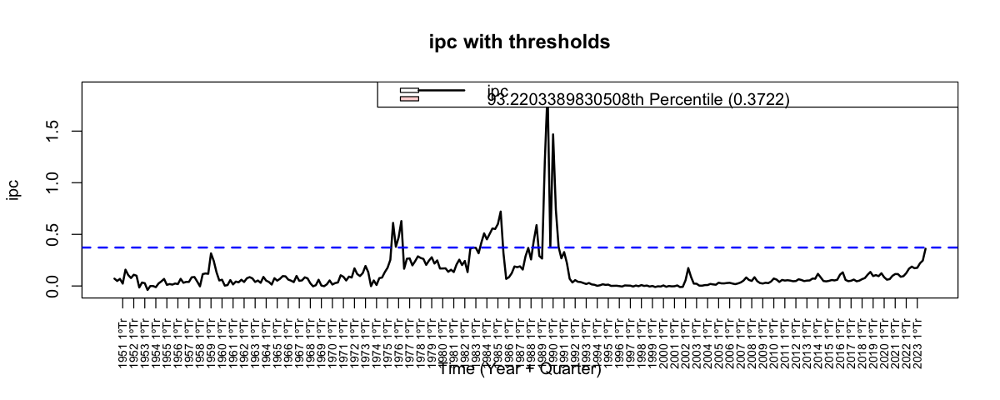

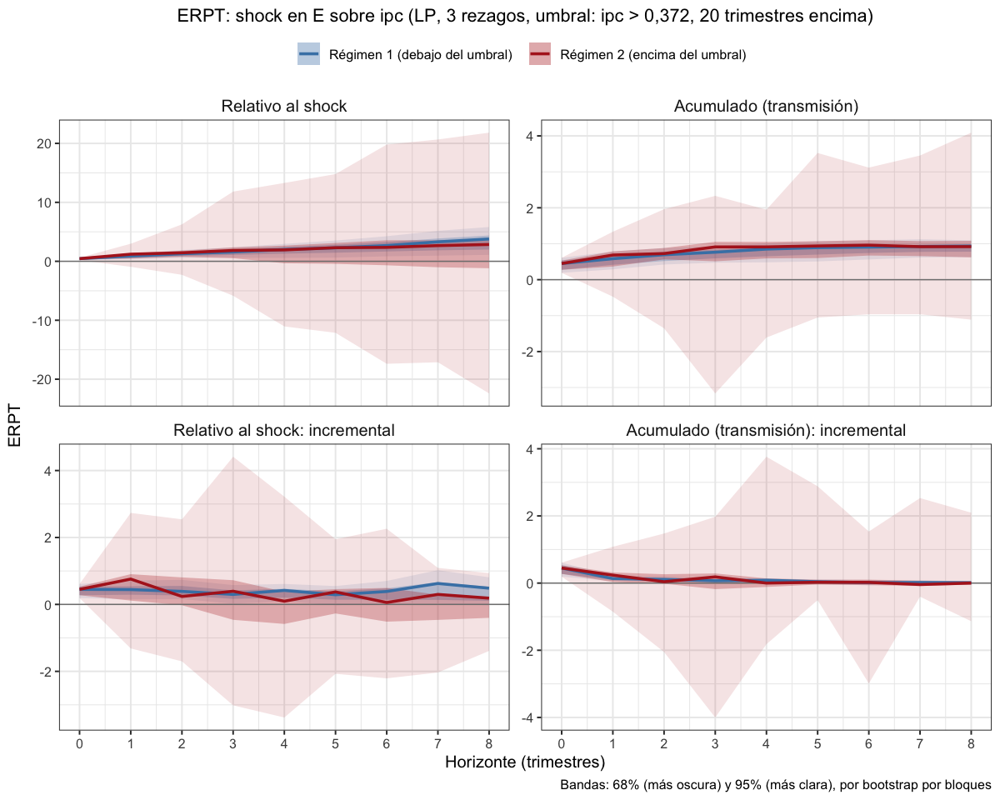

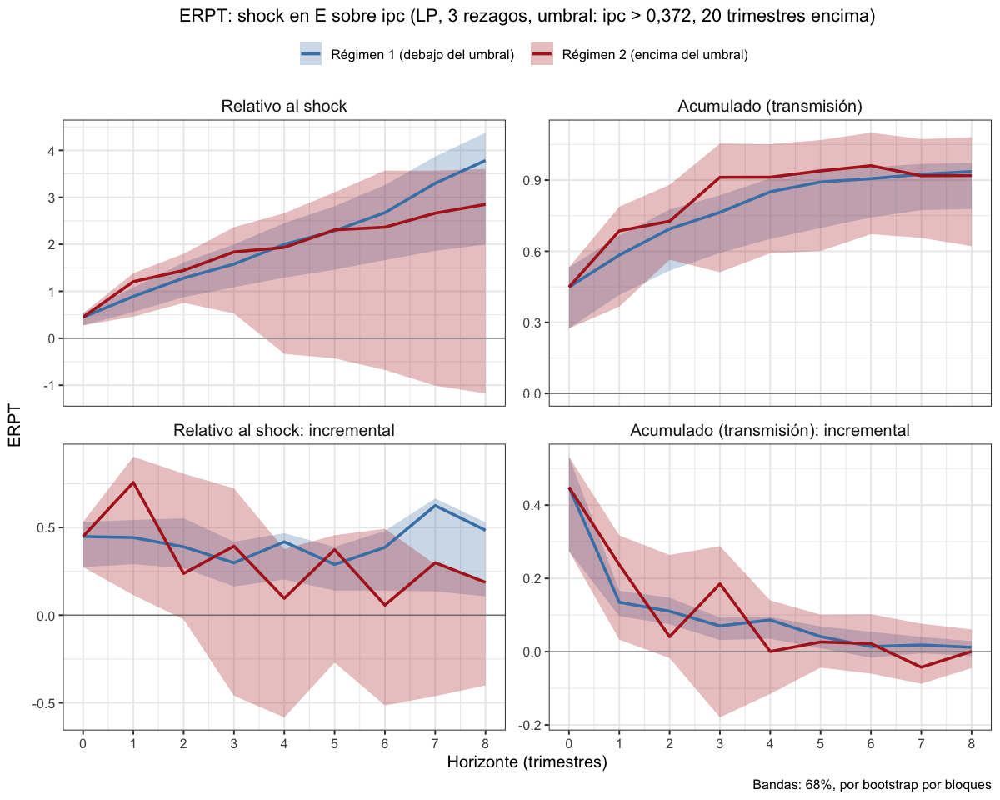

In [18]:
# Todas endógenas con umbral en 37,6% de inflación trimestral (umbral del TVAR-indt), 3 rezagos
lp_erpt_endog_p3_tvar37.6 <- erpt_lp(df_ERPT_Arg, endog = c("impp_usa", "E", "ipc", "pbird"),
                                     fixed_lags = 3, horizons = 8, reps = 500,
                                     threshold_var = "ipc", upper_threshold = 0.932203389830508)
saveRDS(lp_erpt_endog_p3_tvar37.6, "lp_erpt_endog_p3_tvar37.6.rds")
graficar_erpt_lp(lp_erpt_endog_p3_tvar37.6, archivo = "lp_erpt_endog_p3_tvar37.6")
graficar_erpt_lp(lp_erpt_endog_p3_tvar37.6, niveles = 0.68, archivo = "lp_erpt_endog_p3_tvar37.6_68")

### impp_usa 1950 a 2023 - 1 exógena y el resto endógenas - Selected orders: 2 y 5

### 1 exógena y el resto endógenas - 2 lags

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<dbl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,2,NaN,NA,2,0,1,0.68,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,295,"E, ipc, pbird",3


Impulse: E -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,0,0.45749761,0.45749761,0.45749761,0.4574976,0.45749761,0.4574976
2,1,0.29034112,0.20803749,0.37264476,0.5517323,0.21514554,0.8883190
3,2,0.17402621,0.04826138,0.29979105,0.1952958,-0.14302273,0.5336144
4,3,0.12791141,-0.01001475,0.26583757,0.4037421,0.11183379,0.6956504
5,4,0.03795588,-0.10491676,0.18082851,0.2964406,0.08101739,0.5118638
6,5,-0.05670296,-0.24973305,0.13632713,0.2077226,0.06022773,0.3552175
7,6,-0.04021823,-0.21928521,0.13884875,0.1385380,-0.02583258,0.3029085
8,7,-0.01539892,-0.22068290,0.18988506,0.2571480,0.06944315,0.4448529
9,8,-0.24438140,-0.47747864,-0.01128417,0.1377636,0.02742272,0.2481045


Impulse: E -> Response: pbird

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
10,0,-0.035019959,-0.035019959,-0.035019959,-0.035019959,-0.035019959,-0.03501996
11,1,0.015895795,-0.035632074,0.067423664,-0.021954008,-0.054460029,0.01055201
12,2,-0.044555220,-0.084368558,-0.004741882,0.012534283,-0.008765135,0.03383370
13,3,-0.085829647,-0.144861654,-0.026797639,-0.020561165,-0.051493619,0.01037129
14,4,-0.011031142,-0.064741917,0.042679632,-0.004121263,-0.018950649,0.01070812
15,5,0.058406728,-0.009978193,0.126791650,0.019054223,0.005460913,0.03264753
16,6,0.023599086,-0.028678166,0.075876337,0.008138798,-0.006430093,0.02270769
17,7,-0.009911254,-0.075952991,0.056130484,-0.003390730,-0.019550017,0.01276856
18,8,-0.024436463,-0.076249621,0.027376694,0.015994773,0.002591632,0.02939791


... (4 outputs left out)

Impulse: pbird -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
37,0,0.0000000,0.0000000,0.00000000,0.00000000,0.0000000,0.0000000
38,1,-0.8399393,-1.2072263,-0.47265238,-0.90275597,-2.1060562,0.3005443
39,2,-1.0789187,-1.6309159,-0.52692147,1.35462255,0.5983375,2.1109076
40,3,-0.5243211,-0.8844406,-0.16420168,-0.27606523,-1.6706413,1.1185109
41,4,-0.5172797,-0.9024983,-0.13206108,-0.15590162,-1.5445128,1.2327095
42,5,0.1282954,-0.3567354,0.61332621,1.53793294,0.2834601,2.7924058
43,6,-0.3556508,-0.6739642,-0.03733743,-1.12141735,-2.6109828,0.3681481
44,7,-0.6485701,-1.0820259,-0.21511426,-0.02428799,-1.0162735,0.9676975
45,8,-1.0064786,-1.4064671,-0.60649006,3.50930720,1.3459793,5.6726351


Impulse: pbird -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
46,0,0.0000000,0.0000000,0.00000000,0.0000000,0.0000000,0.0000000
47,1,-0.1294488,-0.2506354,-0.00826219,0.1179023,-0.6074324,0.8432370
48,2,-0.3657372,-0.6137802,-0.11769430,1.1999718,0.6055918,1.7943518
49,3,-0.2445320,-0.4295291,-0.05953488,0.2312929,-0.7676331,1.2302190
50,4,-0.4080447,-0.6417492,-0.17434027,0.4666603,-0.6896870,1.6230077
51,5,-0.3246341,-0.5817289,-0.06753932,1.0561859,0.2128955,1.8994763
52,6,-0.2847643,-0.5474820,-0.02204658,0.3565921,-0.7373114,1.4504955
53,7,-0.2441657,-0.4715154,-0.01681609,-0.6389615,-1.8038129,0.5258899
54,8,-0.4162584,-0.7094605,-0.12305634,2.5770363,0.9893975,4.1646751


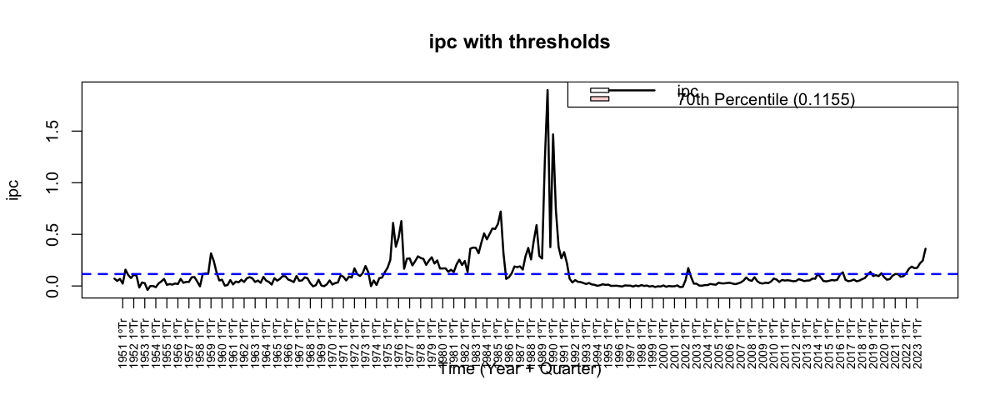

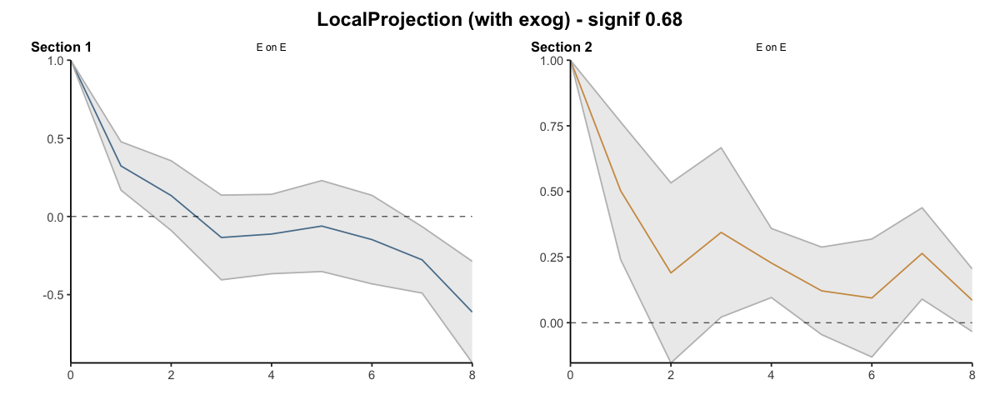

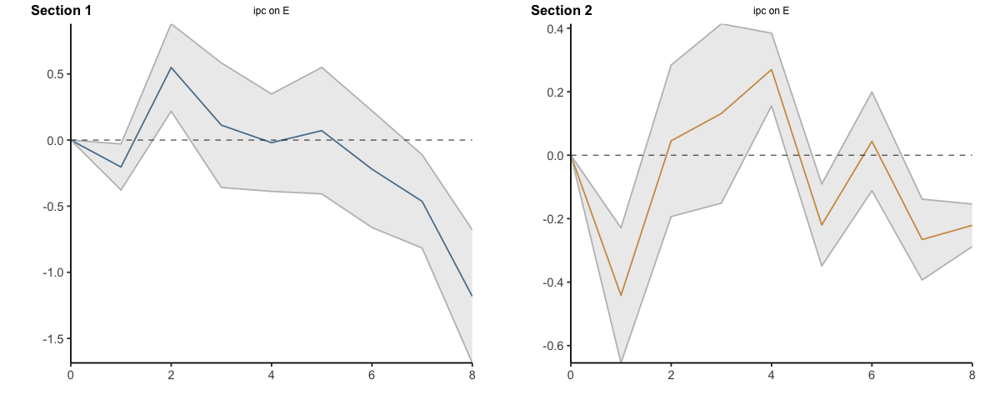

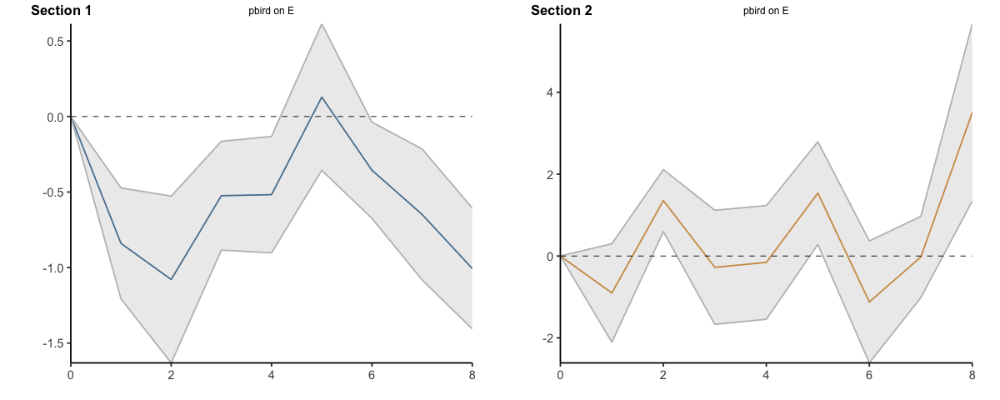

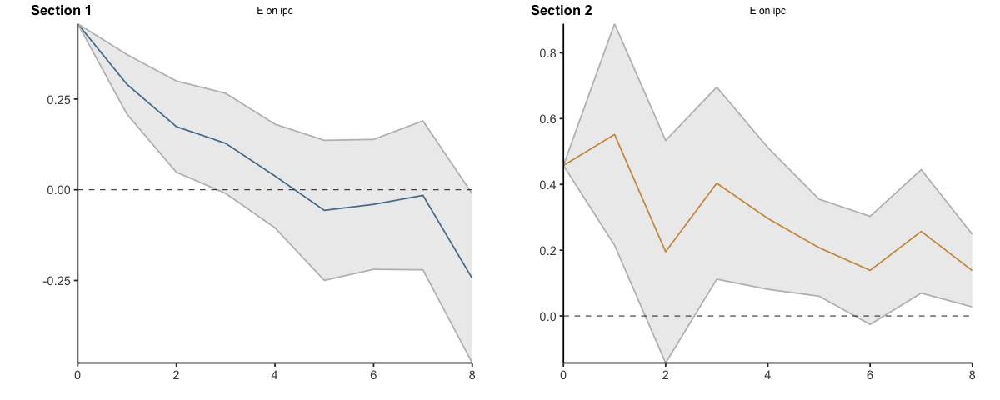

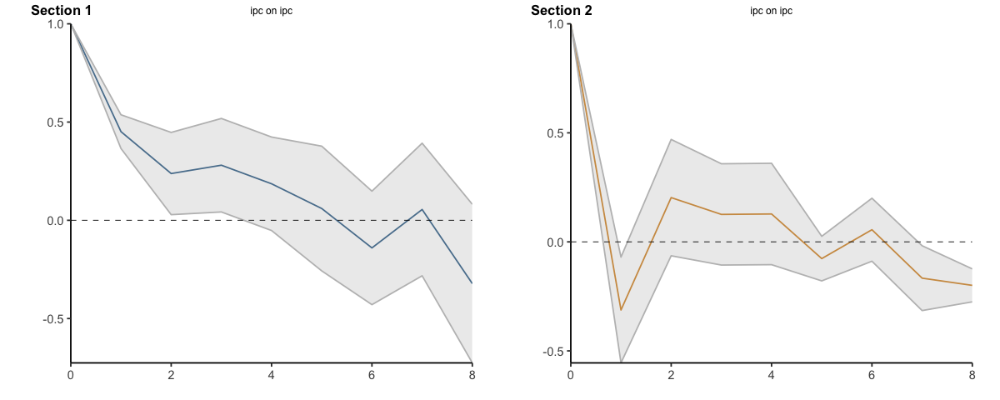

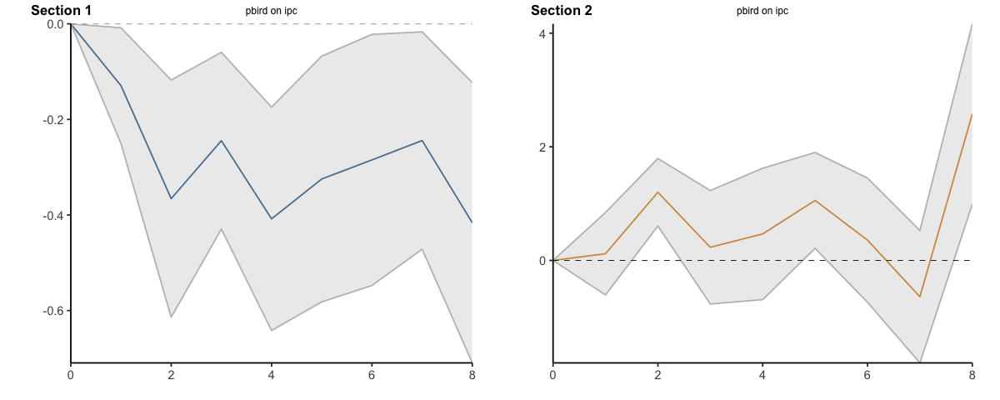

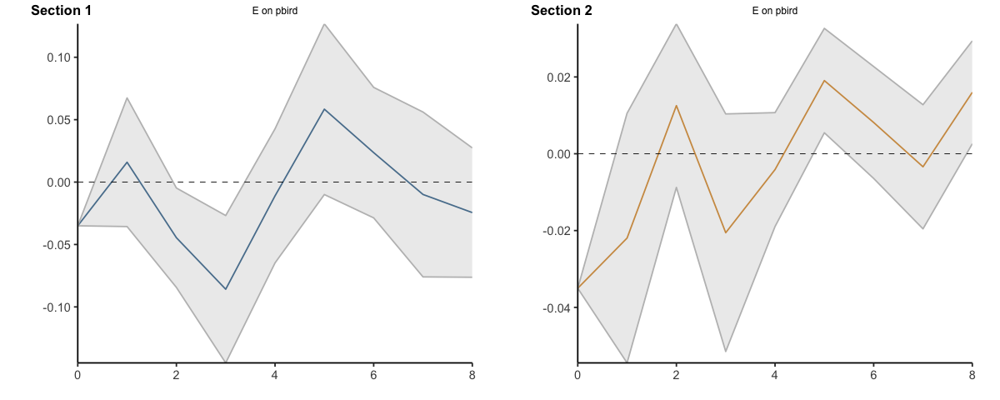

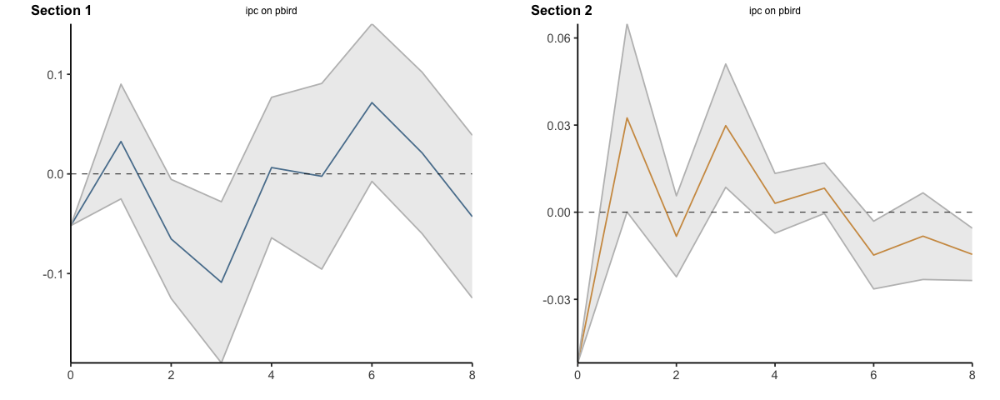

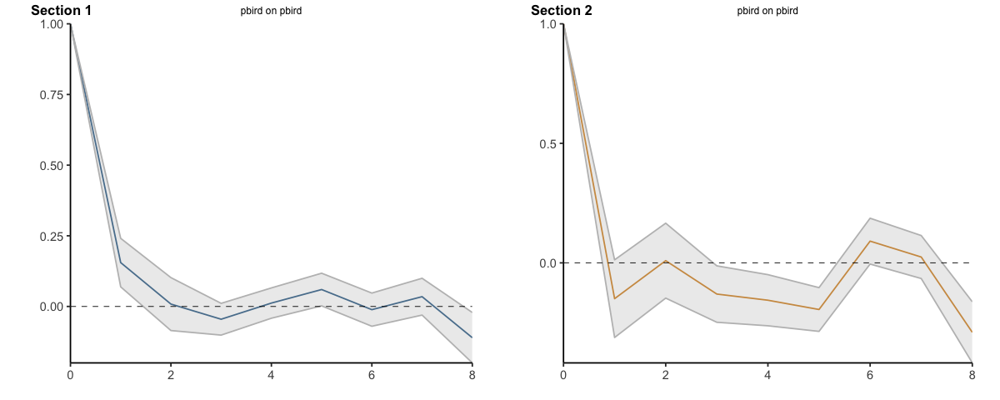

In [19]:
res <- run_lp_model(df_ERPT_Arg, endog=c("E", "ipc", "pbird"), exog=c("impp_usa"), fixed_lags = 2, horizons=8, signif = 0.68, threshold_var = 'ipc', upper_threshold=0.7)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<dbl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,2,NaN,NA,2,0,1,0.68,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,295,"E, ipc, pbird",3


Impulse: E -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,0,0.4574976,0.45749761,0.4574976,0.4574976,0.4574976,0.4574976
2,1,0.7478387,0.66553510,0.8301424,1.0092299,0.6726432,1.3458166
3,2,0.9218650,0.71379648,1.1299334,1.2045257,0.5296204,1.8794310
4,3,1.0497764,0.70378172,1.3957710,1.6082678,0.6414542,2.5750814
5,4,1.0877322,0.59886497,1.5765995,1.9047084,0.7224716,3.0869453
6,5,1.0310293,0.34913191,1.7129266,2.1124310,0.7826993,3.4421628
7,6,0.9908110,0.12984671,1.8517754,2.2509690,0.7568668,3.7450713
8,7,0.9754121,-0.09083619,2.0416604,2.5081170,0.8263099,4.1899242
9,8,0.7310307,-0.56831483,2.0303763,2.6458807,0.8537326,4.4380287


Impulse: E -> Response: pbird

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
10,0,-0.03501996,-0.03501996,-0.0350199590,-0.03501996,-0.03501996,-0.035019959
11,1,-0.01912416,-0.07065203,0.0324037050,-0.05697397,-0.08947999,-0.024467946
12,2,-0.06367938,-0.15502059,0.0276618230,-0.04443968,-0.09824512,0.009365756
13,3,-0.14950903,-0.29988225,0.0008641841,-0.06500085,-0.14973874,0.019737045
14,4,-0.16054017,-0.36462416,0.0435438162,-0.06912211,-0.16868939,0.030445168
15,5,-0.10213344,-0.37460236,0.1703354665,-0.05006789,-0.16322848,0.063092701
16,6,-0.07853436,-0.40328052,0.2462118040,-0.04192909,-0.16965857,0.085800390
17,7,-0.08844561,-0.47923351,0.3023422881,-0.04531982,-0.18920859,0.098568948
18,8,-0.11288208,-0.55548313,0.3297189818,-0.02932505,-0.18661696,0.127966862


... (4 outputs left out)

Impulse: pbird -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
37,0,0.0000000,0.000000,0.0000000,0.00000000,0.000000,0.0000000
38,1,-0.8399393,-1.207226,-0.4726524,-0.90275597,-2.106056,0.3005443
39,2,-1.9188580,-2.838142,-0.9995739,0.45186658,-1.507719,2.4114519
40,3,-2.4431792,-3.722583,-1.1637755,0.17580135,-3.178360,3.5299627
41,4,-2.9604589,-4.625081,-1.2958366,0.01989973,-4.722873,4.7626723
42,5,-2.8321635,-4.981817,-0.6825104,1.55783267,-4.439413,7.5550781
43,6,-3.1878143,-5.655781,-0.7198478,0.43641533,-7.050396,7.9232262
44,7,-3.8363843,-6.737807,-0.9349621,0.41212734,-8.066669,8.8909237
45,8,-4.8428629,-8.144274,-1.5414522,3.92143454,-6.720690,14.5635589


Impulse: pbird -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
46,0,0.0000000,0.0000000,0.00000000,0.0000000,0.000000000,0.000000
47,1,-0.1294488,-0.2506354,-0.00826219,0.1179023,-0.607432354,0.843237
48,2,-0.4951860,-0.8644155,-0.12595649,1.3178741,-0.001840552,2.637589
49,3,-0.7397180,-1.2939446,-0.18549137,1.5491670,-0.769473682,3.867808
50,4,-1.1477627,-1.9356939,-0.35983164,2.0158274,-1.459160694,5.490815
51,5,-1.4723968,-2.5174227,-0.42737096,3.0720133,-1.246265219,7.390292
52,6,-1.7571611,-3.0649047,-0.44941754,3.4286053,-1.983576572,8.840787
53,7,-2.0013268,-3.5364200,-0.46623363,2.7896438,-3.787389495,9.366677
54,8,-2.4175852,-4.2458805,-0.58928997,5.3666801,-2.797991995,13.531352


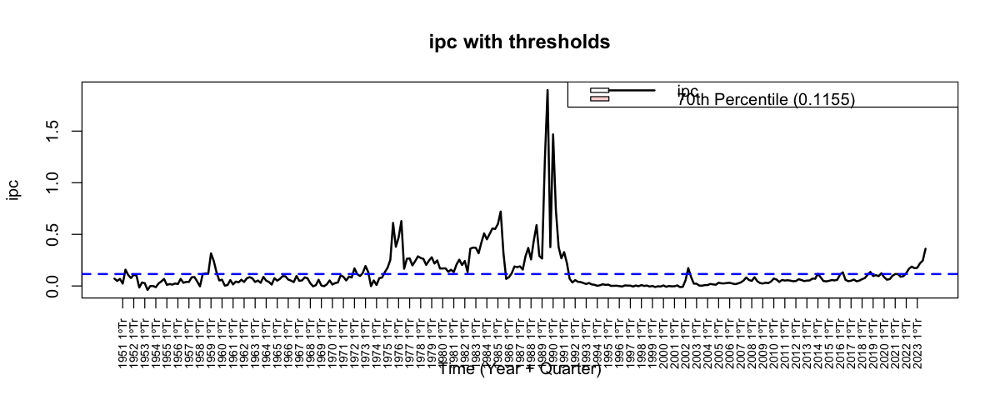

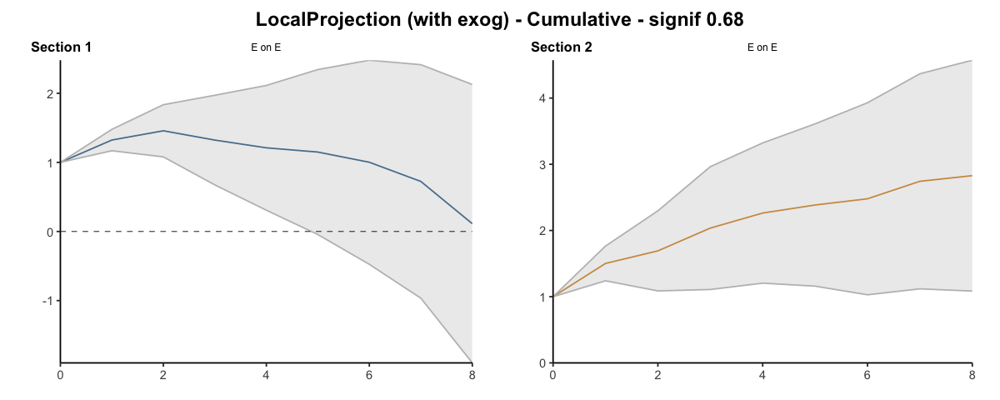

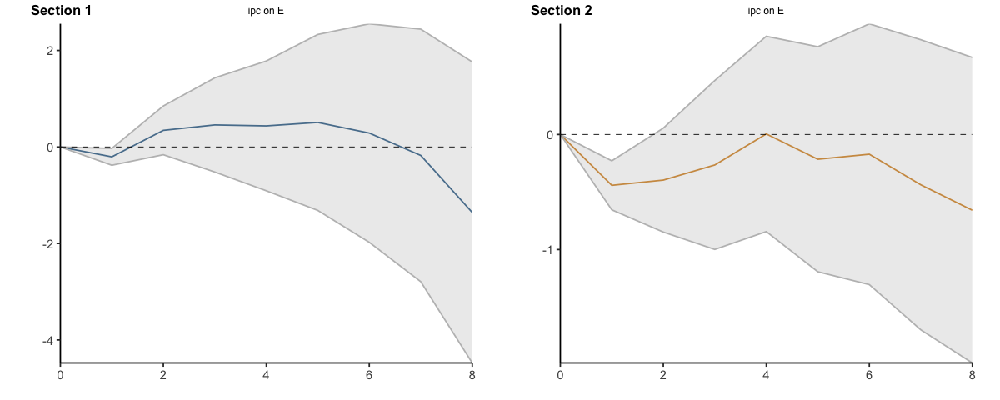

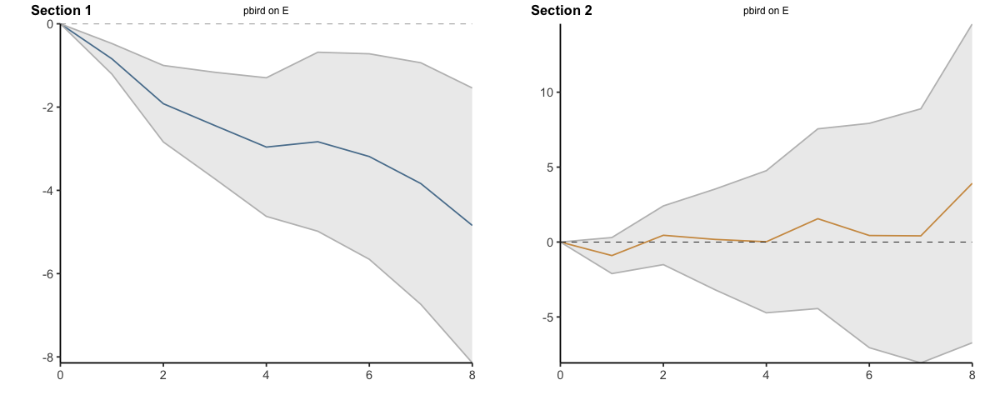

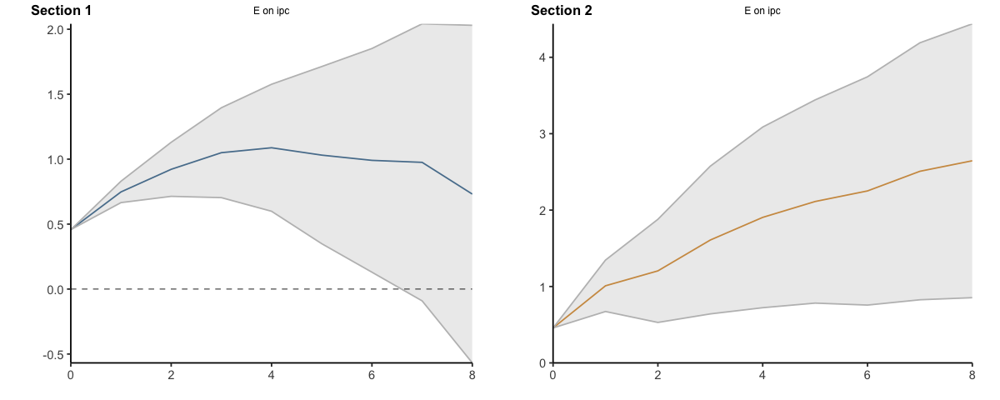

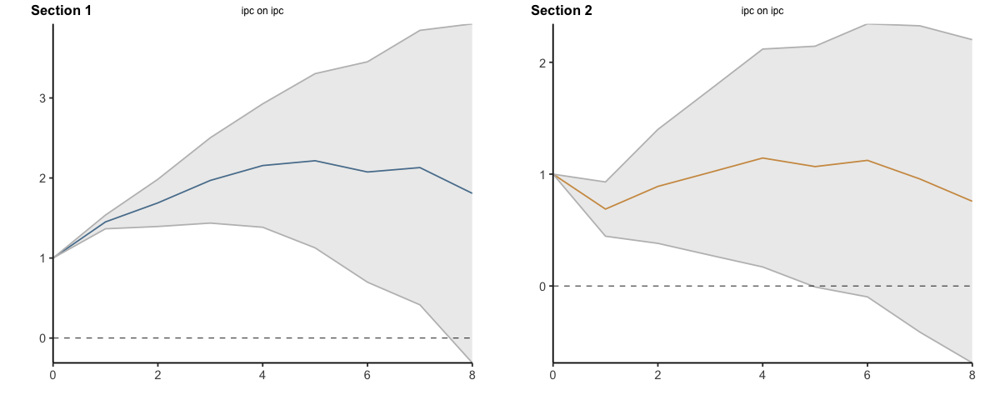

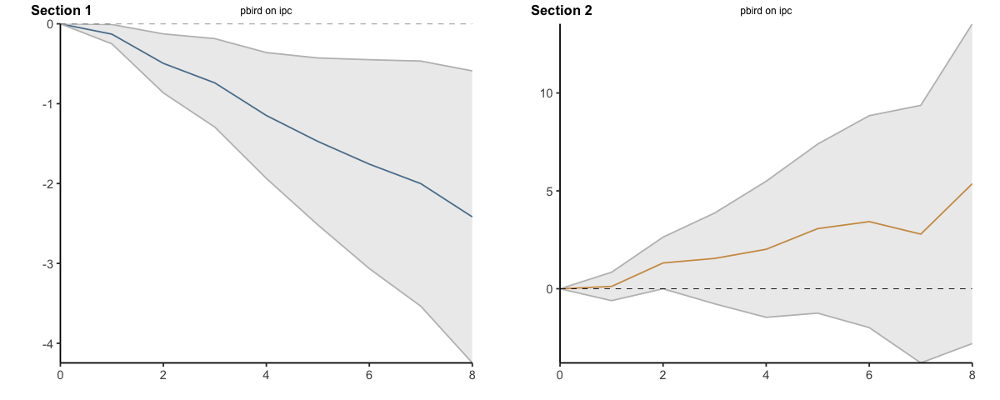

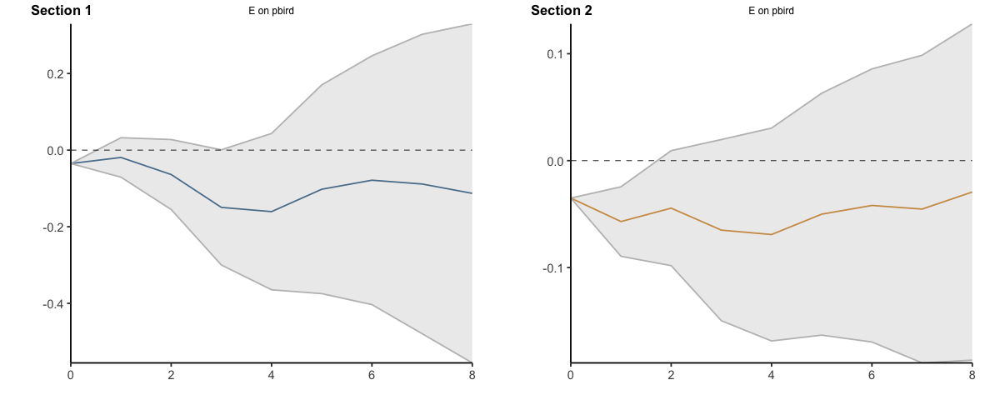

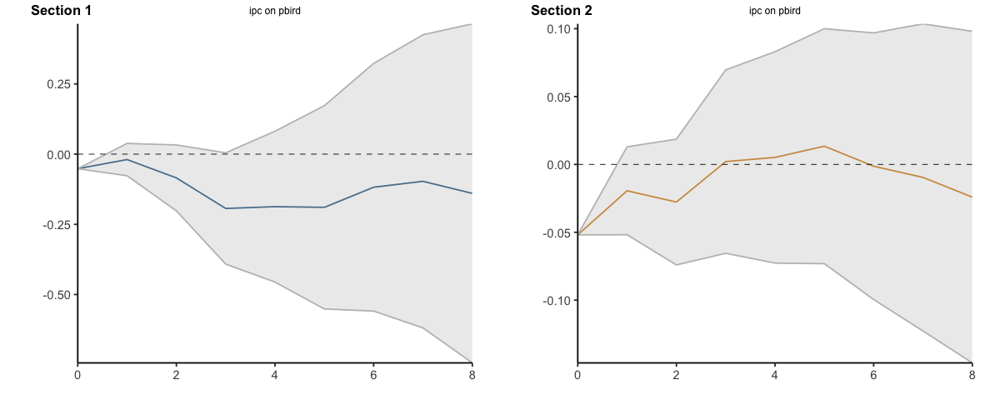

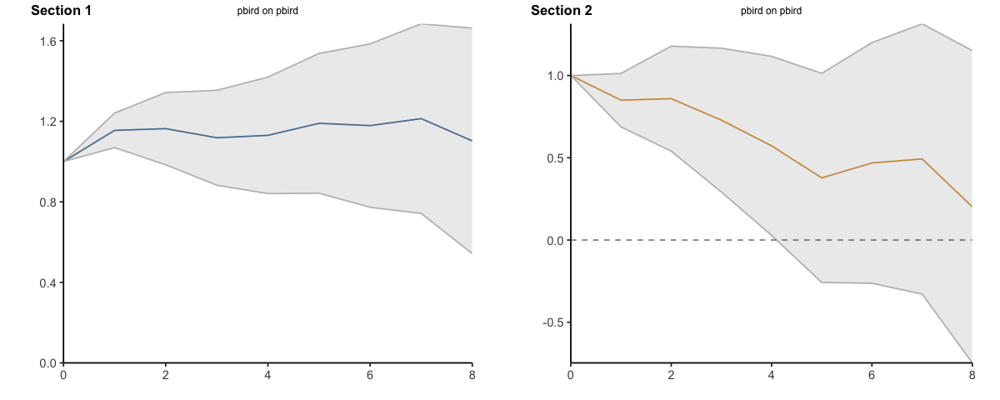

In [20]:
res <- run_lp_model(df_ERPT_Arg, endog=c("E", "ipc", "pbird"), exog=c("impp_usa"), fixed_lags = 2, horizons=8, signif = 0.68, threshold_var = 'ipc', upper_threshold=0.7, cumulative=TRUE)

#### Percentile 70 - 2 lags

Umbral: ipc > 0.1155 (percentil 70 )
Trimestres por régimen: debajo del umbral (dummy = 0) = 206 | encima del umbral (dummy = 1) = 89 


Bootstrap por bloques circular: 500 réplicas, bloques de 20 trimestres...



  |======================================================================| 100%
ERPT de un shock unitario en E sobre ipc ( LP, 2 rezagos, exógenas: impp_usa, umbral: ipc > 0,115, 89 trimestres encima )

Régimen 1 (debajo del umbral)
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.4575         0.4575       1.0000
         1              0.7478         0.5651       1.3234
         2              0.9219         0.6327       1.4571
         3              1.0498         0.7936       1.3227
         4              1.0877         0.8985       1.2106
         5              1.0310         0.8970       1.1494
         6              0.9908         0.9891       1.0017
         7              0.9754         1.3466       0.7244
         8              0.7310         6.4961       0.1125
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.4575             0.4575
                  0.2903             0.1076
                  0.1740             0.0676
 

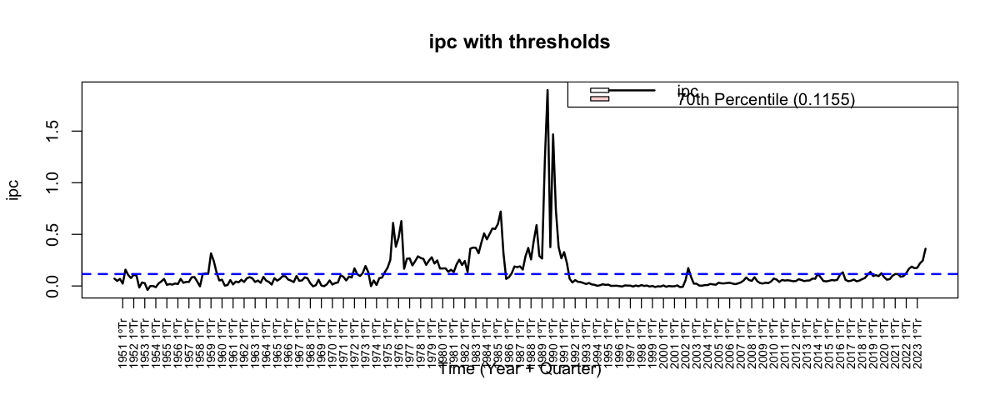

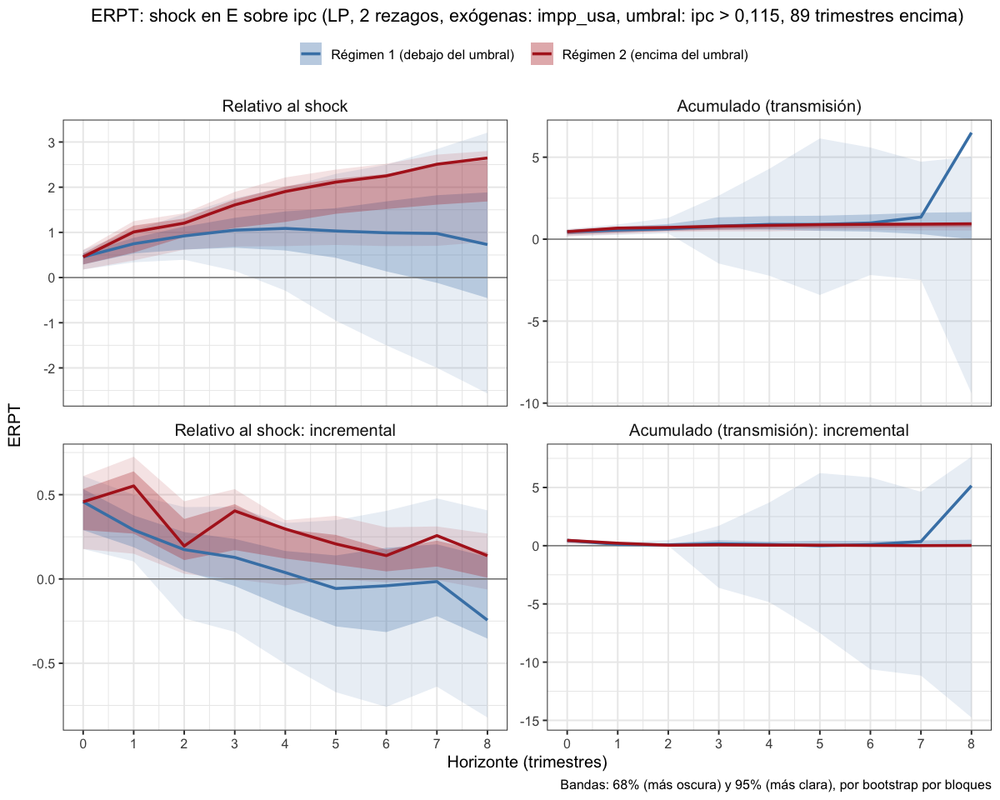

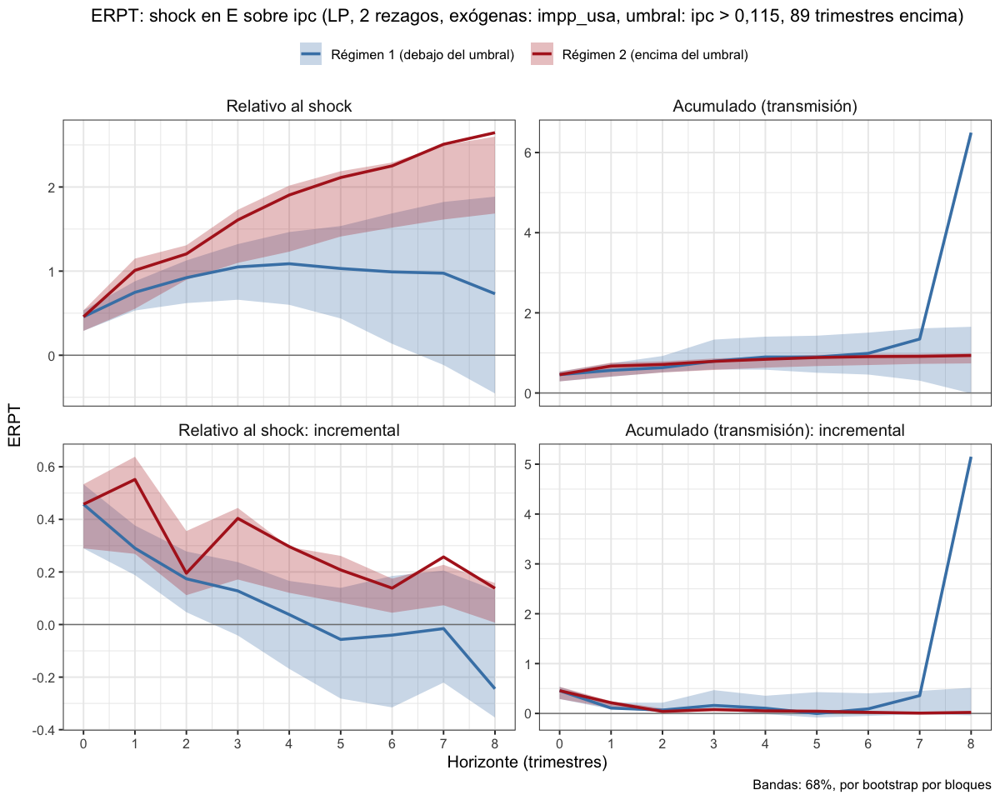

In [21]:
# 1 exógena y el resto endógenas con umbral en el percentil 70 del ipc, 2 rezagos
lp_erpt_exog_p2_u70 <- erpt_lp(df_ERPT_Arg, endog = c("E", "ipc", "pbird"), exog = c("impp_usa"),
                                fixed_lags = 2, horizons = 8, reps = 500,
                                threshold_var = "ipc", upper_threshold = 0.7)
saveRDS(lp_erpt_exog_p2_u70, "lp_erpt_exog_p2_u70.rds")
graficar_erpt_lp(lp_erpt_exog_p2_u70, archivo = "lp_erpt_exog_p2_u70")
graficar_erpt_lp(lp_erpt_exog_p2_u70, niveles = 0.68, archivo = "lp_erpt_exog_p2_u70_68")

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<dbl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,2,NaN,NA,2,0,1,0.68,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,295,"E, ipc, pbird",3


Impulse: E -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,0,0.45749761,0.45749761,0.45749761,0.4574976,0.45749761,0.4574976
2,1,0.35303773,0.24926123,0.45681424,0.5569282,0.21495452,0.8989019
3,2,0.25162059,0.11192285,0.39131833,0.1990764,-0.14912844,0.5472812
4,3,0.16421520,0.01895182,0.30947859,0.4128276,0.11602837,0.7096268
5,4,0.05512893,-0.08288264,0.19314050,0.3036998,0.09470697,0.5126926
6,5,-0.01457466,-0.20086190,0.17171259,0.2145449,0.06489641,0.3641935
7,6,0.02818914,-0.15198190,0.20836019,0.1504558,-0.01380281,0.3147145
8,7,0.01675303,-0.17998025,0.21348631,0.2669046,0.07668377,0.4571254
9,8,-0.15886277,-0.37965611,0.06193057,0.1472989,0.03426976,0.2603281


Impulse: E -> Response: pbird

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
10,0,-0.035019959,-0.03501996,-0.03501996,-0.035019959,-0.035019959,-0.035019959
11,1,-0.006356161,-0.06436477,0.05165244,-0.018601227,-0.051938818,0.014736363
12,2,-0.088015545,-0.12941961,-0.04661148,0.011729167,-0.009479348,0.032937683
13,3,-0.084870653,-0.13795877,-0.03178253,-0.018358451,-0.044744123,0.008027221
14,4,0.009411275,-0.04359155,0.06241410,-0.006126389,-0.020563651,0.008310874
15,5,0.074350201,0.01478536,0.13391505,0.017890637,0.005396505,0.030384770
16,6,0.013483126,-0.03912970,0.06609595,0.008493864,-0.006021215,0.023008942
17,7,-0.006942075,-0.06605877,0.05217462,-0.002960305,-0.019471901,0.013551291
18,8,-0.018661368,-0.06739672,0.03007398,0.015680376,0.001908220,0.029452532


... (4 outputs left out)

Impulse: pbird -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
37,0,0.0000000,0.0000000,0.00000000,0.0000000,0.0000000,0.000000000
38,1,-0.8305394,-1.1925660,-0.46851284,-0.9424323,-2.1735937,0.288729075
39,2,-1.0239588,-1.5643483,-0.48356929,1.3108530,0.5168852,2.104820661
40,3,-0.4989041,-0.8595166,-0.13829168,-0.3899167,-1.8665840,1.086750630
41,4,-0.4993911,-0.8811271,-0.11765509,-0.1581535,-1.6070089,1.290701982
42,5,0.1690131,-0.3167729,0.65479905,1.4231790,0.1782257,2.668132182
43,6,-0.2673041,-0.5949511,0.06034288,-1.4801301,-2.9645993,0.004339127
44,7,-0.5862635,-1.0340777,-0.13844927,-0.1334190,-1.2029582,0.936120176
45,8,-0.9289477,-1.3317306,-0.52616468,3.4577981,1.2339017,5.681694473


Impulse: pbird -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
46,0,0.00000000,0.0000000,0.000000000,0.00000000,0.00000000,0.0000000
47,1,-0.09649312,-0.2203236,0.027337391,0.06083601,-0.68517287,0.8068449
48,2,-0.32406851,-0.5714812,-0.076655858,1.10728273,0.49632190,1.7182436
49,3,-0.22392603,-0.4114852,-0.036366875,0.16312611,-0.89543930,1.2216915
50,4,-0.39782450,-0.6348584,-0.160790637,0.46772420,-0.73222736,1.6676758
51,5,-0.27311273,-0.5399694,-0.006256083,0.95389963,0.08585557,1.8219437
52,6,-0.23512235,-0.5100201,0.039775384,0.15519910,-0.93931522,1.2497134
53,7,-0.19252367,-0.4420370,0.056989672,-0.78670109,-1.98706598,0.4136638
54,8,-0.34771090,-0.6547967,-0.040625042,2.46281200,0.85042892,4.0751951


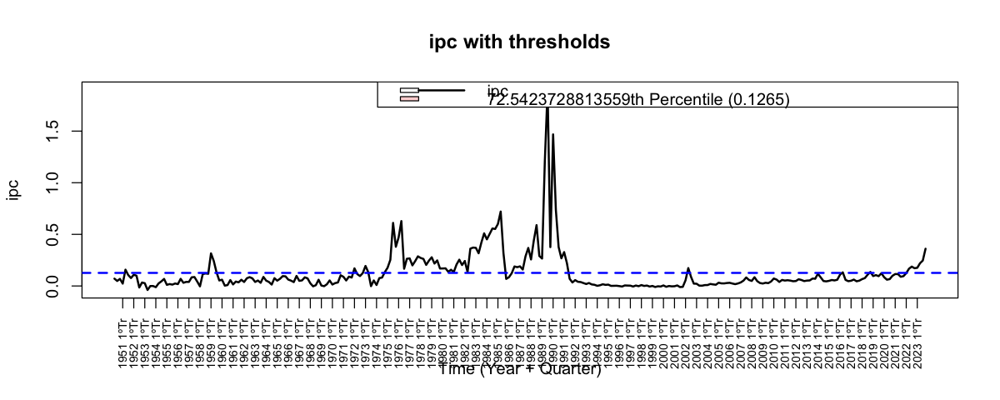

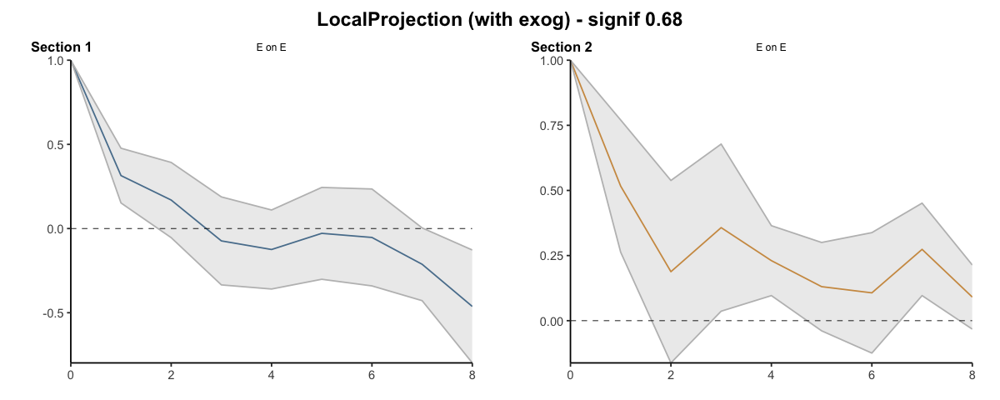

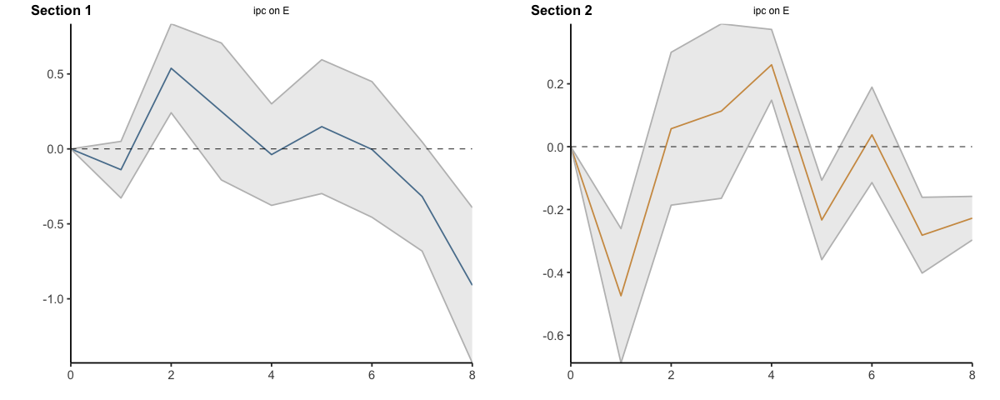

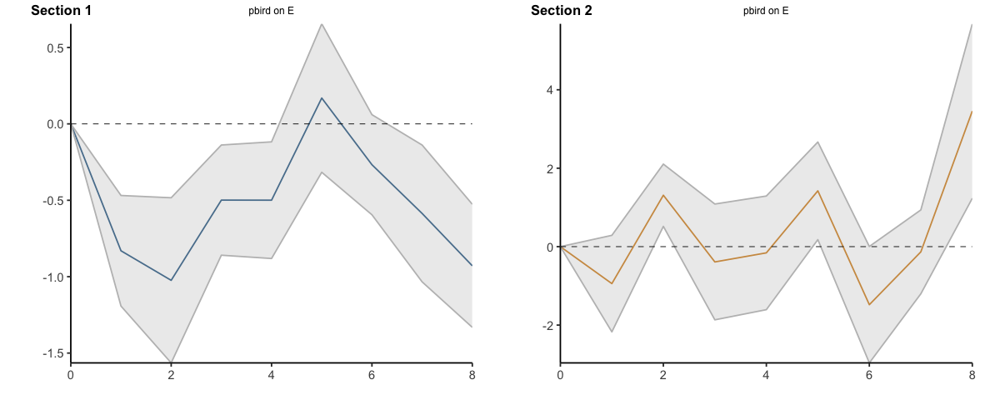

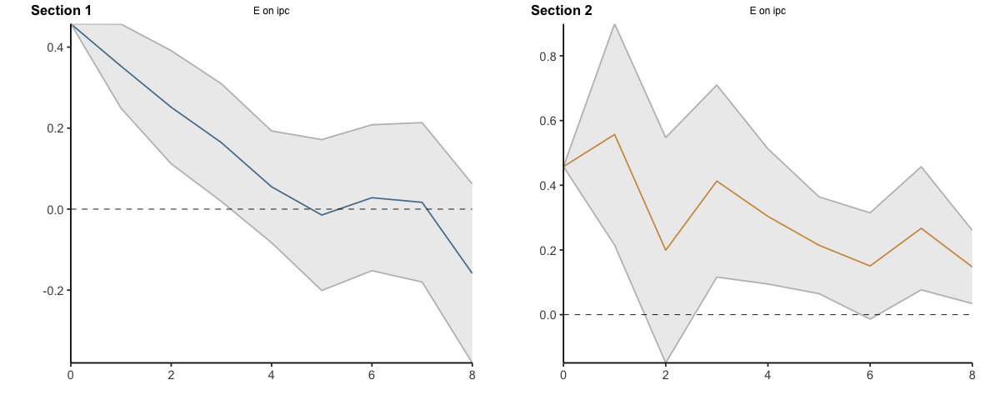

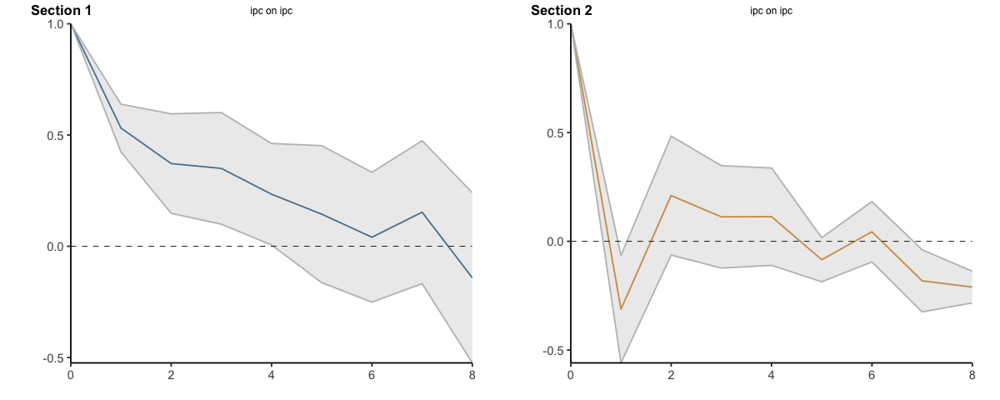

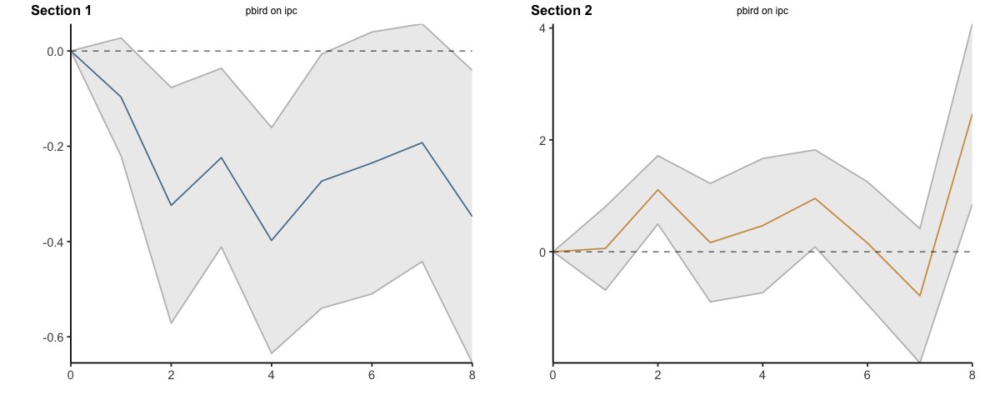

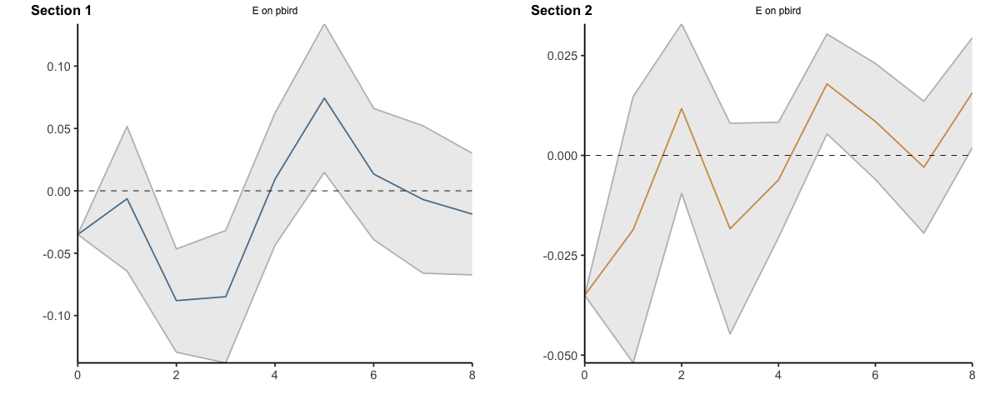

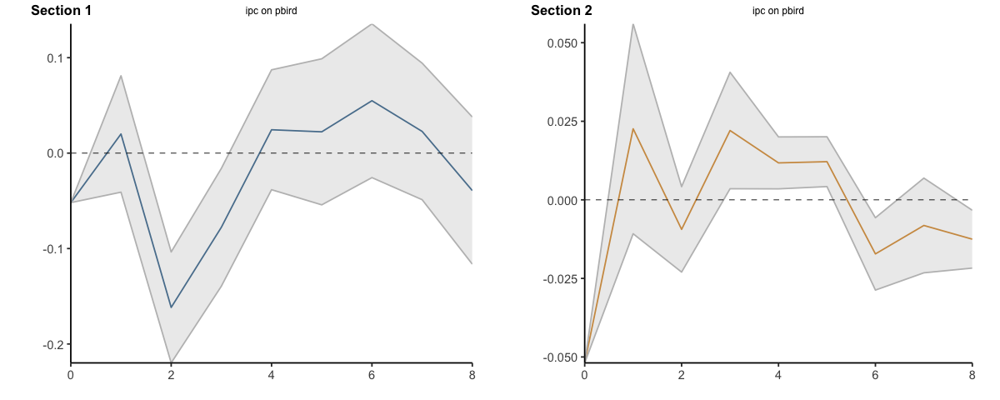

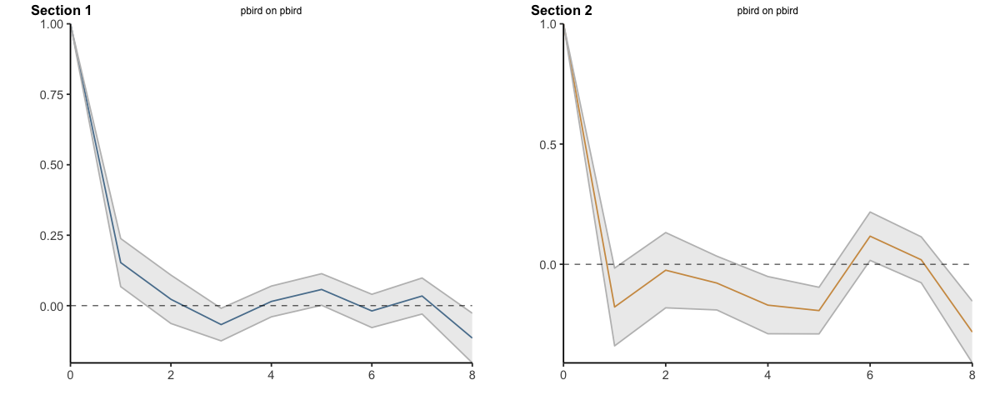

In [23]:
res <- run_lp_model(df_ERPT_Arg, endog=c("E", "ipc", "pbird"), exog=c("impp_usa"), fixed_lags = 2, horizons=8, signif = 0.68, threshold_var = 'ipc', upper_threshold=0.725423728813559)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<dbl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,2,NaN,NA,2,0,1,0.68,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,295,"E, ipc, pbird",3


Impulse: E -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,0,0.4574976,0.4574976,0.4574976,0.4574976,0.4574976,0.4574976
2,1,0.8105353,0.7067588,0.9143119,1.0144258,0.6724521,1.3563995
3,2,1.0621559,0.8186817,1.3056302,1.2135022,0.5233237,1.9036807
4,3,1.2263711,0.8376335,1.6151088,1.6263298,0.6393521,2.6133075
5,4,1.2815001,0.7547509,1.8082493,1.9300296,0.7340590,3.1260001
6,5,1.2669254,0.5538890,1.9799619,2.1445745,0.7989555,3.4901936
7,6,1.2951146,0.4019071,2.1883220,2.2950303,0.7851526,3.8049080
8,7,1.3118676,0.2219268,2.4018084,2.5619349,0.8618364,4.2620335
9,8,1.1530048,-0.1577293,2.4637389,2.7092339,0.8961062,4.5223616


Impulse: E -> Response: pbird

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
10,0,-0.03501996,-0.03501996,-0.0350199590,-0.03501996,-0.03501996,-0.03501996
11,1,-0.04137612,-0.09938473,0.0166324854,-0.05362119,-0.08695878,-0.02028360
12,2,-0.12939167,-0.22880433,-0.0299789995,-0.04189202,-0.09643812,0.01265409
13,3,-0.21426232,-0.36676310,-0.0617615326,-0.06025047,-0.14118225,0.02068131
14,4,-0.20485104,-0.41035465,0.0006525657,-0.06637686,-0.16174590,0.02899218
15,5,-0.13050084,-0.39556930,0.1345676110,-0.04848622,-0.15634940,0.05937695
16,6,-0.11701772,-0.43469900,0.2006635618,-0.03999236,-0.16237061,0.08238589
17,7,-0.12395979,-0.50075777,0.2528381843,-0.04295266,-0.18184251,0.09593719
18,8,-0.14262116,-0.56815448,0.2829121649,-0.02727229,-0.17993429,0.12538972


... (4 outputs left out)

Impulse: pbird -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
37,0,0.0000000,0.000000,0.0000000,0.00000000,0.000000,0.0000000
38,1,-0.8305394,-1.192566,-0.4685128,-0.94243231,-2.173594,0.2887291
39,2,-1.8544982,-2.756914,-0.9520821,0.36842064,-1.656708,2.3935497
40,3,-2.3534023,-3.616431,-1.0903738,-0.02149604,-3.523292,3.4803004
41,4,-2.8527934,-4.497558,-1.2080289,-0.17964952,-5.130301,4.7710023
42,5,-2.6837804,-4.814331,-0.5532298,1.24352943,-4.952076,7.4391345
43,6,-2.9510844,-5.409282,-0.4928870,-0.23660065,-7.916675,7.4434737
44,7,-3.5373479,-6.443360,-0.6313362,-0.37001967,-9.119633,8.3795938
45,8,-4.4662956,-7.775090,-1.1575009,3.08777842,-7.885731,14.0612883


Impulse: pbird -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
46,0,0.00000000,0.0000000,0.00000000,0.00000000,0.0000000,0.0000000
47,1,-0.09649312,-0.2203236,0.02733739,0.06083601,-0.6851729,0.8068449
48,2,-0.42056163,-0.7918048,-0.04931847,1.16811874,-0.1888510,2.5250884
49,3,-0.64448766,-1.2032900,-0.08568534,1.33124485,-1.0842903,3.7467800
50,4,-1.04231216,-1.8381483,-0.24647598,1.79896905,-1.8165176,5.4144557
51,5,-1.31542489,-2.3781177,-0.25273206,2.75286868,-1.7306621,7.2363994
52,6,-1.55054723,-2.8881378,-0.21295668,2.90806778,-2.6699773,8.4861129
53,7,-1.74307091,-3.3301748,-0.15596701,2.12136669,-4.6570433,8.8997766
54,8,-2.09078180,-3.9849716,-0.19659205,4.58417869,-3.8066143,12.9749717


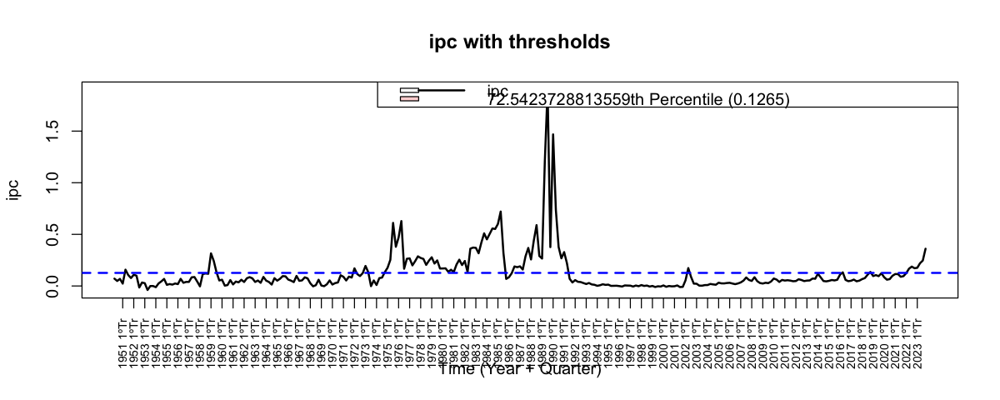

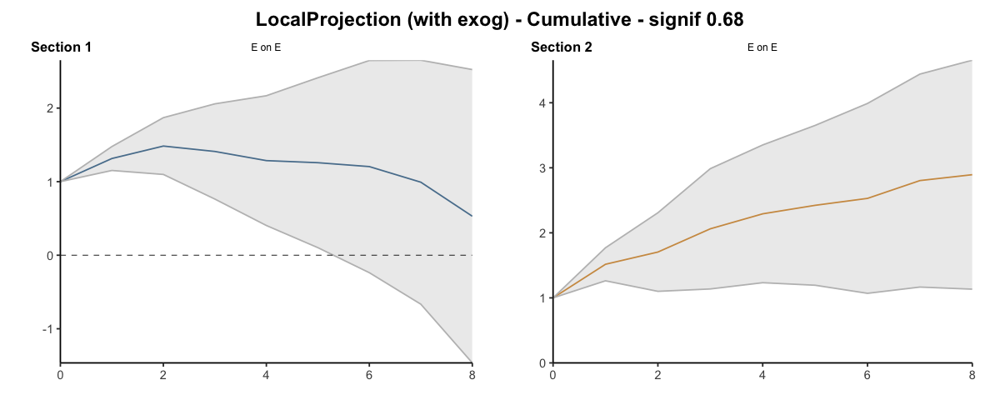

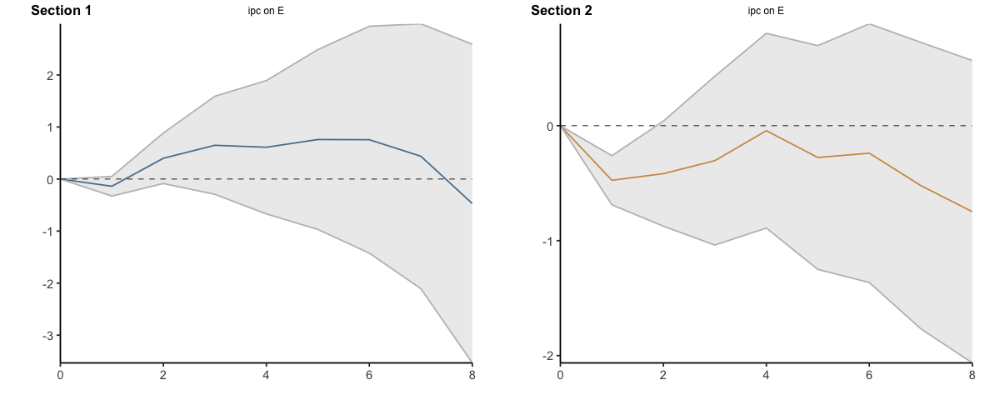

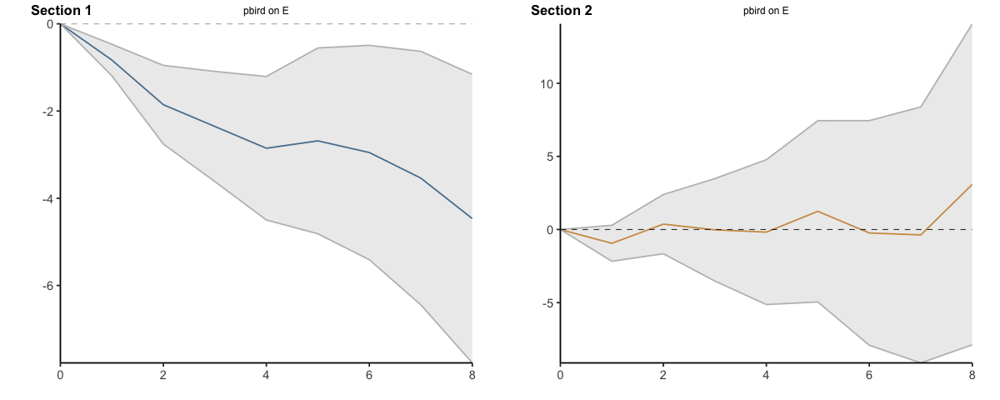

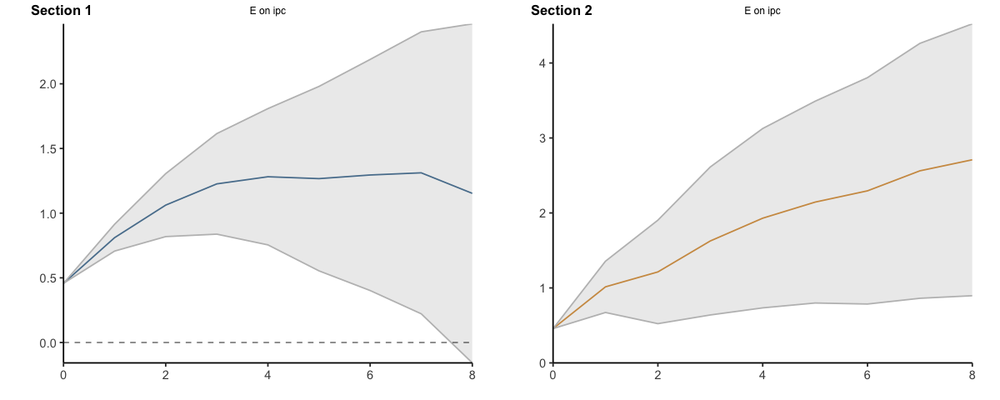

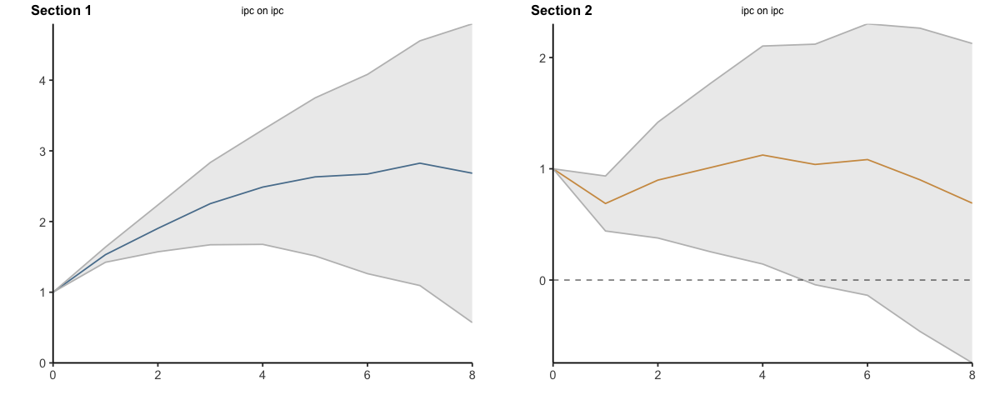

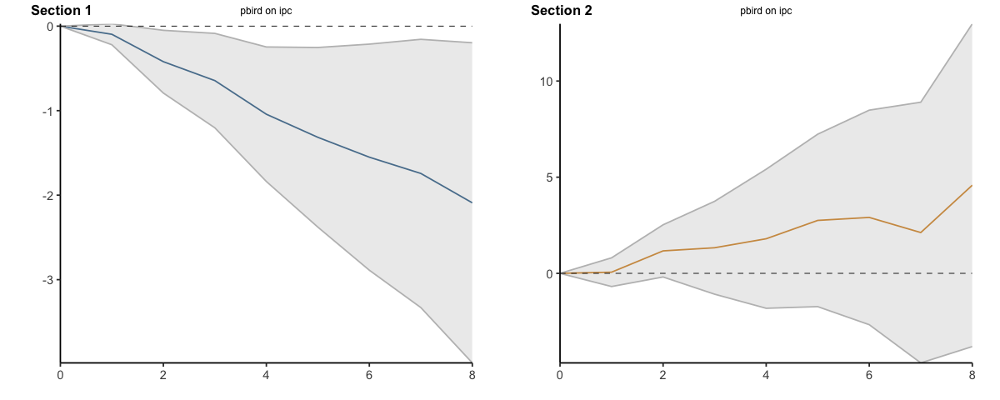

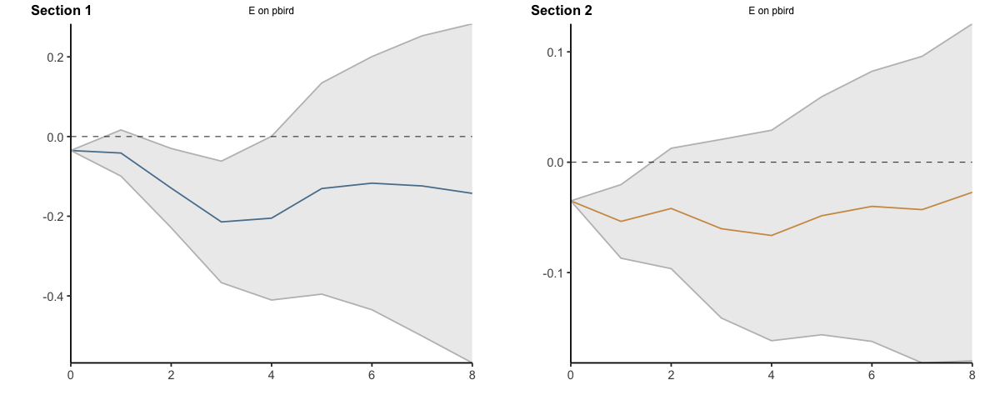

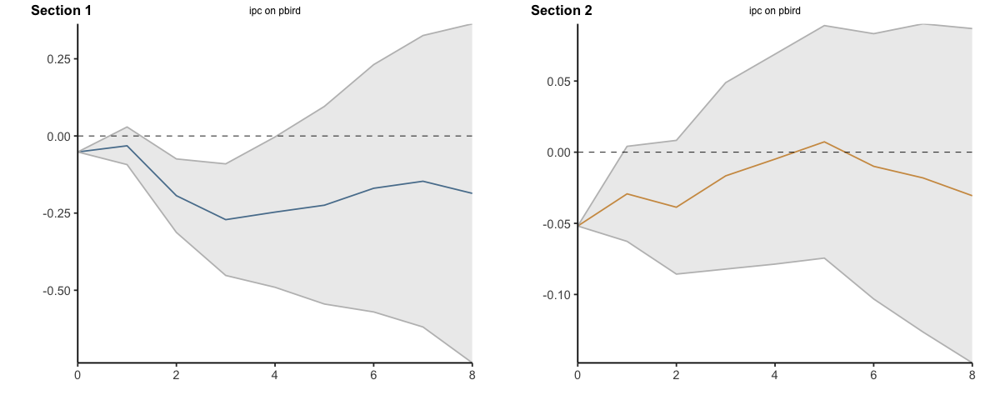

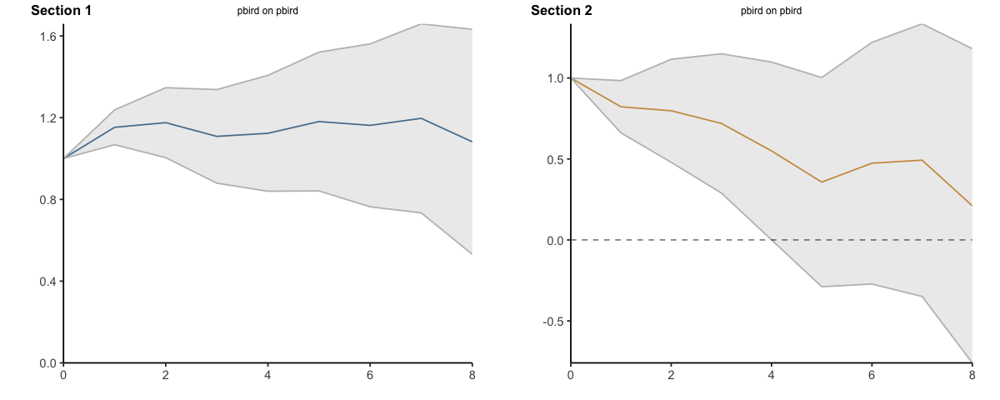

In [25]:
res <- run_lp_model(df_ERPT_Arg, endog=c("E", "ipc", "pbird"), exog=c("impp_usa"), fixed_lags = 2, horizons=8, signif = 0.68, threshold_var = 'ipc', upper_threshold=0.725423728813559, cumulative = TRUE)

### Percentile 0,725423728813559 (12,5 inflación trimestral) - quedan 81 trimestres por encima del umbral

Umbral: ipc > 0.1265 (percentil 72.5 )
Trimestres por régimen: debajo del umbral (dummy = 0) = 214 | encima del umbral (dummy = 1) = 81 


Bootstrap por bloques circular: 500 réplicas, bloques de 20 trimestres...



  |======================================================================| 100%


Aviso (Régimen 1 (debajo del umbral)): en más del 5% de las réplicas la depreciación acumulada es casi cero en h = 8; las bandas del ERPT acumulado en esos horizontes son poco confiables.



ERPT de un shock unitario en E sobre ipc ( LP, 2 rezagos, exógenas: impp_usa, umbral: ipc > 0,127, 81 trimestres encima )

Régimen 1 (debajo del umbral)
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.4575         0.4575       1.0000
         1              0.8105         0.6166       1.3146
         2              1.0622         0.7158       1.4839
         3              1.2264         0.8694       1.4106
         4              1.2815         0.9964       1.2861
         5              1.2669         1.0074       1.2577
         6              1.2951         1.0749       1.2048
         7              1.3119         1.3216       0.9926
         8              1.1530         2.1760       0.5299
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.4575             0.4575
                  0.3530             0.1591
                  0.2516             0.0992
                  0.1642             0.1536
                  0.0551             

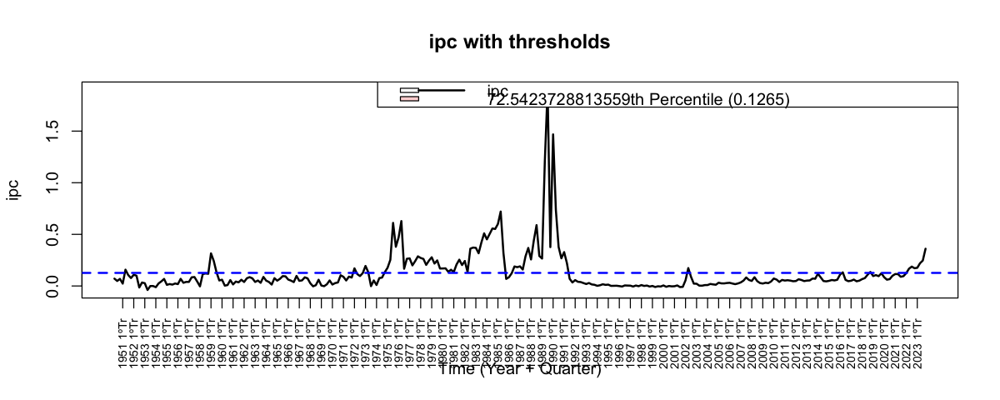

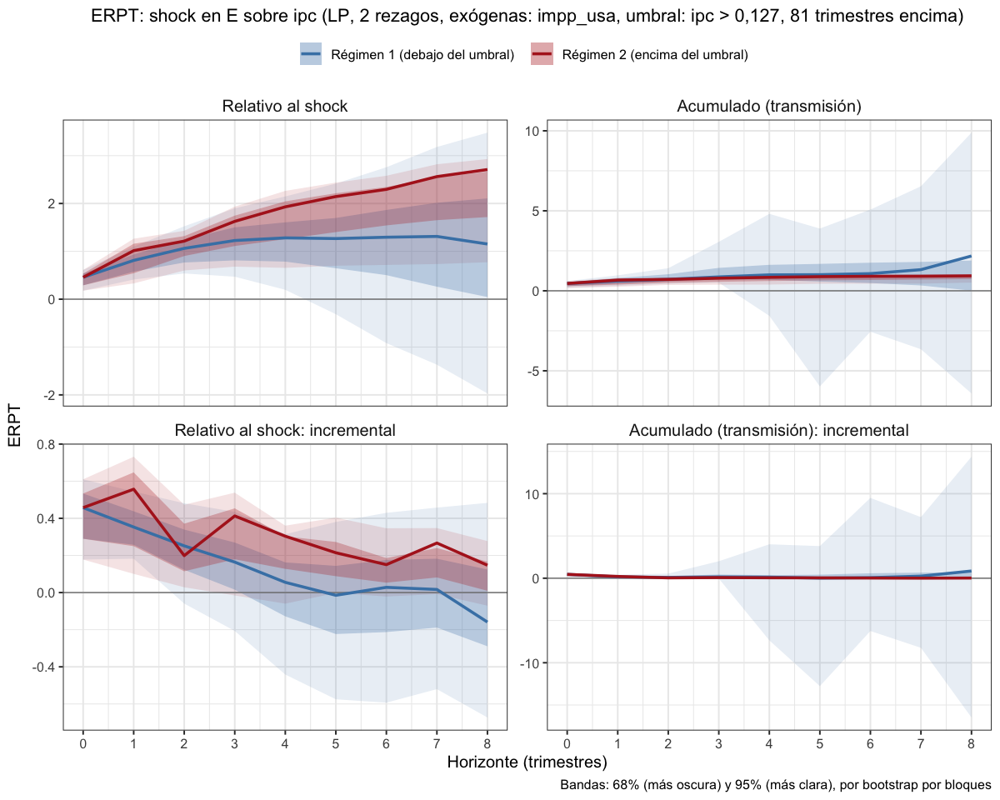

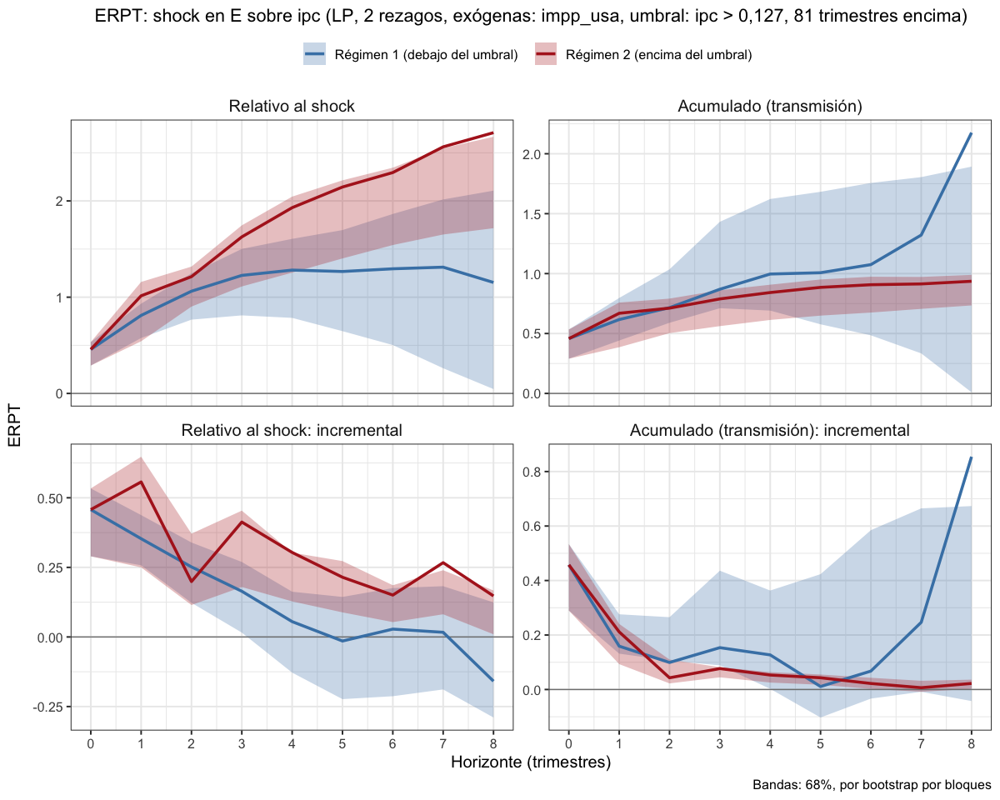

In [26]:
# 1 exógena y el resto endógenas con umbral en en 12,5% de inflación trimestral (umbral del TVAR), 2 rezagos
lp_erpt_exog_p2_tvar12.5 <- erpt_lp(df_ERPT_Arg, endog = c("E", "ipc", "pbird"), exog = c("impp_usa"), 
                                     fixed_lags = 2, horizons = 8, reps = 500,
                                     threshold_var = "ipc", upper_threshold = 0.725423728813559)
saveRDS(lp_erpt_exog_p2_tvar12.5, "lp_erpt_exog_p2_tvar12.5.rds")
graficar_erpt_lp(lp_erpt_exog_p2_tvar12.5, archivo = "lp_erpt_exog_p2_tvar12.5")
graficar_erpt_lp(lp_erpt_exog_p2_tvar12.5, niveles = 0.68, archivo = "lp_erpt_exog_p2_tvar12.5_68")

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<dbl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,2,NaN,NA,2,0,1,0.68,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,295,"E, ipc, pbird",3


Impulse: E -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,0,0.4574976,0.4574976,0.4574976,0.45749761,0.45749761,0.4574976
2,1,0.4722657,0.3642690,0.5802623,0.79955983,0.69833974,0.9007799
3,2,0.4177049,0.2365945,0.5988153,0.18445924,-0.04174790,0.4106664
4,3,0.2992494,0.1057179,0.4927808,0.57755217,0.26009040,0.8950139
5,4,0.4458508,0.2794591,0.6122424,0.26392887,-0.04916020,0.5770179
6,5,0.3050429,0.1110414,0.4990445,0.15504968,0.03630193,0.2737974
7,6,0.3906058,0.2057080,0.5755036,0.09025855,-0.36749711,0.5480142
8,7,0.6255345,0.3064072,0.9446619,0.10955697,0.04877853,0.1703354
9,8,0.4978531,0.2214820,0.7742242,0.09469840,0.02728323,0.1621136


Impulse: E -> Response: pbird

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
10,0,-0.035019959,-0.035019959,-0.035019959,-0.035019959,-0.0350199590,-0.035019959
11,1,-0.031022504,-0.064605081,0.002560073,-0.029495175,-0.0556249973,-0.003365352
12,2,-0.034657817,-0.066002729,-0.003312904,0.016170627,0.0002835979,0.032057656
13,3,-0.022688174,-0.066983124,0.021606777,-0.030377109,-0.0488887414,-0.011865477
14,4,-0.020570098,-0.048198794,0.007058598,0.001512322,-0.0094847395,0.012509384
15,5,0.024966545,-0.006869129,0.056802219,0.016921841,0.0024634030,0.031380278
16,6,0.001648127,-0.023039186,0.026335441,0.012185248,-0.0331087408,0.057479237
17,7,-0.013583122,-0.042966200,0.015799956,0.007227221,-0.0174754646,0.031929906
18,8,-0.011484325,-0.035039423,0.012070773,0.006531267,-0.0113500013,0.024412534


... (4 outputs left out)

Impulse: pbird -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
37,0,0.0000000,0.0000000,0.000000000,0.000000,0.000000,0.0000000
38,1,-0.7695065,-1.2241335,-0.314879439,-3.761111,-6.843882,-0.6783406
39,2,-0.5428766,-1.0037047,-0.082048444,7.323907,5.516422,9.1313913
40,3,-0.2792450,-0.6535225,0.095032443,2.263810,-5.306285,9.8339050
41,4,-0.2945642,-0.6370384,0.047909991,-4.735403,-17.198061,7.7272555
42,5,0.6721592,0.2060313,1.138287190,-1.943765,-8.685912,4.7983818
43,6,-0.4091018,-0.8251942,0.006990563,-5.035574,-9.587025,-0.4841227
44,7,-0.3423267,-0.7210230,0.036369600,-3.512925,-9.722527,2.6966770
45,8,0.3709046,-0.1481438,0.889952947,-1.407606,-4.078322,1.2631092


Impulse: pbird -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
46,0,0.00000000,0.000000000,0.0000000,0.00000000,0.0000000,0.0000000
47,1,0.10418299,-0.023488296,0.2318543,-0.09746834,-2.5461025,2.3511658
48,2,-0.08583548,-0.279796416,0.1081255,4.62465042,3.1196372,6.1296637
49,3,0.01875021,-0.204158998,0.2416594,4.54597537,-0.1256914,9.2176422
50,4,-0.01811404,-0.230354524,0.1941264,-2.67634635,-12.4595673,7.1068746
51,5,0.24511757,-0.003250904,0.4934860,-3.65042659,-11.1800509,3.8791978
52,6,0.11308736,-0.162211561,0.3883863,-4.39790280,-9.1343265,0.3385209
53,7,-0.16629469,-0.459108521,0.1265191,-4.93560928,-12.1336757,2.2624571
54,8,0.60214576,0.163283532,1.0410080,-2.91510596,-6.1972777,0.3670657


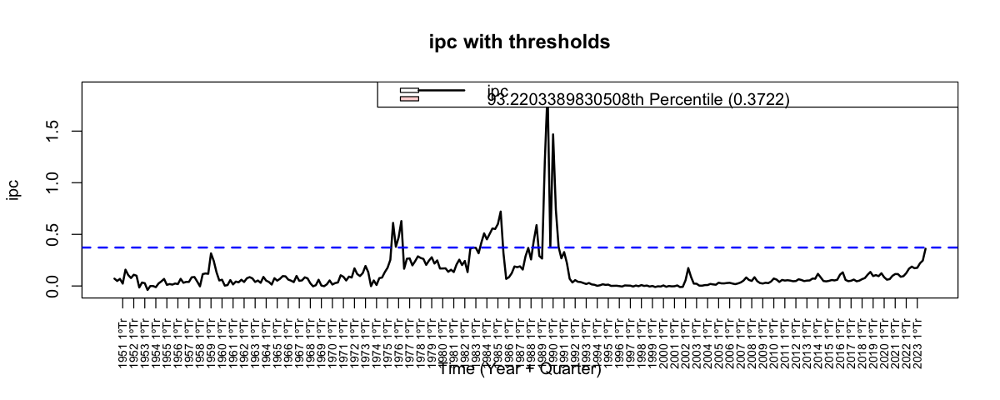

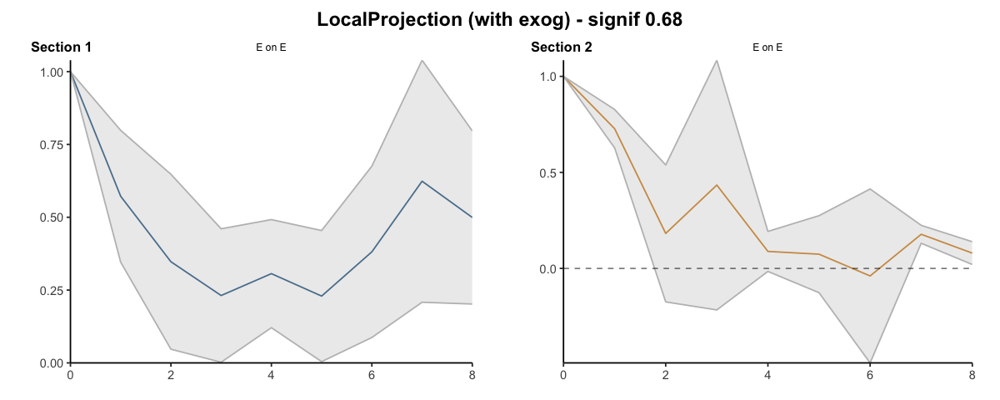

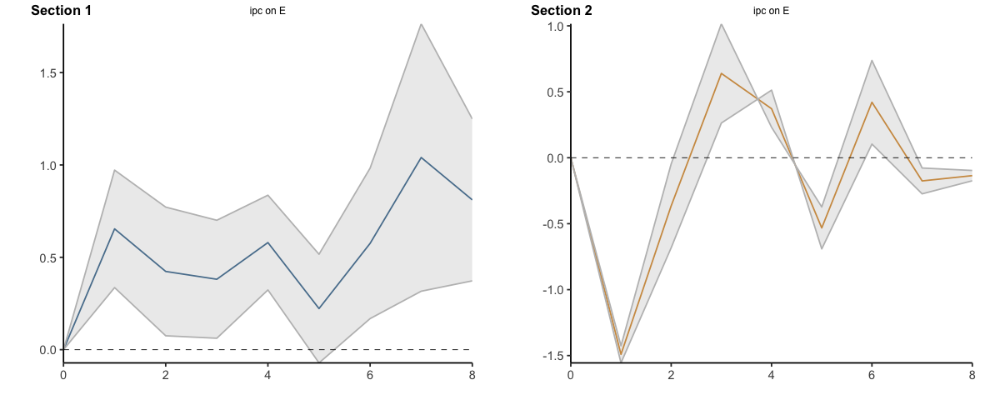

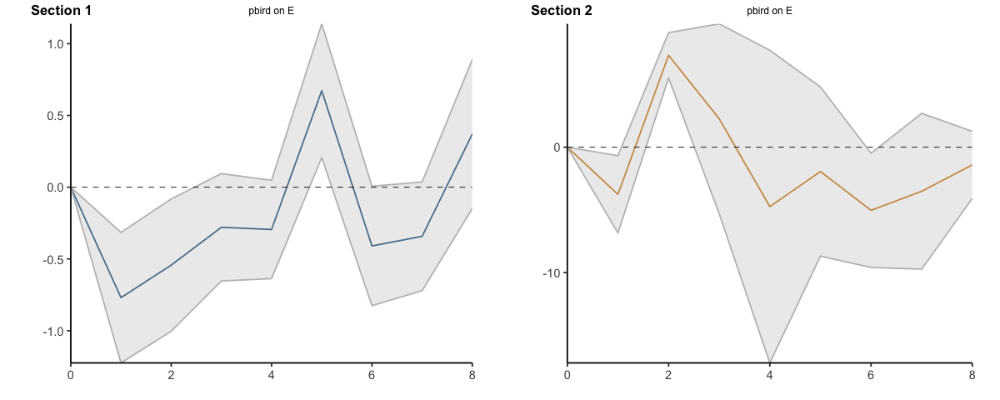

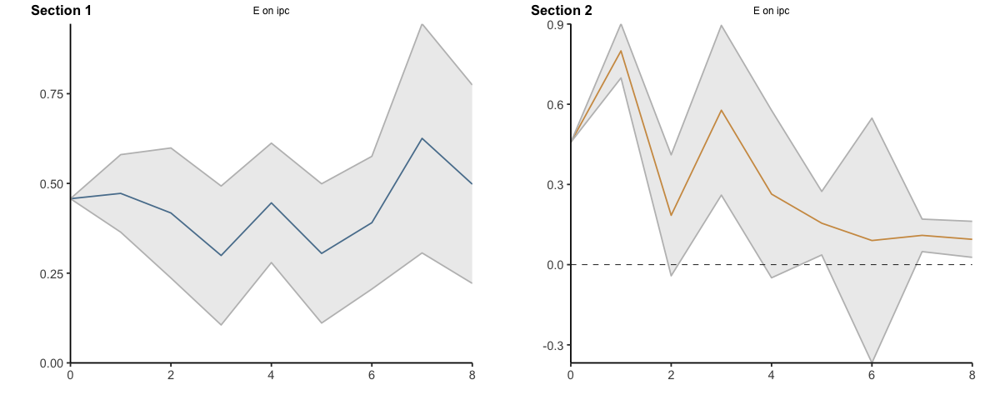

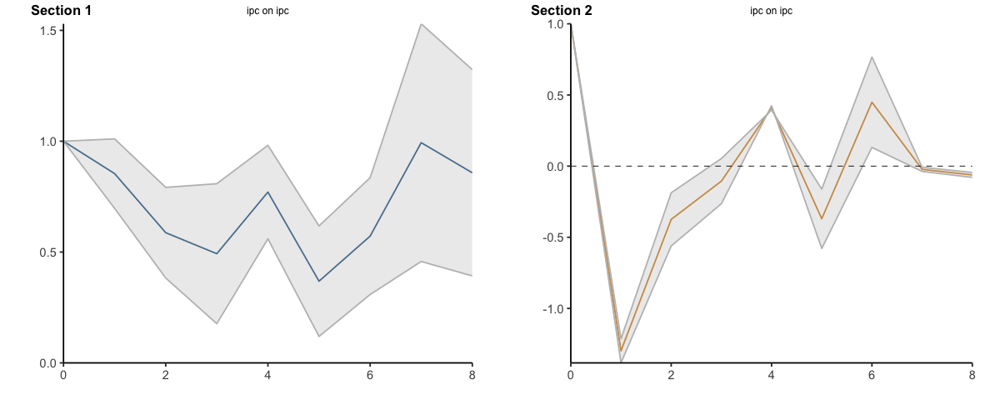

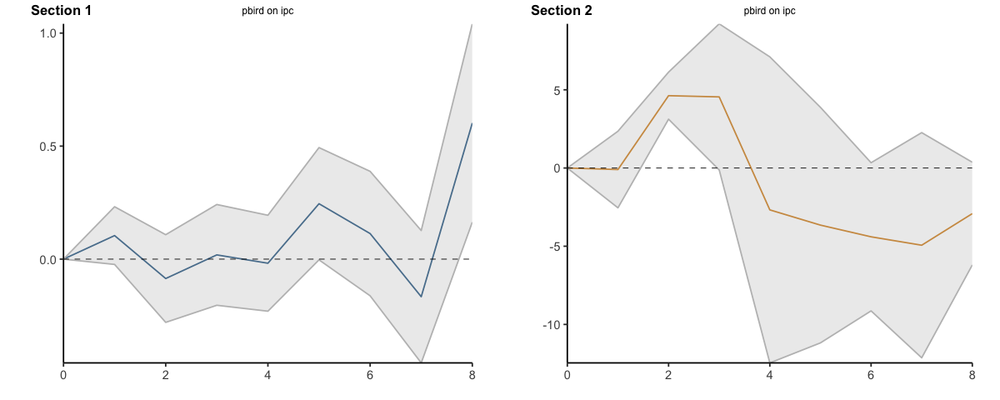

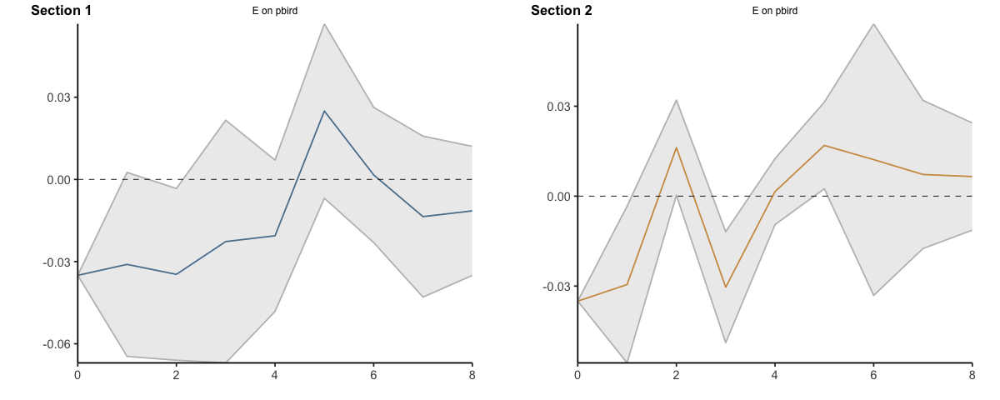

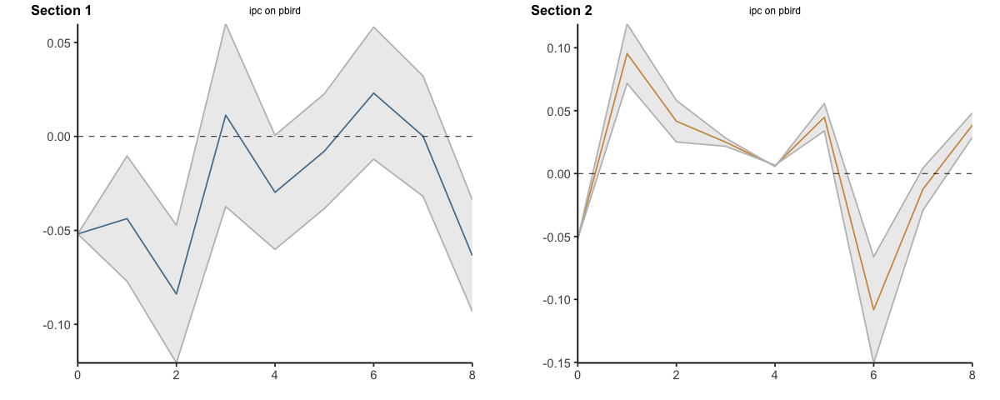

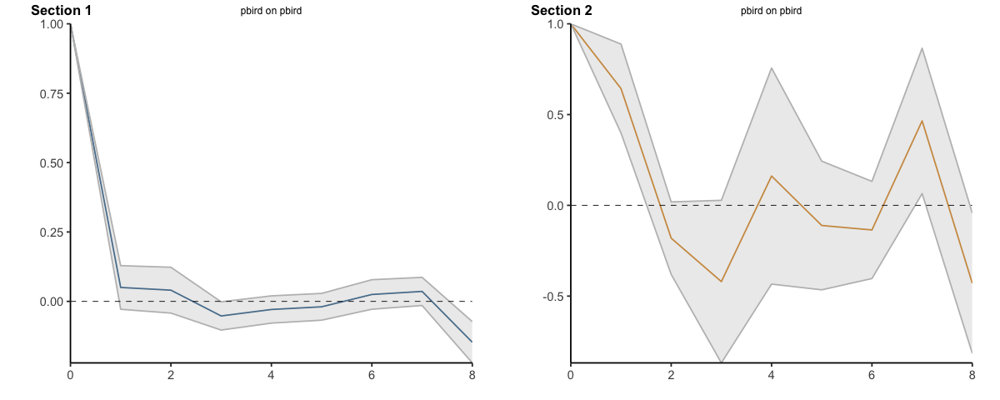

In [27]:
res <- run_lp_model(df_ERPT_Arg, endog=c("E", "ipc", "pbird"), exog=c("impp_usa"), fixed_lags = 2, horizons=8, signif = 0.68, threshold_var = 'ipc', upper_threshold=0.932203389830508)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<dbl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,2,NaN,NA,2,0,1,0.68,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,295,"E, ipc, pbird",3


Impulse: E -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,0,0.4574976,0.4574976,0.4574976,0.4574976,0.4574976,0.4574976
2,1,0.9297633,0.8217666,1.0377599,1.2570574,1.1558374,1.3582775
3,2,1.3474682,1.0583612,1.6365753,1.4415167,1.1140895,1.7689439
4,3,1.6467176,1.1640791,2.1293561,2.0190688,1.3741798,2.6639578
5,4,2.0925683,1.4435382,2.7415985,2.2829977,1.3250196,3.2409758
6,5,2.3976113,1.5545796,3.2406429,2.4380474,1.3613216,3.5147732
7,6,2.7882171,1.7602876,3.8161465,2.5283060,0.9938245,4.0627874
8,7,3.4137516,2.0666947,4.7608084,2.6378629,1.0426030,4.2331228
9,8,3.9116047,2.2881768,5.5350326,2.7325613,1.0698862,4.3952364


Impulse: E -> Response: pbird

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
10,0,-0.03501996,-0.03501996,-0.035019959,-0.03501996,-0.03501996,-0.035019959
11,1,-0.06604246,-0.09962504,-0.032459886,-0.06451513,-0.09064496,-0.038385311
12,2,-0.10070028,-0.16562777,-0.035772790,-0.04834451,-0.09036136,-0.006327654
13,3,-0.12338845,-0.23261089,-0.014166014,-0.07872162,-0.13925010,-0.018193131
14,4,-0.14395855,-0.28080969,-0.007107416,-0.07720929,-0.14873484,-0.005683747
15,5,-0.11899201,-0.28767882,0.049694803,-0.06028745,-0.14627144,0.025696531
16,6,-0.11734388,-0.31071800,0.076030244,-0.04810220,-0.17938018,0.083175768
17,7,-0.13092700,-0.35368420,0.091830200,-0.04087498,-0.19685564,0.115105674
18,8,-0.14241133,-0.38872363,0.103900973,-0.03434372,-0.20820564,0.139518208


... (4 outputs left out)

Impulse: pbird -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
37,0,0.0000000,0.000000,0.0000000,0.0000000,0.000000,0.0000000
38,1,-0.7695065,-1.224133,-0.3148794,-3.7611111,-6.843882,-0.6783406
39,2,-1.3123830,-2.227838,-0.3969279,3.5627956,-1.327459,8.4530507
40,3,-1.5916280,-2.881361,-0.3018954,5.8266055,-6.633745,18.2869558
41,4,-1.8861922,-3.518399,-0.2539854,1.0912028,-23.831806,26.0142112
42,5,-1.2140330,-3.312368,0.8843017,-0.8525624,-32.517718,30.8125931
43,6,-1.6231348,-4.137562,0.8912923,-5.8881360,-42.104742,30.3284704
44,7,-1.9654615,-4.858585,0.9276619,-9.4010609,-51.827269,33.0251474
45,8,-1.5945569,-5.006729,1.8176149,-10.8086673,-55.905591,34.2882566


Impulse: pbird -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
46,0,0.00000000,0.0000000,0.0000000,0.00000000,0.0000000,0.000000
47,1,0.10418299,-0.0234883,0.2318543,-0.09746834,-2.5461025,2.351166
48,2,0.01834751,-0.3032847,0.3399797,4.52718207,0.5735347,8.480829
49,3,0.03709772,-0.5074437,0.5816392,9.07315745,0.4478432,17.698472
50,4,0.01898368,-0.7377982,0.7757656,6.39681109,-12.0117241,24.805346
51,5,0.26410125,-0.7410491,1.2692516,2.74638450,-23.1917750,28.684544
52,6,0.37718861,-0.9032607,1.6576379,-1.65151829,-32.3261015,29.023065
53,7,0.21089392,-1.3623692,1.7841571,-6.58712758,-44.4597772,31.285522
54,8,0.81303968,-1.1990857,2.8251651,-9.50223354,-50.6570549,31.652588


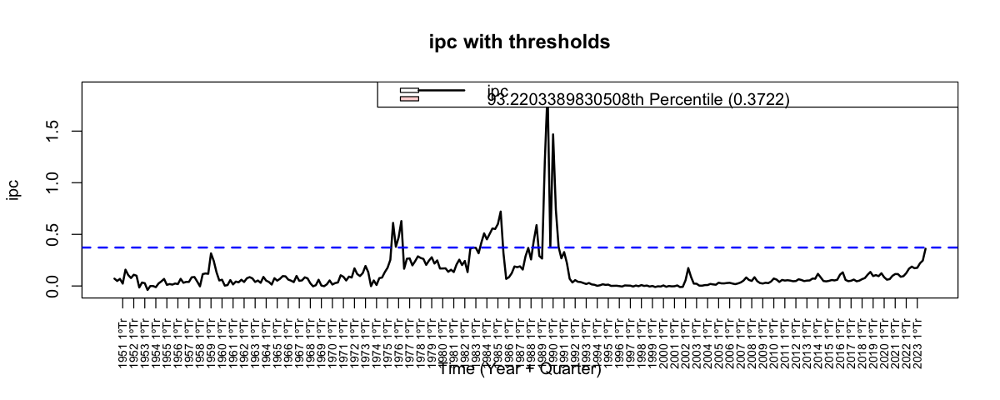

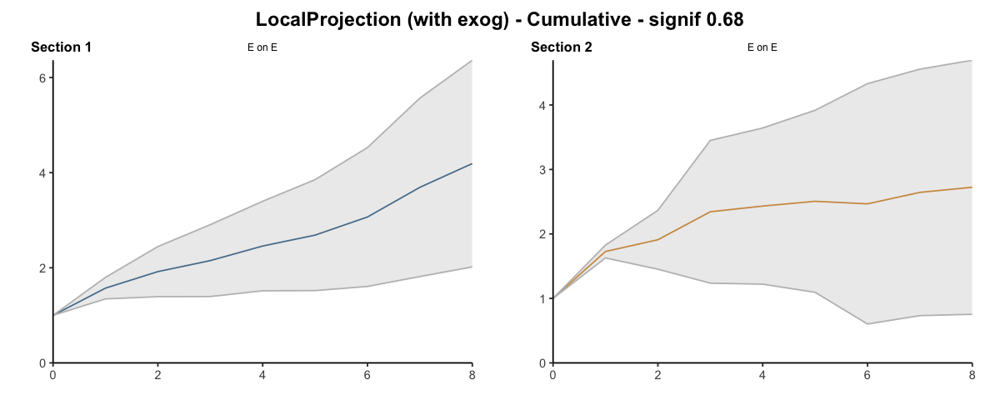

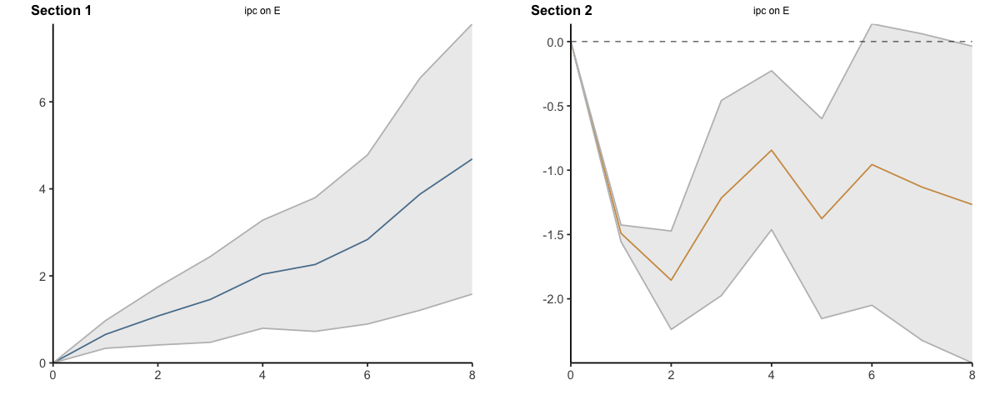

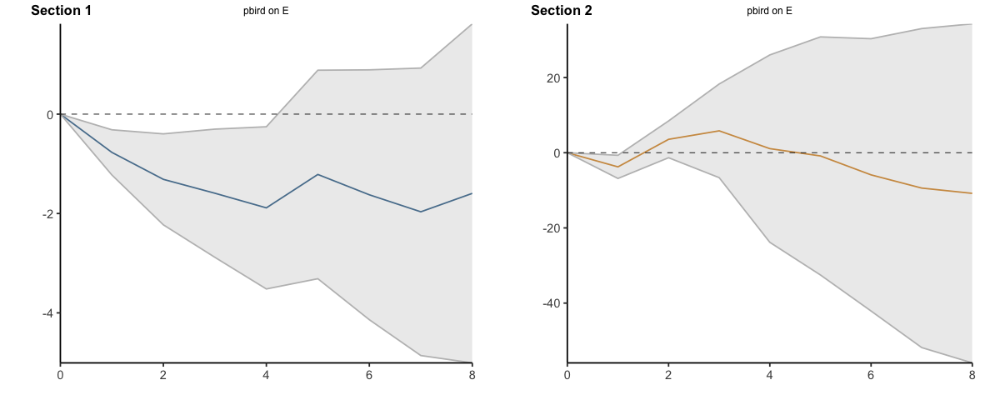

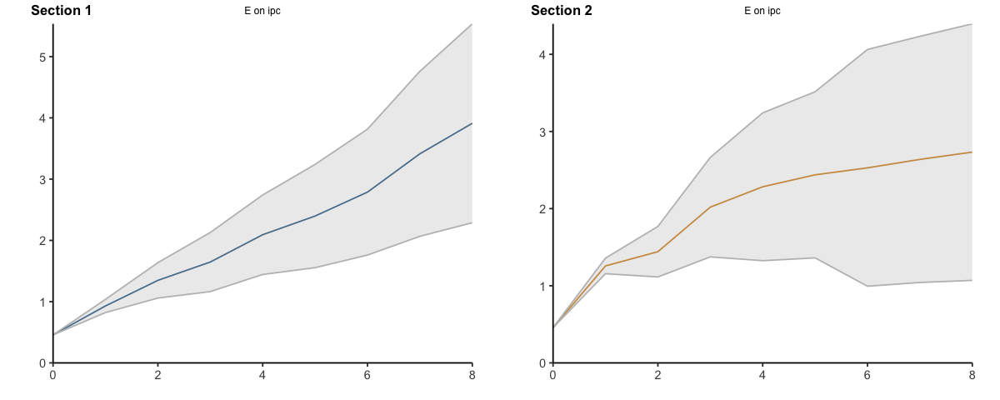

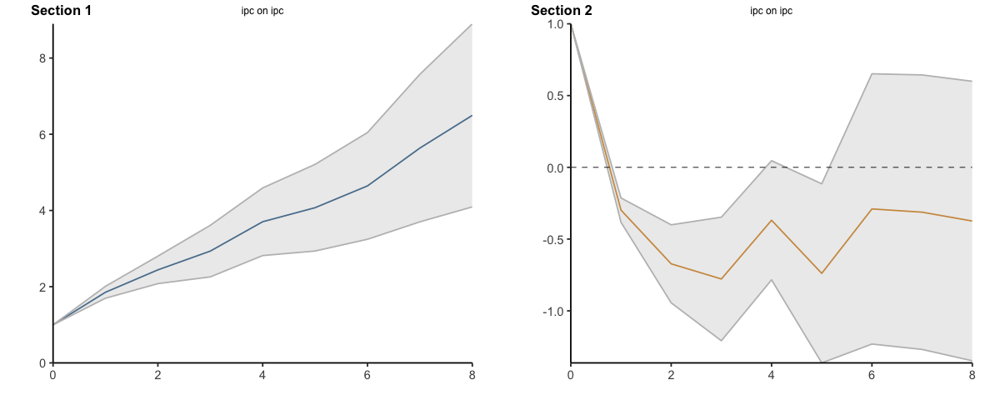

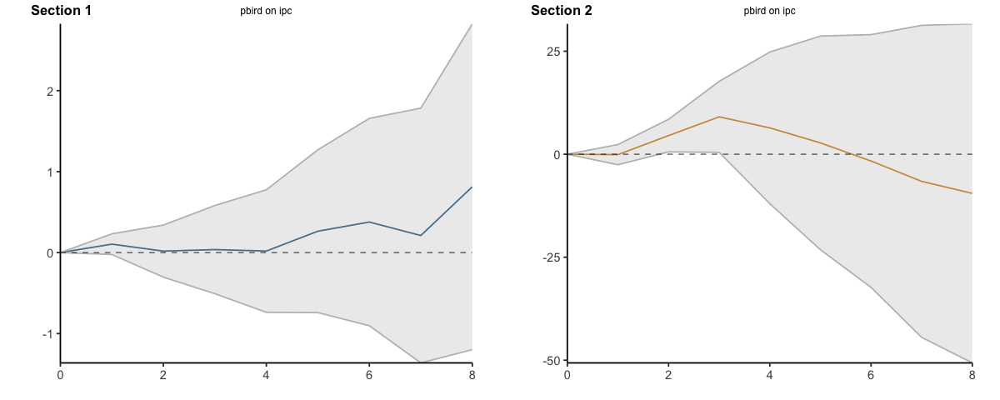

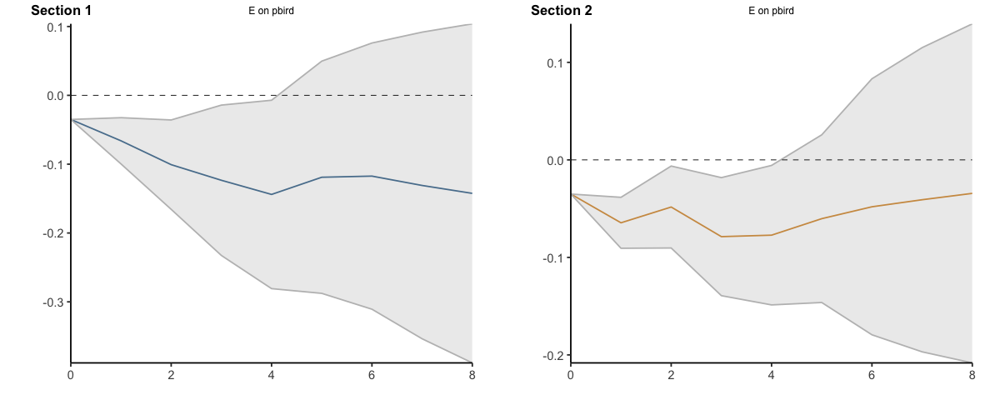

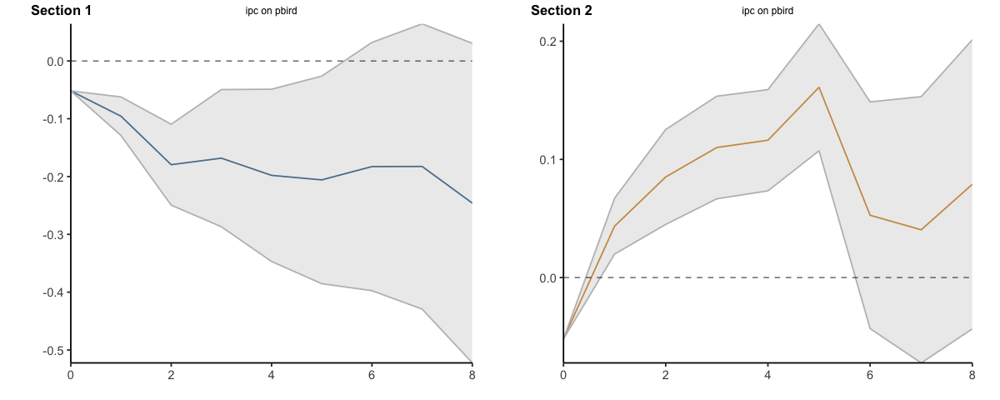

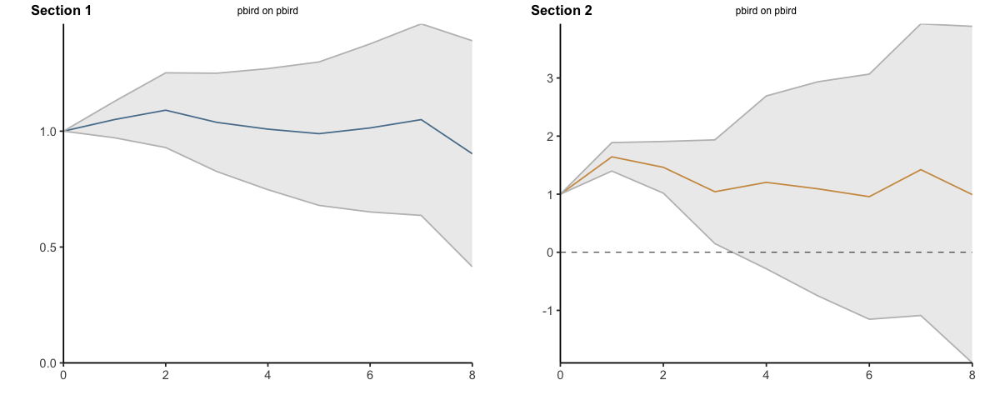

In [28]:
res <- run_lp_model(df_ERPT_Arg, endog=c("E", "ipc", "pbird"), exog=c("impp_usa"), fixed_lags = 2, horizons=8, signif = 0.68, threshold_var = 'ipc', upper_threshold=0.932203389830508, cumulative = TRUE)

#### Percentile 0.932203389830508 (37,6% inflación trimestral) - quedan 20 trimestres por encima del umbral (es poco)

Umbral: ipc > 0.3722 (percentil 93.2 )
Trimestres por régimen: debajo del umbral (dummy = 0) = 275 | encima del umbral (dummy = 1) = 20 


Bootstrap por bloques circular: 500 réplicas, bloques de 20 trimestres...



  |======================================================================| 100%


10 réplicas fallaron y se descartaron.



ERPT de un shock unitario en E sobre ipc ( LP, 2 rezagos, exógenas: impp_usa, umbral: ipc > 0,372, 20 trimestres encima )

Régimen 1 (debajo del umbral)
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.4575         0.4575       1.0000
         1              0.9298         0.5914       1.5721
         2              1.3475         0.7020       1.9194
         3              1.6467         0.7656       2.1508
         4              2.0926         0.8516       2.4573
         5              2.3976         0.8924       2.6867
         6              2.7882         0.9088       3.0680
         7              3.4138         0.9247       3.6918
         8              3.9116         0.9333       4.1911
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.4575             0.4575
                  0.4723             0.1339
                  0.4177             0.1106
                  0.2992             0.0636
                  0.4459             

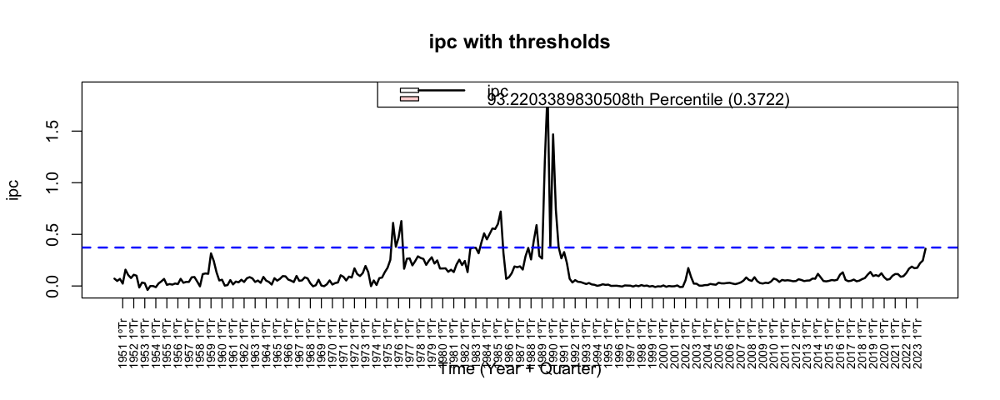

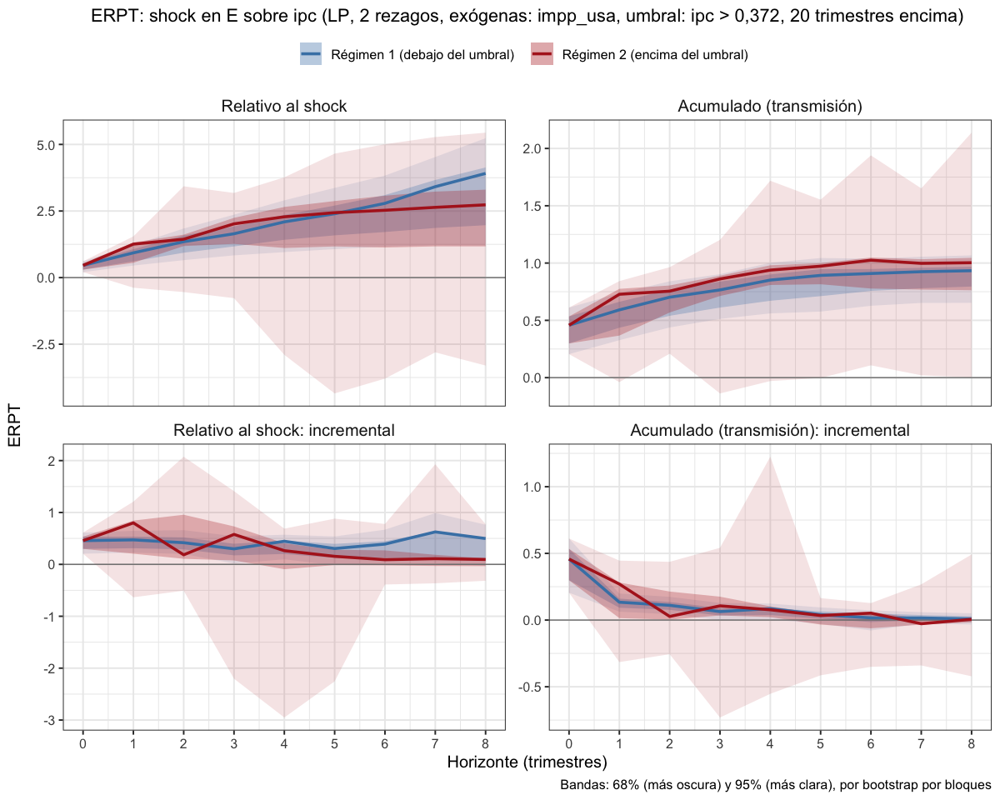

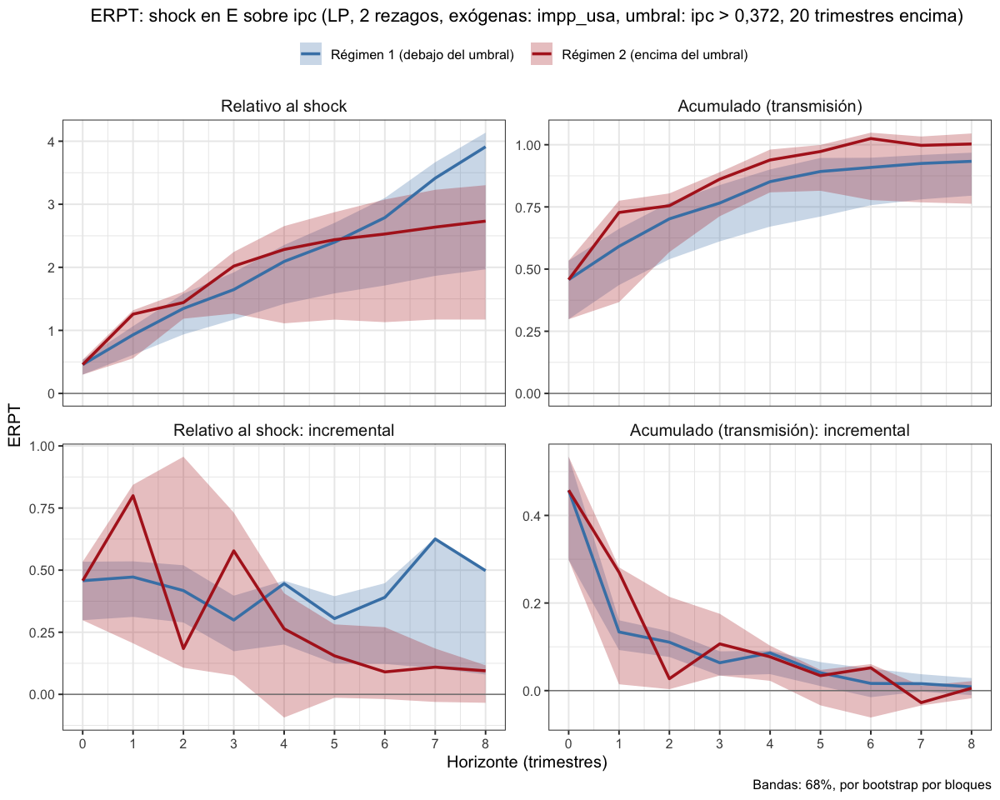

In [29]:
# 1 exógena y el resto endógenas con umbral en 37,6% de inflación trimestral (umbral del TVAR-indt), 2 rezagos
lp_erpt_exog_p2_tvar37.6 <- erpt_lp(df_ERPT_Arg, endog = c("E", "ipc", "pbird"), exog = c("impp_usa"),
                                    fixed_lags = 2, horizons = 8, reps = 500,
                                    threshold_var = "ipc", upper_threshold = 0.932203389830508)
saveRDS(lp_erpt_exog_p2_tvar37.6, "lp_erpt_exog_p2_tvar37.6.rds")
graficar_erpt_lp(lp_erpt_exog_p2_tvar37.6, archivo = "lp_erpt_exog_p2_tvar37.6")
graficar_erpt_lp(lp_erpt_exog_p2_tvar37.6, niveles = 0.68, archivo = "lp_erpt_exog_p2_tvar37.6_68")

### 1 exógena y el resto endógenas - 5 lags

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<dbl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
5,5,NaN,NA,5,0,1,0.68,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,295,"E, ipc, pbird",3


Impulse: E -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,0,0.434994713,0.434994713,0.43499471,0.4349947,0.434994713,0.4349947
2,1,0.319081192,0.227002530,0.41115985,0.5821183,0.331964820,0.8322719
3,2,0.177147292,0.044557297,0.30973729,0.2274005,-0.009385357,0.4641864
4,3,0.112018993,-0.056389534,0.28042752,0.4672544,0.237610732,0.6968981
5,4,0.127142083,-0.008783556,0.26306772,0.3361826,0.161351364,0.5110138
6,5,0.003124894,-0.184210461,0.19046025,0.2654502,0.098984475,0.4319160
7,6,-0.032298679,-0.218490948,0.15389359,0.1395650,-0.087552213,0.3666821
8,7,0.007938149,-0.179389931,0.19526623,0.3251148,0.096781648,0.5534480
9,8,-0.147394473,-0.355430366,0.06064142,0.1926800,0.050731039,0.3346289


Impulse: E -> Response: pbird

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
10,0,-0.03149282,-0.031492818,-0.03149282,-0.031492818,-0.0314928184,-0.031492818
11,1,0.01962149,-0.034872950,0.07411593,-0.023615644,-0.0451023192,-0.002128969
12,2,-0.04628148,-0.088103876,-0.00445908,0.011818299,-0.0044603956,0.028096994
13,3,-0.07119887,-0.124896562,-0.01750117,-0.026394676,-0.0610660060,0.008276654
14,4,-0.04214584,-0.097331493,0.01303980,-0.006004177,-0.0227921399,0.010783786
15,5,0.06930498,0.001153471,0.13745649,0.012802358,-0.0026557591,0.028260476
16,6,0.01115786,-0.039289077,0.06160480,0.001838946,-0.0119129954,0.015590888
17,7,0.01626533,-0.045282732,0.07781339,-0.013545999,-0.0287944575,0.001702459
18,8,-0.03763023,-0.085521452,0.01026099,0.014810052,-0.0003908753,0.030010980


... (4 outputs left out)

Impulse: pbird -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
37,0,0.0000000,0.0000000,0.00000000,0.0000000,0.0000000,0.0000000
38,1,-0.7410644,-1.1064962,-0.37563260,-0.2401657,-1.1812838,0.7009524
39,2,-1.0139169,-1.5465440,-0.48128969,1.7804970,0.8850313,2.6759627
40,3,-0.4255061,-0.7727603,-0.07825195,0.1669520,-1.1935891,1.5274932
41,4,-0.2793244,-0.6427111,0.08406238,1.1335335,-0.1084656,2.3755326
42,5,0.2196374,-0.2752394,0.71451428,1.7833371,0.6933166,2.8733576
43,6,-0.4895843,-0.8084596,-0.17070907,-1.7161984,-3.3152554,-0.1171414
44,7,-0.7742219,-1.2231576,-0.32528615,0.4593371,-0.6183804,1.5370546
45,8,-1.0739422,-1.5025502,-0.64533428,4.0852071,1.7353185,6.4350956


Impulse: pbird -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
46,0,0.0000000,0.0000000,0.00000000,0.0000000,0.0000000,0.000000
47,1,-0.1171734,-0.2489515,0.01460481,0.7341448,0.1629178,1.305372
48,2,-0.3040732,-0.5153204,-0.09282596,1.8015185,1.1176845,2.485353
49,3,-0.2330164,-0.4386208,-0.02741197,0.5965730,-0.5036753,1.696821
50,4,-0.2456174,-0.4446708,-0.04656399,1.6470961,0.8261223,2.468070
51,5,-0.1953192,-0.4107462,0.02010784,1.5843893,0.8713625,2.297416
52,6,-0.3391384,-0.5746006,-0.10367631,0.3104547,-0.5465704,1.167480
53,7,-0.3926635,-0.6154050,-0.16992207,-0.4285198,-1.4866205,0.629581
54,8,-0.4363637,-0.7216891,-0.15103821,3.0923350,1.1966207,4.988049


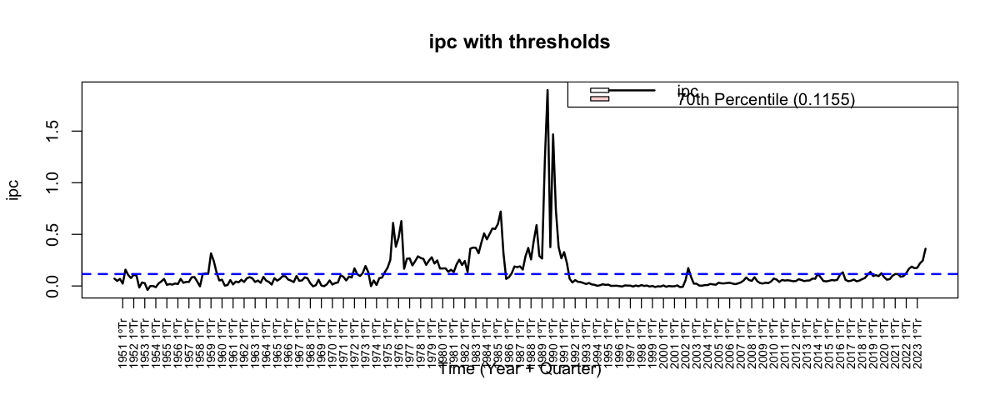

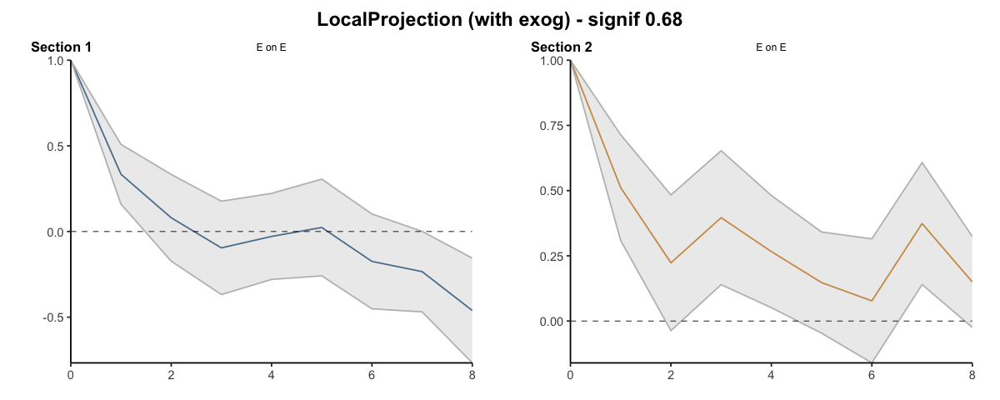

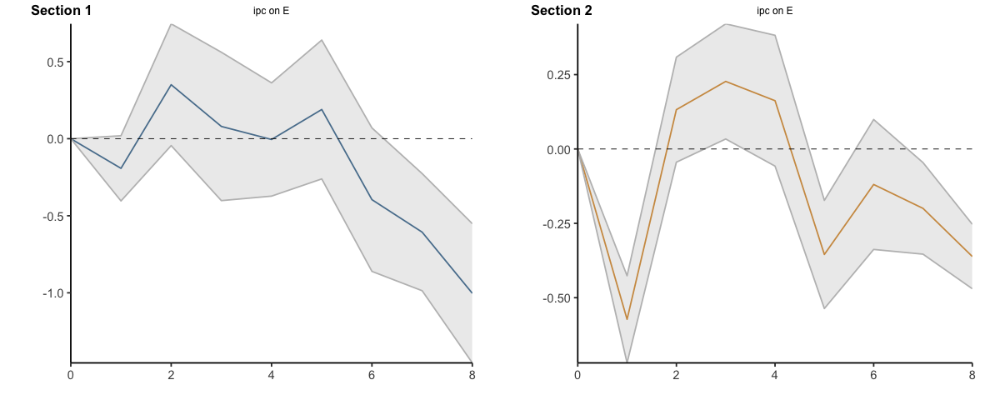

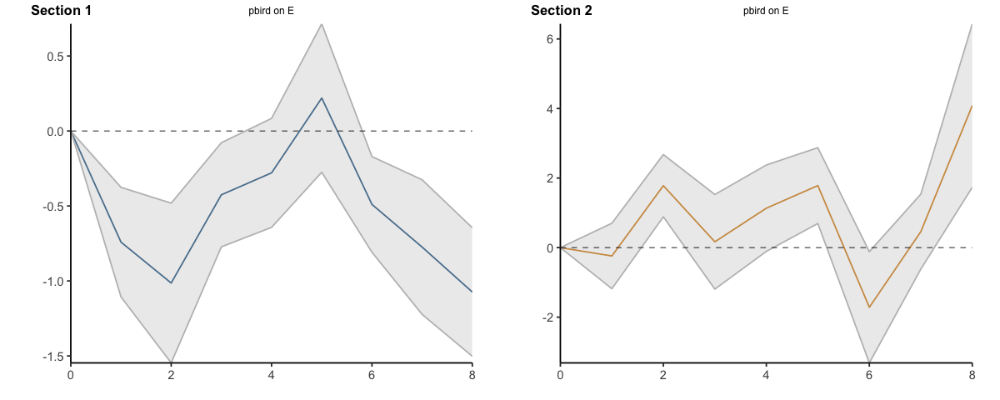

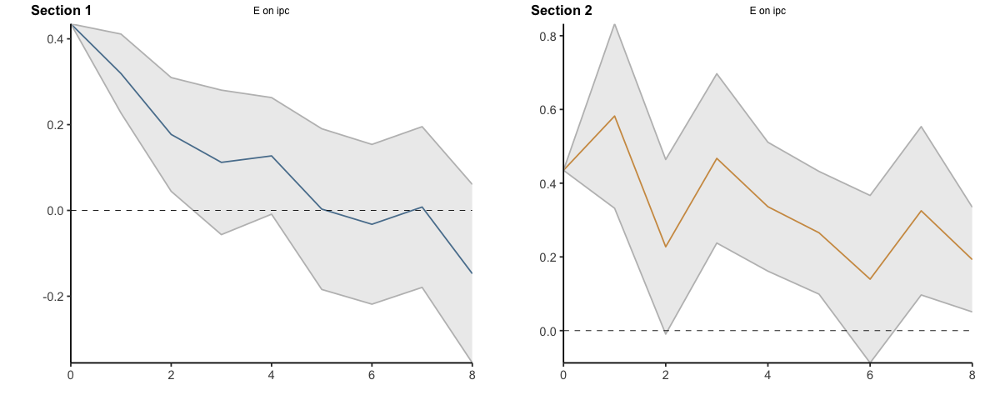

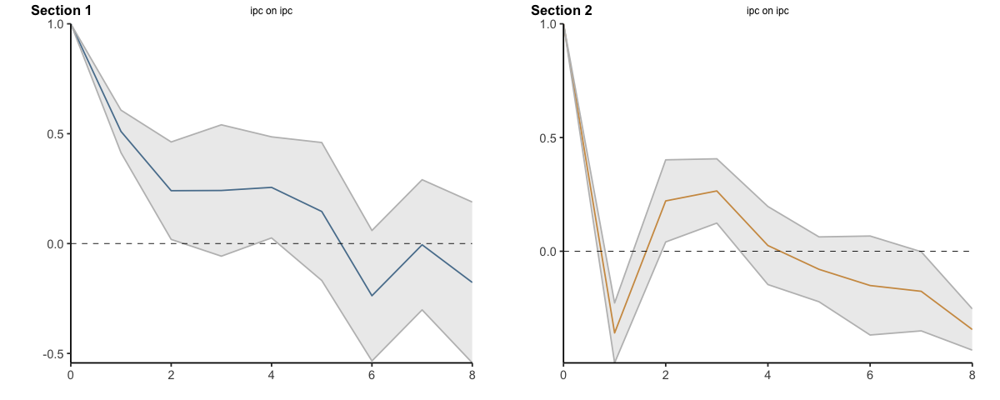

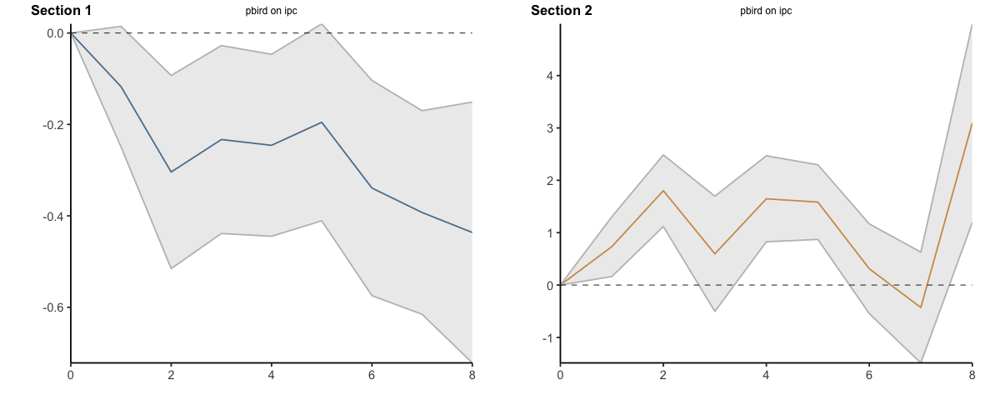

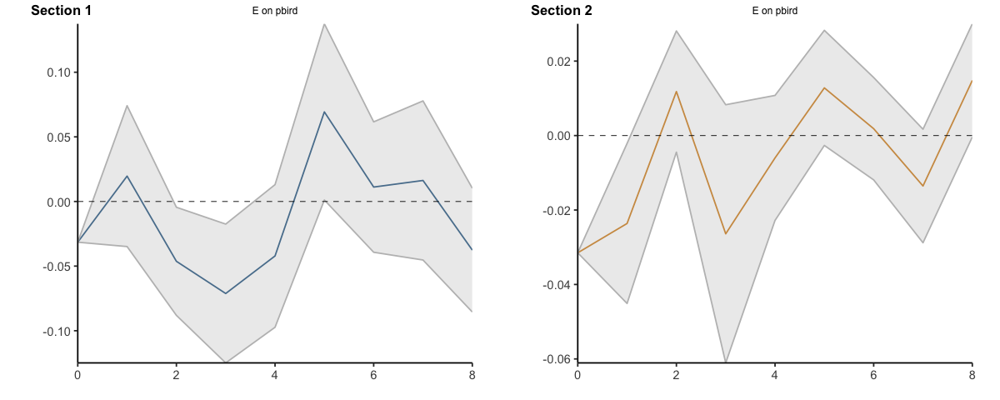

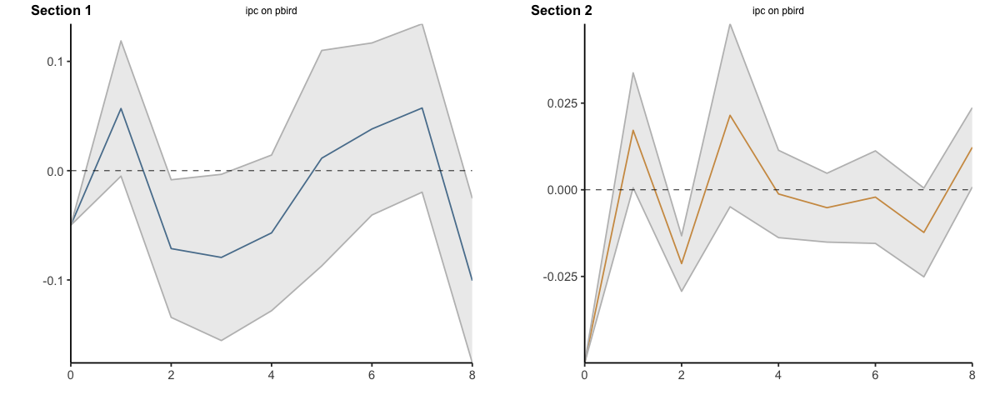

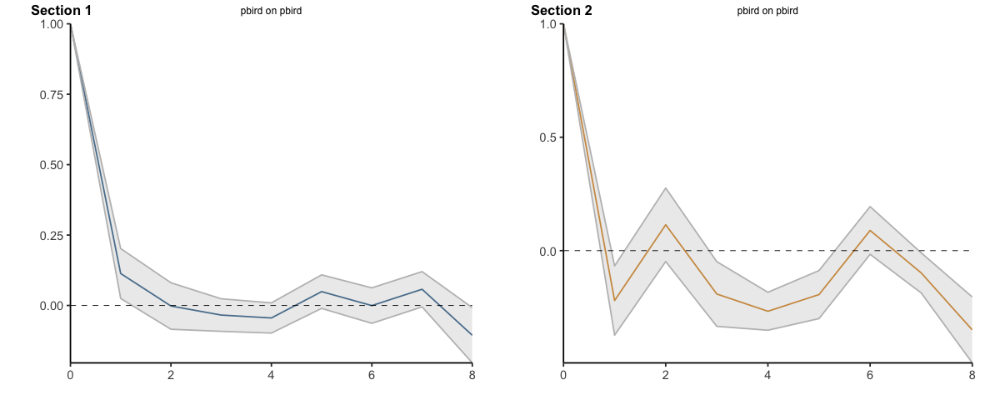

In [40]:
res <- run_lp_model(df_ERPT_Arg, endog=c("E", "ipc", "pbird"), exog=c("impp_usa"), fixed_lags = 5, horizons=8, signif = 0.68, threshold_var = 'ipc', upper_threshold=0.7)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<dbl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
5,5,NaN,NA,5,0,1,0.68,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,295,"E, ipc, pbird",3


Impulse: E -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,0,0.4349947,0.43499471,0.4349947,0.4349947,0.4349947,0.4349947
2,1,0.7540759,0.66199724,0.8461546,1.0171131,0.7669595,1.2672666
3,2,0.9312232,0.70655454,1.1558919,1.2445136,0.7575742,1.7314530
4,3,1.0432422,0.65016501,1.4363194,1.7117680,0.9951849,2.4283511
5,4,1.1703843,0.64138145,1.6993871,2.0479506,1.1565363,2.9393649
6,5,1.1735092,0.45717099,1.8898473,2.3134008,1.2555207,3.3712809
7,6,1.1412105,0.23868004,2.0437409,2.4529658,1.1679685,3.7379630
8,7,1.1491486,0.05929011,2.2390072,2.7780806,1.2647502,4.2914110
9,8,1.0017542,-0.29614026,2.2996486,2.9707606,1.3154812,4.6260400


Impulse: E -> Response: pbird

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
10,0,-0.03149282,-0.03149282,-0.03149282,-0.03149282,-0.03149282,-0.031492818
11,1,-0.01187133,-0.06636577,0.04262312,-0.05510846,-0.07659514,-0.033621787
12,2,-0.05815280,-0.15446964,0.03816403,-0.04329016,-0.08105553,-0.005524793
13,3,-0.12935167,-0.27936621,0.02066287,-0.06968484,-0.14212154,0.002751861
14,4,-0.17149752,-0.37669770,0.03370267,-0.07568902,-0.16491368,0.013535647
15,5,-0.10219254,-0.37554423,0.17115916,-0.06288666,-0.16756944,0.041796123
16,6,-0.09103467,-0.41483330,0.23276396,-0.06104771,-0.17948243,0.057387011
17,7,-0.07476935,-0.46011604,0.31057735,-0.07459371,-0.20827689,0.059089470
18,8,-0.11239958,-0.54563749,0.32083834,-0.05978366,-0.20866777,0.089100450


... (4 outputs left out)

Impulse: pbird -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
37,0,0.0000000,0.000000,0.0000000,0.0000000,0.0000000,0.0000000
38,1,-0.7410644,-1.106496,-0.3756326,-0.2401657,-1.1812838,0.7009524
39,2,-1.7549813,-2.653040,-0.8569223,1.5403313,-0.2962525,3.3769152
40,3,-2.1804874,-3.425801,-0.9351742,1.7072834,-1.4898416,4.9044083
41,4,-2.4598117,-4.068512,-0.8511119,2.8408168,-1.5983072,7.2799409
42,5,-2.2401743,-4.343751,-0.1365976,4.6241539,-0.9049906,10.1532985
43,6,-2.7297586,-5.152211,-0.3073066,2.9079555,-4.2202460,10.0361571
44,7,-3.5039805,-6.375368,-0.6325928,3.3672926,-4.8386265,11.5732116
45,8,-4.5779227,-7.877918,-1.2779271,7.4524996,-3.1033080,18.0083072


Impulse: pbird -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
46,0,0.0000000,0.0000000,0.00000000,0.0000000,0.0000000,0.000000
47,1,-0.1171734,-0.2489515,0.01460481,0.7341448,0.1629178,1.305372
48,2,-0.4212465,-0.7642719,-0.07822115,2.5356634,1.2806023,3.790724
49,3,-0.6542629,-1.2028927,-0.10563312,3.1322364,0.7769270,5.487546
50,4,-0.8998803,-1.6475635,-0.15219711,4.7793325,1.6030493,7.955616
51,5,-1.0951995,-2.0583097,-0.13208927,6.3637219,2.4744117,10.253032
52,6,-1.4343379,-2.6329103,-0.23576558,6.6741765,1.9278413,11.420512
53,7,-1.8270015,-3.2483153,-0.40568765,6.2456568,0.4412208,12.050093
54,8,-2.2633651,-3.9700044,-0.55672585,9.3379917,1.6378415,17.038142


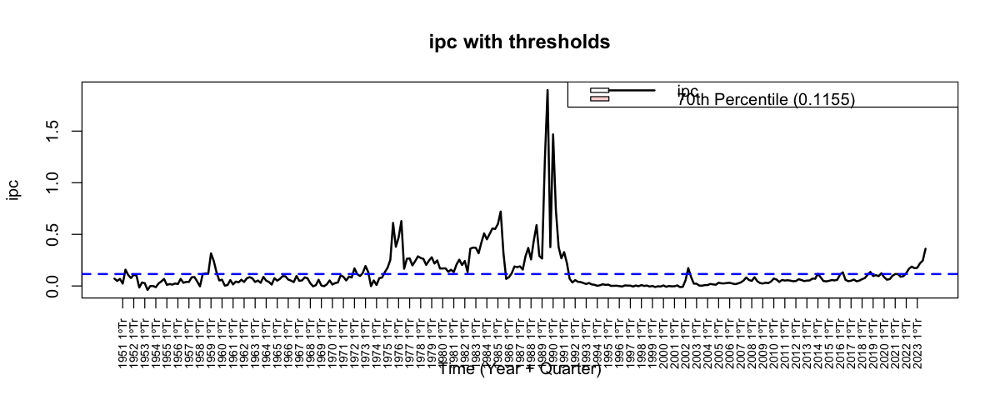

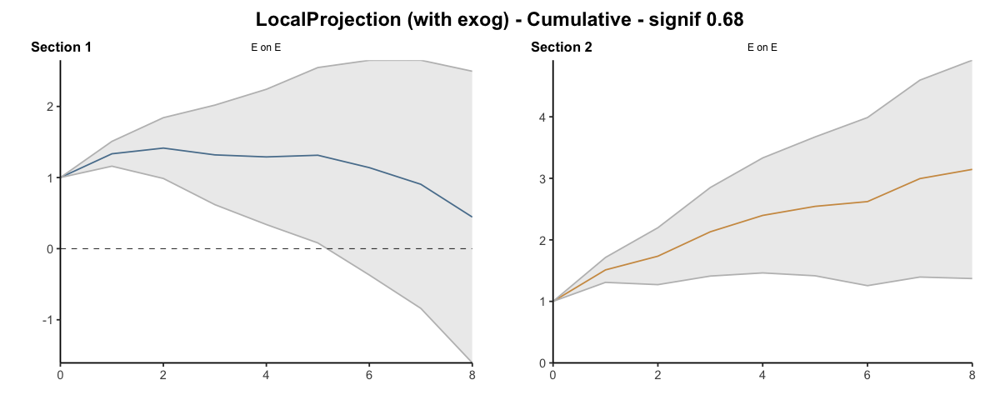

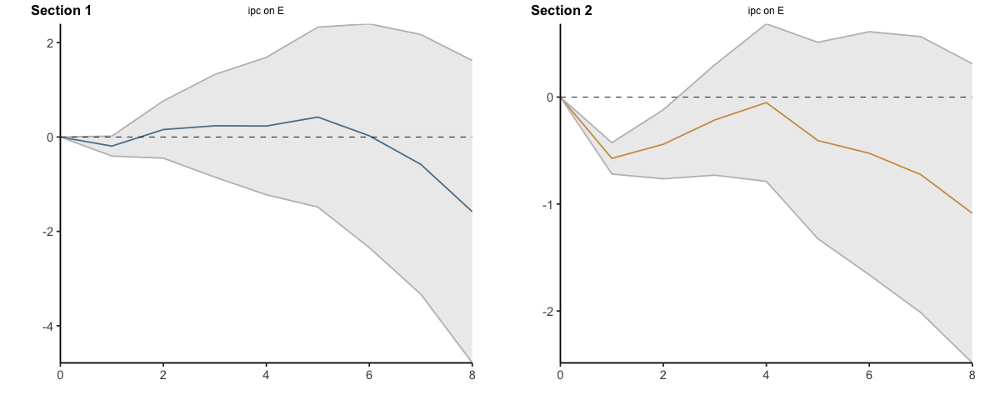

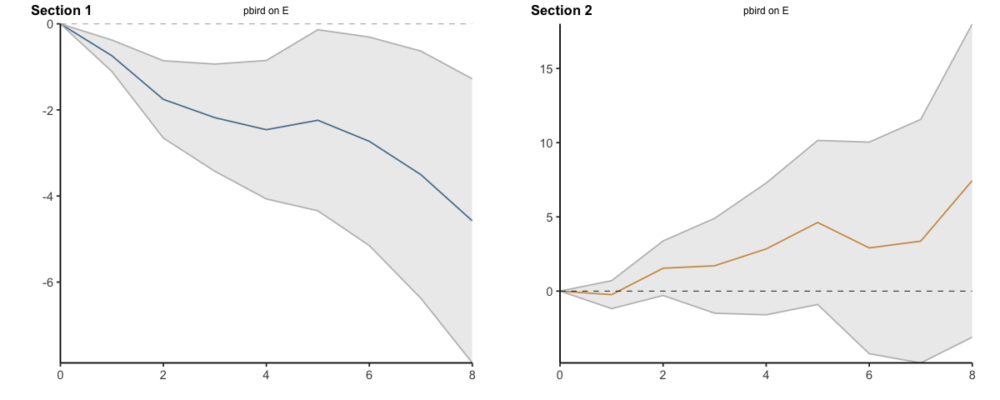

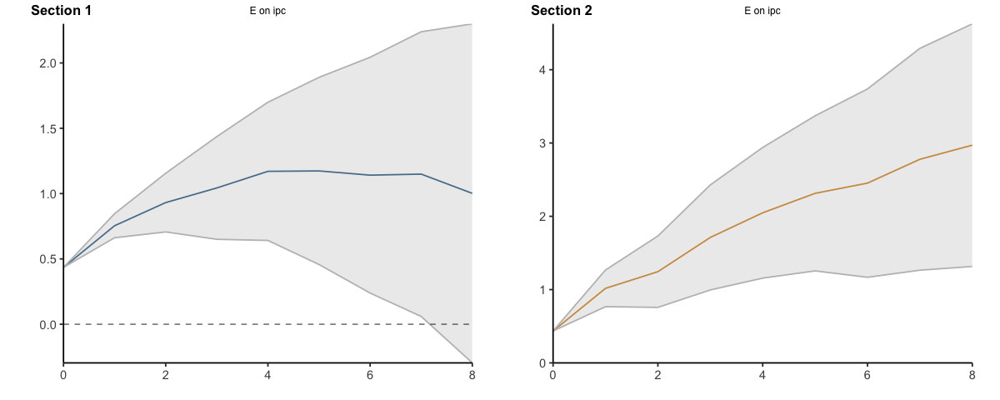

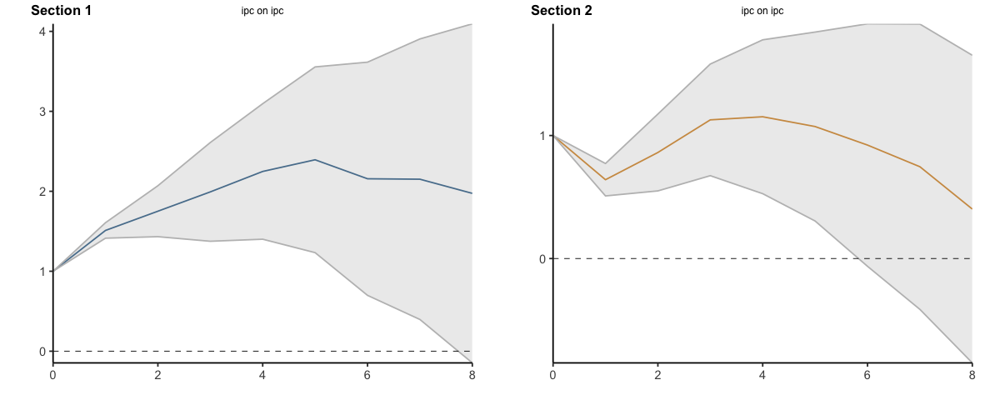

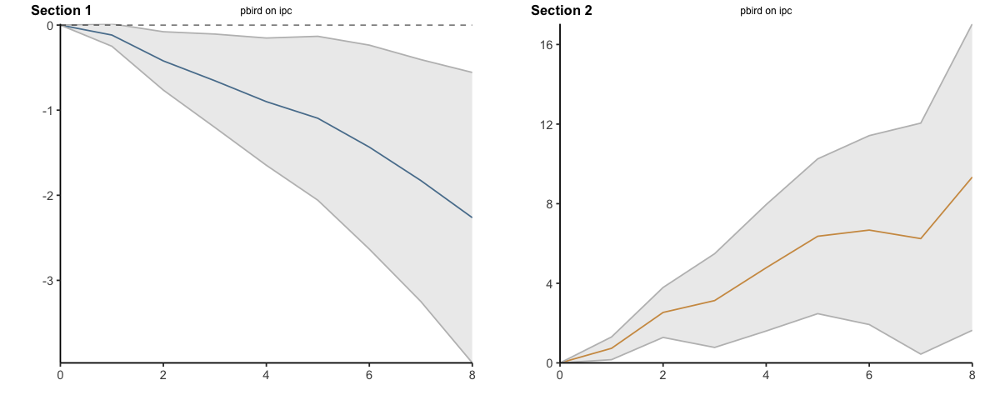

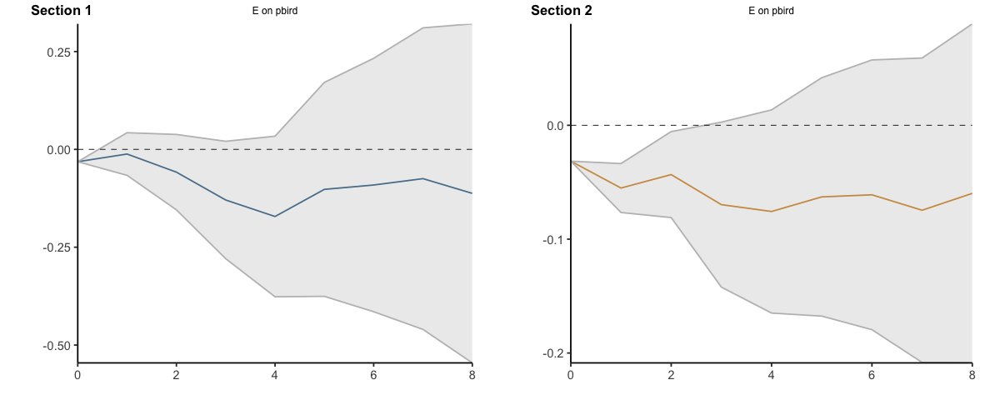

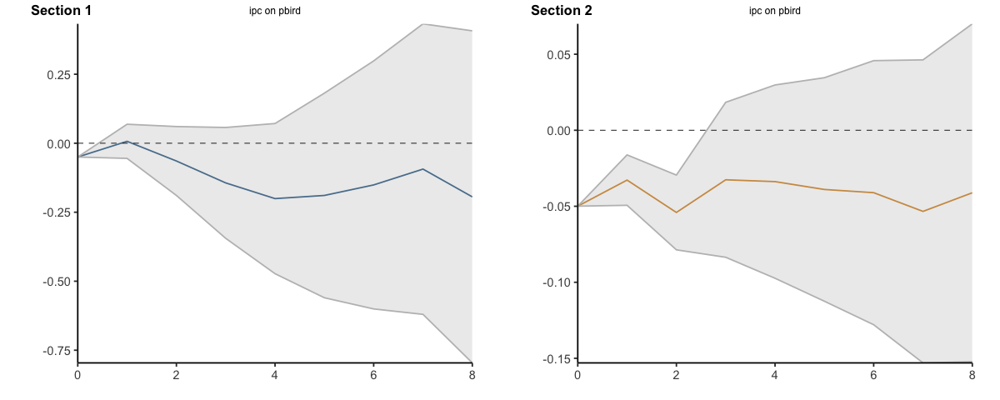

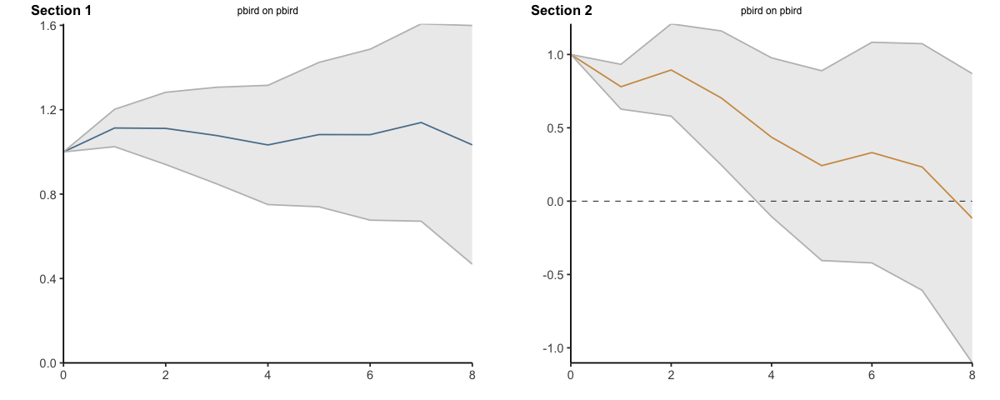

In [41]:
res <- run_lp_model(df_ERPT_Arg, endog=c("E", "ipc", "pbird"), exog=c("impp_usa"), fixed_lags = 5, horizons=8, signif = 0.68, threshold_var = 'ipc', upper_threshold=0.7, cumulative=TRUE)

#### Percentile 70 - 5 lags

Umbral: ipc > 0.1155 (percentil 70 )
Trimestres por régimen: debajo del umbral (dummy = 0) = 206 | encima del umbral (dummy = 1) = 89 


Bootstrap por bloques circular: 500 réplicas, bloques de 26 trimestres...



  |======================================================================| 100%


Aviso (Régimen 1 (debajo del umbral)): en más del 5% de las réplicas la depreciación acumulada es casi cero en h = 4, 8; las bandas del ERPT acumulado en esos horizontes son poco confiables.



ERPT de un shock unitario en E sobre ipc ( LP, 5 rezagos, exógenas: impp_usa, umbral: ipc > 0,115, 89 trimestres encima )

Régimen 1 (debajo del umbral)
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.4350         0.4350       1.0000
         1              0.7541         0.5653       1.3341
         2              0.9312         0.6584       1.4144
         3              1.0432         0.7910       1.3189
         4              1.1704         0.9071       1.2903
         5              1.1735         0.8932       1.3138
         6              1.1412         1.0016       1.1394
         7              1.1491         1.2692       0.9054
         8              1.0018         2.2549       0.4442
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.4350             0.4350
                  0.3191             0.1303
                  0.1771             0.0931
                  0.1120             0.1326
                  0.1271             

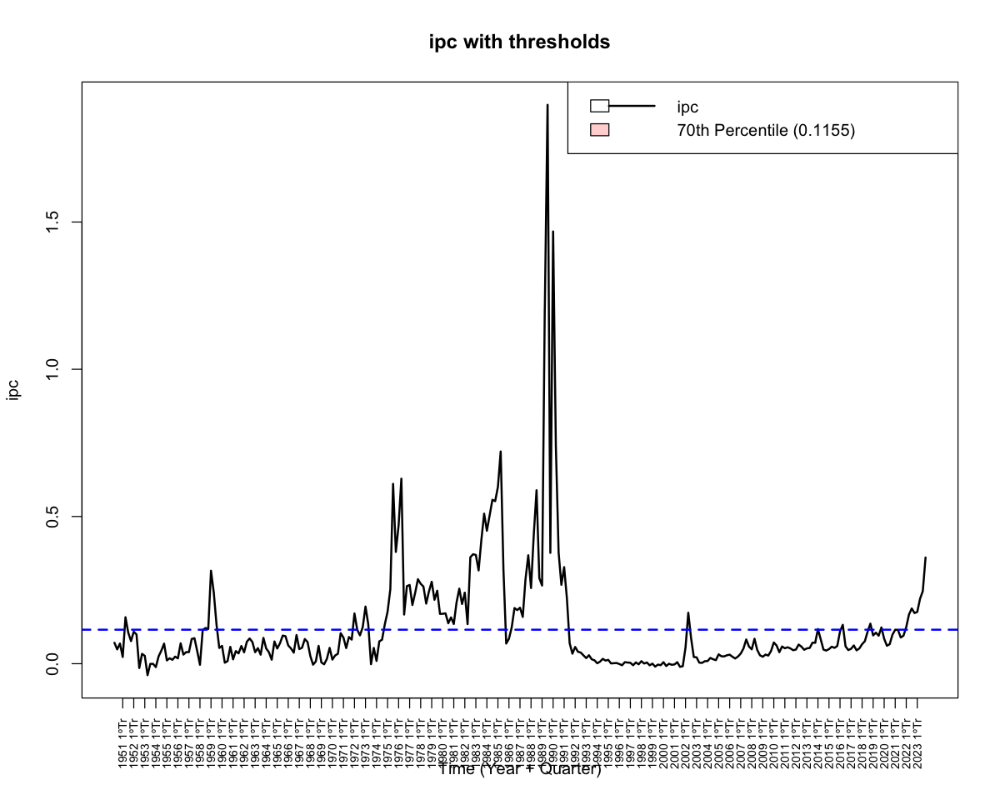

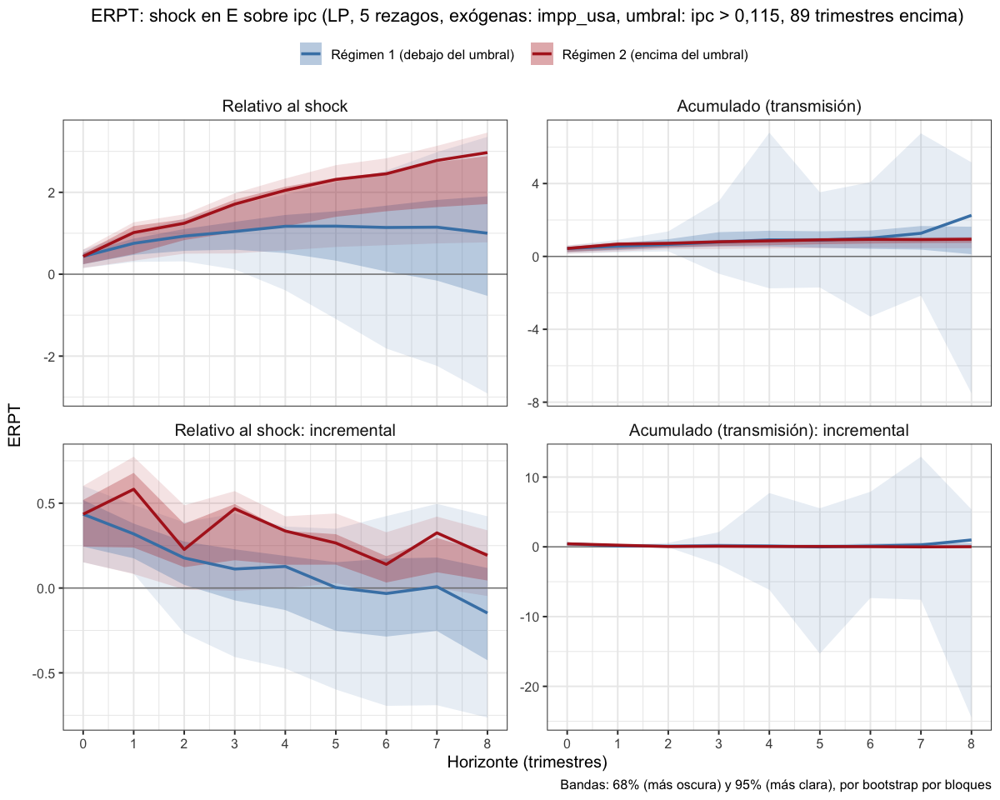

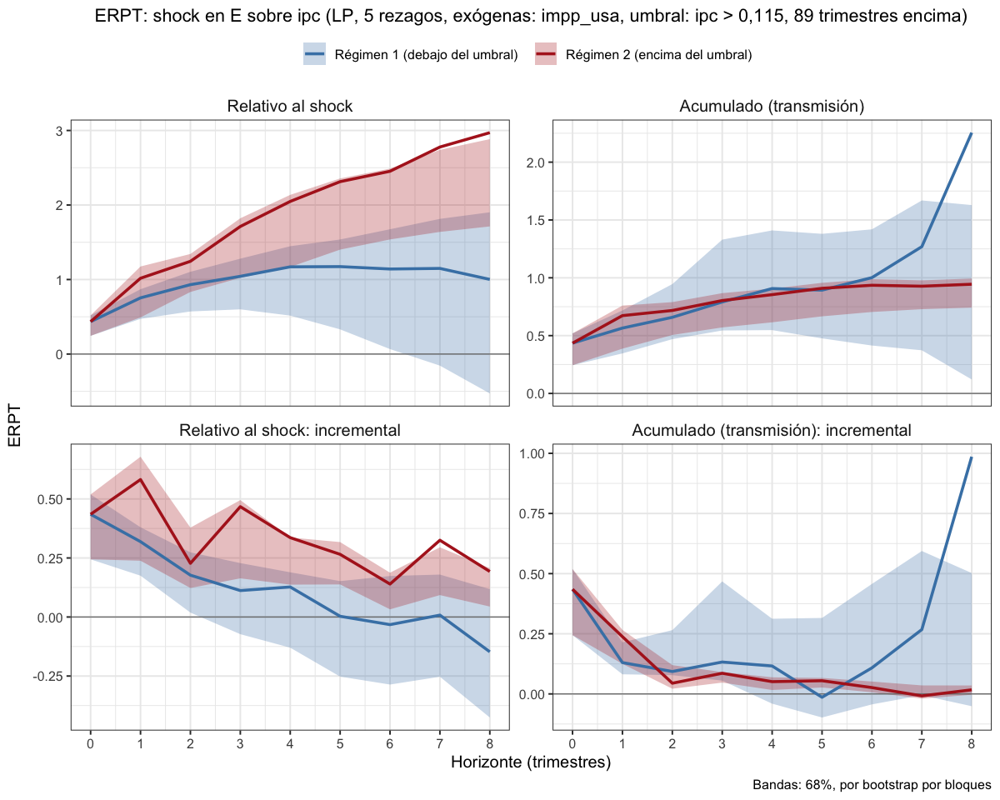

In [30]:
# 1 exógena y el resto endógenas con umbral en el percentil 70 del ipc, 5 rezagos
lp_erpt_exog_p5_u70 <- erpt_lp(df_ERPT_Arg, endog = c("E", "ipc", "pbird"), exog = c("impp_usa"),
                                fixed_lags = 5, horizons = 8, reps = 500,
                                threshold_var = "ipc", upper_threshold = 0.7)
saveRDS(lp_erpt_exog_p5_u70, "lp_erpt_exog_p5_u70.rds")
graficar_erpt_lp(lp_erpt_exog_p5_u70, archivo = "lp_erpt_exog_p5_u70")
graficar_erpt_lp(lp_erpt_exog_p5_u70, niveles = 0.68, archivo = "lp_erpt_exog_p5_u70_68")

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<dbl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
5,5,NaN,NA,5,0,1,0.68,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,295,"E, ipc, pbird",3


Impulse: E -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,0,0.434994713,0.43499471,0.43499471,0.4349947,0.434994713,0.4349947
2,1,0.384791864,0.27830501,0.49127872,0.5933764,0.327757908,0.8589949
3,2,0.226798783,0.08243996,0.37115760,0.2352376,-0.007820231,0.4782954
4,3,0.122188771,-0.05367278,0.29805032,0.4784272,0.240436843,0.7164176
5,4,0.132724724,0.00315976,0.26228969,0.3466373,0.161593717,0.5316809
6,5,0.020168322,-0.15372706,0.19406371,0.2874017,0.111375948,0.4634274
7,6,0.003193687,-0.17558485,0.18197222,0.1565318,-0.082106087,0.3951697
8,7,0.025806230,-0.17824989,0.22986235,0.3389967,0.096292265,0.5817011
9,8,-0.099207346,-0.29007905,0.09166436,0.2092182,0.059470325,0.3589660


Impulse: E -> Response: pbird

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
10,0,-0.031492818,-0.03149282,-0.03149282,-0.0314928184,-0.031492818,-0.0314928184
11,1,-0.011755419,-0.06797858,0.04446775,-0.0209530134,-0.041424586,-0.0004814408
12,2,-0.079597219,-0.12717492,-0.03201952,0.0099884824,-0.004878591,0.0248555559
13,3,-0.073260983,-0.12603712,-0.02048485,-0.0221133235,-0.050709245,0.0064825977
14,4,-0.015478965,-0.07017760,0.03921967,-0.0091642224,-0.027879784,0.0095513395
15,5,0.081108509,0.02113963,0.14107738,0.0099510681,-0.003468476,0.0233706126
16,6,0.005538045,-0.04493660,0.05601269,0.0009496014,-0.013110184,0.0150093870
17,7,0.015628455,-0.04130375,0.07256066,-0.0133369315,-0.029109829,0.0024359657
18,8,-0.030216890,-0.07684443,0.01641065,0.0137141835,-0.002041417,0.0294697840


... (4 outputs left out)

Impulse: pbird -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
37,0,0.0000000,0.0000000,0.00000000,0.0000000,0.0000000,0.0000000
38,1,-0.7834101,-1.1577118,-0.40910834,-0.2468865,-1.2307104,0.7369373
39,2,-0.9460304,-1.4679234,-0.42413750,1.7303058,0.7350357,2.7255759
40,3,-0.4400127,-0.7899881,-0.09003742,0.2882705,-1.1144916,1.6910325
41,4,-0.2680906,-0.6320605,0.09587930,1.4013487,0.1174378,2.6852597
42,5,0.2365725,-0.2566393,0.72978421,1.7515020,0.6888306,2.8141735
43,6,-0.4427227,-0.7544893,-0.13095615,-1.8899788,-3.5398116,-0.2401460
44,7,-0.7525098,-1.2078549,-0.29716467,0.5857044,-0.6553716,1.8267804
45,8,-1.0520709,-1.4730874,-0.63105448,4.2442766,1.8633901,6.6251631


Impulse: pbird -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
46,0,0.00000000,0.0000000,0.00000000,0.0000000,0.00000000,0.0000000
47,1,-0.09246926,-0.2296954,0.04475692,0.6599572,0.08493483,1.2349796
48,2,-0.28488103,-0.4915814,-0.07818066,1.7043490,0.97841991,2.4302780
49,3,-0.23434887,-0.4429459,-0.02575185,0.5497673,-0.62715915,1.7266938
50,4,-0.24994866,-0.4421089,-0.05778847,1.8693240,1.07120120,2.6674468
51,5,-0.17549803,-0.3946690,0.04367298,1.5780216,0.83621309,2.3198300
52,6,-0.32305969,-0.5576480,-0.08847141,0.3133217,-0.59927468,1.2259181
53,7,-0.35976414,-0.5901925,-0.12933578,-0.3789122,-1.48731721,0.7294929
54,8,-0.41600406,-0.7023454,-0.12966273,3.1551275,1.22456477,5.0856902


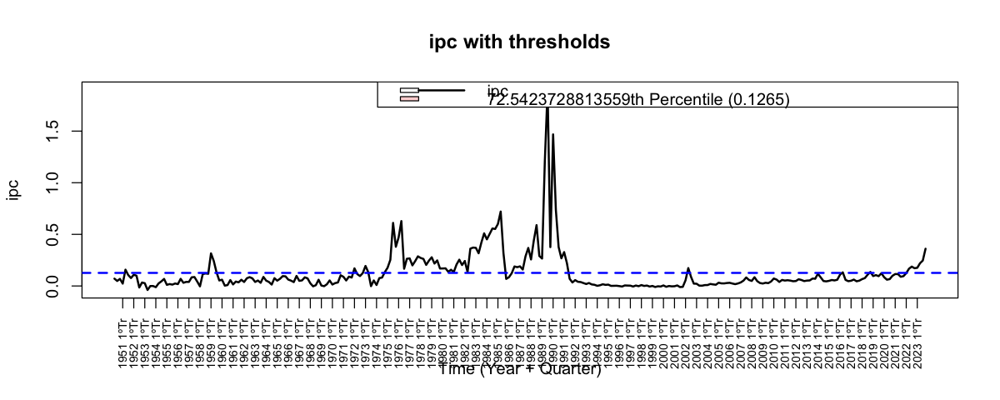

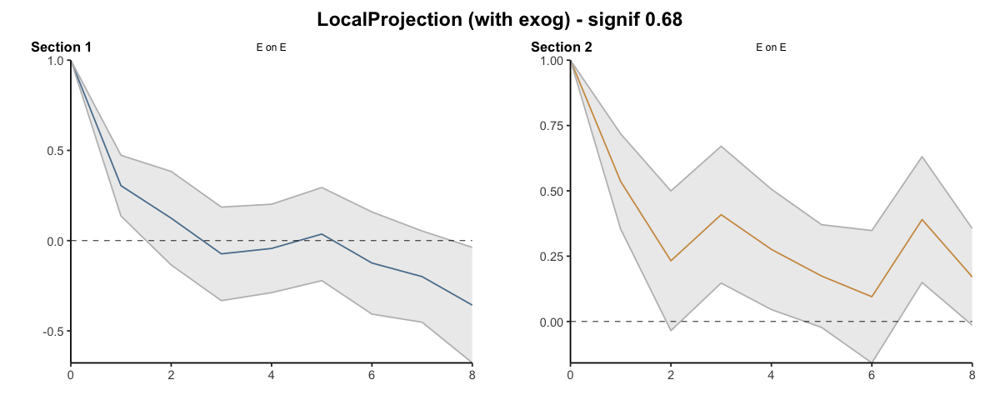

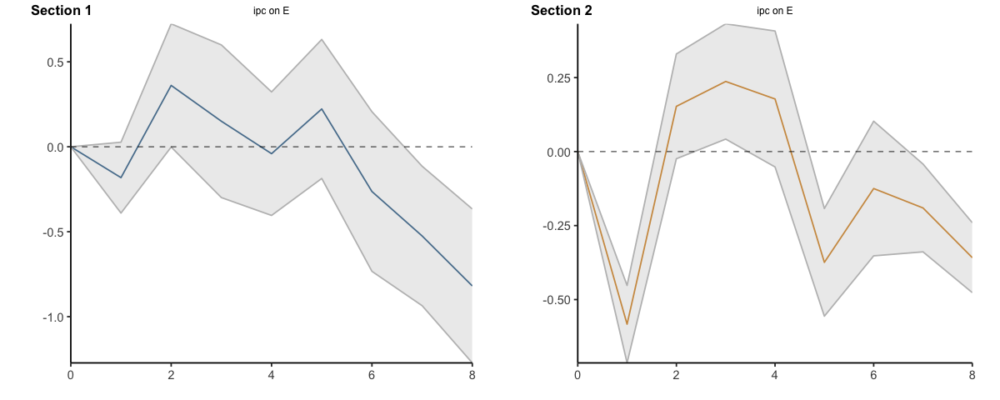

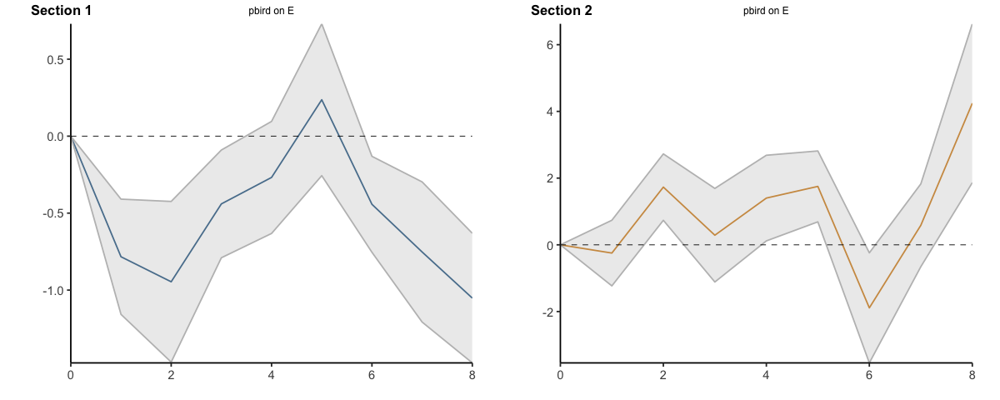

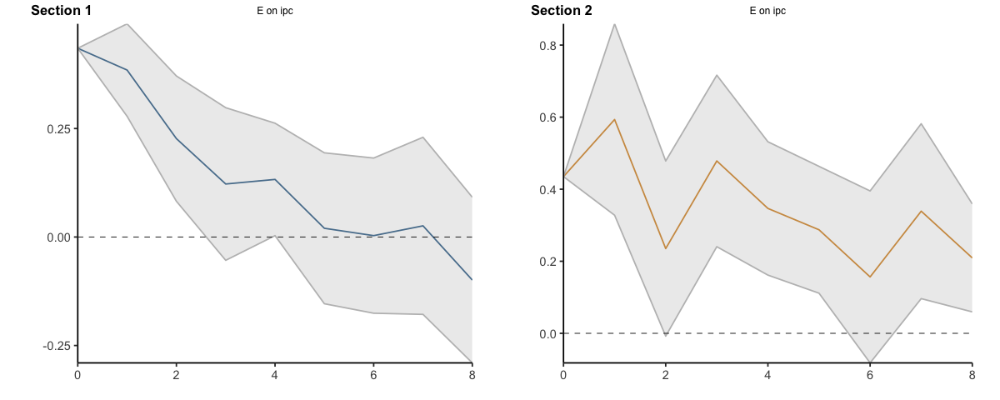

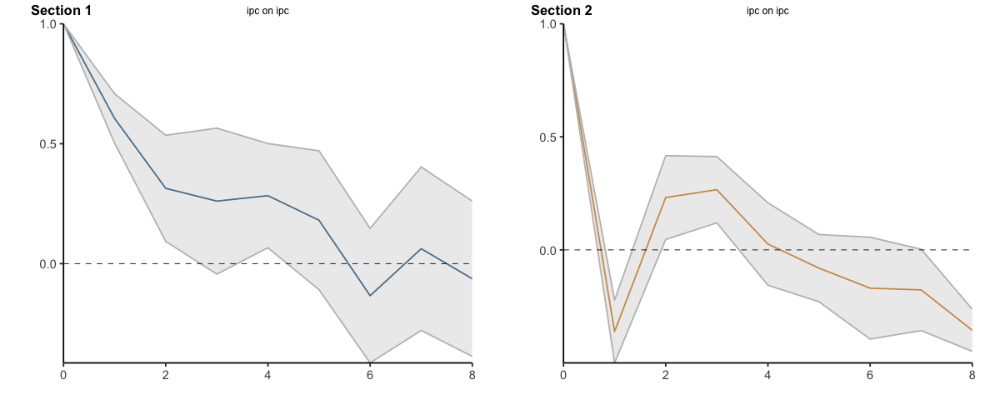

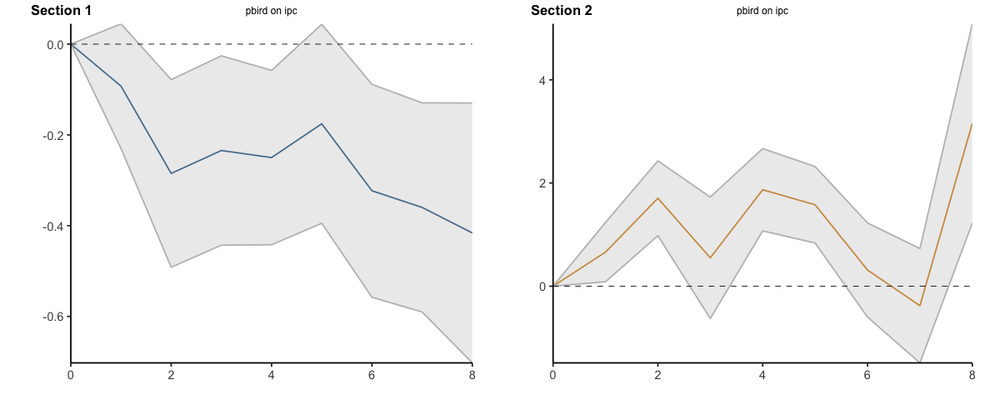

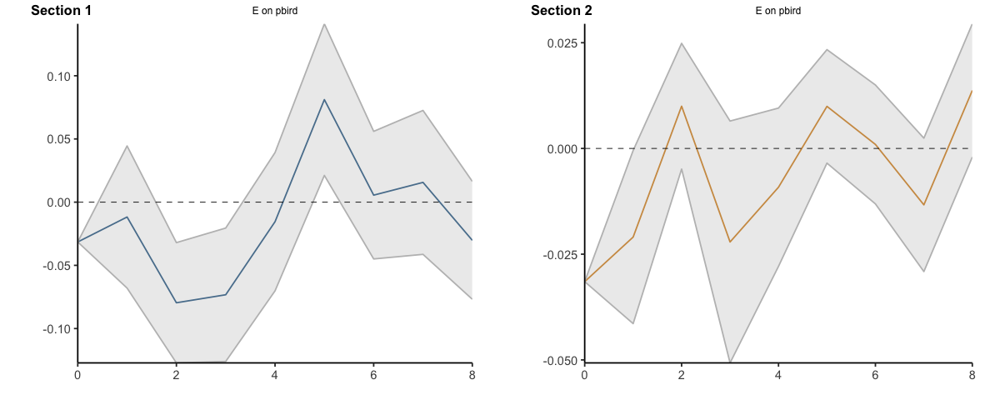

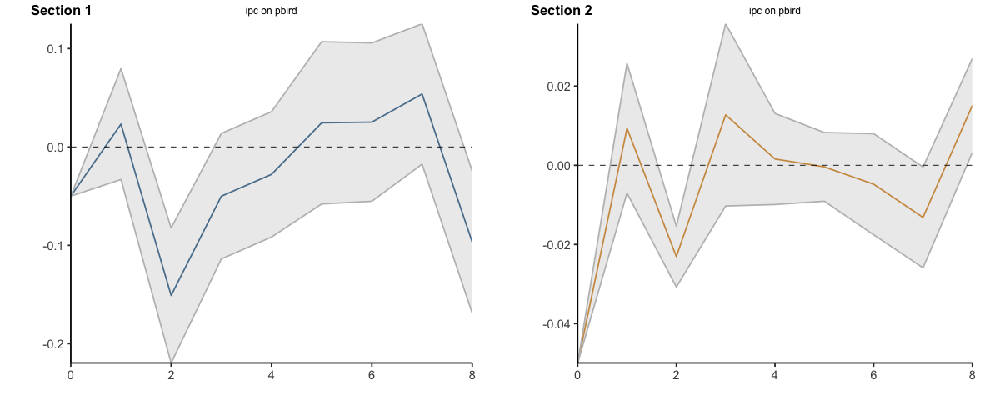

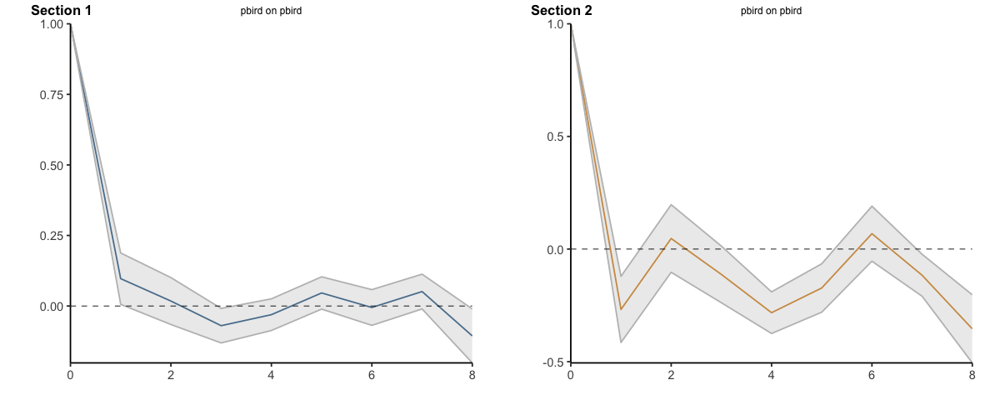

In [31]:
res <- run_lp_model(df_ERPT_Arg, endog=c("E", "ipc", "pbird"), exog=c("impp_usa"), fixed_lags = 5, horizons=8, signif = 0.68, threshold_var = 'ipc', upper_threshold=0.725423728813559)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<dbl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
5,5,NaN,NA,5,0,1,0.68,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,295,"E, ipc, pbird",3


Impulse: E -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,0,0.4349947,0.43499471,0.4349947,0.4349947,0.4349947,0.4349947
2,1,0.8197866,0.71329972,0.9262734,1.0283711,0.7627526,1.2939896
3,2,1.0465854,0.79573968,1.2974310,1.2636087,0.7549324,1.7722850
4,3,1.1687741,0.74206691,1.5954814,1.7420359,0.9953692,2.4887026
5,4,1.3014989,0.74522667,1.8577710,2.0886733,1.1569630,3.0203836
6,5,1.3216672,0.59149960,2.0518347,2.3760749,1.2683389,3.4838110
7,6,1.3248609,0.41591475,2.2338070,2.5326067,1.1862328,3.8789807
8,7,1.3506671,0.23766487,2.4636693,2.8716034,1.2825251,4.4606818
9,8,1.2514597,-0.05241419,2.5553337,3.0808216,1.3419954,4.8196478


Impulse: E -> Response: pbird

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
10,0,-0.03149282,-0.03149282,-0.0314928184,-0.03149282,-0.03149282,-0.0314928184
11,1,-0.04324824,-0.09947140,0.0129749280,-0.05244583,-0.07291740,-0.0319742592
12,2,-0.12284546,-0.22664632,-0.0190445948,-0.04245735,-0.07779600,-0.0071187032
13,3,-0.19610644,-0.35268344,-0.0395294413,-0.06457067,-0.12850524,-0.0006361055
14,4,-0.21158540,-0.42286104,-0.0003097728,-0.07373490,-0.15638502,0.0089152340
15,5,-0.13047690,-0.40172140,0.1407676121,-0.06378383,-0.15985350,0.0322858466
16,6,-0.12493885,-0.44665801,0.1967803037,-0.06283423,-0.17296369,0.0472952336
17,7,-0.10931040,-0.48796175,0.2693409625,-0.07617116,-0.20207351,0.0497311993
18,8,-0.13952729,-0.56480618,0.2857516115,-0.06245697,-0.20411493,0.0792009832


... (4 outputs left out)

Impulse: pbird -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
37,0,0.0000000,0.000000,0.00000000,0.0000000,0.0000000,0.0000000
38,1,-0.7834101,-1.157712,-0.40910834,-0.2468865,-1.2307104,0.7369373
39,2,-1.7294405,-2.625635,-0.83324585,1.4834192,-0.4956747,3.4625132
40,3,-2.1694533,-3.415623,-0.92328327,1.7716897,-1.6101664,5.1535457
41,4,-2.4375439,-4.047684,-0.82740397,3.1730384,-1.4927286,7.8388054
42,5,-2.2009714,-4.304323,-0.09761977,4.9245405,-0.8038980,10.6529789
43,6,-2.6436941,-5.058812,-0.22857592,3.0345617,-4.3437096,10.4128329
44,7,-3.3962039,-6.266667,-0.52574059,3.6202661,-4.9990812,12.2396133
45,8,-4.4482748,-7.739755,-1.15679507,7.8645427,-3.1356911,18.8647764


Impulse: pbird -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
46,0,0.00000000,0.0000000,0.00000000,0.0000000,0.00000000,0.000000
47,1,-0.09246926,-0.2296954,0.04475692,0.6599572,0.08493483,1.234980
48,2,-0.37735029,-0.7212768,-0.03342375,2.3643062,1.06335474,3.665258
49,3,-0.61169916,-1.1642227,-0.05917559,2.9140735,0.43619558,5.391951
50,4,-0.86164782,-1.6063316,-0.11696406,4.7833975,1.50739678,8.059398
51,5,-1.03714585,-2.0010006,-0.07329108,6.3614191,2.34360987,10.379228
52,6,-1.36020554,-2.5586486,-0.16176249,6.6747408,1.74433519,11.605146
53,7,-1.71996968,-3.1488411,-0.29109827,6.2958287,0.25701798,12.334639
54,8,-2.13597375,-3.8511865,-0.42076100,9.4509562,1.48158275,17.420330


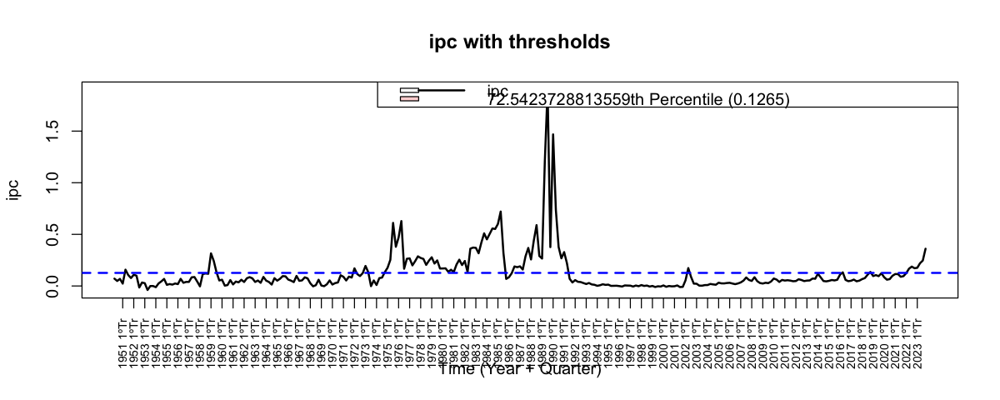

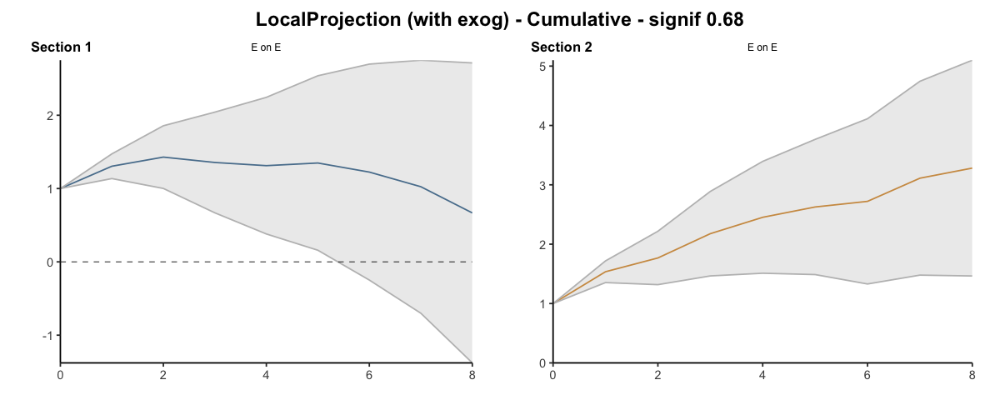

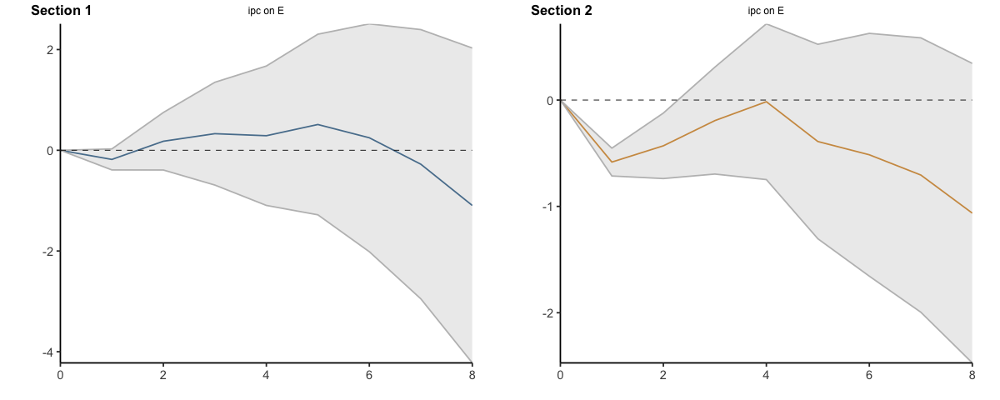

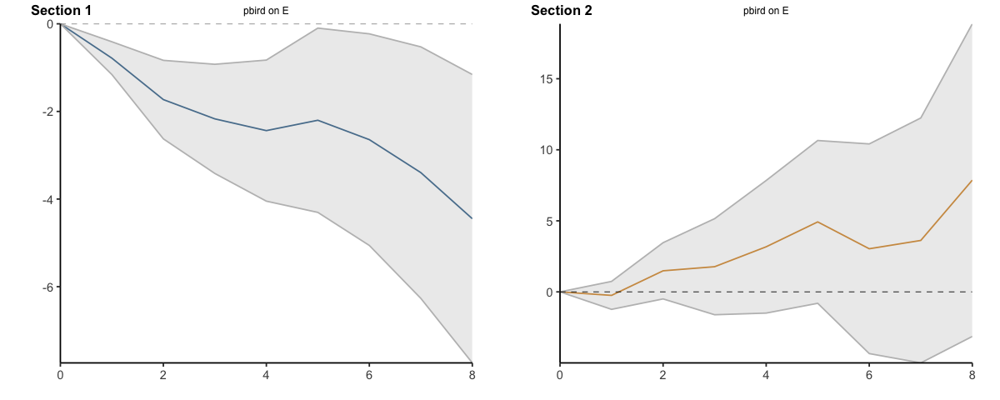

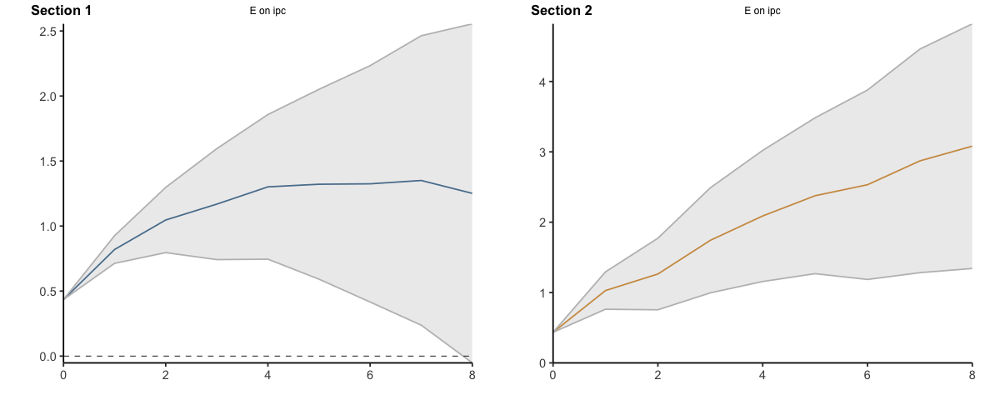

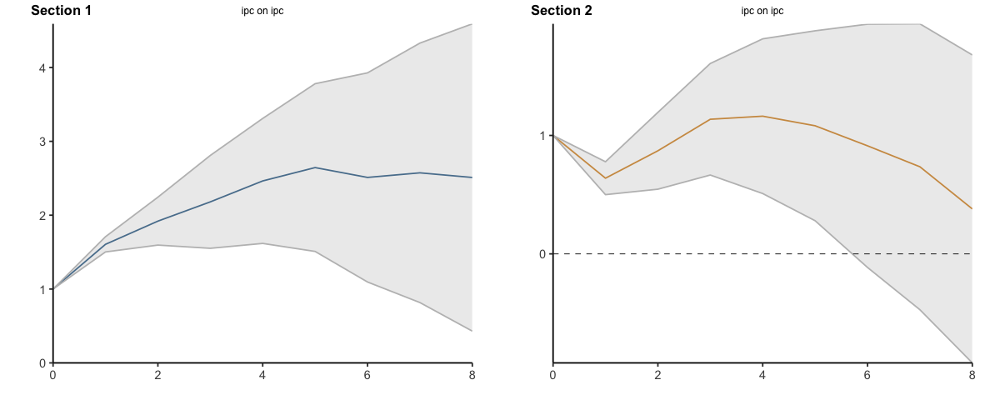

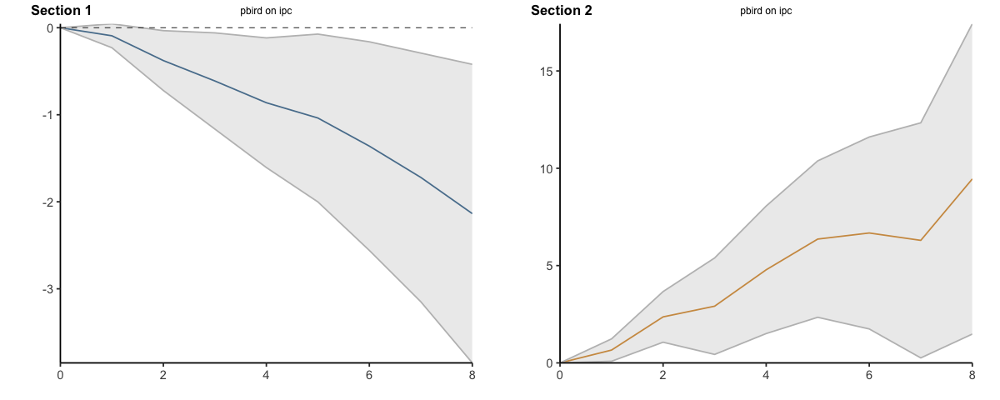

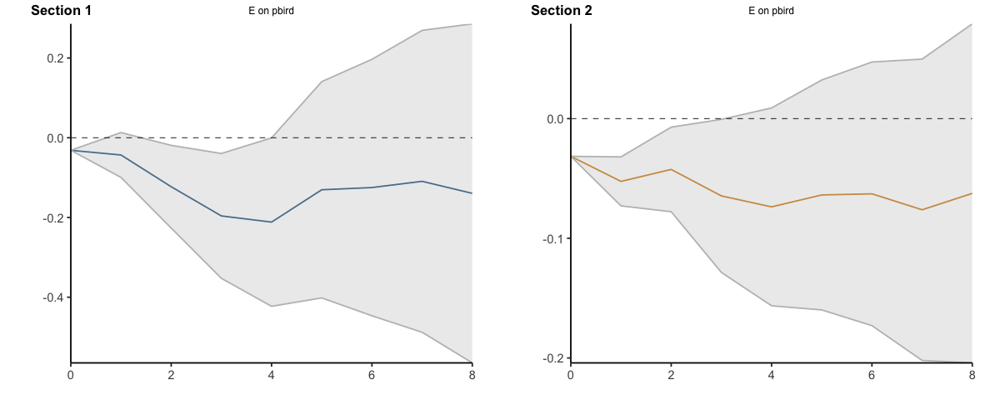

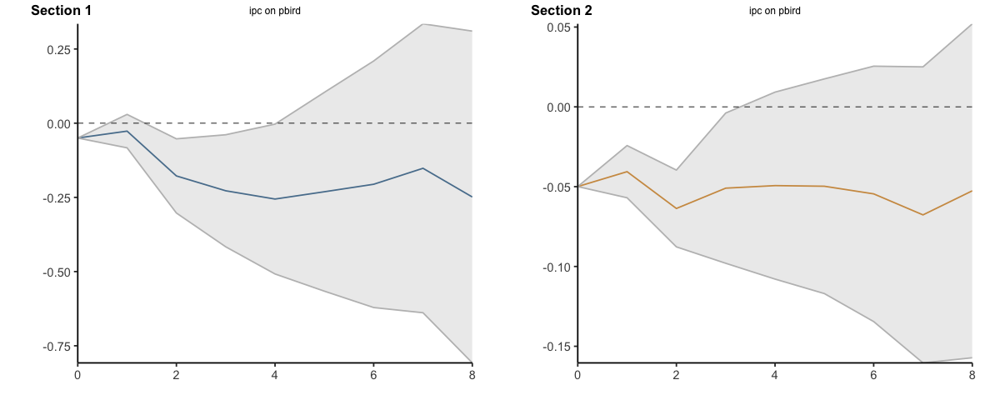

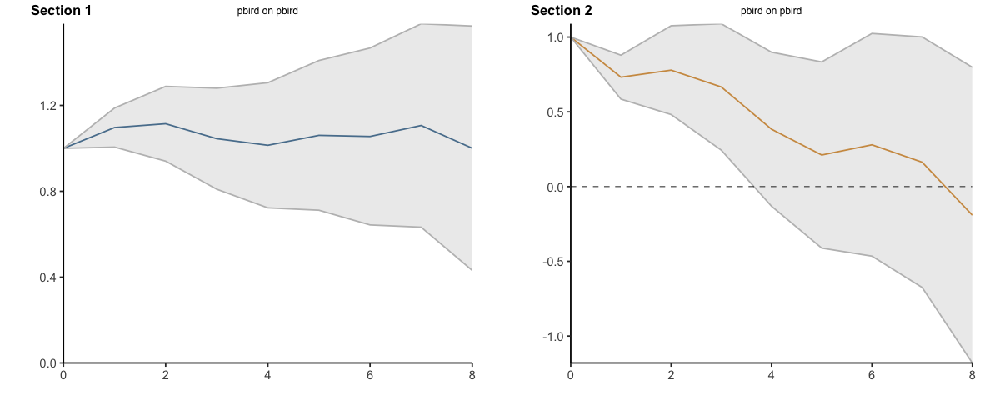

In [32]:
res <- run_lp_model(df_ERPT_Arg, endog=c("E", "ipc", "pbird"), exog=c("impp_usa"), fixed_lags = 5, horizons=8, signif = 0.68, threshold_var = 'ipc', upper_threshold=0.725423728813559, cumulative=TRUE)

#### Percentile 0.725423728813559 (12,5% inflación trimestral) - quedan 81 trimestres por encima del umbral

Umbral: ipc > 0.1265 (percentil 72.5 )
Trimestres por régimen: debajo del umbral (dummy = 0) = 214 | encima del umbral (dummy = 1) = 81 


Bootstrap por bloques circular: 500 réplicas, bloques de 26 trimestres...



  |======================================================================| 100%
ERPT de un shock unitario en E sobre ipc ( LP, 5 rezagos, exógenas: impp_usa, umbral: ipc > 0,127, 81 trimestres encima )

Régimen 1 (debajo del umbral)
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.4350         0.4350       1.0000
         1              0.8198         0.6284       1.3046
         2              1.0466         0.7324       1.4289
         3              1.1688         0.8621       1.3557
         4              1.3015         0.9917       1.3123
         5              1.3217         0.9800       1.3487
         6              1.3249         1.0819       1.2246
         7              1.3507         1.3176       1.0251
         8              1.2515         1.8745       0.6676
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.4350             0.4350
                  0.3848             0.1934
                  0.2268             0.1040
 

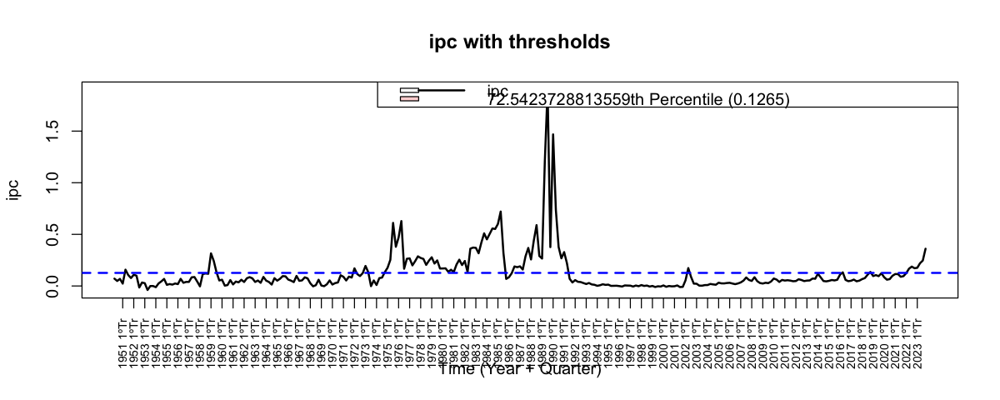

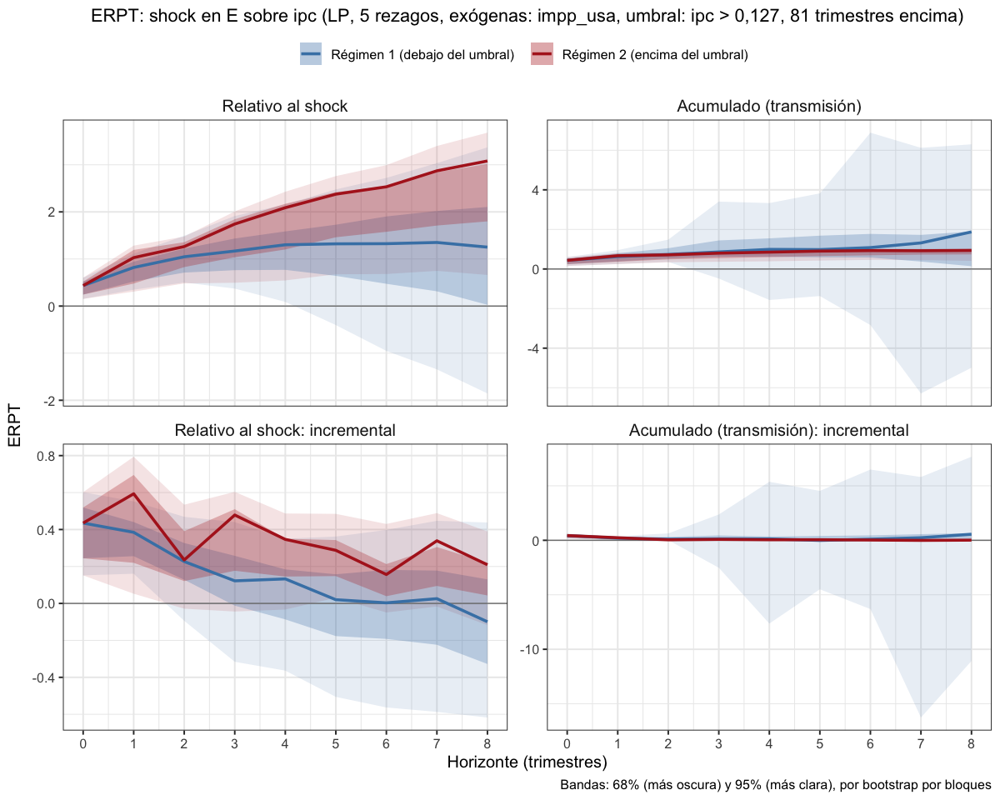

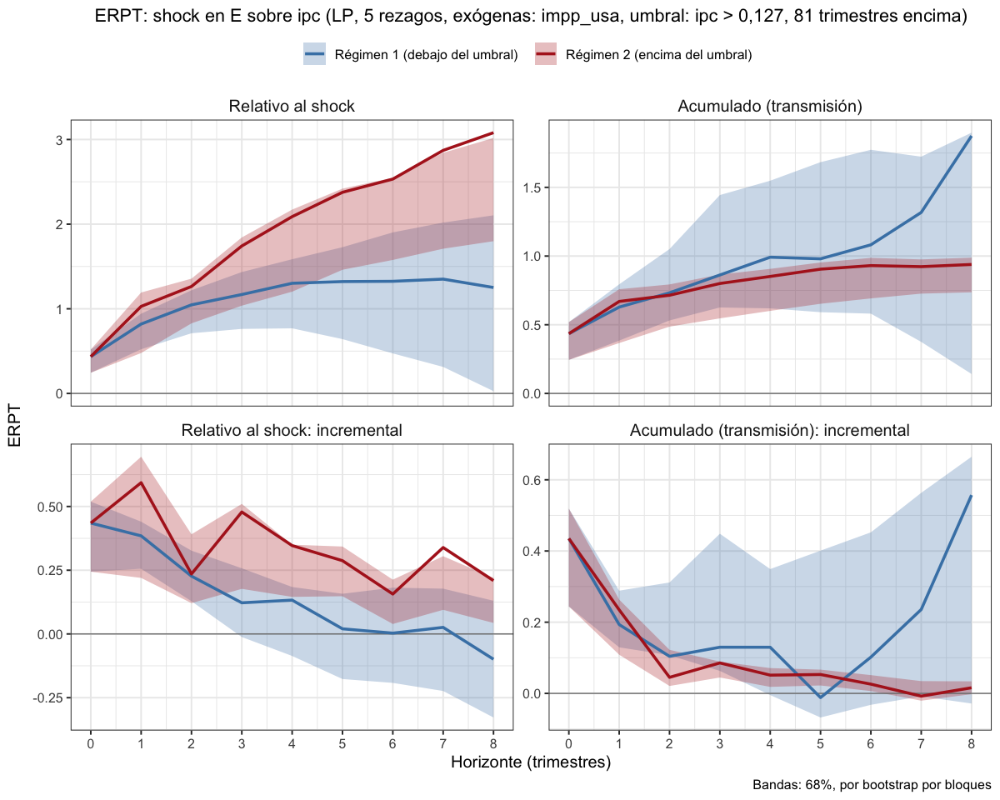

In [33]:
# 1 exógena y el resto endógenas con umbral en en 12,5% de inflación trimestral (umbral del TVAR), 5 rezagos
lp_erpt_exog_p5_tvar12.5 <- erpt_lp(df_ERPT_Arg, endog = c("E", "ipc", "pbird"), exog = c("impp_usa"), 
                                     fixed_lags = 5, horizons = 8, reps = 500,
                                     threshold_var = "ipc", upper_threshold = 0.725423728813559)
saveRDS(lp_erpt_exog_p5_tvar12.5, "lp_erpt_exog_p5_tvar12.5.rds")
graficar_erpt_lp(lp_erpt_exog_p5_tvar12.5, archivo = "lp_erpt_exog_p5_tvar12.5")
graficar_erpt_lp(lp_erpt_exog_p5_tvar12.5, niveles = 0.68, archivo = "lp_erpt_exog_p5_tvar12.5_68")

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<dbl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
5,5,NaN,NA,5,0,1,0.68,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,295,"E, ipc, pbird",3


Impulse: E -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,0,0.4349947,0.4349947,0.4349947,0.43499471,0.43499471,0.4349947
2,1,0.4603178,0.3503748,0.5702607,0.89836358,0.85858302,0.9381441
3,2,0.4184920,0.2307908,0.6061932,0.20522073,0.14418933,0.2662521
4,3,0.3057328,0.1268882,0.4845773,0.44885981,-0.08738177,0.9851014
5,4,0.4302560,0.2685582,0.5919538,0.04280174,-1.08793562,1.1735391
6,5,0.2974897,0.1037781,0.4912012,0.13029377,-0.38885393,0.6494415
7,6,0.3874490,0.1919596,0.5829384,0.08688669,-0.92595329,1.0997267
8,7,0.6307150,0.2950711,0.9663590,0.12820378,-0.36383119,0.6202387
9,8,0.4967193,0.2281364,0.7653022,0.12315309,-0.08520636,0.3315125


Impulse: E -> Response: pbird

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
10,0,-0.031492818,-0.031492818,-0.0314928184,-0.031492818,-0.031492818,-0.031492818
11,1,-0.030891548,-0.063210286,0.0014271890,-0.044119683,-0.061137277,-0.027102089
12,2,-0.031183842,-0.063282458,0.0009147738,0.013056862,-0.036292405,0.062406128
13,3,-0.025533843,-0.068118007,0.0170503216,-0.010292907,-0.068021342,0.047435528
14,4,-0.018407432,-0.043930734,0.0071158703,0.030413165,0.002919779,0.057906551
15,5,0.025871350,-0.005591697,0.0573343965,0.012458309,-0.019291357,0.044207974
16,6,-0.002762349,-0.025888571,0.0203638730,-0.001462956,-0.060888200,0.057962289
17,7,-0.019518638,-0.049325126,0.0102878514,-0.017885429,-0.032622898,-0.003147960
18,8,-0.017863782,-0.041443379,0.0057158146,-0.016929121,-0.035395776,0.001537534


... (4 outputs left out)

Impulse: pbird -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
37,0,0.00000000,0.000000000,0.0000000,0.000000,0.0000000,0.0000000
38,1,-0.62413974,-1.111138145,-0.1371413,-1.908276,-3.6613819,-0.1551693
39,2,-0.20765095,-0.683224825,0.2679229,4.614401,3.6554802,5.5733216
40,3,-0.06452548,-0.411363480,0.2823125,1.197012,-9.7811235,12.1751477
41,4,-0.02460865,-0.364649803,0.3154325,2.076162,-6.6679367,10.8202615
42,5,0.91687571,0.403750855,1.4300006,4.300244,0.5881121,8.0123768
43,6,-0.23879076,-0.598885362,0.1213038,-5.334582,-8.2450810,-2.4240821
44,7,-0.15009255,-0.527741492,0.2275564,-5.110235,-7.5382604,-2.6822100
45,8,0.48189662,-0.006539101,0.9703323,-3.281541,-4.0499257,-2.5131565


Impulse: pbird -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
46,0,0.000000000,0.000000000,0.0000000,0.0000000,0.000000,0.000000
47,1,0.185197522,0.032726451,0.3376686,-0.9163444,-3.096450,1.263761
48,2,0.148192295,-0.008488476,0.3048731,4.8304599,4.148202,5.512718
49,3,0.247331790,0.052135737,0.4425278,6.2813010,3.466624,9.095978
50,4,0.285424320,0.087416300,0.4834323,1.9327842,-5.611400,9.476968
51,5,0.524194504,0.288983986,0.7594050,1.0751779,-4.129522,6.279878
52,6,0.304090803,0.029299289,0.5788823,-6.8059281,-10.163240,-3.448616
53,7,0.007658596,-0.246170331,0.2614875,-6.2954198,-9.014551,-3.576288
54,8,0.785786281,0.335338745,1.2362338,-3.8725194,-5.152740,-2.592298


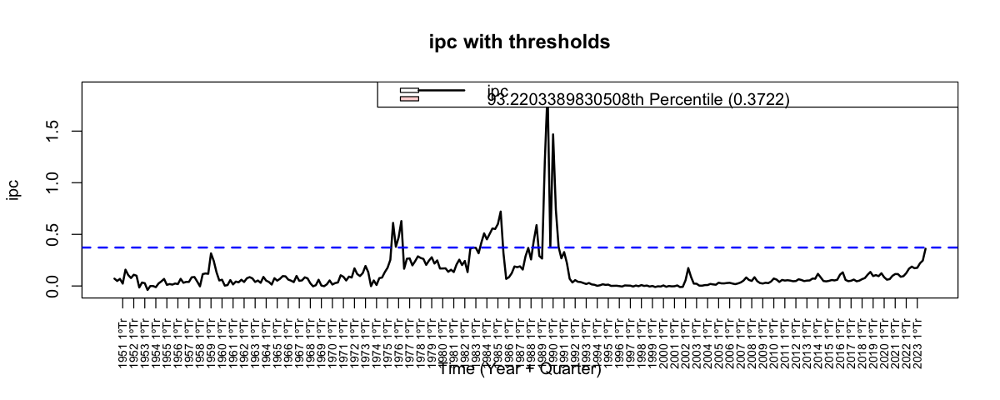

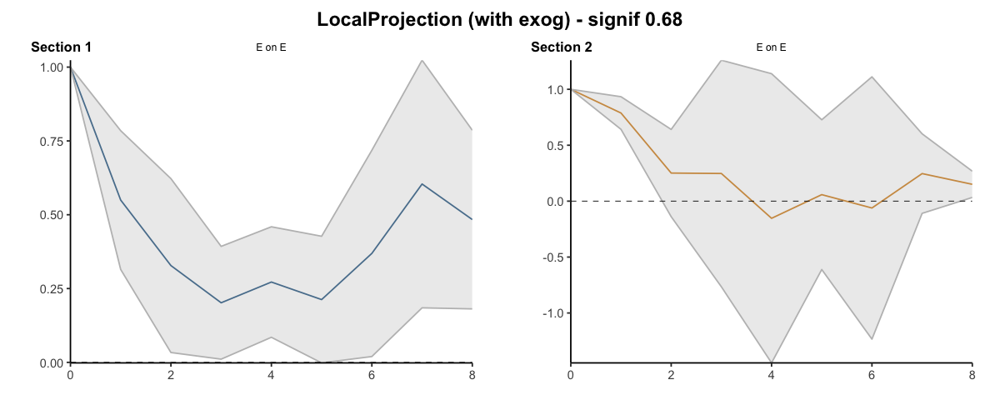

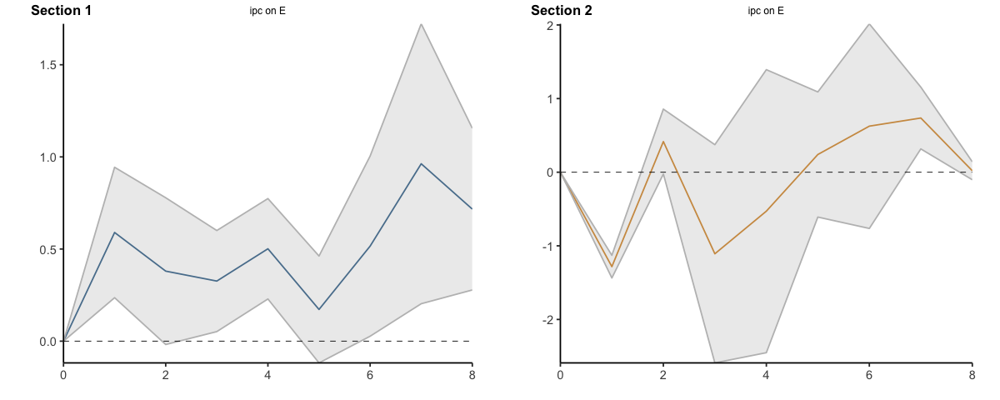

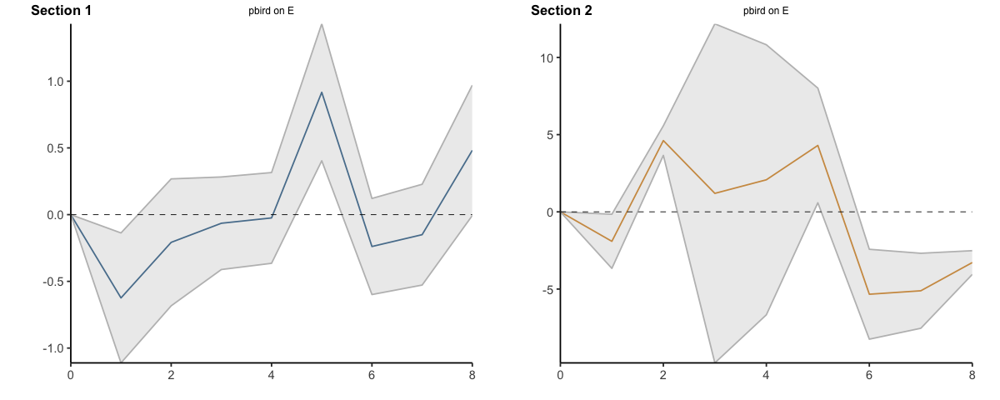

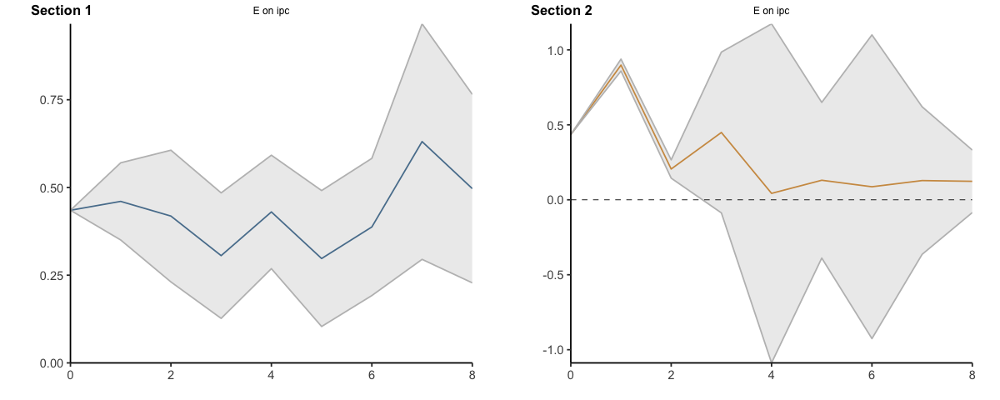

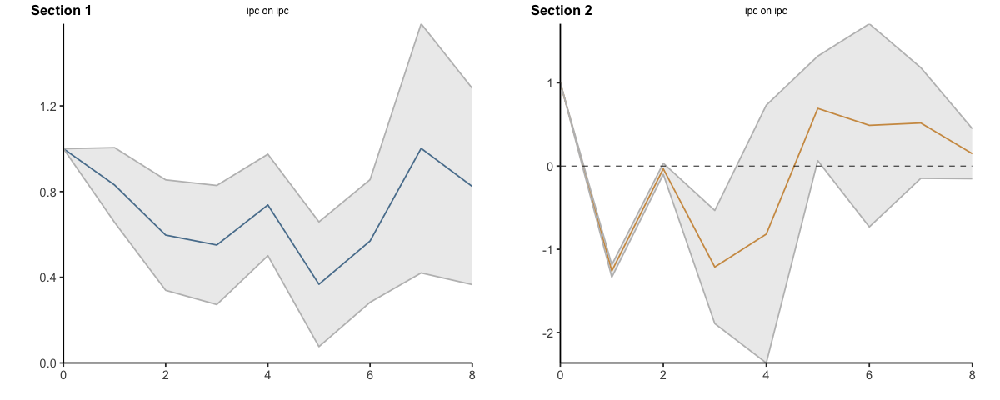

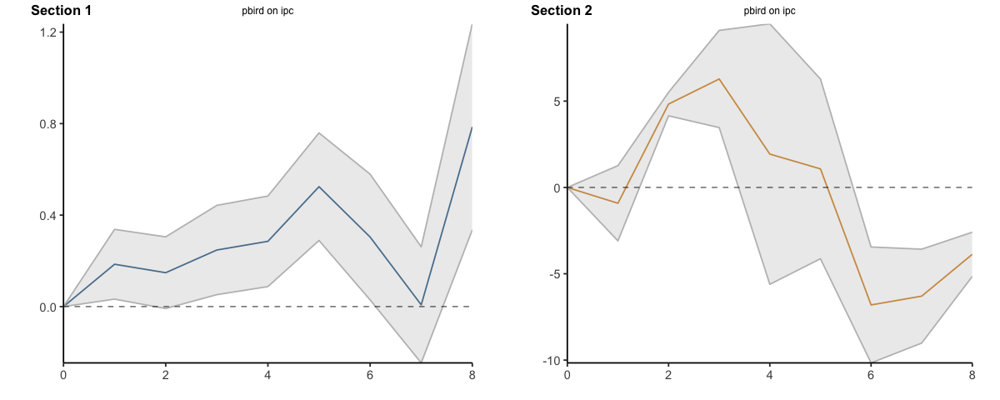

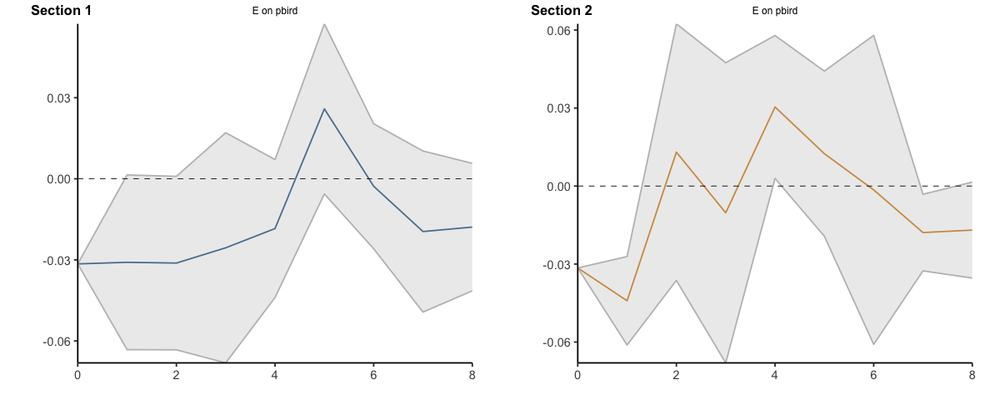

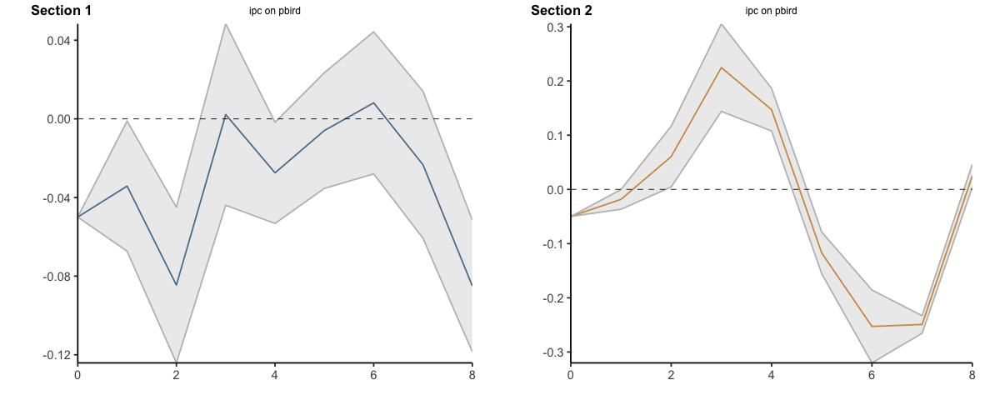

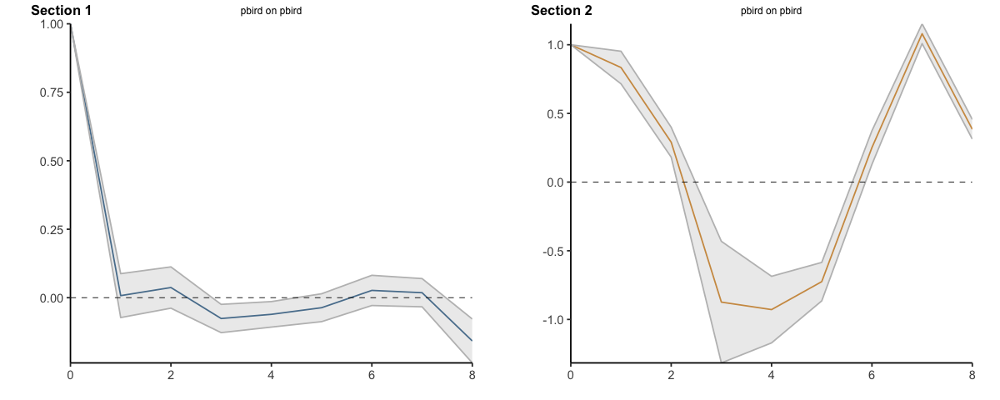

In [34]:
res <- run_lp_model(df_ERPT_Arg, endog=c("E", "ipc", "pbird"), exog=c("impp_usa"), fixed_lags = 5, horizons=8, signif = 0.68, threshold_var = 'ipc', upper_threshold=0.932203389830508)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<dbl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
5,5,NaN,NA,5,0,1,0.68,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,295,"E, ipc, pbird",3


Impulse: E -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,0,0.4349947,0.4349947,0.4349947,0.4349947,0.4349947,0.4349947
2,1,0.8953125,0.7853695,1.0052554,1.3333583,1.2935777,1.3731389
3,2,1.3138045,1.0161603,1.6114486,1.5385790,1.4377671,1.6393910
4,3,1.6195373,1.1430486,2.0960260,1.9874388,1.3503853,2.6244924
5,4,2.0497933,1.4116067,2.6879798,2.0302406,0.2624497,3.7980315
6,5,2.3472829,1.5153848,3.1791810,2.1605343,-0.1264043,4.4474729
7,6,2.7347320,1.7073445,3.7621194,2.2474210,-1.0523575,5.5471996
8,7,3.3654470,2.0024156,4.7284784,2.3756248,-1.4161887,6.1674384
9,8,3.8621663,2.2305520,5.4937806,2.4987779,-1.5013951,6.4989509


Impulse: E -> Response: pbird

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
10,0,-0.03149282,-0.03149282,-0.031492818,-0.03149282,-0.03149282,-0.031492818
11,1,-0.06238437,-0.09470310,-0.030065629,-0.07561250,-0.09263010,-0.058594908
12,2,-0.09356821,-0.15798556,-0.029150856,-0.06255564,-0.12892250,0.003811221
13,3,-0.11910205,-0.22610357,-0.012100534,-0.07284855,-0.19694384,0.051246749
14,4,-0.13750948,-0.27003430,-0.004984664,-0.04243538,-0.19402406,0.109153300
15,5,-0.11163813,-0.27562600,0.052349733,-0.02997707,-0.21331542,0.153361274
16,6,-0.11440048,-0.30151457,0.072713606,-0.03144003,-0.27420362,0.211323563
17,7,-0.13391912,-0.35083970,0.083001457,-0.04932546,-0.30682652,0.208175603
18,8,-0.15178290,-0.39228308,0.088717272,-0.06625458,-0.34222229,0.209713137


... (4 outputs left out)

Impulse: pbird -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
37,0,0.000000000,0.000000,0.0000000,0.0000000,0.000000000,0.0000000
38,1,-0.624139736,-1.111138,-0.1371413,-1.9082756,-3.661381905,-0.1551693
39,2,-0.831790681,-1.794363,0.1307816,2.7061253,-0.005901671,5.4181523
40,3,-0.896316161,-2.205726,0.4130941,3.9031374,-9.787025215,17.5933000
41,4,-0.920924814,-2.570376,0.7285266,5.9792998,-16.454961925,28.4135615
42,5,-0.004049106,-2.166625,2.1585272,10.2795442,-15.866849870,36.4259383
43,6,-0.242839870,-2.765511,2.2798310,4.9449627,-24.111930858,34.0018563
44,7,-0.392932422,-3.293252,2.5073874,-0.1652725,-31.650191284,31.3196463
45,8,0.088964198,-3.299791,3.4777198,-3.4468136,-35.700117021,28.8064898


Impulse: pbird -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
46,0,0.0000000,0.00000000,0.0000000,0.0000000,0.000000,0.000000
47,1,0.1851975,0.03272645,0.3376686,-0.9163444,-3.096450,1.263761
48,2,0.3333898,0.02423798,0.6425417,3.9141155,1.051752,6.776479
49,3,0.5807216,0.07637371,1.0850695,10.1954165,4.518375,15.872457
50,4,0.8661459,0.16379001,1.5685018,12.1282006,-1.093024,25.349426
51,5,1.3903404,0.45277400,2.3279069,13.2033785,-5.222547,31.629304
52,6,1.6944312,0.48207329,2.9067892,6.3974504,-15.385787,28.180687
53,7,1.7020898,0.23590295,3.1682767,0.1020306,-24.400338,24.604399
54,8,2.4878761,0.57124170,4.4045105,-3.7704888,-29.553078,22.012101


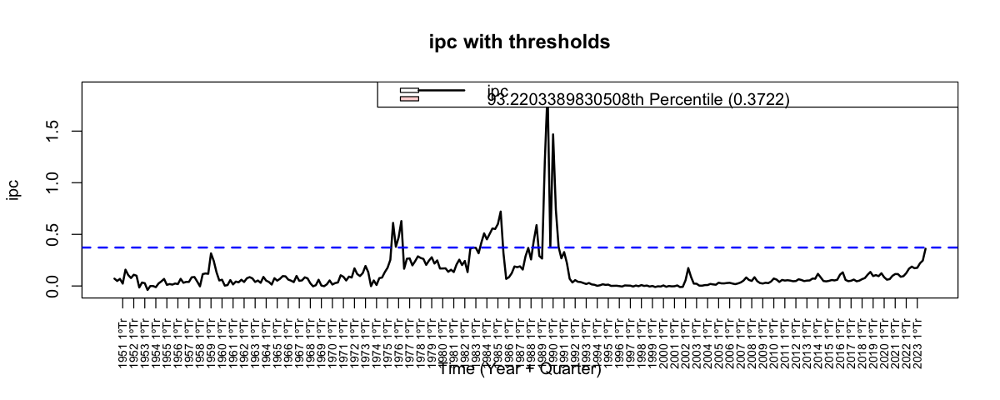

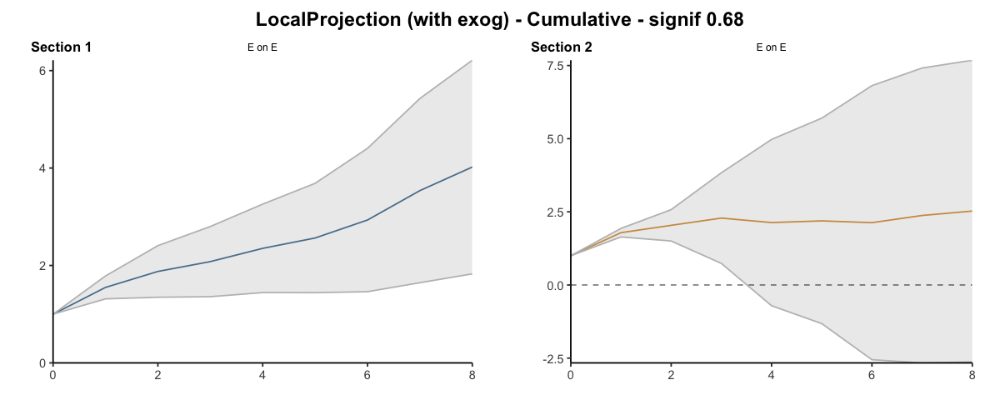

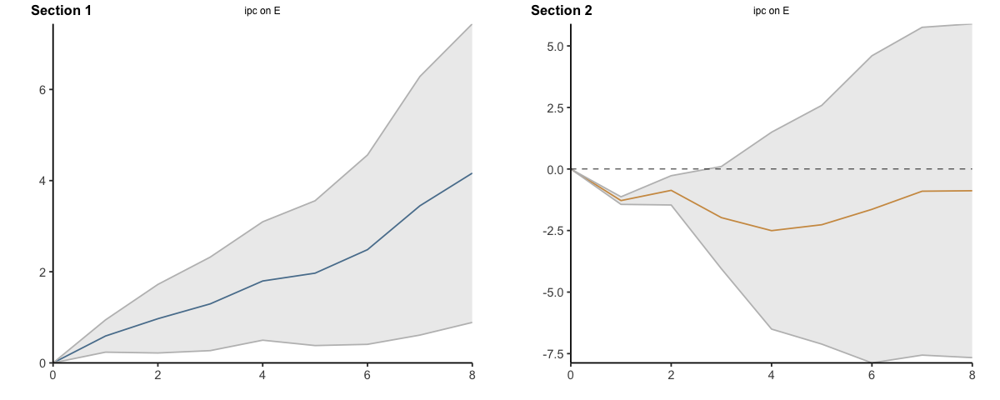

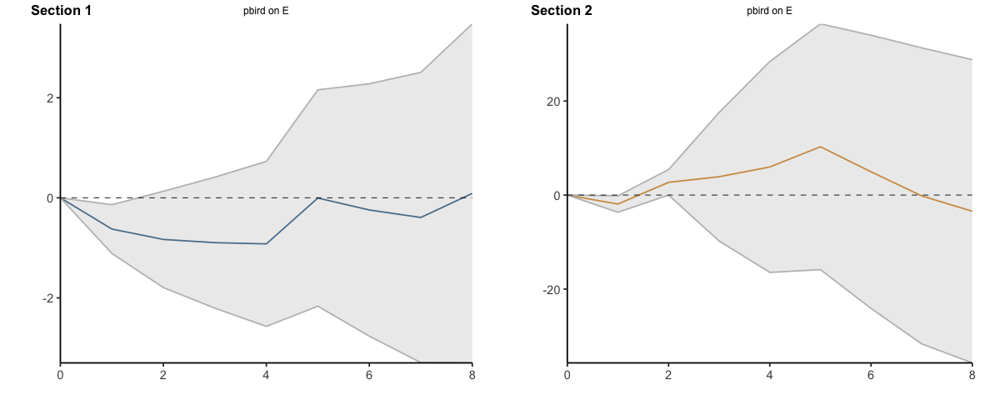

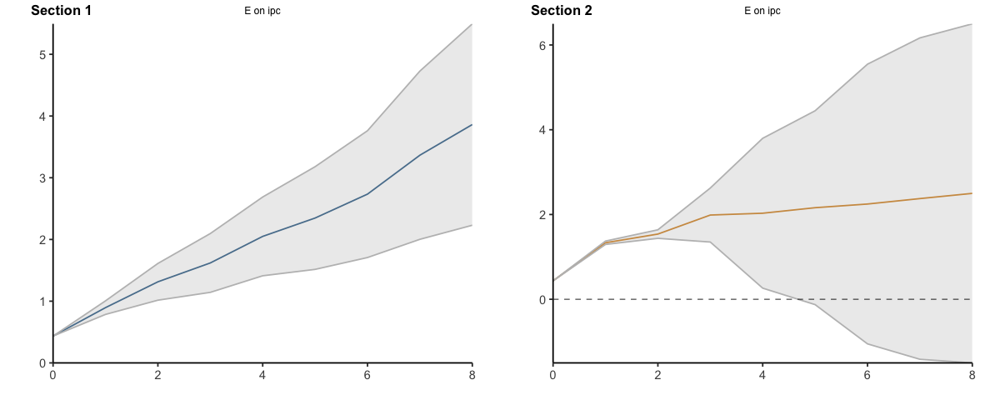

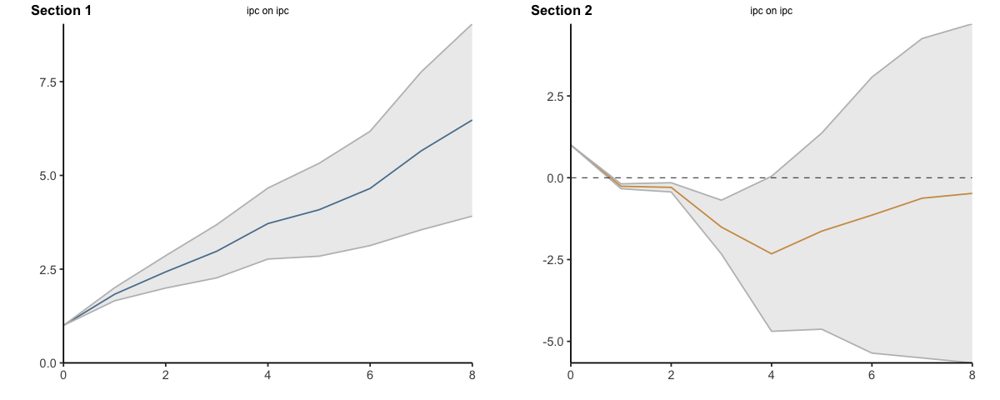

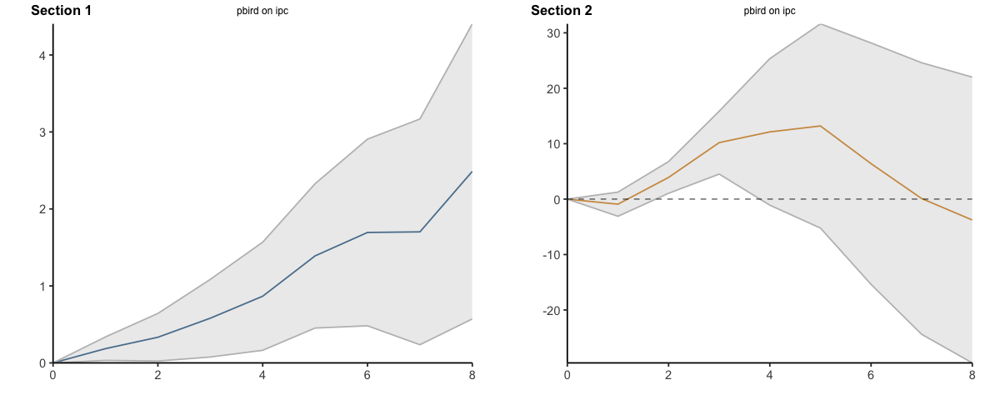

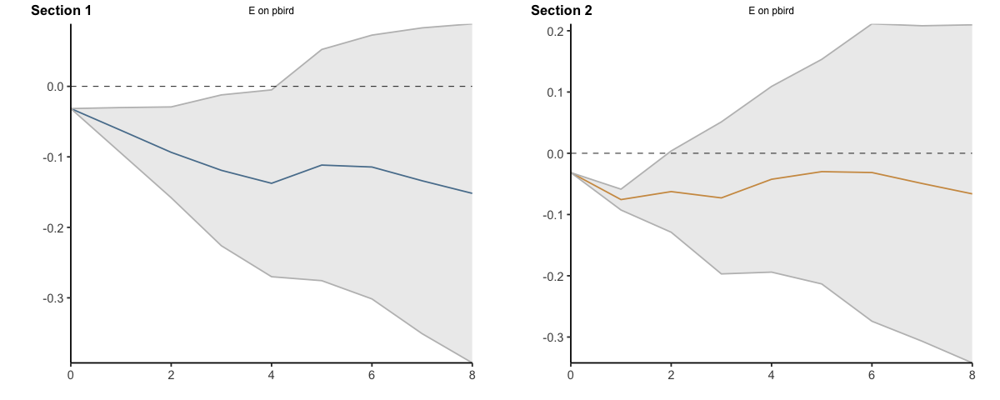

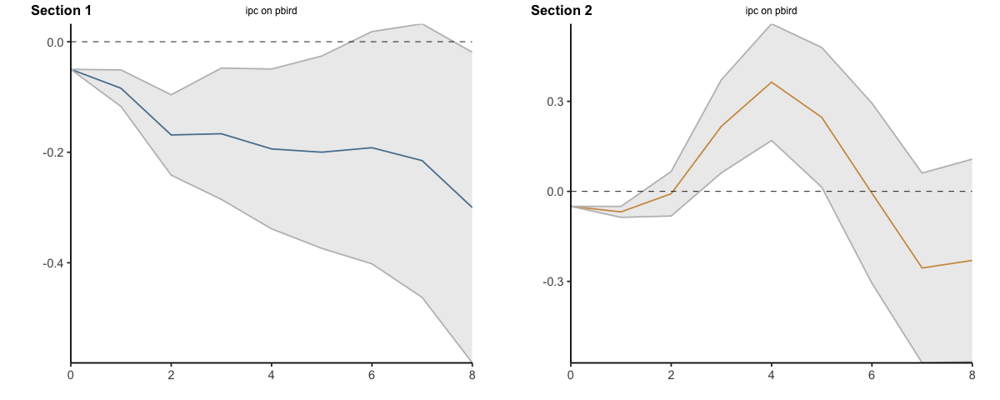

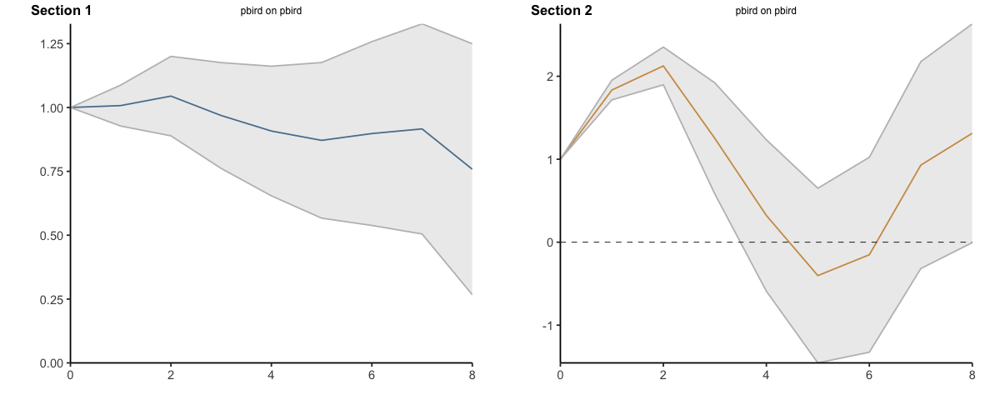

In [35]:
res <- run_lp_model(df_ERPT_Arg, endog=c("E", "ipc", "pbird"), exog=c("impp_usa"), fixed_lags = 5, horizons=8, signif = 0.68, threshold_var = 'ipc', upper_threshold=0.932203389830508, cumulative=TRUE)

#### Percentile 0.932203389830508 (37,6% de inflación trimestral) - quedan 20 trimestres por encima del umbral (son pocos)

Umbral: ipc > 0.3722 (percentil 93.2 )
Trimestres por régimen: debajo del umbral (dummy = 0) = 275 | encima del umbral (dummy = 1) = 20 


Bootstrap por bloques circular: 500 réplicas, bloques de 26 trimestres...



  |======================================================================| 100%


19 réplicas fallaron y se descartaron.



ERPT de un shock unitario en E sobre ipc ( LP, 5 rezagos, exógenas: impp_usa, umbral: ipc > 0,372, 20 trimestres encima )

Régimen 1 (debajo del umbral)
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.4350         0.4350       1.0000
         1              0.8953         0.5777       1.5497
         2              1.3138         0.6998       1.8775
         3              1.6195         0.7789       2.0794
         4              2.0498         0.8717       2.3515
         5              2.3473         0.9154       2.5641
         6              2.7347         0.9323       2.9332
         7              3.3654         0.9514       3.5373
         8              3.8622         0.9605       4.0209
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.4350             0.4350
                  0.4603             0.1427
                  0.4185             0.1220
                  0.3057             0.0791
                  0.4303             

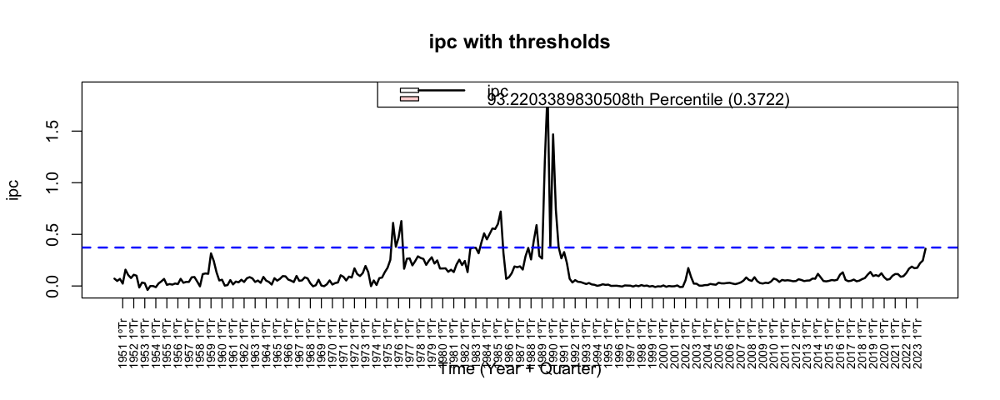

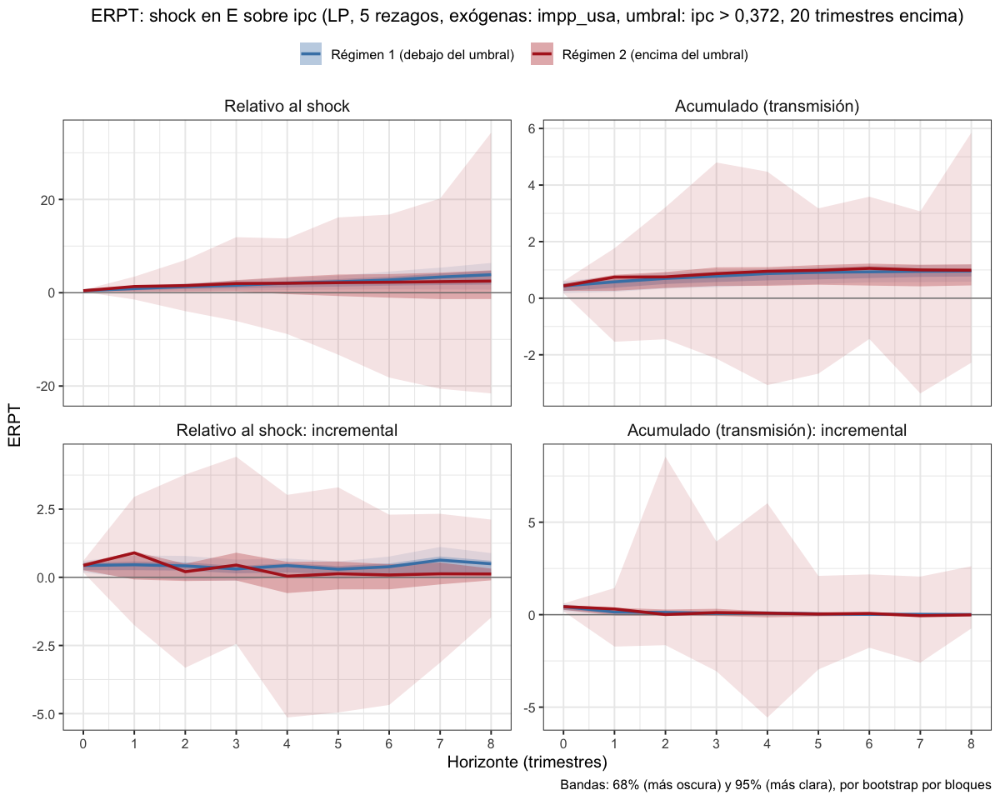

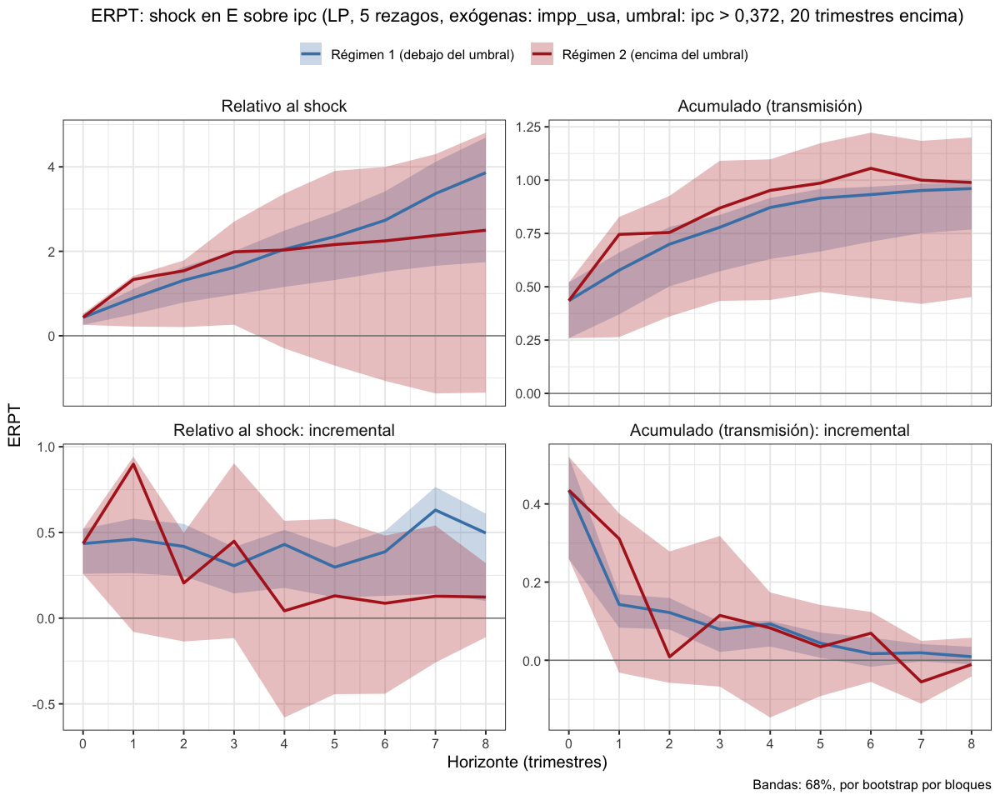

In [36]:
# 1 exógena y el resto endógenas con umbral en 37,6% de inflación trimestral (umbral del TVAR-indt), 5 rezagos
lp_erpt_exog_p5_tvar37.6 <- erpt_lp(df_ERPT_Arg, endog = c("E", "ipc", "pbird"), exog = c("impp_usa"),
                                    fixed_lags = 5, horizons = 8, reps = 500,
                                    threshold_var = "ipc", upper_threshold = 0.932203389830508)
saveRDS(lp_erpt_exog_p5_tvar37.6, "lp_erpt_exog_p5_tvar37.6.rds")
graficar_erpt_lp(lp_erpt_exog_p5_tvar37.6, archivo = "lp_erpt_exog_p5_tvar37.6")
graficar_erpt_lp(lp_erpt_exog_p5_tvar37.6, niveles = 0.68, archivo = "lp_erpt_exog_p5_tvar37.6_68")

### Celda de control

In [38]:
lp_erpt_endog_p2_u70 <- readRDS("lp_erpt_endog_p2_u70.rds")
lp_erpt_endog_p2_u80 <- readRDS("lp_erpt_endog_p2_u80.rds")

In [39]:
for (m in ls(pattern = "^lp_erpt_")) cat(m, ":", attr(get(m), "modelo"), "\n")

lp_erpt_endog_p2_tvar12.5 : LP, 2 rezagos, umbral: ipc > 0,127, 81 trimestres encima 
lp_erpt_endog_p2_tvar37.6 : LP, 2 rezagos, umbral: ipc > 0,372, 20 trimestres encima 
lp_erpt_endog_p2_u70 : LP, 2 rezagos, umbral: ipc > 0,115, 89 trimestres encima 
lp_erpt_endog_p2_u80 : LP, 2 rezagos, umbral: ipc > 0,183, 59 trimestres encima 
lp_erpt_endog_p3_tvar12.5 : LP, 3 rezagos, umbral: ipc > 0,127, 81 trimestres encima 
lp_erpt_endog_p3_tvar37.6 : LP, 3 rezagos, umbral: ipc > 0,372, 20 trimestres encima 
lp_erpt_endog_p3_u70 : LP, 3 rezagos, umbral: ipc > 0,115, 89 trimestres encima 
lp_erpt_exog_p2_tvar12.5 : LP, 2 rezagos, exógenas: impp_usa, umbral: ipc > 0,127, 81 trimestres encima 
lp_erpt_exog_p2_tvar37.6 : LP, 2 rezagos, exógenas: impp_usa, umbral: ipc > 0,372, 20 trimestres encima 
lp_erpt_exog_p2_u70 : LP, 2 rezagos, exógenas: impp_usa, umbral: ipc > 0,115, 89 trimestres encima 
lp_erpt_exog_p5_tvar12.5 : LP, 5 rezagos, exógenas: impp_usa, umbral: ipc > 0,127, 81 trimestres encima